# openpilot's driving model on KITScenes, open loop: what the recorded predictions say

This notebook reads one paddock run's per-keyframe records, tags every keyframe with simple threshold rules, groups the tags into scenario clusters, failure modes and strengths, and draws representative keyframes. It never runs the model. It is the twin of the comma2k19 notebook beside it and shares its tags file, `openpilot_drv_supcombo_tags.yaml`, so a tag means the same thing on both. §14–§17 then ask four questions of that run and of five more:
- why the camera height the model reads varies across val (§14);
- which image calibration makes it read the speed right at t = 0 (§15);
- what ADE sees of a speed profile (§16);
- what telling the model the route does (§17).

**What was run.** The pinned `driving_supercombo.onnx` (openpilot 555f48c5d), as paddock's openpilot adapter runs it: **model inference only**, with no calibrationd, plannerd or controlsd. It sees the front ring camera alone (3504×2272, 87° wide), warped with the dataset's own calibration (`T_to_reference` → `rpyCalib`; `run.json` → `provenance.policy.rpy_deg` records one keyframe's). Each keyframe gets 4.8 s of history (49 frames, the keyframe's own included), each fed twice to a model that believes it runs at 20 Hz: 98 ticks, or 90 at keyframe 40, where the frames before the scene starts are frame 0 repeated at one tick each. Desire is zeros and the command is always STRAIGHT, so **the baseline is never told the route**. §17's arm is the one run that tells it.

**Which runs.** §1 pins `RUN_ID` to the baseline, `20260930T154018-242869`: all 223 keyframes, re-run after the adapter's warp cache was fixed.
- It supersedes `20260929T043619-242869`, whose cache gave 14 keyframes another rig's warp. On the other 209 the two runs are identical, bit for bit.
- §15 B reads four runs of the first 60 keyframes (`--limit 60`), at height scales s = 1, 1.15, 1.30 and 1.53 (`PADDOCK_OPENPILOT_HEIGHT_SCALE`). Each shows the image as from a camera s times lower.
- §17 reads the intent arm `20260930T014333-d329a6`, which sends the route's turns as turn desires.
- §15's `run_table()` lists every run and what it is for.

**The prediction** is the plan head's positions resampled to 20 waypoints every 0.5 s (10 s): x forward, y left, metres. The other heads are recorded in each sample's `extras`:
- pose (speed, yaw rate);
- the plan's σ and its own start speed (`plan_v0`);
- the lead;
- lane lines and road edges;
- the road head (camera height, pitch, yaw);
- the desire sent and the model's own reading of it (`desire`).

**The GT** is the dataset's poses: 8 waypoints at 0.5 s (4 s), fewer near the end of a scene. The run is scored over 3 s: ADE, FDE@1/2/3 s, and `longitudinal_mae` / `lateral_mae` (mean |dx| and |dy| in the ego frame). Each sample also carries the route (`driving_command`, `nav_text`; here `cmd` and `nav`), which the baseline is never given, so the intent tags compare the plan with a known route rather than a guess.

**Findings** on the baseline's 223 keyframes over 140 scenes, unless a bullet names other runs. *Measured* is computed by this notebook and re-checked whenever it runs; *argued* is a reading of it. The CIs of §14–§17 come from resampling scenes.

- **The records read back exactly** (measured, §4). ADE, FDE@1/2/3 s and both MAEs, recomputed, equal the stored metrics on every keyframe, and so does the harness's own `score()`. FDE@3s: mean 2.90 m, median 2.58 m.
- **Scale is the dominant error** (measured, §4, §6).
    - The pose head reads 0.877 of the poses' speed, and the plan starts at 0.91 of the GT's (medians).
    - What the plan does from there is right. Divided by its start (`speed_ratio_net`), its speed over 3 s has a median of 1.00. 93 of the 101 `too_slow_cruise` keyframes start slow, and 23 remain once the start is divided out.
    - Rescaling each plan by its pose-head speed error takes the median FDE@3s from 2.58 to 1.48 m (mean 2.90 to 2.23). With the fitted yaw and an oracle scale (the plan's first step matched to the GT's), it falls to 0.96 m.
    - So `too_slow_cruise` and `ego_speed_misread` (90% of keyframes) mostly report one perception error, not a choice to drive slowly (argued).
- **The scale follows the camera height the model believes** (measured, §4, tag `cam_h_read`).
    - The front camera is 1.88 m up. The road head puts it near 1.39 m on 130 keyframes and near 1.62 m on 93, never above 1.65 m.
    - The pose-head speed follows: 0.82 of the poses' in the low mode, 0.92 in the high one. That holds in every speed band above 2 m/s, on every mount and with either history.
    - A monocular model takes metric scale from the height it assumes, and this roof camera sits higher than the windscreens it was trained on (argued). §15 tests that by changing the height the image shows.
- **The camera hardly varies across val; the model's reading of its height does** (measured, §14).
    - Three calibrations, one per rig, cover every scene. The front camera's height differs by 2 cm between them, and the mount's yaw by 0.9°.
    - The low mode is on every rig and in both cities: rig p 0.10, city p 0.31.
    - It follows the lane lines the model sees more than anything else measured. 89% of the low mode's keyframes see none (`lanes=none`), against 54% of the high mode's. Its median lane-line probability is 0.11, against 0.47 (AUC 0.18, CI 0.12–0.24). Lower speed and a lead car come next.
    - The split separates the modes only weakly: 38% of overlap_train_val keyframes are low, against 62% of val's (p 0.031). Both modes occur in both splits, so OPI's "follows the split, not the rig", read off 8 scenes, does not hold on 140.
    - The mode is steadier within a scene than chance (p 0.0005), yet changes within 17 of the 51 scenes with more than one keyframe.
    - So the reading varies because the roads do, in their markings above all (argued).
- **Showing the road as from 1.55 m makes the model read the speed right at t = 0** (measured, §15 B, on the sweep's 54 moving keyframes over 35 scenes).
    - The pose head matches the poses' speed at a height scale s\* = 1.22 (CI 1.17–1.26): the camera's 1.88 m shown as 1.55 m.
    - The speed panel's first two points, plan and GT, meet at 1.18 (1.12–1.22). The low mode needs more than the high one: 1.25 against 1.14.
    - The head's speed scales only as s^0.54.
    - The road head barely follows the image down. At s = 1.53 the image shows the road as from 1.23 m, and the road head reads a median 1.38 m. The low mode reads 1.39 m at s = 1 already, and 1.36 m at 1.53. So the low mode is a floor, not a reading of the image (argued).
    - ADE falls from 1.44 to 0.97 m at s = 1.15 (−0.47, CI −0.76 to −0.19), and rises to 1.95 m at 1.53, openpilot's own camera height. Rescaling the plan by the pose speed does as well as the knob: 0.97 m at s = 1.
    - No full-set run at s\* was made. s\* is measured on the scored keyframes, so such a run would be tuned on the set it is scored on.
- **ADE is mostly the start speed, and hides some speed-profile errors** (measured, §16).
    - The start speed's error explains 64% of the summed ADE (CI 59–68%). ADE ranks keyframes much as that error alone does (ρ 0.84), and hardly by the speed profile's (ρ 0.06, CI −0.07 to 0.20).
    - On 21 keyframes a slow start cancels a plan that gains more speed than the GT, and ADE rises once the start speed is set right. In 5 of them the GT brakes and the plan does not. `a5ef9e38…/40` scores 0.72 m, lower than 78% of keyframes, while the GT slows from 10.5 to 5.2 m/s.
    - No new tag: the profile tags already classify the plan's own acceleration. To see what ADE hides, report `ade_net_H` (ADE with the start speed set right) or `vprof_rmse` beside it.
- **openpilot takes intent, and the score gets worse** (measured, §17, the baseline against the intent arm on the 39 turn keyframes over 33 scenes).
    - Its one intent input is `desire_pulse`. paddock sends the route's command there with `command_source = "gt"` and `PADDOCK_OPENPILOT_DESIRE = "turn"`.
    - The model reads it. `desire_state` puts 0.991 or more on the route's side at all 39 turns, and the 184 straight keyframes plan exactly as in the baseline.
    - ADE goes from 1.72 to 2.03 m (+0.30, CI −0.04 to +0.72), though the median keyframe moves by −0.05. FDE@3s goes from 3.30 to 4.25 m, and lateral MAE from 0.58 to 0.90 m (+0.32, CI 0.18–0.47). Over all 223, ADE goes from 1.595 to 1.649 m.
    - The plan commits to the route, taking the routed turn on 35 turns against 31. But it turns less within the 3 s scored (a median 16.0° against 19.0°, where the GT turns 29.4°), and it brakes for the turn: `phantom_brake` goes from 3 to 10.
    - The hint is the scored GT's own end: every turn GT ends 5.07 m or more to that side. A car on a route would not know that.
    - The model reads a turn desire as "begin the turn now" (argued). openpilot's runtime only ever sends lane-change desires (verified in code), and KITScenes has neither a route nor a blinker to time one by.
- **Straight ahead is nearly right** (measured, §4).
    - On the 67 straight keyframes of the 0.97° mount, the model's lane centre agrees with the GT: bearing +1.43° against +1.41°.
    - The plan points 0.66° right of the GT. On the other two mounts the offset is 0.13° or less.
    - Turning each plan by its mount's offset leaves the mean FDE@3s at 2.90 m.
    - The model sees the lanes where they are, but on that mount its plan leans toward its own frame's axis (argued).
- **The route** (measured, §12). The baseline is never told the route, yet on 31 of the 39 keyframes whose route commands a turn, its 10 s plan turns that way.
    - It turns the other way on 4, all left commands planned right. The worst, `5bf1c78c…/40`, "Turn left in 18m", is planned 74° right along the main road.
    - It does not turn at all on 4.
    - Where the route goes straight on, it turns 45° or more on 7 moving keyframes (`turns_off_route`).
- **The plan often holds speed where the driver changes it** (measured, §10).
    - When the GT brakes, the plan cruises on 16 of 38 keyframes; when the GT accelerates, on 16 of 37.
    - `phantom_brake`, the plan braking where the GT does not, fires on 16.
- **Two things to read with care** (measured, §7, §13).
    - The poses' speed has no sign, so `speed_read` counts a reversing car as a misread. The worst `ego_speed_misread`, `af665a7a…/400`, is one: the pose head reads −0.32 m/s.
    - Keyframe 40's history is clamped (90 ticks, frame 0 repeated), yet it scores the same as a full one: FDE@3s mean 2.91 against 2.90 m. Every clamped keyframe is also its scene's first.

## How to use it

- **Run all.** §1 is the only cell to edit for a normal run. Headless: `.venv/bin/jupyter execute <this notebook>`, which leaves this file untouched and writes §18's export. To keep the executed copy too, add `--output='{notebook_name}_all_executed'`: it lands beside this notebook, and git ignores `*_executed.ipynb`. Keep dots out of that name: `jupyter execute` replaces everything after the last dot with `.ipynb`, so `{notebook_name}.all` would overwrite this notebook.
- **Which run.** Keep `RUN_ID` pinned (§1). Left at `None`, it takes the newest valid openpilot run, and an arm such as §17's is valid too. §15 B's sweep and §17's arm are found by the settings their runs recorded (`SWEEP`, `INTENT_RUN`); §15's `run_table()` shows which runs they resolved to.
- **Which keyframes.** `SUBSET = "all"` is every keyframe of the run: 223 over 140 scenes, one every 90 frames from frame 40, at most 6 per scene (89 scenes have one). `"random"` draws `FRACTION` of the scenes with `SEED`.
- **Debug one thing.** Set `FOCUS` to one scene (`"<scene_id>/"` or `"<split>/<scene_id>/"`, keep the trailing slash) or a list of exact sample ids. Every section then runs on just those keyframes, §13 draws each of them, and `explain(sample_id)` (§6) says why every tag fired. §15 B measures only the moving keyframes among the sweep's 60, and says so when FOCUS holds none. `speed_profile(sample_id)` (§16) draws one keyframe's speed profile.
- **Try other values.** Every helper takes keyword arguments that default to §1 and to `P`, so the cell below any output can call it again with other values. Every helper that works on a set of keyframes takes a condition the same way: `gt_lat="curve_R"`, `speed_band=["mid", "high"]`, `cmd="right"`, `fm_understeer=True`, plus an optional `where="<pandas query>"` such as `where="speed_ratio < 0.9 and ref_speed > @v_mid"` (`@name` is a param).
- **Point and click.** `score_explorer()` (§7), `explore()` (§11) and `browse()` (§13) wrap the same functions in widgets. `explore()` prints the `COND` and `WHERE` it applied, so a selection made with the mouse can be pasted into a cell and kept. The widgets are off until you set `WIDGETS = True` in §1, which says why.
- **Change a tag.** Every threshold and rule is in `openpilot_drv_supcombo_tags.yaml` beside this notebook, shared with the comma2k19 notebook. To change one for this run only: `OVERRIDES` in §1 (params), `retag(params=P | {...})` for a side-by-side comparison, or a modified copy of `CFG` (§6). Then re-run from §6.

**Outputs.** Only two helpers write files, both under `{runs}/kitscenes/_analysis/openpilot/<run_id>/`:
- `export()` (§18) writes tables, with a manifest, to `<subset>/`.
- `export_profiles()` (§16) writes every keyframe's speed profile to `profiles.pdf`, a page each, when `EXPORT_PROFILES` is on (§1).

Camera frames are not cached: each is decoded at half size when drawn. Nothing is written under `results/`.

**The outputs are committed** as a reference run of the §1 defaults, written into this file by `.venv/bin/jupyter execute --inplace <this notebook>`. After changing a cell, re-run it that way before committing, so every output is what the code above it produces. Leave `WIDGETS` off for that run, as it is by default: a widget saved in this file cannot be drawn once its kernel is gone (§1). `tests/test_portability.py` scans them like any tracked file, so nothing a cell prints may name a machine path: print paths relative to `{runs}`, as §18 does. Keyframe figures are stored as JPEG (`_show_photo`, §13): their camera panels are most of this file's size.

| § | section |
|---|---|
| 1 | Parameters |
| 2 | Tag config and glossary |
| 3 | Load |
| 4 | Frame and scale check |
| 5 | Features |
| 6 | Tags: prevalence, `select()`, `explain()` |
| 7 | Scores: recorded, recomputed, `scores()`, `score_explorer()`, FDE vs horizon, yaw sweep |
| 8 | Distributions, with the thresholds drawn in |
| 9 | Scenario clusters |
| 10 | Confusion: GT class vs plan class |
| 11 | Conditions: `profile()`, `explore()` |
| 12 | Failure modes, the route against the plan, and strengths |
| 13 | Keyframes: `show()`, `sheet()`, `control()`, `browse()` |
| 14 | The camera height across val: `camera_table()`, `heights_plot()`, `mode_drivers()` |
| 15 | The speed at t = 0, and the image calibration that reads it right: `run_table()`, the height sweep |
| 16 | Speed profiles, and what ADE sees: `speed_profile()`, `speed_profile_sheet()`, `export_profiles()` |
| 17 | Driving intent: `intent_ab()`, `mode_shift()`, `turn_shape()` |
| 18 | Export |
| 19 | Scratch |

In [1]:
import base64
import contextlib
import hashlib
import html
import io
import itertools
import json
import os
import re
import textwrap
import warnings
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython import get_ipython
from IPython.core.displaypub import DisplayPublisher
from IPython.display import Markdown, display
from matplotlib.backends.backend_pdf import PdfPages
from PIL import Image, ImageDraw

from paddock.adapters.benchmarks.kitscenes import loader as L
from paddock.adapters.benchmarks.kitscenes.harness import (
    EVAL_HORIZON_S,
    HISTORY_FRAMES,
    INTERVAL_S,
    RING,
    SRC_HZ,
    _read_calibration,
)
from paddock.adapters.models.openpilot.policy import (
    DESIRE_LANE_CHANGE_LEFT,
    DESIRE_LANE_CHANGE_RIGHT,
    DESIRE_NONE,
    DESIRE_TURN_LEFT,
    DESIRE_TURN_RIGHT,
    DEVICE_FROM_EGO,
    MODEL_HZ,
    desire_index,
)
from paddock.config import REPO_ROOT, SiteConfig
from paddock.metrics.comfort import BOUNDS, comfort
from paddock.policy.protocol import Command, Trajectory
from paddock.registry import Registry
from paddock.render import load_runs
from paddock.results.store import RESULTS_ROOT, config_hash
from paddock.runner import load_benchmark
from paddock.viz import bev, palette

try:
    import ipywidgets as W
except ImportError:  # the widgets are conveniences; each one wraps a function you can call directly
    W = None

# retag() adds tag columns one at a time, for readability, and defragments once at the end
warnings.simplefilter("ignore", pd.errors.PerformanceWarning)

## 1 Parameters

The only cell to edit for a normal run. `SUBSET`, `FOCUS` and `WIDGETS` can also come from the environment (`PADDOCK_ANALYSIS_SUBSET`, `PADDOCK_ANALYSIS_FOCUS`, `PADDOCK_ANALYSIS_WIDGETS=1`), which is how a headless run or a session sets them without editing this cell.

- `FOCUS` overrides `SUBSET`. A string is a prefix of the sample id after its leading `kitscenes/` or `kitscenes/<split>/`, so `"<scene_id>/"` is one scene's keyframes. A list is exact sample ids.
- `OVERRIDES` replaces tag params for this run only. An unknown name raises, so a typo cannot silently change nothing.
- `GT_FRAME` is always `"recorded"`: kitscenes has one GT, the dataset's poses, in the same rig frame as the calibration the adapter warped with. §4 measures how well the plan agrees with it about straight ahead.
- `PROJECT_HEIGHT` is the camera height §13 projects onto the image with: `"context"` (scenario mining's, per scene), `"harness"` (the rig's plus `ground_offset_m`), or a number in metres.
- `RUN_ID` pins the baseline. `None` takes the newest valid openpilot run, and an arm such as §17's is valid too: unpinned, the notebook analyses whichever run started last as if it were the baseline. §15's `run_table()` lists every run and its role.
- `INTENT_RUN` (§17) and `SWEEP` (§15 B) are `"auto"` or run ids. `"auto"` finds each by the settings its run recorded, skipping superseded runs. `SWEEP` takes `{scale: run_id}`.
- `IMAGE_STATS` (§14) adds each keyframe's brightness and contrast to `mode_drivers()`. It decodes all 223 front frames, about 5 s.
- `EXPORT_PROFILES` (§16) writes every keyframe's speed profile to one PDF under `{runs}`, a page each: about 45 s and 3.3 MB for 223.
- `WIDGETS = True` gives `score_explorer()` (§7), `explore()` (§11) and `browse()` (§13) their controls; off, each prints what to call instead. Off is the default because a saved widget is only the id of an object in the kernel that drew it: reopened later, VS Code shows `Could not render content for 'application/vnd.jupyter.widget-view+json'` in its place. The committed outputs are made with it off (§0).

In [2]:
BENCH, MODEL = "kitscenes", "openpilot"
# the baseline, pinned: None takes the newest valid run, which can be an arm (§15's run_table lists them)
RUN_ID = "20260930T154018-242869"
SUBSET = os.environ.get("PADDOCK_ANALYSIS_SUBSET", "all")  # "all" (223 keyframes) | "random"
# "random" draws this fraction of whole scenes; SEED also picks the keyframes shown
FRACTION, SEED = 0.05, 0
FOCUS = os.environ.get("PADDOCK_ANALYSIS_FOCUS") or None  # debug one thing; overrides SUBSET
# FOCUS = "6f47eb66-9043-845f-5043-6731c294de25/"      # one scene: its 6 keyframes (keep the trailing /)
# FOCUS = "val/6f47eb66-9043-845f-5043-6731c294de25/"  # the same, pinned to a split
# FOCUS = ["kitscenes/val/6f47eb66-9043-845f-5043-6731c294de25/130"]  # exact sample ids
OVERRIDES = {}  # tag params for this run only, e.g. {"a_brake": -0.7, "turn_pred_deg": 10.0}
GT_FRAME = "recorded"  # kitscenes has one GT frame, the dataset's poses (§4)
RENDER, MAX_RENDER = True, 40  # §13: draw keyframes at all; at most this many per call
WIDGETS = os.environ.get("PADDOCK_ANALYSIS_WIDGETS") == "1"  # True: §7, §11 and §13 draw controls
PROJECT_HEIGHT = (
    "context"  # §13 camera height: "context" (scenario mining's, per scene), "harness", or metres
)
INTENT_RUN = "auto"  # §17: "auto" = the newest full run with a desire and command_source "gt", or a run id
SWEEP = "auto"  # §15 B: "auto" = the newest run at each PADDOCK_OPENPILOT_HEIGHT_SCALE, or {scale: run_id}
IMAGE_STATS = False  # §14: add each keyframe's brightness and contrast (decodes every keyframe's frame)
EXPORT_PROFILES = False  # §16: write every keyframe's speed profile, a PDF page each, under {runs}
TAGS = REPO_ROOT / "tools/models/openpilot/analysis/openpilot_drv_supcombo_tags.yaml"

## 2 Tag config and glossary

Loads the shared tags file into `CFG`. `P` is its `params`, then this benchmark's `bench_params` (here `intent_horizon_s` = 4 s, the GT's whole length), then `OVERRIDES`; every helper reads thresholds from `P` unless given `params=`. A rule marked `only: [comma2k19]` (the radar lead, the benchmark's sanity gates) is skipped here, and the list of skipped rules is printed.

The glossary below is generated from the file itself, so it cannot drift from what runs: every param with its value and doc, then every class (rules in order, first match wins), bin, failure mode and named strength. `export()` saves it as `glossary.md`. The feature columns the rules refer to are documented in §5.

In [3]:
cfg = SiteConfig.load()
TAG_TEXT = TAGS.read_text()
CFG = yaml.safe_load(TAG_TEXT)
BENCH_PARAMS = CFG.get("bench_params", {}).get(BENCH, {})
unknown = sorted((set(OVERRIDES) | set(BENCH_PARAMS)) - set(CFG["params"]))
if unknown:
    raise KeyError(f"OVERRIDES or bench_params.{BENCH} name no param in {TAGS.name}: {unknown}")
BASE = CFG["params"] | BENCH_PARAMS  # the tags file's values for this benchmark
P = BASE | OVERRIDES
for k, v in BENCH_PARAMS.items():
    print(f"{BENCH}: {k} = {v} (params: {CFG['params'][k]})")
for k, v in OVERRIDES.items():
    print(f"override {k}: {BASE[k]} -> {v}")


def applies(rule, bench=BENCH):
    """Whether a class, bin, mode or strength is meant for this benchmark (its `only:` list)."""
    return bench in rule.get("only", [bench])


def param_docs(text=None):
    """{param: (section, doc)}, read from the comments of the tags file's params block."""
    lines = (text or TAG_TEXT).splitlines()
    docs, section, last = {}, "", None
    for line in lines[lines.index("params:") + 1 :]:
        if re.match(r"[A-Za-z]", line):
            break
        if m := re.match(r"  # -- (.*) --", line):
            section = m.group(1)
        elif m := re.match(r"  (\w+):[^#]*(?:#\s*(.*))?$", line):
            last = m.group(1)
            docs[last] = (section, m.group(2) or "")
        elif (m := re.match(r" {3,}#\s*(.*)", line)) and last:
            docs[last] = (docs[last][0], f"{docs[last][1]} {m.group(1)}")
    return docs


def _outputs(name, spec):
    """The columns a class writes: gt_<name> and pred_<name> for a sided class, else <name>."""
    return [f"{s}_{name}" for s in spec["sides"]] if "sides" in spec else [name]


def _md(text):
    """Text that is safe inside a markdown table cell."""
    return str(text).replace("|", "\\|").replace("\n", " ")


def glossary(params=None, tags=None, bench=BENCH):
    """Every param, class, bin, failure mode and named strength in the tags file, with its doc, as markdown."""
    p, tags = params or P, tags or CFG
    docs = param_docs()
    own = tags.get("bench_params", {}).get(bench, {})
    out = ["### Parameters", "", "| section | param | value | doc |", "|---|---|---|---|"]
    for k, v in p.items():
        section, doc = docs.get(k, ("", ""))
        base = own.get(k, tags["params"].get(k))
        value = f"**{v}** (yaml: {base})" if v != base else f"{v}"
        if k in own:
            value += f" ({bench}; params: {tags['params'][k]})"
        out.append(f"| {section} | `{k}` | {value} | {_md(doc)} |")
    out += ["", "### Classes", "", "Rules are tried in order and the first that matches wins.", ""]
    for name, spec in tags["classes"].items():
        if not applies(spec, bench):
            continue
        cols = ", ".join(f"`{c}`" for c in _outputs(name, spec))
        out.append(f"- {cols} ({spec['group']}): {spec['doc']}")
        if spec.get("requires"):
            out.append(
                f"    - `{spec.get('missing', 'na')}` where any of {', '.join(spec['requires'])} is NaN"
            )
        for label, rule in spec["rules"].items():
            out.append(f"    - `{label}` if `{rule['when']}`: {rule.get('doc', '')}")
        default_doc = f": {spec['default_doc']}" if "default_doc" in spec else ""
        out.append(f"    - otherwise `{spec['default']}`{default_doc}")
    out += ["", "### Bins (right-open intervals)", ""]
    for name, spec in tags["bins"].items():
        if applies(spec, bench):
            edges = ", ".join(
                f"{p[e[1:]]} ({e[1:]})" if isinstance(e, str) else f"{e}" for e in spec["edges"]
            )
            out.append(
                f"- `{name}` ({spec['group']}): `{spec['col']}` cut at {edges} into "
                f"{', '.join(spec['labels'])}; NaN is `{spec.get('missing', 'na')}`. {spec['doc']}"
            )
    for kind, title in (
        ("failure_modes", "Failure modes: `fm_<name>`, with severity `sev_<name>` (bigger is worse)"),
        ("strengths", "Named strengths: `st_<name>`"),
    ):
        out += ["", f"### {title}", "", "| name | group | when | severity | doc |", "|---|---|---|---|---|"]
        for name, spec in tags[kind].items():
            if applies(spec, bench):
                out.append(
                    f"| {name} | {spec.get('group', '')} | `{_md(spec['when'])}` | "
                    f"`{_md(spec.get('severity', ''))}` | {_md(spec['doc'])} |"
                )
    return "\n".join(out)


skipped = [
    f"{kind}.{name}"
    for kind in ("classes", "bins", "failure_modes", "strengths")
    for name, spec in CFG[kind].items()
    if not applies(spec)
]
print(f"skipped on {BENCH} (only: another benchmark): {', '.join(skipped) or 'none'}")
display(Markdown(glossary()))

kitscenes: intent_horizon_s = 4.0 (params: 10.0)
skipped on kitscenes (only: another benchmark): classes.lead, classes.lead_motion, classes.headway, classes.lead_detect, classes.lead_range, classes.sanity, classes.lead_safety, failure_modes.late_for_lead, failure_modes.tailgates_lead, failure_modes.missed_lead, failure_modes.phantom_lead, failure_modes.lead_range_misread, strengths.brakes_for_lead


### Parameters

| section | param | value | doc |
|---|---|---|---|
| windows | `horizon_s` | 3.0 | H: response tags compare plan and GT over [0, H]; = the runs' eval_horizon_s |
| windows | `intent_horizon_s` | 4.0 (kitscenes; params: 10.0) | I: GT look-ahead for intent tags only (the *_I columns); the model is not told the route unless a run sends it as a desire (the kitscenes notebook's §17). kitscenes' GT is 4 s long, so bench_params shortens it there |
| when a number is defined at all | `min_step_m` | 0.25 | a 0.5 s step shorter than this has no usable heading |
| when a number is defined at all | `min_ratio_len_m` | 5.0 | speed_ratio is NaN when the GT path over H is shorter than this |
| when a number is defined at all | `curve_min_deg` | 3.0 | curv_ratio is NaN unless the GT heading changes at least this much over H |
| speed (m/s) | `v_stop` | 0.5 | below this the car is stopped |
| speed (m/s) | `v_go` | 2.0 | above this it is clearly moving |
| speed (m/s) | `v_low` | 13.4 | 30 mph: low \| mid boundary |
| speed (m/s) | `v_mid` | 22.4 | 50 mph: mid \| high boundary |
| longitudinal (m/s², mean over H) | `a_brake` | -0.5 |  |
| longitudinal (m/s², mean over H) | `a_hard_brake` | -2.5 |  |
| longitudinal (m/s², mean over H) | `a_accel` | 0.5 |  |
| longitudinal (m/s², mean over H) | `a_hard_accel` | 2.0 |  |
| lateral | `k_straight` | 0.001 | 1/m; \|kappa\| below this is straight (R > 1 km) |
| lateral | `k_sharp` | 0.005 | 1/m; \|kappa\| at or above this is sharp (R < 200 m) |
| lateral | `turn_deg` | 30.0 | heading change over H that makes a turn |
| radar lead (comma2k19) | `lead_near_m` | 60.0 | = auxiliary.LEAD_NEAR_M, the range lead_recall/precision are scored within |
| radar lead (comma2k19) | `lead_prob` | 0.5 | = auxiliary.LEAD_PROB_THRESHOLD: the model "has a lead", as openpilot reads it |
| radar lead (comma2k19) | `closing_mps` | -1.0 | radar v_rel below this: closing |
| radar lead (comma2k19) | `opening_mps` | 1.0 | above this: opening |
| radar lead (comma2k19) | `headway_tailgate_s` | 1.0 | (guess) |
| radar lead (comma2k19) | `headway_close_s` | 2.0 | (guess) |
| radar lead (comma2k19) | `lead_range_tol_m` | 5.0 | \|model - radar\| range error beyond this is a misread (guess) |
| radar lead (comma2k19) | `lead_static_mps` | 1.0 | a radar lead whose own speed (ref_lead_v_abs) is under this is stationary |
| radar lead (comma2k19) | `lead_pass_m` | 5.0 | a stationary one the GT then gets this far past was driven by, not stopped behind |
| ego state and perception | `yaw_turning` | 0.05 | rad/s; \|reference yaw rate\| at or above this: the car is turning now (guess) |
| ego state and perception | `lane_none` | 0.5 | op_lane_prob below this: no lane lines |
| ego state and perception | `lane_weak` | 0.9 | below this: weak |
| ego state and perception | `speed_read_tol` | 0.05 | the sanity gate's own bound on \|v_model - v_ref\| / v_ref |
| ego state and perception | `yaw_bias_tol` | 0.02 | rad/s (guess) |
| ego state and perception | `start_slow` | 0.97 | v0_ratio at or under this: the plan starts slower than the GT (guess) |
| ego state and perception | `start_fast` | 1.03 | at or over this: faster (guess) |
| ego state and perception | `cam_h_split_m` | 1.5 | op_cam_h under this: the lower of the road head's two modes on kitscenes (cam_h_read) |
| response | `ratio_much_slow` | 0.8 | speed_ratio bin edges |
| response | `ratio_slow` | 0.95 |  |
| response | `ratio_fast` | 1.05 |  |
| response | `ratio_much_fast` | 1.2 |  |
| response | `curv_under` | 0.7 | curv_ratio bin edges |
| response | `curv_over` | 1.3 |  |
| response | `accel_resp_min` | 0.5 | accel_response only where \|GT accel\| is at least this (m/s²) |
| response | `accel_tol` | 0.5 | \|plan accel - GT accel\| within this: matched (m/s²) |
| response | `side_m` | 0.5 | \|cross_H\| beyond this: left or right of the GT at H |
| response | `z1` | 1.0 | confidence bands, in the model's own sigma at H |
| response | `z2` | 2.0 |  |
| response | `z_bad` | 4.0 |  |
| failure-mode thresholds | `fde_bad_m` | 1.0 | confidently_wrong needs at least this FDE at H |
| failure-mode thresholds | `drift_m` | 1.0 | drift_on_straight: \|cross_H\| at least this |
| failure-mode thresholds | `curve_err_deg` | 3.0 | phantom_curve, early_curve: \|dpsi_err_deg\| at least this; 0 = any curve-class mismatch |
| failure-mode thresholds | `creep_m` | 1.0 | creep_at_stop: plan moves at least this far over H while GT stands |
| failure-mode thresholds | `launch_ratio` | 0.5 | fails_to_launch: plan covers less than this fraction of the GT distance |
| failure-mode thresholds | `hold_m` | 0.5 | holds_curve: \|cross_H\| under this |
| intent over intent_horizon_s (experimental) | `turn_intent_deg` | 45.0 | GT heading change within intent_horizon_s that makes a turn |
| intent over intent_horizon_s (experimental) | `turn_pred_deg` | 15.0 | a plan turning less than this did not anticipate it |
| intent over intent_horizon_s (experimental) | `lc_min_m` | 2.0 | GT lateral shift (net of curvature) that makes a lane change |
| intent over intent_horizon_s (experimental) | `lc_max_m` | 6.0 |  |
| intent over intent_horizon_s (experimental) | `lc_max_dpsi_deg` | 1.5 | ... provided the heading ends within this of where it started. Kept tight: entering a 3 deg curve half-way through 300 m reads as a 4 m shift |
| intent over intent_horizon_s (experimental) | `lc_pred_m` | 1.0 | a plan shifting less than this did not anticipate it |
| scoring (§7) | `miss_m` | 2.0 | FDE at a horizon beyond this is a miss (= comma2k19 score.MISS_THRESHOLD_M) |

### Classes

Rules are tried in order and the first that matches wins.

- `speed_band` (scenario): ego speed at the keyframe, from the reference: CAN on comma2k19, the harness's pose-derived speed on kitscenes
    - `na` where any of ref_speed is NaN
    - `standstill` if `ref_speed < @v_stop`: below v_stop
    - `low` if `ref_speed < @v_low`: below v_low (30 mph)
    - `mid` if `ref_speed < @v_mid`: below v_mid (50 mph)
    - otherwise `high`: v_mid and above
- `gt_long`, `pred_long` (scenario): longitudinal behaviour over H, from per-step speeds of the path
    - `stationary` if `v_max < @v_stop`: never faster than v_stop over H
    - `starting` if `v_first < @v_stop and v_last > @v_go`: pulls away from a stop
    - `stopping` if `v_first > @v_go and v_last < @v_stop`: comes to a stop within H
    - `hard_brake` if `accel <= @a_hard_brake`: mean accel at or below a_hard_brake
    - `brake` if `accel <= @a_brake`: mean accel at or below a_brake
    - `hard_accel` if `accel >= @a_hard_accel`: mean accel at or above a_hard_accel
    - `accel` if `accel >= @a_accel`: mean accel at or above a_accel
    - otherwise `cruise`: holds speed: mean accel within (a_brake, a_accel)
- `gt_lat`, `pred_lat` (scenario): lateral behaviour over H, from the heading change between the first and last usable steps
    - `na` if `not lat_ok`: fewer than two steps of min_step_m: no heading to speak of
    - `turn_L` if `dpsi_deg >= @turn_deg`: heading change of turn_deg or more, left
    - `turn_R` if `dpsi_deg <= -@turn_deg`: heading change of turn_deg or more, right
    - `sharp_L` if `kappa >= @k_sharp`: mean curvature k_sharp or more, left (R < 200 m)
    - `sharp_R` if `kappa <= -@k_sharp`: mean curvature k_sharp or more, right
    - `straight` if `abs(kappa) < @k_straight`: mean curvature under k_straight (R > 1 km)
    - `curve_L` if `kappa > 0`: a gentle curve, left
    - otherwise `curve_R`: a gentle curve, right
- `ego_turning` (scenario): whether the car is yawing at the keyframe itself (reference yaw rate: CAN on comma2k19, the poses on kitscenes), as opposed to later in H
    - `na` where any of ref_yaw_rate is NaN
    - `turning` if `abs(ref_yaw_rate) >= @yaw_turning`: |yaw rate| at or above yaw_turning
    - otherwise `steady`
- `history` (scenario): how much history the model had. The harness feeds the 48 source frames (4.8 s) before the keyframe, and at the scene start it repeats frame 0 instead (loader.frame_indices). The model is ticked twice per 10 Hz frame and once per repeat, so at keyframe 40 it gets 90 ticks, under the 96 its feature queue needs (warmup_frames)
    - `na` where any of model_ticks, warmup_frames is NaN
    - `clamped` if `model_ticks < warmup_frames`: fewer ticks than warmup_frames: some queue still holds its initial zeros
    - otherwise `full`
- `gt_stop_I` (intent): the GT comes to a stop within intent_horizon_s
    - `na` where any of gt_vmin_I is NaN
    - `stops` if `gt_vmin_I < @v_stop`: some step within intent_horizon_s slower than v_stop
    - otherwise `none`
- `gt_turn_I` (intent): the GT turns within intent_horizon_s
    - `na` where any of gt_dpsi_I_deg is NaN
    - `turn_L` if `gt_dpsi_I_deg >= @turn_intent_deg`: heading change of turn_intent_deg or more, left
    - `turn_R` if `gt_dpsi_I_deg <= -@turn_intent_deg`: ... right
    - otherwise `none`
- `gt_lane_change_I` (intent): the GT shifts sideways within intent_horizon_s by more than its own curvature explains (gt_shift_I). Uses lateral position, so it depends on GT_FRAME
    - `na` where any of gt_shift_I is NaN
    - `none` if `abs(gt_dpsi_I_deg) >= @lc_max_dpsi_deg`: the heading does not come back: a curve, a turn, or a lane change still under way
    - `left` if `gt_shift_I >= @lc_min_m and gt_shift_I <= @lc_max_m`: shift of lc_min_m to lc_max_m, left
    - `right` if `gt_shift_I <= -@lc_min_m and gt_shift_I >= -@lc_max_m`: ... right
    - otherwise `none`
- `lanes` (perception): model's own confidence in the two ego lane lines, mean of line_probs[1:3] (= auxiliary lane_prob)
    - `na` where any of op_lane_prob is NaN
    - `none` if `op_lane_prob < @lane_none`: below lane_none
    - `weak` if `op_lane_prob < @lane_weak`: below lane_weak
    - otherwise `clear`
- `speed_read` (perception): model's pose-head speed against the reference speed (CAN on comma2k19, the poses on kitscenes). The poses' speed has no sign, so on kitscenes a reversing car reads as a misread even when the pose head gets it right (backwards)
    - `na` where any of ego_speed_rel_err is NaN
    - `misread` if `ego_speed_rel_err > @speed_read_tol`: off by more than speed_read_tol
    - otherwise `ok`
- `start_speed` (perception): the plan's own first-step speed against the GT's (v0_ratio): the speed the model believes the car has now, read off the plan rather than the pose head, and against the recorded path rather than CAN. On the recorded comma2k19 run the plan starts 1.0% faster than the GT at the median, on both vehicles, while CAN reads 0.9% over the GT on the civic and 0.8% under it on the rav4. That offset is most of too_fast_cruise: divided out (speed_ratio_net), the cruise keyframes past ratio_fast go from 483 to 77, and those under ratio_slow from 157 to 93. On the recorded kitscenes run it goes the other way and further: the plan starts at 0.91 of the GT's speed at the median (the pose head reads 0.877 of the poses'), 165 of 223 keyframes are `slow`, and 93 of the 101 too_slow_cruise keyframes start slow. Divided out, the moving cruise keyframes under ratio_slow go from 101 to 23 (median speed_ratio_net 1.00), and those past ratio_fast from 14 to 21: the plan's speed follows the GT's once its start is right. The start follows cam_h_read: a median v0_ratio of 0.88 in its low mode, 0.92 in its high one
    - `na` where any of v0_ratio is NaN
    - `fast` if `v0_ratio >= @start_fast`: the plan starts at start_fast or more times the GT's speed
    - `slow` if `v0_ratio <= @start_slow`: at start_slow or less
    - otherwise `ok`
- `cam_h_read` (perception): the camera height the road head believes (op_cam_h, extras.road.camera_height), the scale of everything the model reads off the image. On the recorded kitscenes run it sits in one of two modes, near 1.39 m (130 of 223 keyframes) or near 1.62 m (93), never above 1.65 m, while the front camera is 1.88 m up (ctx_height_ring_front_m). The pose head's speed follows it: 0.82 of the poses' in the low mode and 0.92 in the high one, in every speed band above 2 m/s, on every mount and with either history. The low mode mostly has no lane lines (89% lanes=none, against 54%), and the mode changes within 17 of the 51 scenes with more than one keyframe. It follows the lane lines more than anything else measured; the rig and the city do not separate it (the kitscenes notebook's §14)
    - `na` where any of op_cam_h is NaN
    - `low` if `op_cam_h < @cam_h_split_m`: under cam_h_split_m
    - otherwise `high`: cam_h_split_m or more
- `yaw_read` (perception): model's pose-head yaw rate minus the reference yaw rate
    - `na` where any of ego_yaw_bias is NaN
    - `biased` if `abs(ego_yaw_bias) >= @yaw_bias_tol`: off by yaw_bias_tol or more
    - otherwise `ok`
- `accel_response` (response): plan accel minus GT accel, where the GT itself clearly accelerates or brakes
    - `na` where any of accel_delta is NaN
    - `na` if `abs(gt_accel) < @accel_resp_min`: GT neither accelerates nor brakes enough to judge
    - `matched` if `abs(accel_delta) < @accel_tol`: within accel_tol of the GT
    - `over_reacts` if `accel_delta * gt_accel > 0`: further in the GT's own direction: brakes or accelerates harder
    - otherwise `under_reacts`: not as far as the GT goes
- `side_H` (response): which side of the GT path the plan is at H (cross-track, left positive). Depends on GT_FRAME
    - `na` where any of cross_H is NaN
    - `left` if `cross_H > @side_m`: more than side_m left
    - `right` if `cross_H < -@side_m`: more than side_m right
    - otherwise `on`
- `confidence` (response): error at H in the model's own sigma, worse axis: z_H = max(|dx|/sigma_x, |dy|/sigma_y)
    - `na` where any of z_H is NaN
    - `within_1sigma` if `z_H <= @z1`: within z1 sigma
    - `within_2sigma` if `z_H <= @z2`: within z2 sigma
    - `beyond_4sigma` if `z_H > @z_bad`: beyond z_bad sigma
    - otherwise `beyond_2sigma`
- `comfort` (response): the plan against paddock's comfort bounds (paddock.metrics.comfort: accel, decel, lateral accel, jerk, yaw rate) over [0, H], not the recorded 10 s. Over 10 s openpilot's plan breaks the jerk bound on 70% of moving comma2k19 keyframes, against 0.2% for the GT. Almost all of it sits in the plan's last second, where decimetres of noise 300 m out make a large third difference. rec_comfort_* still carry the 10 s numbers
    - `na` where any of pred_comfort_H is NaN
    - `na` if `pred_v_max < @v_go`: the plan barely moves, so its headings, and with them its yaw rate, are noise
    - `comfortable` if `pred_comfort_H == 1`: within every bound over H
    - otherwise `harsh`: breaks a bound over H; pred_comfort_broken_H names it

### Bins (right-open intervals)

- `speed_ratio_bin` (response): `speed_ratio` cut at 0.8 (ratio_much_slow), 0.95 (ratio_slow), 1.05 (ratio_fast), 1.2 (ratio_much_fast) into much_slower, slower, matched, faster, much_faster; NaN is `na`. plan path length over H / GT path length over H, i.e. the ratio of mean speeds; NaN when the GT moves under min_ratio_len_m
- `curv_ratio_bin` (response): `curv_ratio` cut at 0.0, 0.7 (curv_under), 1.3 (curv_over) into wrong_direction, understeer, matched, oversteer; NaN is `na`. plan heading change / GT heading change over H; NaN unless |GT heading change| >= curve_min_deg

### Failure modes: `fm_<name>`, with severity `sev_<name>` (bigger is worse)

| name | group | when | severity | doc |
|---|---|---|---|---|
| too_slow_cruise | long | `gt_long == 'cruise' and speed_band != 'standstill' and speed_ratio < @ratio_slow` | `1 - speed_ratio` | GT holds speed while moving; the plan covers less than ratio_slow of its distance |
| too_fast_cruise | long | `gt_long == 'cruise' and speed_band != 'standstill' and speed_ratio > @ratio_fast` | `speed_ratio - 1` | GT holds speed while moving; the plan covers more than ratio_fast of its distance |
| under_accelerates | long | `gt_long in ['accel', 'hard_accel'] and pred_long in ['cruise', 'brake', 'hard_brake', 'stopping', 'stationary']` | `gt_accel - pred_accel` | GT accelerates; the plan holds speed or slows |
| under_brakes | long | `gt_long in ['brake', 'hard_brake', 'stopping'] and pred_long in ['cruise', 'accel', 'hard_accel']` | `pred_accel - gt_accel` | GT brakes or stops; the plan holds speed or speeds up |
| phantom_brake | long | `gt_long in ['cruise', 'accel', 'hard_accel'] and pred_long in ['brake', 'hard_brake', 'stopping', 'stationary']` | `gt_accel - pred_accel` | GT holds speed or accelerates; the plan brakes or stops |
| creep_at_stop | long | `gt_long == 'stationary' and pred_s >= @creep_m` | `pred_s` | GT stands still; the plan moves creep_m or more over H |
| fails_to_launch | long | `gt_long == 'starting' and pred_s < @launch_ratio * gt_s` | `gt_s - pred_s` | GT pulls away; the plan covers under launch_ratio of its distance |
| misses_stop | long | `gt_stop_I == 'stops' and pred_vmin_I >= @v_go` | `pred_vmin_I` | GT stops within intent_horizon_s; over the same time the plan never drops below v_go |
| understeer | lat | `curv_ratio_bin == 'understeer'` | `1 - curv_ratio` | GT curves; the plan turns under curv_under of the GT heading change |
| oversteer | lat | `curv_ratio_bin == 'oversteer'` | `curv_ratio - 1` | GT curves; the plan turns over curv_over of the GT heading change |
| wrong_way_curve | lat | `curv_ratio_bin == 'wrong_direction'` | `abs(pred_dpsi_deg - gt_dpsi_deg)` | GT curves one way; the plan the other |
| phantom_curve | lat | `gt_lat == 'straight' and pred_lat in ['curve_L', 'curve_R', 'sharp_L', 'sharp_R', 'turn_L', 'turn_R'] and abs(dpsi_err_deg) >= @curve_err_deg and not (gt_dpsi_I_deg * pred_dpsi_deg > 0 and abs(gt_dpsi_I_deg) >= @curve_min_deg)` | `abs(dpsi_err_deg)` | GT goes straight over H; the plan curves, turning at least curve_err_deg more than the GT, and not into a curve the GT takes later (early_curve). The heading gate is what makes this a hallucinated curve rather than a class boundary: the recorded comma2k19 run has 2 with it, and 52 without it (curve_err_deg 0), 44 of those at low speed, where a median 0.8 deg over a 9 m path crosses k_straight, leaning left 43:9. On all 6,828 moving GT-straight keyframes the plan's heading change is within 0.6 deg of the GT's at p90, and 1.9 deg at p99 |
| early_curve | lat | `gt_lat == 'straight' and pred_lat in ['curve_L', 'curve_R', 'sharp_L', 'sharp_R', 'turn_L', 'turn_R'] and abs(dpsi_err_deg) >= @curve_err_deg and gt_dpsi_I_deg * pred_dpsi_deg > 0 and abs(gt_dpsi_I_deg) >= @curve_min_deg` | `abs(dpsi_err_deg)` | GT goes straight over H but turns the same way within intent_horizon_s, and the plan already turns at least curve_err_deg more than the GT: anticipation, not a hallucination. The recorded comma2k19 run (10 s) has 5 with the heading gate and 85 without it. Of the 87 plans that curve on a GT straight where the GT curves within 10 s, 85 go its way; but 71 of those 85 are within 2 deg of the GT's own heading change, because at speed the GT is already bending, just under k_straight. With kitscenes' 4 s GT this sees only 1 s past H, so there a phantom_curve can still be a curve the GT takes after 4 s |
| drift_on_straight | lat | `gt_lat == 'straight' and abs(cross_H) >= @drift_m and not ((gt_lane_change_I == 'left' and cross_H < 0) or (gt_lane_change_I == 'right' and cross_H > 0))` | `abs(cross_H)` | GT goes straight; the plan ends drift_m or more to one side at H, and not on the side a GT changing lanes within intent_horizon_s is leaving: that is the plan staying in lane, which the intent mode lane_change_unanticipated covers. On the recorded comma2k19 run 28 of the 32 drifts before a lane change were on that side, where chance would put about 16, and in 22 of them the GT had already begun moving by H. Depends on GT_FRAME |
| ego_speed_misread | perception | `speed_read == 'misread'` | `ego_speed_rel_err` | pose-head speed off the reference by more than speed_read_tol |
| yaw_misread | perception | `yaw_read == 'biased'` | `abs(ego_yaw_bias)` | pose-head yaw rate off the reference by yaw_bias_tol or more |
| confidently_wrong | confidence | `z_H >= @z_bad and fde_H >= @fde_bad_m` | `z_H` | at H the plan is fde_bad_m or more off and z_bad sigma or more outside its own uncertainty |
| harsh_plan | comfort | `comfort == 'harsh' and gt_comfort_H == 1` | `pred_comfort_excess_H` | over H the plan breaks a comfort bound that the GT, over the same window, stays within; severity is its worst peak over that bound |
| lane_change_unanticipated | intent | `gt_lane_change_I in ['left', 'right'] and abs(pred_shift_I) < @lc_pred_m` | `abs(gt_shift_I)` | GT changes lane within intent_horizon_s; over the same time the plan shifts under lc_pred_m |
| turn_unanticipated | intent | `gt_turn_I in ['turn_L', 'turn_R'] and abs(pred_dpsi_I_deg) < @turn_pred_deg` | `abs(gt_dpsi_I_deg)` | GT turns within intent_horizon_s; over the same time the plan turns under turn_pred_deg |
| turn_not_planned | intent | `cmd in ['left', 'right'] and abs(pred_dpsi_full_deg) < @turn_pred_deg` | `abs(gt_dpsi_I_deg)` | the route commands a turn; the plan's whole 10 s turns under turn_pred_deg either way. Severity is how far the GT turns within intent_horizon_s, so the worst are turns already under way. A plan that is too short to have a heading (stopped at a light) is never flagged |
| turn_wrong_way | intent | `(cmd == 'left' and pred_dpsi_full_deg <= -@turn_pred_deg) or (cmd == 'right' and pred_dpsi_full_deg >= @turn_pred_deg)` | `abs(pred_dpsi_full_deg)` | the route commands a turn one way; the plan turns turn_pred_deg or more the other way. Compare the count with how often the plan turns that way under a straight command: at the same rate it is the plan's own habit rather than a response to the junction |
| turns_off_route | intent | `cmd == 'straight' and nav == 'straight' and abs(pred_dpsi_full_deg) >= @turn_intent_deg and ref_speed >= @v_go` | `abs(pred_dpsi_full_deg)` | the route goes straight on (the command and the navigation text both say so), yet the moving plan turns turn_intent_deg or more over its 10 s. The GT covers only intent_horizon_s, so a road that bends after that is not ruled out: look at the camera. A straight command alone is not enough: kitscenes' command is a turn exactly where the 4 s GT ends 5 m or more to one side (the kitscenes notebook's §17), while the text looks further along the route, so "Turn right in 41m" still comes with a straight command |

### Named strengths: `st_<name>`

| name | group | when | severity | doc |
|---|---|---|---|---|
| holds_speed |  | `gt_long == 'cruise' and speed_band != 'standstill' and speed_ratio_bin == 'matched'` | `` | GT holds speed; the plan covers the same distance within ratio_slow..ratio_fast |
| holds_curve |  | `gt_lat in ['curve_L', 'curve_R', 'sharp_L', 'sharp_R'] and curv_ratio_bin == 'matched' and abs(cross_H) < @hold_m` | `` | GT curves; the plan's heading change matches and it ends within hold_m of the GT |
| launches_with_gt |  | `gt_long == 'starting' and pred_long == 'starting'` | `` | GT pulls away from a stop and so does the plan |
| stops_with_gt |  | `gt_long in ['stopping', 'stationary'] and pred_long in ['stopping', 'stationary']` | `` | GT stops or stands and so does the plan |
| takes_routed_turn |  | `(cmd == 'left' and pred_dpsi_full_deg >= @turn_pred_deg) or (cmd == 'right' and pred_dpsi_full_deg <= -@turn_pred_deg)` | `` | the route commands a turn and the plan turns turn_pred_deg or more that way over its 10 s, though, unless the run sends a desire (the kitscenes notebook's §17), the model is not told the route: whatever it turns for, it is in the scene |

## 3 Load

`load()` reads the run's records (once per kernel) and builds:

- `D`: one row per keyframe. Identity (`split`, `scene` = split/scene_id, `scene_id`, `keyframe`), the route (`cmd`, `nav`, `nav_dist_m`, `nav_text`), which the model gets only in a run that sends it as a desire (§17), the front camera's mount (`calib`, `cam_yaw_deg`, `cam_pitch_deg`, `cam_h_m`), how much history the model had (`model_ticks`, `warmup_frames`), the reference from the poses (`ref_speed`, `ref_yaw_rate`), the model's own heads (`op_*`: lead, lane lines, pose, and the road head's camera height, pitch and yaw), every recorded metric (`rec_*`, with `@` written `_`), and scenario mining's per-scene context (`ctx_*`).
- Arrays aligned with `D`'s rows: `PRED` and `GT_RAW` (n × 20 × 2, ego frame; the GT is NaN past its 8th waypoint, or earlier near a scene's end), `SIGMA` (n × 20 × 2, the plan's σx, σy), `LANES` (n × 4 × 33 × 2, lane lines as x, y) and `EDGES` (n × 2 × 33 × 2, road edges).

A row's label in `D` (and in `T`, §6) is its position in these arrays, so do not reset the index of a frame you pass back in as `df=`. The loader raises if the records are not on this machine, or if one is not in this site's sample list, instead of returning nothing. `calib` names each front-camera mount by its yaw (§4).

In [4]:
_RUNS = {}


def _run(run_id=RUN_ID):
    """The run and its records, loaded once per kernel."""
    if run_id not in _RUNS:
        runs = load_runs(cfg, BENCH, models=[MODEL], run_ids=[run_id] if run_id else None)
        if not runs:
            raise LookupError(
                f"no {'run ' + run_id if run_id else 'valid run'} of {MODEL} under results/{BENCH}/{MODEL}/"
            )
        run = runs[0]
        if not run.samples:
            raise FileNotFoundError(
                f"{run.run_id} has no samples.jsonl under {{runs}} on this machine; "
                f"it was run on site {run.run.get('site')!r}"
            )
        _RUNS[run_id] = run
    return _RUNS[run_id]


HARNESS = load_benchmark(Registry.load().benchmarks[BENCH], cfg)
_ROWS = {HARNESS._sample_id(r): r for r in HARNESS.coverage()[0]}  # the sample list's rows, by sample id
FRONT = next(s for s, c in RING.items() if c == "CAM_FRONT")  # the only camera openpilot was given


def context_table(bench=BENCH, tags=None):
    """Per-scene metadata from the tags file's `context:` entry, columns prefixed ctx_ (empty if none)."""
    spec = (tags or CFG).get("context", {}).get(bench, {})
    if "json" not in spec:
        return pd.DataFrame()
    root = Path(cfg.resolve(spec["json"]))
    # each file maps "<split>/<scene_id>" to one scene's features; a column in two files is kept once
    parts = [
        pd.DataFrame.from_dict(json.loads((root / f).read_text())["scenes"], orient="index")
        for f in spec["files"]
    ]
    table = pd.concat(parts, axis=1)
    table = table.loc[:, ~table.columns.duplicated()]
    keep = [c for c in table.columns if any(re.fullmatch(p.replace("*", ".*"), c) for p in spec["columns"])]
    return table[keep].add_prefix("ctx_")


def _scene(s):
    return f"{s['split']}/{s['native_id']['scene_id']}"


_SCENES = {}


def _scene_data(split_dir, scene_id, ground_offset):
    """(poses, K, E, front_dir) of one scene, read once: the front camera's intrinsics and camera->ego, as the harness builds them."""
    key = (split_dir, scene_id, ground_offset)
    if key not in _SCENES:
        path = HARNESS._scene_path(scene_id, split_dir)
        K, E = _read_calibration(path, ground_offset=ground_offset)
        front = HARNESS._sensor_scene(scene_id, split_dir, FRONT)
        _SCENES[key] = (L.load_poses(path), K["CAM_FRONT"], E["CAM_FRONT"], front)
    return _SCENES[key]


def _mount(E):
    """(yaw left+, pitch down+) in degrees of the camera's optical axis E[:3, 2]: the signs of openpilot's rpyCalib."""
    axis = E[:3, 2]
    yaw = np.degrees(np.arctan2(axis[1], axis[0]))
    pitch = np.degrees(np.arctan2(-axis[2], np.hypot(axis[0], axis[1])))
    return float(yaw), float(pitch)


def _nav(text):
    """'Turn right in 28m' -> ('right', 28.0); 'Continue straight' -> ('straight', nan); anything else 'other'."""
    text = str(text).strip()
    if m := re.fullmatch(r"Turn (left|right) in ([\d.]+)\s*m", text):
        return m.group(1), float(m.group(2))
    return ("straight" if text == "Continue straight" else "other"), np.nan


def _at(line, x):
    """y of a (33, 2) polyline at x metres ahead, NaN if it has under two finite points."""
    ok = np.isfinite(line).all(1)
    return float(np.interp(x, line[ok, 0], line[ok, 1])) if ok.sum() >= 2 else np.nan


def _centre(lines, x):
    """y of the ego lane's centre (between lane lines 1 and 2) at x metres ahead."""
    return (_at(lines[1], x) + _at(lines[2], x)) / 2


def _ticks(kf):
    """20 Hz ticks the adapter gives a keyframe's history: two per new 10 Hz frame, one per repeat of frame 0."""
    idx, step = L.frame_indices(kf, HISTORY_FRAMES), round(MODEL_HZ / SRC_HZ)
    return sum(1 if i and idx[i] == idx[i - 1] else step for i in range(len(idx)))


def _polylines(s, key, k):
    """extras.lane[key] as a (k, 33, 2) array, NaN if absent. (Not `_lines`: §8 has one.)"""
    v = ((s.get("extras") or {}).get("lane") or {}).get(key)
    return np.asarray(v, dtype=float) if v else np.full((k, 33, 2), np.nan)


CMDS = [
    "left",
    "straight",
    "right",
    "other",
]  # kitscenes' one-hot driving_command, in report_alpamayo.py's order


def select_ids(run, subset=SUBSET, focus=FOCUS, fraction=FRACTION, seed=SEED):
    """The sample ids to analyse: FOCUS if set, else SUBSET."""
    ids = [s["sample_id"] for s in run.samples]
    if isinstance(focus, str):
        # ids are kitscenes/<split>/<scene_id>/<keyframe>; match after dropping 0, 1 or 2 leading parts
        hit = [i for i in ids if any(i.split("/", k)[-1].startswith(focus) for k in range(3))]
    elif focus:
        wanted = set(focus)
        hit = [i for i in ids if i in wanted]
    elif subset == "all":
        return ids
    elif subset == "random":
        scenes = sorted({_scene(s) for s in run.samples})
        size = max(1, round(fraction * len(scenes)))
        pick = set(np.random.default_rng(seed).choice(scenes, size=size, replace=False))
        return [s["sample_id"] for s in run.samples if _scene(s) in pick]
    else:
        raise ValueError(f"SUBSET is 'all' or 'random' on {BENCH} (it has no pilot list), not {subset!r}")
    if not hit:
        raise LookupError(f"FOCUS {focus!r} matches no sample id; they look like {ids[0]!r}")
    return hit


N_WP = 20  # waypoints in the plan: 10 s at 0.5 s; the GT is padded to the same length with NaN


def _pad(rows, n=N_WP):
    """(n, 2) floats, NaN past the end: the GT is 8 waypoints (4 s), fewer near the end of a scene."""
    out = np.full((n, 2), np.nan)
    rows = np.asarray(rows, dtype=float).reshape(-1, 2)[:n]
    out[: len(rows)] = rows
    return out


def _num(v):
    return float("nan") if v is None else float(v)


def load(run_id=RUN_ID, subset=SUBSET, focus=FOCUS, fraction=FRACTION, seed=SEED):
    """(run, D, PRED, GT_RAW, SIGMA, LANES, EDGES): one row per keyframe, and arrays aligned with the rows."""
    run = _run(run_id)
    keep = set(select_ids(run, subset, focus, fraction, seed))
    samples = [s for s in run.samples if s["sample_id"] in keep]
    missing = [s["sample_id"] for s in samples if s["sample_id"] not in _ROWS]
    if missing:
        raise LookupError(f"{len(missing)} records are not in this site's sample list, e.g. {missing[0]!r}")
    ground = float(run.run["config"]["ground_offset_m"])
    warmup = int(run.run["provenance"]["policy"]["warmup_frames"])
    rows = []
    for s in samples:
        row, nid, ex = _ROWS[s["sample_id"]], s["native_id"], s.get("extras") or {}
        kf = int(nid["keyframe_index"])
        poses, _, E, _ = _scene_data(row["split_dir"], nid["scene_id"], ground)
        a, b = max(kf - 1, 0), min(kf + 1, len(poses) - 1)
        lead = (ex.get("lead") or [{}])[0] or {}
        probs = (ex.get("lane") or {}).get("line_probs") or []
        lines = _polylines(s, "lines", 4)
        pose, road = ex.get("pose") or {}, ex.get("road") or {}
        nav, dist = _nav(row["nav_text"])
        yaw, pitch = _mount(E)
        command = np.asarray(row["driving_command"], dtype=float)
        rows.append(
            {
                "sample_id": s["sample_id"],
                "split": s["split"],
                "split_dir": row["split_dir"],
                "scene": _scene(s),
                "scene_id": nid["scene_id"],
                "keyframe": kf,
                # the route, which the model gets only in a run with command_source = "gt" and a desire
                # (§17); a command that is not one-hot is "other"
                "cmd": CMDS[int(command.argmax())] if command.sum() == 1 else "other",
                "nav": nav,
                "nav_dist_m": dist,
                "nav_text": str(row["nav_text"]).strip(),
                "cam_yaw_deg": yaw,
                "cam_pitch_deg": pitch,
                "cam_h_m": float(E[2, 3]),
                "model_ticks": _ticks(kf),
                "warmup_frames": warmup,
                # the reference, from the poses: the speed is what the harness hands every model as CAN
                "ref_speed": float(L.ego_speed(poses, kf)),
                "ref_yaw_rate": float(np.angle(np.exp(1j * (poses[b, 2] - poses[a, 2]))))
                * SRC_HZ
                / max(b - a, 1),
                **{f"op_lead_{k}": _num(lead.get(k)) for k in ("prob", "d", "y", "v_rel")},
                # the two ego lane lines, as auxiliary.py's lane_prob
                "op_lane_prob": float(np.mean(probs[1:3])) if len(probs) >= 3 else np.nan,
                "op_lane_width_m": _at(lines[1], 10.0) - _at(lines[2], 10.0),
                "op_lane_offset_m": _centre(lines, 0.0),
                "op_lane_heading_deg": float(
                    np.degrees(np.arctan2(_centre(lines, 40.0) - _centre(lines, 10.0), 30.0))
                ),
                "op_v": _num((pose.get("velocity") or [None])[0]),
                # the plan's own speed at t = 0, recorded since the desire knob (e1e6136); NaN before it
                "op_plan_v0": _num(ex.get("plan_v0")),
                "op_yaw_rate": _num((pose.get("rotation_rate") or [None] * 3)[2]),
                "op_cam_h": _num(road.get("camera_height")),
                "op_road_pitch_deg": float(np.degrees(_num(road.get("pitch")))),
                "op_road_yaw_deg": float(np.degrees(_num(road.get("yaw")))),
                **{f"rec_{k.replace('@', '_')}": _num(v) for k, v in s["metrics"].items()},
            }
        )
    D = pd.DataFrame(rows)
    for k in ("ade", "fde_1s", "fde_2s", "fde_3s", "longitudinal_mae", "lateral_mae"):
        if f"rec_{k}" not in D:  # absent from every loaded record: a FOCUS whose GTs are all short
            D[f"rec_{k}"] = np.nan
    D["calib"] = [f"yaw{v:+.2f}" for v in D.cam_yaw_deg]  # one group per front-camera mount (§4)
    # The tags file names these ego_* so each benchmark can supply its own reference (the poses here)
    D["ego_speed_rel_err"] = (D.op_v - D.ref_speed).abs() / D.ref_speed.clip(lower=1.0)
    D["ego_yaw_bias"] = D.op_yaw_rate - D.ref_yaw_rate
    ctx = context_table()
    if len(ctx):
        D = D.join(ctx, on="scene")
    PRED = np.stack([_pad(s["prediction"]) for s in samples])
    GT_RAW = np.stack([_pad(s["ground_truth"]) for s in samples])
    SIGMA = np.stack([_pad((s.get("extras") or {}).get("sigma") or []) for s in samples])
    LANES = np.stack([_polylines(s, "lines", 4) for s in samples])
    EDGES = np.stack([_polylines(s, "edges", 2) for s in samples])
    return run, D, PRED, GT_RAW, SIGMA, LANES, EDGES


RUN, D, PRED, GT_RAW, SIGMA, LANES, EDGES = load()
GROUND = float(RUN.run["config"]["ground_offset_m"])
DT, EVAL_H = INTERVAL_S, EVAL_HORIZON_S  # the harness's constants: kitscenes' run.json does not record them
M = RUN.metrics
print(
    f"run {RUN.run_id}  site {RUN.run.get('site')}  started {RUN.run.get('started_utc')}  valid {RUN.run.get('valid')}"
)
repo = RUN.run.get("provenance", {}).get("repo", {})
policy = RUN.run.get("provenance", {}).get("policy", {})
print(f"openpilot {str(repo.get('sha'))[:9]} (at its pin: {repo.get('at_pin')})")
# the rest of provenance.policy names files; model_ticks and warmed_up describe one keyframe, not the run
shown = (
    "backend",
    "model",
    "source_size",
    "source_hfov_deg",
    "resample_mode",
    "rpy_deg",
    "warmup_frames",
    "model_ticks",
    "warmed_up",
)
print("policy:", json.dumps({k: policy.get(k) for k in shown}, default=str))
chosen = f"focus {FOCUS!r}" if FOCUS else f"subset {SUBSET!r}"
ctx_cols = [c for c in D.columns if c.startswith("ctx_")]
n_ctx = int(D[ctx_cols].notna().any(axis=1).sum()) if ctx_cols else 0
print(
    f"{len(D)} of {len(RUN.samples)} keyframes ({chosen}): {D.scene.nunique()} scenes; scenario-mining context for {n_ctx}"
)
print(
    f"GT shorter than 4 s: {int(np.isnan(GT_RAW[:, 7, 0]).sum())} keyframes; shorter than {EVAL_H:g} s: {int(np.isnan(GT_RAW[:, round(EVAL_H / DT) - 1, 0]).sum())} (their late horizons are NaN, never scored)"
)
display(D.groupby("split").agg(keyframes=("sample_id", "size"), scenes=("scene", "nunique")))
mounts = D.groupby("calib").agg(
    keyframes=("sample_id", "size"),
    scenes=("scene", "nunique"),
    cam_yaw_deg=("cam_yaw_deg", "mean"),
    cam_pitch_deg=("cam_pitch_deg", "mean"),
    cam_h_m=("cam_h_m", "mean"),
)
if "ctx_height_ring_front_m" in D:
    mounts["mined_height_m"] = D.groupby("calib").ctx_height_ring_front_m.median()
display(mounts.round(3))
display(pd.crosstab(D.cmd, D.nav, margins=True))
rpy = policy.get("rpy_deg")
if rpy:  # provenance records one keyframe's mount: its signs must match _mount's
    near = np.hypot(D.cam_yaw_deg - rpy[2], D.cam_pitch_deg - rpy[1])
    i = int(near.to_numpy().argmin())
    print(
        f"provenance rpy_deg: yaw {rpy[2]:+.4f} pitch {rpy[1]:+.4f}; the nearest loaded mount ({D.calib.iat[i]}): yaw {D.cam_yaw_deg.iat[i]:+.4f} pitch {D.cam_pitch_deg.iat[i]:+.4f}: "
        + (
            "the same signs"
            if near.iat[i] < 0.01
            else f"{near.iat[i]:.2f} deg apart: either none of the loaded scenes is the one provenance recorded, or the signs differ"
        )
    )

run 20260930T154018-242869  site hpcai-skodate  started 2026-09-30T15:40:18+00:00  valid True
openpilot 555f48c5d (at its pin: True)
policy: {"backend": "onnx", "model": "small", "source_size": [3504, 2272], "source_hfov_deg": 87.16, "resample_mode": "native", "rpy_deg": [0.2544, -0.0381, 0.0371], "warmup_frames": 96, "model_ticks": 90, "warmed_up": false}
223 of 223 keyframes (subset 'all'): 140 scenes; scenario-mining context for 223
GT shorter than 4 s: 0 keyframes; shorter than 3 s: 0 (their late horizons are NaN, never scored)


,keyframes,scenes
split,,
overlap_train_val,37,23
val,186,117


,keyframes,scenes,cam_yaw_deg,cam_pitch_deg,cam_h_m,mined_height_m
calib,,,,,,
yaw+0.02,12,3,0.020,-0.373,1.999,1.909
yaw+0.04,50,27,0.037,-0.038,1.997,1.895
yaw+0.97,161,110,0.973,-0.109,2.017,1.871


nav,left,right,straight,All
cmd,,,,
left,21,0,0,21
right,0,18,0,18
straight,2,6,176,184
All,23,24,176,223


provenance rpy_deg: yaw +0.0371 pitch -0.0381; the nearest loaded mount (yaw+0.04): yaw +0.0373 pitch -0.0380: the same signs


## 4 Frame and scale check

Both the warp the model saw and the GT come from the dataset's own calibration and poses, so the plan and the GT should agree about which way is straight ahead and how fast the car is going. This section measures whether they do, on whatever is loaded:

1. **The records are read correctly.** Recomputed from `PRED` and `GT_RAW`, ADE, FDE@1/2/3 s and the two MAEs equal the stored metrics wherever the GT covers 3 s (asserted). The harness's own `score()` reproduces all six on every keyframe, and the GT rebuilt from the poses equals the recorded one.
2. **Which way is straight ahead.** On straight stretches (the 4 s point at least 20 m out, the GT within 0.25 m of its chord), the median bearing of the GT, the plan, the model's lane centre (10–40 m) and the road head's yaw, per mount. `OFFSET_DEG` is the median plan − GT per mount.
3. **Scale.** The pose-head speed against the poses', the camera height the model believes against scenario mining's, its lane width against the mapped one, and the plan's first step against the GT's. Then the same medians on either side of `cam_h_split_m`, the two modes of the believed height that the tag `cam_h_read` (§6) names.
4. **What each costs.** FDE@3s with the plan turned by its mount's offset, scaled by the pose-head speed error, both, and scaled by an oracle. A diagnostic, not a score: the corrections are fitted on the same keyframes.

In [5]:
def rot(xy, yaw):
    """Rotate (k, n, 2) points counter-clockwise about the origin by a per-row yaw (radians)."""
    c, s = np.cos(yaw)[:, None], np.sin(yaw)[:, None]
    return np.stack([c * xy[..., 0] - s * xy[..., 1], s * xy[..., 0] + c * xy[..., 1]], axis=-1)


def gt_xy(frame=None, yaw_offset_deg=0.0):
    """The GT (k, 20, 2) as recorded, plus an optional extra yaw (left positive). kitscenes has one GT frame."""
    frame = frame or GT_FRAME
    if frame != "recorded":
        raise ValueError(f"the kitscenes GT frame is 'recorded' (the dataset's poses), not {frame!r}")
    return rot(GT_RAW, np.full(len(GT_RAW), np.radians(yaw_offset_deg)))


def split(pred, gt, n):
    """(along, cross) error over the first n waypoints against the GT's own tangent, per keyframe.

    paddock.metrics.openloop.path_tangent_split, vectorised over keyframes: the tangent is np.gradient
    of the GT's first n points (one-sided at the ends). along > 0 is ahead of the GT, cross > 0 left of it.
    """
    p, g = pred[:, :n], gt[:, :n]
    d = np.gradient(g, axis=1) if n > 1 else np.broadcast_to([1.0, 0.0], g.shape)
    norm = np.linalg.norm(d, axis=-1, keepdims=True)
    with np.errstate(invalid="ignore"):
        t = np.where(norm > 1e-6, d / np.maximum(norm, 1e-12), [1.0, 0.0])
    e = p - g
    return (e * t).sum(-1), e[..., 0] * -t[..., 1] + e[..., 1] * t[..., 0]


def disp(gt, n, pred=None):
    """(ADE, FDE) over the first n waypoints, per keyframe; NaN where the GT is shorter."""
    err = np.linalg.norm((PRED if pred is None else pred)[:, :n] - gt[:, :n], axis=-1)
    return err.mean(1), err[:, n - 1]

In [6]:
n3 = round(EVAL_H / DT)
full = np.isfinite(GT_RAW[:, n3 - 1, 0])  # the GT covers the whole scored horizon
lon, lat = np.abs(PRED[:, :n3] - GT_RAW[:, :n3]).mean(1).T
checks = {
    "rec_ade": disp(GT_RAW, n3)[0],
    "rec_fde_1s": disp(GT_RAW, round(1 / DT))[1],
    "rec_fde_2s": disp(GT_RAW, round(2 / DT))[1],
    "rec_fde_3s": disp(GT_RAW, n3)[1],
    "rec_longitudinal_mae": lon,
    "rec_lateral_mae": lat,
}
for col, mine in checks.items():
    rec = D[col].to_numpy()[full]
    worst = np.nanmax(np.abs(rec - mine[full]), initial=0.0)
    assert np.isfinite(rec).all() and worst < 1e-6, (
        f"{col}: the recompute differs from the record by up to {worst:.3g}"
    )
print(
    f"recompute = record on the {int(full.sum())} keyframes whose GT covers {EVAL_H:g} s: {', '.join(checks)}"
)

names = ("ade", "fde@1s", "fde@2s", "fde@3s", "longitudinal_mae", "lateral_mae")
for i, r in enumerate(D.itertuples()):
    g = GT_RAW[i][np.isfinite(GT_RAW[i, :, 0])]
    got = HARNESS.score(SimpleNamespace(ground_truth=g), Trajectory(PRED[i], dt=DT))
    for k in names:
        rec, mine = D[f"rec_{k.replace('@', '_')}"].iat[i], got.get(k, np.nan)
        assert (np.isnan(rec) and np.isnan(mine)) or abs(mine - rec) < 1e-6, (r.sample_id, k, mine, rec)
    again = _pad(L.ground_truth(_scene_data(r.split_dir, r.scene_id, GROUND)[0], r.keyframe)[:, :2])
    assert np.allclose(again, GT_RAW[i], atol=1e-6, equal_nan=True), (
        r.sample_id,
        "GT from the poses differs",
    )
print(
    f"the harness's score() reproduces all six recorded metrics, and the poses the recorded GT, on all {len(D)} keyframes"
)

recompute = record on the 223 keyframes whose GT covers 3 s: rec_ade, rec_fde_1s, rec_fde_2s, rec_fde_3s, rec_longitudinal_mae, rec_lateral_mae
the harness's score() reproduces all six recorded metrics, and the poses the recorded GT, on all 223 keyframes


79 straight keyframes (the 4 s GT point at least 20 m out, the GT within 0.25 m of its chord): median bearing, deg left positive


,n,cam_yaw_deg,gt,plan,lanes,road_yaw,plan_minus_gt
calib,,,,,,,
yaw+0.02,3,0.02,0.20,0.07,-0.20,0.03,-0.13
yaw+0.04,9,0.04,0.62,0.09,0.34,0.18,-0.03
yaw+0.97,67,0.97,1.41,0.66,1.43,1.29,-0.66


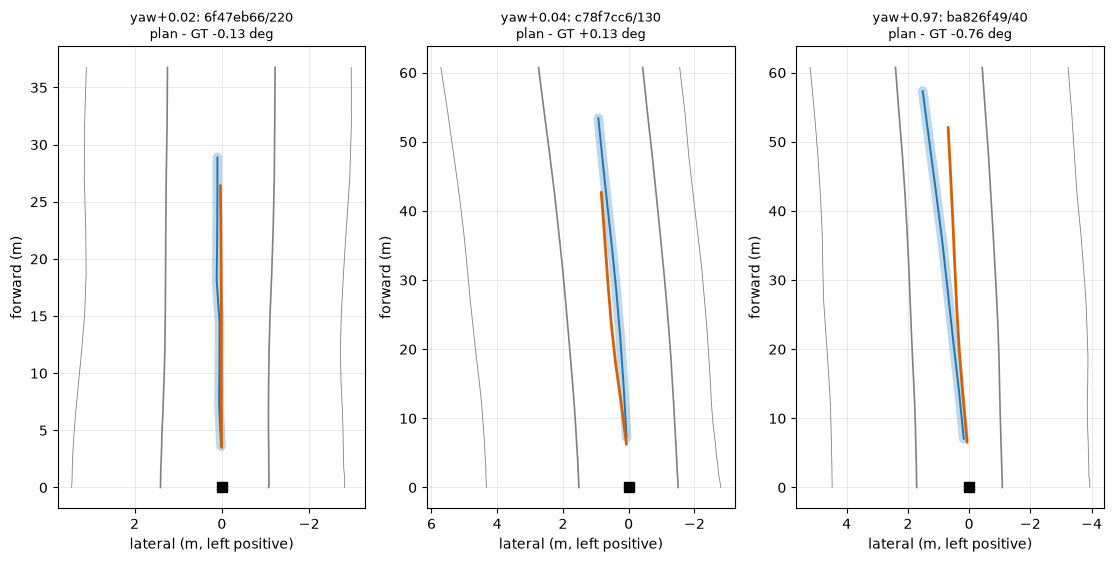

In [7]:
def bearing_deg(xy, k=-1):
    """Bearing of waypoint k, degrees left of straight ahead."""
    return np.degrees(np.arctan2(xy[:, k, 1], xy[:, k, 0]))


K4 = round(4 / DT) - 1  # the GT's last waypoint, 4 s out
with np.errstate(invalid="ignore", divide="ignore"):
    chord = np.linalg.norm(GT_RAW[:, K4], axis=-1)
    u = GT_RAW[:, K4] / chord[:, None]
    off_chord = np.abs(GT_RAW[:, : K4 + 1, 0] * -u[:, None, 1] + GT_RAW[:, : K4 + 1, 1] * u[:, None, 0]).max(
        1
    )
STRAIGHT = (chord >= 20) & (off_chord <= 0.25)
B = pd.DataFrame(
    {
        "calib": D.calib,
        "cam_yaw_deg": D.cam_yaw_deg,
        "gt": bearing_deg(GT_RAW, K4),
        "plan": bearing_deg(PRED, K4),
        "lanes": D.op_lane_heading_deg,
        "road_yaw": D.op_road_yaw_deg,
    }
)
B["plan_minus_gt"] = B.plan - B["gt"]  # B.gt is DataFrame.gt, the comparison method
straight = B[STRAIGHT]
print(
    f"{int(STRAIGHT.sum())} straight keyframes (the 4 s GT point at least 20 m out, the GT within 0.25 m of its chord): median bearing, deg left positive"
)
display(
    straight.groupby("calib")
    .agg(n=("gt", "size"), **{c: (c, "median") for c in straight.columns[1:]})
    .round(2)
)
OFFSET_DEG = (
    straight.groupby("calib").plan_minus_gt.median().to_dict()
)  # the plan's heading against the GT's, per mount
OFF_ROW = D.calib.map(OFFSET_DEG).fillna(0.0).to_numpy()
panels = [g for g in sorted(D.calib.unique()) if (STRAIGHT & (D.calib == g)).any()]
if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(4.5 * len(panels), 6), squeeze=False)
    for ax, g in zip(axes[0], panels):
        i = int(np.nanargmax(np.where(STRAIGHT & (D.calib == g), chord, np.nan)))
        for k, line in enumerate(LANES[i]):
            keep = line[:, 0] <= GT_RAW[i, K4, 0] + 10
            ax.plot(line[keep, 1], line[keep, 0], color="grey", lw=1.2 if k in (1, 2) else 0.6)
        bev.draw(ax, {MODEL: PRED[i, : K4 + 1]}, ground_truth=GT_RAW[i, : K4 + 1])
        ax.set_aspect("auto")  # stretch the lateral axis: the offset is a degree or less
        ax.set_title(
            f"{g}: {D.scene_id.iat[i][:8]}/{D.keyframe.iat[i]}\nplan - GT {B.plan_minus_gt.iat[i]:+.2f} deg",
            fontsize=9,
        )
    plt.show()

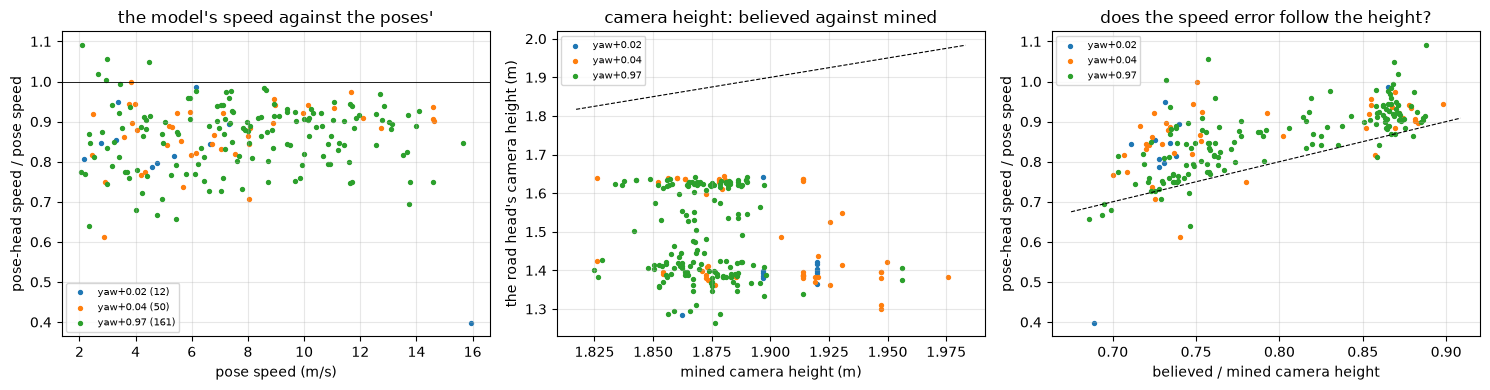

medians, all keyframes and per mount


,speed_ratio_pose,cam_h_ratio,lane_width_ratio,step0_ratio
calib,,,,
all,0.877,0.763,0.813,0.909
yaw+0.02,0.845,0.731,0.723,0.988
yaw+0.04,0.886,0.749,0.676,0.922
yaw+0.97,0.876,0.777,0.836,0.897


,speed_ratio_pose,cam_h_ratio,lane_width_ratio,step0_ratio
speed_ratio_pose,1.00,0.66,-0.03,0.51
cam_h_ratio,0.66,1.00,0.14,0.17
lane_width_ratio,-0.03,0.14,1.00,0.00
step0_ratio,0.51,0.17,0.00,1.00


medians by the believed camera height, under or over cam_h_split_m = 1.5 m


,speed_ratio_pose,cam_h_ratio,lane_width_ratio,step0_ratio,op_cam_h,op_lane_prob,ref_speed,n
cam_h_read,,,,,,,,
high,0.915,0.866,0.830,0.921,1.625,0.471,8.881,93
low,0.817,0.738,0.779,0.875,1.392,0.107,5.451,130


In [8]:
step0_gt, step0_plan = np.linalg.norm(GT_RAW[:, 0], axis=-1), np.linalg.norm(PRED[:, 0], axis=-1)
absent = pd.Series(np.nan, index=D.index)
mined_h, mined_w = D.get("ctx_height_ring_front_m", absent), D.get("ctx_lane_width_m", absent)
with np.errstate(invalid="ignore", divide="ignore"):
    SCALE = pd.DataFrame(
        {
            "calib": D.calib,
            "speed_ratio_pose": (D.op_v / D.ref_speed).where(D.ref_speed >= P["v_go"]),
            "cam_h_ratio": D.op_cam_h / mined_h,
            "lane_width_ratio": D.op_lane_width_m / mined_w,
            "step0_ratio": np.where(step0_gt >= P["v_go"] * DT, step0_plan / step0_gt, np.nan),
        }
    )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for g, idx in D.groupby("calib").groups.items():
    axes[0].scatter(D.ref_speed[idx], SCALE.speed_ratio_pose[idx], s=8, label=f"{g} ({len(idx)})")
    axes[1].scatter(mined_h[idx], D.op_cam_h[idx], s=8, label=g)
    axes[2].scatter(SCALE.cam_h_ratio[idx], SCALE.speed_ratio_pose[idx], s=8, label=g)
axes[0].axhline(1, color="k", lw=0.6)
axes[0].set(
    xlabel="pose speed (m/s)",
    ylabel="pose-head speed / pose speed",
    title="the model's speed against the poses'",
)
axes[1].set(
    xlabel="mined camera height (m)",
    ylabel="the road head's camera height (m)",
    title="camera height: believed against mined",
)
axes[2].set(
    xlabel="believed / mined camera height",
    ylabel="pose-head speed / pose speed",
    title="does the speed error follow the height?",
)
for ax in axes[1:]:
    lo, hi = ax.get_xlim()
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
print("medians, all keyframes and per mount")
display(pd.concat([SCALE.assign(calib="all"), SCALE]).groupby("calib").median().round(3))
display(SCALE.drop(columns="calib").corr().round(2))
h_mode = pd.Series(np.where(D.op_cam_h < P["cam_h_split_m"], "low", "high"), index=D.index)
by_h = (
    SCALE.drop(columns="calib")
    .assign(op_cam_h=D.op_cam_h, op_lane_prob=D.op_lane_prob, ref_speed=D.ref_speed)
    .groupby(h_mode.where(D.op_cam_h.notna(), "na").rename("cam_h_read"))
)
print(f"medians by the believed camera height, under or over cam_h_split_m = {P['cam_h_split_m']} m")
display(by_h.median().round(3).assign(n=by_h.size()))

In [9]:
with np.errstate(invalid="ignore", divide="ignore"):
    k_speed = np.where(
        D.op_v >= P["v_go"], D.ref_speed / D.op_v, 1.0
    )  # rescale the plan by the pose-head speed error
    k_oracle = np.where(
        step0_gt >= P["v_go"] * DT, step0_gt / step0_plan, 1.0
    )  # ... or by its first step against the GT's
fitted = rot(PRED, -np.radians(OFF_ROW))  # the plan turned by its mount's straight-road offset
variants = {
    "as recorded": PRED,
    "yaw fitted": fitted,
    "scaled by pose speed": PRED * k_speed[:, None, None],
    "both": fitted * k_speed[:, None, None],
    "yaw + oracle scale": fitted * k_oracle[:, None, None],
}
FDE3 = pd.DataFrame({name: disp(GT_RAW, n3, pred=v)[1] for name, v in variants.items()}).assign(calib=D.calib)
print(
    f"FDE@{EVAL_H:g}s (m) of the plan corrected each way: a diagnostic, not a score (the offsets are fitted on these keyframes)"
)
display(pd.concat([FDE3.assign(calib="all"), FDE3]).groupby("calib").agg(["mean", "median"]).round(3))

FDE@3s (m) of the plan corrected each way: a diagnostic, not a score (the offsets are fitted on these keyframes)


as recorded        yaw fitted        scaled by pose speed         \
                mean median       mean median                 mean median   
calib                                                                       
all            2.904  2.578      2.897  2.550                2.230  1.482   
yaw+0.02       1.903  1.532      1.908  1.532                7.774  2.458   
yaw+0.04       2.435  2.524      2.434  2.523                1.890  1.467   
yaw+0.97       3.124  2.674      3.114  2.665                1.923  1.457   

           both        yaw + oracle scale         
           mean median               mean median  
calib                                             
all       2.214  1.505              1.304  0.963  
yaw+0.02  7.777  2.465              1.323  1.153  
yaw+0.04  1.888  1.464              1.464  1.079  
yaw+0.97  1.901  1.455              1.253  0.929

## 5 Features

`kin()` runs the same kinematics on the GT and on the plan, over the response horizon H (`horizon_s`, columns without a suffix or ending `_H`) and over the intent horizon I (`intent_horizon_s`, 4 s here: the GT's whole length; columns ending `_I`), with the origin prepended so the first step starts at the car:

- per-step speeds at the step midpoints, giving `v_first`, `v_last`, `v_max`, `v_min` and the mean acceleration `accel`;
- path length `s`;
- heading change `dpsi_deg` between the first and last steps of at least `min_step_m`, and the mean curvature `kappa` over the arc between them;
- `shift`: the lateral offset at the end, net of what a constant-curvature arc with the same heading change explains. It is the lane-change signal.

`comfort_H` is paddock's own comfort check (`paddock.metrics.comfort`, nuPlan's bounds) over [0, H], the part of the plan a controller would act on.

`features()` then compares the plan with the GT (FDE, along/cross-track error, speed and curvature ratios, the speed the plan starts at, the error in the model's own σ at H). The `_I` columns and `gt_x_max_I` are NaN where the GT is shorter than I. `pred_dpsi_full_deg` is the plan's heading change over its whole 10 s, which the route modes (§12) compare with `cmd`. `FEATURE_DOCS` below documents every column a rule can use.

`v0_ratio` separates two things `speed_ratio` mixes: the speed the model believes the car has now (the plan's first 0.5 s) and what the plan then does with it; `speed_ratio_net` divides it out. §4 shows how far the start speed is off on this run, and whether it follows the camera height the model believes.

In [10]:
def kin(xy, n, min_step=None):
    """Kinematics of (k, 20, 2) paths over their first n waypoints, as a dict of per-keyframe arrays."""
    min_step = P["min_step_m"] if min_step is None else min_step
    pts = np.concatenate([np.zeros((len(xy), 1, 2)), xy[:, :n]], axis=1)
    step = np.diff(pts, axis=1)
    ds = np.linalg.norm(step, axis=-1)
    full = np.isfinite(ds).all(1)
    rows = np.arange(len(xy))
    with np.errstate(invalid="ignore", divide="ignore"):
        v = np.where(full[:, None], ds / DT, np.nan)
        psi = np.arctan2(step[..., 1], step[..., 0])
        ok = ds >= min_step
        first, last = ok.argmax(1), n - 1 - ok[:, ::-1].argmax(1)
        lat_ok = ok.any(1) & (last > first) & full
        dpsi = np.angle(np.exp(1j * (psi[rows, last] - psi[rows, first])))  # wrapped to (-pi, pi]
        mid = np.cumsum(ds, 1) - ds / 2
        arc = mid[rows, last] - mid[rows, first]
        s = np.where(full, ds.sum(1), np.nan)
        y_end = xy[:, n - 1, 1]
        # A constant-curvature arc of length s turning by dpsi ends (s / dpsi)(1 - cos dpsi) to the side
        arc_y = np.where(np.abs(dpsi) < 1e-6, 0.0, s * (1 - np.cos(dpsi)) / dpsi)
        return {
            "v_first": v[:, 0],
            "v_last": v[:, n - 1],
            "v_max": v.max(1),
            "v_min": v.min(1),
            "accel": (v[:, n - 1] - v[:, 0]) / (max(n - 1, 1) * DT),
            "s": s,
            "dpsi_deg": np.where(lat_ok, np.degrees(dpsi), np.nan),
            "kappa": np.where(lat_ok & (arc > 0), dpsi / arc, np.nan),
            "lat_ok": lat_ok,
            "shift": np.where(lat_ok, y_end - arc_y, np.nan),
        }


def _step_speeds(xy, n):
    """Per-step speeds (m/s) of (k, 20, 2) paths over their first n waypoints, starting from the origin."""
    pts = np.concatenate([np.zeros((len(xy), 1, 2)), xy[:, :n]], axis=1)
    return np.linalg.norm(np.diff(pts, axis=1), axis=-1) / DT


def features(gt_frame=None, params=None):
    """D plus the kinematics of GT and plan, and their comparison, per keyframe."""
    p = params or P
    nH, nI = round(p["horizon_s"] / DT), round(p["intent_horizon_s"] / DT)
    gt = gt_xy(gt_frame)
    cols = {}
    for side, xy in (("gt", gt), ("pred", PRED)):
        cols |= {f"{side}_{k}": v for k, v in kin(xy, nH, p["min_step_m"]).items()}
        far = kin(xy, nI, p["min_step_m"])
        cols |= {
            f"{side}_vmin_I": far["v_min"],
            f"{side}_dpsi_I_deg": far["dpsi_deg"],
            f"{side}_shift_I": far["shift"],
        }
        # paddock's comfort bounds over H (§5)
        comf = pd.DataFrame([comfort(x[:nH], DT) for x in xy])
        cols[f"{side}_comfort_H"] = comf.comfort_within_bounds.to_numpy()
    cols["pred_dpsi_full_deg"] = kin(PRED, N_WP, p["min_step_m"])["dpsi_deg"]
    # the loop ends on the plan, so `comf` is the plan's: which bounds it breaks, and by how much
    cols["pred_comfort_broken_H"] = comf.apply(
        lambda r: " ".join(b for b in BOUNDS if r[f"comfort_{b}_within_bounds"] == 0), axis=1
    ).to_numpy()
    cols["pred_comfort_excess_H"] = (
        pd.concat([comf[f"comfort_{b}_max"] / limit for b, limit in BOUNDS.items()], axis=1)
        .max(axis=1)
        .to_numpy()
    )
    ade, fde = disp(gt, nH)
    along, cross = split(PRED, gt, nH)
    with np.errstate(invalid="ignore", divide="ignore"):
        speed_ratio = np.where(cols["gt_s"] >= p["min_ratio_len_m"], cols["pred_s"] / cols["gt_s"], np.nan)
        # the speed the plan starts at, against the GT's: what the model believes now, apart from what it plans (start_speed)
        v0_ratio = np.where(
            cols["gt_v_first"] >= p["v_go"], cols["pred_v_first"] / cols["gt_v_first"], np.nan
        )
        # the plan with its start speed set to the GT's (§4's k_oracle; left as it is where the GT starts below
        # v_go): what is left of its error is its speed profile and its path, the split §16 audits ADE by
        k0 = np.where(cols["gt_v_first"] >= p["v_go"], cols["gt_v_first"] / cols["pred_v_first"], 1.0)
        net = PRED * k0[:, None, None]
        dv = _step_speeds(net, nH) - _step_speeds(gt, nH)
        vprof_rmse = np.sqrt(np.mean(dv[:, 1:] ** 2, axis=1))  # the first step matches by construction
        curving = np.abs(cols["gt_dpsi_deg"]) >= p["curve_min_deg"]
        curv_ratio = np.where(curving, cols["pred_dpsi_deg"] / cols["gt_dpsi_deg"], np.nan)
        sx, sy = SIGMA[:, nH - 1, 0], SIGMA[:, nH - 1, 1]
        dx, dy = (PRED[:, nH - 1] - gt[:, nH - 1]).T
        z = np.maximum(np.abs(dx) / sx, np.abs(dy) / sy)
    ade_net = disp(gt, nH, pred=net)[0]
    # NaN where the GT is shorter than I
    reach = gt[:, :nI, 0].max(1)
    cols |= {
        "ade_H": ade,
        "fde_H": fde,
        "along_H": along[:, -1],
        "cross_H": cross[:, -1],
        "speed_ratio": speed_ratio,
        "v0_ratio": v0_ratio,
        "speed_ratio_net": speed_ratio / v0_ratio,
        "v0_err": cols["pred_v_first"] - cols["gt_v_first"],
        "ade_net_H": ade_net,
        "ade_start_H": ade - ade_net,
        "vprof_rmse": vprof_rmse,
        "vprof_rel": vprof_rmse / np.maximum(cols["gt_s"] / (nH * DT), p["v_go"]),
        "curv_ratio": curv_ratio,
        "dpsi_err_deg": cols["pred_dpsi_deg"] - cols["gt_dpsi_deg"],
        "accel_delta": cols["pred_accel"] - cols["gt_accel"],
        "sigma_x_H": sx,
        "sigma_y_H": sy,
        "z_H": z,
        "gt_x_max_I": reach,
    }
    return pd.concat([D, pd.DataFrame(cols, index=D.index)], axis=1)


FEATURE_DOCS = {
    "split, scene, scene_id, keyframe": "identity; scene = split/scene_id, the unit scenes are counted in; keyframes every 90 frames from 40, at most 6 per scene",
    "cmd, nav, nav_dist_m, nav_text": "the route, which the model gets only in a run with command_source = gt and a desire (§17): the one-hot driving_command (left/straight/right; other if not one-hot), and nav_text parsed into a direction and a distance (m)",
    "calib, cam_yaw_deg, cam_pitch_deg, cam_h_m": "the front camera's mount as the harness built it (T_to_reference): yaw left+ and pitch down+ (deg, rpyCalib's signs), its height above the harness's ground (the rig's plus ground_offset_m); calib names the mount by its yaw",
    "model_ticks, warmup_frames": "the 20 Hz ticks of history the model got, and the ticks its feature queue needs",
    "ref_speed, ref_yaw_rate": "from the poses: speed (m/s, what the harness hands the model as CAN) and yaw rate (rad/s, left positive, central difference)",
    "op_lead_prob, op_lead_d, op_lead_y, op_lead_v_rel": "the model's lead head, first lead; kitscenes has no radar to check it against",
    "op_lane_prob": "the model's mean probability of the two ego lane lines",
    "op_lane_width_m, op_lane_offset_m, op_lane_heading_deg": "the model's ego lane: width at 10 m (m), centre offset at x = 0 (m, left positive), centre bearing from 10 to 40 m (deg, left positive)",
    "op_v, op_yaw_rate, op_plan_v0": "the model's pose head: speed (m/s) and yaw rate (rad/s, left positive); the plan's own speed at t = 0 (m/s), NaN in runs from before the adapter recorded it",
    "op_cam_h, op_road_pitch_deg, op_road_yaw_deg": "the road head: the camera height the model believes (m), and the road plane's pitch and yaw (deg)",
    "ego_speed_rel_err, ego_yaw_bias": "pose head against the poses: |v_model - v_ref| / max(v_ref, 1), and yaw rate model - reference",
    "rec_*": "every recorded per-keyframe metric with @ written _: ade over 3 s (or as much as the GT covers), fde_Ns (absent past the GT's end), longitudinal_mae and lateral_mae (mean |dx| and |dy| over 3 s, ego frame)",
    "ctx_*": "scenario mining's per-scene features (kinematics, map, traffic; tags file, context:)",
    "{gt,pred}_v_first, _v_last, _v_max, _v_min": "per-step speeds over H (m/s): first step, last step, max, min",
    "{gt,pred}_accel": "(v_last - v_first) / the time between them (m/s²)",
    "{gt,pred}_s": "path length over H (m)",
    "{gt,pred}_dpsi_deg, _kappa, _lat_ok": "heading change over H (deg, left positive) between the first and last steps of at least min_step_m; that over the arc between them (1/m); whether there were two such steps",
    "{gt,pred}_shift": "lateral offset at H net of a constant-curvature arc with the same heading change (m, left positive)",
    "{gt,pred}_vmin_I, _dpsi_I_deg, _shift_I": "the same over intent_horizon_s (I), for the intent tags; NaN where the GT is shorter than I",
    "pred_dpsi_full_deg": "the plan's heading change over its whole 10 s (deg, left positive), whatever I is; the route tags compare it with cmd",
    "{gt,pred}_comfort_H": "1 within every one of paddock's comfort bounds (paddock.metrics.comfort) over [0, H], 0 not, NaN if unmeasurable (a GT shorter than H)",
    "pred_comfort_broken_H, pred_comfort_excess_H": "the bounds the plan breaks over H, space-separated; its worst peak over that peak's bound (above 1 is broken)",
    "ade_H, fde_H": "ADE / FDE over [0, H] against the recorded GT (m); NaN where the GT is shorter than H",
    "along_H, cross_H": "along-track (ahead positive) and cross-track (left positive) error at H, against the GT's tangent (m)",
    "speed_ratio": "pred_s / gt_s, the ratio of mean speeds over H; NaN when gt_s < min_ratio_len_m",
    "v0_ratio": "pred_v_first / gt_v_first: the speed the plan starts at against the GT's, i.e. the speed the model believes the car has now; NaN when gt_v_first < v_go",
    "speed_ratio_net": "speed_ratio / v0_ratio: the plan's speed over H relative to where it starts, so a starting-speed offset (start_speed) drops out",
    "v0_err": "pred_v_first - gt_v_first (m/s): the start speed's error. At a constant speed it alone gives an ADE over n waypoints of |v0_err| · DT · (n + 1) / 2, 1.75 s × |v0_err| over 3 s (§16)",
    "ade_net_H, ade_start_H": "ADE over H of the plan with its start speed set to the GT's (scaled by gt_v_first / pred_v_first as §4's k_oracle; left as it is where gt_v_first < v_go), and ade_H minus that: the part of ADE the start speed explains, negative where the misread offsets an error of the opposite sign (§16)",
    "vprof_rmse, vprof_rel": "RMSE of that rescaled plan's per-step speeds against the GT's over H, after the first step (m/s), and it over max(the GT's mean speed over H, v_go): the speed profile's error with the start speed taken out (§16)",
    "curv_ratio": "pred_dpsi_deg / gt_dpsi_deg; NaN unless |gt_dpsi_deg| >= curve_min_deg",
    "dpsi_err_deg": "pred_dpsi_deg - gt_dpsi_deg (deg, left positive): how much more the plan turns than the GT over H, defined on straights too; phantom_curve and early_curve need |dpsi_err_deg| >= curve_err_deg",
    "accel_delta": "pred_accel - gt_accel (m/s²)",
    "sigma_x_H, sigma_y_H, z_H": "the model's own σ at H (m), and the error there in σ: max(|dx|/σx, |dy|/σy)",
    "gt_x_max_I": "the furthest forward the GT gets within intent_horizon_s (m, along the keyframe's x); NaN where the GT is shorter than I",
}


def feature_glossary():
    """FEATURE_DOCS as a markdown table."""
    return "\n".join(
        ["| columns | meaning |", "|---|---|", *(f"| {_md(k)} | {_md(v)} |" for k, v in FEATURE_DOCS.items())]
    )


display(Markdown(feature_glossary()))

| columns | meaning |
|---|---|
| split, scene, scene_id, keyframe | identity; scene = split/scene_id, the unit scenes are counted in; keyframes every 90 frames from 40, at most 6 per scene |
| cmd, nav, nav_dist_m, nav_text | the route, which the model gets only in a run with command_source = gt and a desire (§17): the one-hot driving_command (left/straight/right; other if not one-hot), and nav_text parsed into a direction and a distance (m) |
| calib, cam_yaw_deg, cam_pitch_deg, cam_h_m | the front camera's mount as the harness built it (T_to_reference): yaw left+ and pitch down+ (deg, rpyCalib's signs), its height above the harness's ground (the rig's plus ground_offset_m); calib names the mount by its yaw |
| model_ticks, warmup_frames | the 20 Hz ticks of history the model got, and the ticks its feature queue needs |
| ref_speed, ref_yaw_rate | from the poses: speed (m/s, what the harness hands the model as CAN) and yaw rate (rad/s, left positive, central difference) |
| op_lead_prob, op_lead_d, op_lead_y, op_lead_v_rel | the model's lead head, first lead; kitscenes has no radar to check it against |
| op_lane_prob | the model's mean probability of the two ego lane lines |
| op_lane_width_m, op_lane_offset_m, op_lane_heading_deg | the model's ego lane: width at 10 m (m), centre offset at x = 0 (m, left positive), centre bearing from 10 to 40 m (deg, left positive) |
| op_v, op_yaw_rate, op_plan_v0 | the model's pose head: speed (m/s) and yaw rate (rad/s, left positive); the plan's own speed at t = 0 (m/s), NaN in runs from before the adapter recorded it |
| op_cam_h, op_road_pitch_deg, op_road_yaw_deg | the road head: the camera height the model believes (m), and the road plane's pitch and yaw (deg) |
| ego_speed_rel_err, ego_yaw_bias | pose head against the poses: \|v_model - v_ref\| / max(v_ref, 1), and yaw rate model - reference |
| rec_* | every recorded per-keyframe metric with @ written _: ade over 3 s (or as much as the GT covers), fde_Ns (absent past the GT's end), longitudinal_mae and lateral_mae (mean \|dx\| and \|dy\| over 3 s, ego frame) |
| ctx_* | scenario mining's per-scene features (kinematics, map, traffic; tags file, context:) |
| {gt,pred}_v_first, _v_last, _v_max, _v_min | per-step speeds over H (m/s): first step, last step, max, min |
| {gt,pred}_accel | (v_last - v_first) / the time between them (m/s²) |
| {gt,pred}_s | path length over H (m) |
| {gt,pred}_dpsi_deg, _kappa, _lat_ok | heading change over H (deg, left positive) between the first and last steps of at least min_step_m; that over the arc between them (1/m); whether there were two such steps |
| {gt,pred}_shift | lateral offset at H net of a constant-curvature arc with the same heading change (m, left positive) |
| {gt,pred}_vmin_I, _dpsi_I_deg, _shift_I | the same over intent_horizon_s (I), for the intent tags; NaN where the GT is shorter than I |
| pred_dpsi_full_deg | the plan's heading change over its whole 10 s (deg, left positive), whatever I is; the route tags compare it with cmd |
| {gt,pred}_comfort_H | 1 within every one of paddock's comfort bounds (paddock.metrics.comfort) over [0, H], 0 not, NaN if unmeasurable (a GT shorter than H) |
| pred_comfort_broken_H, pred_comfort_excess_H | the bounds the plan breaks over H, space-separated; its worst peak over that peak's bound (above 1 is broken) |
| ade_H, fde_H | ADE / FDE over [0, H] against the recorded GT (m); NaN where the GT is shorter than H |
| along_H, cross_H | along-track (ahead positive) and cross-track (left positive) error at H, against the GT's tangent (m) |
| speed_ratio | pred_s / gt_s, the ratio of mean speeds over H; NaN when gt_s < min_ratio_len_m |
| v0_ratio | pred_v_first / gt_v_first: the speed the plan starts at against the GT's, i.e. the speed the model believes the car has now; NaN when gt_v_first < v_go |
| speed_ratio_net | speed_ratio / v0_ratio: the plan's speed over H relative to where it starts, so a starting-speed offset (start_speed) drops out |
| v0_err | pred_v_first - gt_v_first (m/s): the start speed's error. At a constant speed it alone gives an ADE over n waypoints of \|v0_err\| · DT · (n + 1) / 2, 1.75 s × \|v0_err\| over 3 s (§16) |
| ade_net_H, ade_start_H | ADE over H of the plan with its start speed set to the GT's (scaled by gt_v_first / pred_v_first as §4's k_oracle; left as it is where gt_v_first < v_go), and ade_H minus that: the part of ADE the start speed explains, negative where the misread offsets an error of the opposite sign (§16) |
| vprof_rmse, vprof_rel | RMSE of that rescaled plan's per-step speeds against the GT's over H, after the first step (m/s), and it over max(the GT's mean speed over H, v_go): the speed profile's error with the start speed taken out (§16) |
| curv_ratio | pred_dpsi_deg / gt_dpsi_deg; NaN unless \|gt_dpsi_deg\| >= curve_min_deg |
| dpsi_err_deg | pred_dpsi_deg - gt_dpsi_deg (deg, left positive): how much more the plan turns than the GT over H, defined on straights too; phantom_curve and early_curve need \|dpsi_err_deg\| >= curve_err_deg |
| accel_delta | pred_accel - gt_accel (m/s²) |
| sigma_x_H, sigma_y_H, z_H | the model's own σ at H (m), and the error there in σ: max(\|dx\|/σx, \|dy\|/σy) |
| gt_x_max_I | the furthest forward the GT gets within intent_horizon_s (m, along the keyframe's x); NaN where the GT is shorter than I |

## 6 Tags

`retag()` computes the features and applies every class, bin, failure mode and named strength in the tags file, giving `T`: `D` plus the features, one column per class (`gt_long`, `pred_long`, `history`, ...), `fm_<mode>` and `st_<strength>` booleans, and a `sev_<mode>` severity where a mode fired.

- Re-run from here after changing `P` or the tags file. `retag(params=P | {"a_brake": -0.7})` gives a second table to compare without touching `T`; pass it to any helper as `df=`.
- `select(where=None, df=None, **conds)` returns the matching rows. Each keyword is a column and a value, or a list of values; `where` is any pandas query and can use params as `@name`.
- `explain(sample_id)` shows one keyframe's kinematics and every rule with the values it read. `→` is the rule that set the tag, `✓` a rule that also matched but came later, `·` one that did not match.

The prevalence table is the first sanity check: a tag at 0% or 100% usually means a threshold or a unit is off.

In [11]:
def _mask(df, expr, p):
    """A boolean Series from a rule. NaN (an undefined comparison) is False."""
    out = df.eval(expr, engine="python", local_dict=p)
    return pd.Series(out, index=df.index).fillna(False).astype(bool)


def _unside(df, side):
    """df with one side's columns also under their bare names (gt_v_max -> v_max), for sided rules."""
    n = len(side) + 1
    return df.assign(**{c[n:]: df[c] for c in df.columns if c.startswith(f"{side}_")})


def _classify(df, spec, p):
    """One class column: the first matching rule's label, `default` if none, `missing` where a required column is NaN."""
    out = pd.Series(spec["default"], index=df.index, dtype=object)
    taken = (
        df[spec["requires"]].isna().any(axis=1) if spec.get("requires") else pd.Series(False, index=df.index)
    )
    out[taken] = spec.get("missing", "na")
    for label, rule in spec["rules"].items():
        hit = _mask(df, rule["when"], p) & ~taken
        out[hit] = label
        taken = taken | hit
    return out


def retag(params=None, gt_frame=None, tags=None, bench=BENCH):
    """The tag table: features, then every class, bin, failure mode and strength that applies to this benchmark."""
    p, tags = params or P, tags or CFG
    df = features(gt_frame, p)
    for name, spec in tags["classes"].items():
        if applies(spec, bench):
            for side in spec.get("sides", [None]):
                df[f"{side}_{name}" if side else name] = _classify(_unside(df, side) if side else df, spec, p)
    for name, spec in tags["bins"].items():
        if applies(spec, bench):
            edges = [p[e[1:]] if isinstance(e, str) else e for e in spec["edges"]]
            cut = pd.cut(df[spec["col"]], [-np.inf, *edges, np.inf], labels=spec["labels"], right=False)
            df[name] = cut.astype(object).where(cut.notna(), spec.get("missing", "na"))
    for kind, prefix in (("failure_modes", "fm_"), ("strengths", "st_")):
        for name, spec in tags[kind].items():
            if applies(spec, bench):
                hit = _mask(df, spec["when"], p)
                df[prefix + name] = hit
                if "severity" in spec:
                    sev = pd.Series(df.eval(spec["severity"], engine="python", local_dict=p), index=df.index)
                    df[f"sev_{name}"] = sev.astype(float).where(hit)
    return df.copy()


ID_TAGS = {
    "scenario": ["split", "calib"],
    "intent": ["cmd", "nav"],
}  # columns of D to condition on beside the tags file's, by group


def tag_columns(df=None, tags=None, bench=BENCH, max_values=12):
    """{group: [columns]}: every categorical column you can condition on, grouped as in the tags file."""
    df, tags = (T if df is None else df), tags or CFG
    groups = {g: list(ID_TAGS.get(g, [])) for g in ("scenario", "intent", "perception", "response")}
    for name, spec in tags["classes"].items():
        if applies(spec, bench):
            for c in _outputs(name, spec):
                groups.setdefault("response" if c.startswith("pred_") else spec["group"], []).append(c)
    for name, spec in tags["bins"].items():
        if applies(spec, bench):
            groups.setdefault(spec["group"], []).append(name)
    groups["failure modes"] = [c for c in df.columns if c.startswith("fm_")]
    groups["strengths"] = [c for c in df.columns if c.startswith("st_")]
    groups["context"] = [c for c in df.columns if c.startswith("ctx_") and df[c].nunique() <= max_values]
    return {g: cs for g, cs in groups.items() if cs}


def select(where=None, df=None, **conds):
    """Rows of T (or df) where every column in conds has the given value (or one of a list), and the query `where`."""
    df = T if df is None else df
    unknown = [c for c in conds if c not in df.columns]
    if unknown:
        known = [c for cs in tag_columns(df).values() for c in cs]
        raise KeyError(f"{unknown} are not columns; the tag columns are {known}")
    mask = pd.Series(True, index=df.index)
    for col, val in conds.items():
        mask &= df[col].isin(val if isinstance(val, (list, tuple, set)) else [val])
    out = df[mask]
    return out.query(where, engine="python", local_dict=P) if where else out


def prevalence(df=None, groups=None):
    """Share of keyframes for each value of each tag column."""
    df = T if df is None else df
    rows = []
    for g, cols in (groups or tag_columns(df)).items():
        for c in cols:
            if df[c].dtype == bool:
                values = f"{df[c].mean():.1%} ({int(df[c].sum())})"
            else:
                vc = df[c].value_counts(normalize=True, dropna=False)
                values = " · ".join(f"{k} {v:.0%}" for k, v in vc.items())
            rows.append({"group": g, "tag": c, "values": values})
    return pd.DataFrame(rows).set_index(["group", "tag"])


_KEYWORDS = {"and", "or", "not", "in", "abs", "True", "False"}


def _names(expr):
    """The column names a rule reads: identifiers that are not @params, keywords or quoted strings."""
    bare = re.sub(r"'[^']*'|\"[^\"]*\"", "", expr or "")
    return [n for n in dict.fromkeys(re.findall(r"(?<![@\w])[A-Za-z_]\w*", bare)) if n not in _KEYWORDS]


def _fmt(v):
    return f"{v:.3g}" if isinstance(v, (float, np.floating)) else str(v)


KIN = [
    "v_first",
    "v_last",
    "v_max",
    "v_min",
    "accel",
    "s",
    "dpsi_deg",
    "kappa",
    "lat_ok",
    "shift",
    "vmin_I",
    "dpsi_I_deg",
    "shift_I",
]
COMPARED = [
    "fde_H",
    "ade_H",
    "along_H",
    "cross_H",
    "speed_ratio",
    "v0_ratio",
    "speed_ratio_net",
    "curv_ratio",
    "dpsi_err_deg",
    "accel_delta",
    "z_H",
    "rec_fde_3s",
    "ref_speed",
    "pred_dpsi_full_deg",
    "op_cam_h",
]


def explain(sample_id, df=None, params=None, tags=None, bench=BENCH):
    """Why each tag and mode fired for one keyframe: its kinematics, then every rule with the values it read."""
    p, tags = params or P, tags or CFG
    df = T if df is None else df
    one = df.loc[[_row(sample_id, df)]]
    print(one.sample_id.iat[0])
    display(
        pd.DataFrame(
            {side: [float(one[f"{side}_{k}"].iat[0]) for k in KIN] for side in ("gt", "pred")}, index=KIN
        ).T.round(3)
    )
    display(one[COMPARED].round(3))
    lines = []
    for name, spec in tags["classes"].items():
        if not applies(spec, bench):
            continue
        for side in spec.get("sides", [None]):
            col = f"{side}_{name}" if side else name
            sub = _unside(one, side) if side else one
            label = one[col].iat[0]
            lines.append(f"{col} = {label}")
            if spec.get("requires") and sub[spec["requires"]].isna().any(axis=1).iat[0]:
                lines.append(f"    NaN in {spec['requires']} -> {spec.get('missing', 'na')}")
                continue
            for rule_label, rule in spec["rules"].items():
                fired = bool(_mask(sub, rule["when"], p).iat[0])
                mark = "→" if rule_label == label else "✓" if fired else "·"
                values = ", ".join(f"{n}={_fmt(sub[n].iat[0])}" for n in _names(rule["when"]))
                lines.append(f"  {mark} {rule_label:<14} {rule['when']:<45} {values}")
    print("\n".join(lines))
    fired = [c for c in one.columns if c.startswith("fm_") and one[c].iat[0]]
    for c in fired:
        spec = tags["failure_modes"][c[3:]]
        values = ", ".join(f"{n}={_fmt(one[n].iat[0])}" for n in _names(spec["when"]))
        print(f"MODE {c[3:]} (severity {_fmt(one[f'sev_{c[3:]}'].iat[0])}): {spec['when']}\n    {values}")
    quiet = [c[3:] for c in one.columns if c.startswith("fm_") and c not in fired]
    print(textwrap.fill("did not fire: " + ", ".join(quiet), 110))
    strong = [c[3:] for c in one.columns if c.startswith("st_") and one[c].iat[0]]
    print("strengths: " + (", ".join(strong) or "none"))


def _row(key, df):
    """A row label (= array position) from a sample id, or a row label passed through."""
    if isinstance(key, str):
        hit = df.index[df.sample_id == key]
        if not len(hit):
            raise KeyError(f"{key!r} is not among the loaded keyframes (FOCUS / SUBSET in §1)")
        return hit[0]
    return key


T = retag()
print(f"T: {len(T)} keyframes x {T.shape[1]} columns")
with pd.option_context("display.max_colwidth", None, "display.max_rows", 200):
    display(prevalence())

T: 223 keyframes x 180 columns


values
group         tag                                                                                                                              
scenario      split                                                                                             val 83% · overlap_train_val 17%
              calib                                                                                   yaw+0.97 72% · yaw+0.04 22% · yaw+0.02 5%
              speed_band                                                                                       low 91% · mid 6% · standstill 3%
              gt_long                                            cruise 64% · brake 17% · accel 17% · starting 1% · stationary 1% · stopping 0%
              gt_lat                        straight 39% · curve_L 16% · curve_R 13% · sharp_R 13% · sharp_L 7% · turn_L 6% · turn_R 4% · na 1%
              ego_turning                                                                                              steady 75% · turning 25%
              history                                                                                                    clamped 63% · full 37%
intent        cmd                                                                                             straight 83% · left 9% · right 8%
              nav                                                                                           straight 79% · right 11% · left 10%
              gt_stop_I                                                                                                     none 95% · stops 5%
              gt_turn_I                                                                                none 91% · turn_L 5% · turn_R 3% · na 1%
              gt_lane_change_I                                                                                       none 98% · left 1% · na 1%
perception    lanes                                                                                              none 74% · weak 22% · clear 4%
              speed_read                                                                                                   misread 90% · ok 10%
              start_speed                                                                                   slow 74% · ok 12% · na 8% · fast 6%
              cam_h_read                                                                                                     low 58% · high 42%
              yaw_read                                                                                                       ok 95% · biased 5%
response      pred_long                                          cruise 68% · brake 16% · accel 13% · stationary 2% · starting 0% · stopping 0%
              pred_lat                      straight 38% · curve_L 17% · sharp_R 15% · curve_R 13% · sharp_L 9% · turn_L 4% · na 2% · turn_R 2%
              accel_response                                                            na 65% · matched 26% · under_reacts 9% · over_reacts 0%
              side_H                                                                                               on 71% · right 21% · left 9%
              confidence                                           within_2sigma 39% · within_1sigma 30% · beyond_2sigma 26% · beyond_4sigma 4%
              comfort                                                                                                   comfortable 95% · na 5%
              speed_ratio_bin                                   slower 52% · much_slower 17% · matched 13% · faster 7% · na 7% · much_faster 3%
              curv_ratio_bin                                          na 62% · matched 19% · understeer 10% · oversteer 5% · wrong_direction 4%
failure modes fm_too_slow_cruise                                                                                                    45.3% (101)
              fm_too_fast_cruise                                                                         

In [12]:
explain(T.sample_id.iat[0])

kitscenes/val/00fc1b9b-005e-554c-7733-c4c0adeca015/40


,v_first,v_last,v_max,v_min,accel,s,dpsi_deg,kappa,lat_ok,shift,vmin_I,dpsi_I_deg,shift_I
gt,2.239,3.171,3.171,2.239,0.373,8.035,-0.331,-0.001,1.0,0.246,2.239,-1.478,0.375
pred,2.550,4.478,4.478,2.550,0.771,10.349,-1.403,-0.003,1.0,0.246,2.550,-3.922,0.475


,fde_H,ade_H,along_H,cross_H,speed_ratio,v0_ratio,speed_ratio_net,curv_ratio,dpsi_err_deg,accel_delta,z_H,rec_fde_3s,ref_speed,pred_dpsi_full_deg,op_cam_h
0,2.318,1.09,2.314,-0.151,1.288,1.139,1.131,NaN,-1.071,0.398,1.038,2.318,2.094,-21.948,1.632


speed_band = low
  · standstill     ref_speed < @v_stop                           ref_speed=2.09
  → low            ref_speed < @v_low                            ref_speed=2.09
  ✓ mid            ref_speed < @v_mid                            ref_speed=2.09
gt_long = cruise
  · stationary     v_max < @v_stop                               v_max=3.17
  · starting       v_first < @v_stop and v_last > @v_go          v_first=2.24, v_last=3.17
  · stopping       v_first > @v_go and v_last < @v_stop          v_first=2.24, v_last=3.17
  · hard_brake     accel <= @a_hard_brake                        accel=0.373
  · brake          accel <= @a_brake                             accel=0.373
  · hard_accel     accel >= @a_hard_accel                        accel=0.373
  · accel          accel >= @a_accel                             accel=0.373
pred_long = accel
  · stationary     v_max < @v_stop                               v_max=4.48
  · starting       v_first < @v_stop and v_last > @v_go          v

**Trying a rule change without editing the file.** Work on a copy of `CFG` and pass it as `tags=`; every helper then takes the new table as `df=`:

```python
import copy
CFG2 = copy.deepcopy(CFG)
CFG2["classes"]["long"]["rules"]["brake"]["when"] = "accel <= -0.3"
CFG2["failure_modes"]["slow_on_curves"] = {"group": "long", "when": "gt_lat in ['curve_L', 'curve_R'] and speed_ratio < 0.9", "severity": "1 - speed_ratio", "doc": "..."}
T2 = retag(tags=CFG2)
confusion("long", df=T2); modes(df=T2, tags=CFG2)
```

## 7 Scores

All recomputed in numpy from `PRED` and `GT_RAW`, so any value can be tried in well under a second.

1. `recorded()`: `metrics.json` exactly as stored, overall and per split: the mean over the keyframes that have each metric.
2. `scores(by=, horizons=, yaw_offset_deg=, miss_m=, stat=, where=, **conds)`: ADE, FDE, miss rate (FDE > `miss_m`), along-track error and |cross-track| error at each horizon up to 4 s, per group of any tag column(s). A keyframe whose GT is shorter than a horizon is left out; ADE needs the whole horizon.
3. `score_explorer()`: the same behind widgets, with `WIDGETS = True` (§1).
4. `fde_curve()`: a metric against horizon, one line per group.
5. `yaw_sweep()`: FDE at H against an extra GT rotation, per mount, with §4's straight-road offset dotted. A minimum away from 0° means the plan and the GT disagree about straight ahead.

With every keyframe loaded, the recompute is asserted equal to `metrics.json`.

In [13]:
def _hkey(k):
    name, _, h = k.partition("@")
    return (name, float(h.rstrip("s")) if h else EVAL_H)


def recorded(pattern=r"ade|fde@\d+s|l\w+_mae", stat="mean"):
    """metrics.json as stored, overall and per split: `stat` of every metric matching pattern."""
    groups = {"all": {"n": M["n"], **M["metrics"]}, **M.get("by_split", {})}
    rows = {
        g: {"n": m.get("n")}
        | {k: v[stat] for k, v in m.items() if isinstance(v, dict) and re.fullmatch(pattern, k)}
        for g, m in groups.items()
    }
    out = pd.DataFrame(rows).T
    return out[["n", *sorted(out.columns.drop("n"), key=_hkey)]].round(3)


def per_keyframe(horizons=(1, 2, 3, 4), gt_frame=None, yaw_offset_deg=0.0, miss_m=None):
    """Per keyframe: ADE, FDE, miss, along and |cross| at each horizon (s), against the GT in gt_frame."""
    gt, miss_m = gt_xy(gt_frame, yaw_offset_deg), P["miss_m"] if miss_m is None else miss_m
    cols = {}
    for h in horizons:
        n = round(h / DT)
        ade, fde = disp(gt, n)
        along, cross = split(PRED, gt, n)
        cols |= {
            f"ade@{h:g}s": ade,
            f"fde@{h:g}s": fde,
            f"miss@{h:g}s": np.where(np.isnan(fde), np.nan, fde > miss_m),
            f"along@{h:g}s": along[:, -1],
            f"|cross|@{h:g}s": np.abs(cross[:, -1]),
        }
    return pd.DataFrame(cols, index=D.index)


STATS = {"median": "median", "mean": "mean", "p90": lambda s: s.quantile(0.9)}


def scores(
    by=None,
    horizons=(1, 2, 3, 4),
    gt_frame=None,
    yaw_offset_deg=0.0,
    miss_m=None,
    stat="median",
    where=None,
    df=None,
    **conds,
):
    """Errors per group of any tag column(s), on the loaded keyframes. Miss rates are always a mean."""
    sel = select(where, df, **conds)
    k = per_keyframe(horizons, gt_frame, yaw_offset_deg, miss_m).loc[sel.index]
    keys = [by] if isinstance(by, str) else list(by or [])
    grouped = k.assign(**{c: sel[c] for c in keys}, _scene=sel.scene).groupby(
        keys or (lambda _: "all"), dropna=False, observed=True
    )
    miss = [c for c in k if c.startswith("miss@")]
    out = grouped[[c for c in k if c not in miss]].agg(STATS[stat])
    out[miss] = grouped[miss].mean()
    out.insert(0, "scenes", grouped["_scene"].nunique())
    out.insert(0, "n", grouped.size())
    return out[["n", "scenes", *k.columns]].round(3)


print("recorded: metrics.json, mean over the whole run")
display(recorded())
print(f"recomputed on the {len(D)} loaded keyframes, mean, by split and by mount")
display(scores(by="split", stat="mean"))
display(scores(by="calib", stat="mean"))
if len(D) == M["n"]:
    whole = per_keyframe((1, 2, 3))
    whole["ade@3s"] = whole["ade@3s"].fillna(
        D.rec_ade
    )  # a GT shorter than 3 s: the record's ADE over what it covers
    lon, lat = np.abs(PRED[:, :n3] - GT_RAW[:, :n3]).mean(1).T
    whole["longitudinal_mae"] = pd.Series(lon, index=D.index).fillna(D.rec_longitudinal_mae)
    whole["lateral_mae"] = pd.Series(lat, index=D.index).fillna(D.rec_lateral_mae)
    whole = whole.mean()
    for mine, rec in (
        ("ade@3s", "ade"),
        ("fde@1s", "fde@1s"),
        ("fde@2s", "fde@2s"),
        ("fde@3s", "fde@3s"),
        ("longitudinal_mae", "longitudinal_mae"),
        ("lateral_mae", "lateral_mae"),
    ):
        assert abs(whole[mine] - M["metrics"][rec]["mean"]) < 1e-5, (
            mine,
            whole[mine],
            M["metrics"][rec]["mean"],
        )
    print(
        f"every keyframe loaded: the recompute equals metrics.json (ADE and the MAEs take the record on the {int((~full).sum())} keyframes whose GT is shorter than {EVAL_H:g} s, checked in §4)"
    )

recorded: metrics.json, mean over the whole run


,n,ade,fde@1s,fde@2s,fde@3s,lateral_mae,longitudinal_mae
all,223.0,1.595,0.828,1.801,2.904,0.286,1.526
overlap_train_val,37.0,1.753,0.918,1.980,3.175,0.263,1.716
val,186.0,1.564,0.810,1.765,2.850,0.291,1.488


recomputed on the 223 loaded keyframes, mean, by split and by mount


,n,scenes,ade@1s,fde@1s,miss@1s,along@1s,|cross|@1s,ade@2s,fde@2s,miss@2s,...,ade@3s,fde@3s,miss@3s,along@3s,|cross|@3s,ade@4s,fde@4s,miss@4s,along@4s,|cross|@4s
split,,,,,,,,,,,,,,,,,,,,,
overlap_train_val,37,23,0.685,0.918,0.081,-0.683,0.122,1.195,1.980,0.351,...,1.753,3.175,0.703,-2.066,0.596,2.359,4.526,0.730,-2.886,0.985
val,186,117,0.604,0.810,0.048,-0.681,0.115,1.059,1.765,0.339,...,1.564,2.850,0.613,-2.205,0.475,2.129,4.169,0.796,-3.087,0.717


,n,scenes,ade@1s,fde@1s,miss@1s,along@1s,|cross|@1s,ade@2s,fde@2s,miss@2s,...,ade@3s,fde@3s,miss@3s,along@3s,|cross|@3s,ade@4s,fde@4s,miss@4s,along@4s,|cross|@4s
calib,,,,,,,,,,,,,,,,,,,,,
yaw+0.02,12,3,0.352,0.488,0.000,-0.007,0.088,0.663,1.154,0.167,...,1.012,1.903,0.333,0.316,0.333,1.390,2.735,0.667,0.349,0.434
yaw+0.04,50,27,0.430,0.580,0.020,-0.451,0.096,0.798,1.384,0.200,...,1.250,2.435,0.600,-1.707,0.460,1.806,3.844,0.820,-2.517,0.759
yaw+0.97,161,110,0.696,0.930,0.068,-0.802,0.124,1.201,1.978,0.398,...,1.746,3.124,0.658,-2.516,0.518,2.337,4.459,0.783,-3.474,0.786


every keyframe loaded: the recompute equals metrics.json (ADE and the MAEs take the record on the 0 keyframes whose GT is shorter than 3 s, checked in §4)


In [14]:
display(scores(by="gt_long"))
display(scores(by=["history", "calib"], stat="mean"))

,n,scenes,ade@1s,fde@1s,miss@1s,along@1s,|cross|@1s,ade@2s,fde@2s,miss@2s,...,ade@3s,fde@3s,miss@3s,along@3s,|cross|@3s,ade@4s,fde@4s,miss@4s,along@4s,|cross|@4s
gt_long,,,,,,,,,,,,,,,,,,,,,
accel,37,34,0.558,0.759,0.000,-0.610,0.077,0.813,1.388,0.270,...,1.272,2.469,0.649,-2.390,0.279,1.801,3.796,0.757,-3.535,0.321
brake,38,38,0.591,0.753,0.079,-0.703,0.084,0.863,1.419,0.316,...,1.344,2.321,0.526,-1.721,0.271,1.748,3.466,0.711,-1.932,0.372
cruise,142,99,0.543,0.714,0.063,-0.705,0.095,0.944,1.589,0.373,...,1.426,2.675,0.662,-2.540,0.325,1.955,3.855,0.824,-3.692,0.458
starting,3,3,0.113,0.163,0.000,-0.155,0.008,0.323,0.729,0.333,...,0.774,2.086,0.667,-0.544,0.153,1.415,3.743,0.667,0.248,0.225
stationary,2,2,0.066,0.101,0.000,0.101,0.001,0.120,0.196,0.000,...,0.149,0.226,0.000,0.166,0.004,0.203,0.434,0.000,-0.039,0.001
stopping,1,1,0.021,0.023,0.000,0.016,0.016,0.085,0.243,0.000,...,0.364,1.244,0.000,1.243,0.051,0.968,3.422,1.000,3.422,0.043


n  scenes  ade@1s  fde@1s  miss@1s  along@1s  |cross|@1s  \
history calib                                                                  
clamped yaw+0.02    3       3   0.396   0.523    0.000    -0.429       0.046   
        yaw+0.04   27      27   0.362   0.491    0.000    -0.404       0.087   
        yaw+0.97  110     110   0.635   0.852    0.045    -0.777       0.105   
full    yaw+0.02    9       2   0.337   0.476    0.000     0.133       0.102   
        yaw+0.04   23      14   0.509   0.685    0.043    -0.507       0.107   
        yaw+0.97   51      35   0.828   1.099    0.118    -0.858       0.166   

                  ade@2s  fde@2s  miss@2s  ...  ade@3s  fde@3s  miss@3s  \
history calib                              ...                            
clamped yaw+0.02   0.732   1.281    0.333  ...   1.147   2.224    0.333   
        yaw+0.04   0.724   1.324    0.148  ...   1.215   2.517    0.667   
        yaw+0.97   1.114   1.856    0.373  ...   1.650   3.020    0.655   
full    yaw+0.02   0.640   1.112    0.111  ...   0.967   1.796    0.333   
        yaw+0.04   0.884   1.455    0.261  ...   1.292   2.339    0.522   
        yaw+0.97   1.389   2.241    0.451  ...   1.953   3.348    0.667   

                  along@3s  |cross|@3s  ade@4s  fde@4s  miss@4s  along@4s  \
history calib                                                               
clamped yaw+0.02    -0.571       0.207   1.622   3.342    0.667    -0.556   
        yaw+0.04    -1.730       0.505   1.816   4.001    0.889    -2.592   
        yaw+0.97    -2.573       0.435   2.244   4.376    0.764    -3.566   
full    yaw+0.02     0.611       0.376   1.313   2.533    0.667     0.651   
        yaw+0.04    -1.680       0.409   1.795   3.661    0.739    -2.430   
        yaw+0.97    -2.392       0.695   2.539   4.637    0.824    -3.276   

                  |cross|@4s  
history calib                 
clamped yaw+0.02       0.181  
        yaw+0.04       0.752  
        yaw+0.97       0.674  
full    yaw+0.02       0.519  
        yaw+0.04       0.768  
        yaw+0.97       1.028  

[6 rows x 22 columns]

In [15]:
def _as_html(fn, *args, **kw):
    """Run fn; return what it printed and displayed, in order, as HTML for a W.HTML widget.

    The widgets render into W.HTML rather than W.Output so that a headless run cannot hang.
    nbclient (what `jupyter execute` runs) emulates an Output widget by sending its contents
    back to the kernel on the socket it is polling for the cell's reply; for some sizes that
    reply is then missed, and the cell waits out its whole timeout -- which `jupyter execute`
    does not set. A W.HTML's state only ever travels kernel -> frontend: nothing to miss.
    """
    shell, parts = get_ipython(), []

    class Stdout(io.TextIOBase):
        def write(self, s):
            parts.append(s)
            return len(s)

    saved, shell.display_pub = shell.display_pub, DisplayPublisher()
    shell.display_pub.publish = lambda data, *a, **k: parts.append(data)
    try:
        with contextlib.redirect_stdout(Stdout()):
            fn(*args, **kw)
    except Exception as e:  # an empty selection or a bad query: show it rather than break the widget
        parts.append(f"{type(e).__name__}: {e}\n")
    finally:
        shell.display_pub = saved
    blocks = []
    for is_text, group in itertools.groupby(parts, key=lambda p: isinstance(p, str)):
        if is_text:  # consecutive prints share one block
            blocks.append(f"<pre>{html.escape(''.join(group))}</pre>")
            continue
        for data in group:
            mime = next((m for m in ("image/png", "image/jpeg") if m in data), None)
            if mime:
                img = data[mime] if isinstance(data[mime], str) else base64.b64encode(data[mime]).decode()
                blocks.append(f'<img src="data:{mime};base64,{img}" style="max-width:100%">')
            else:
                blocks.append(
                    data.get("text/html") or f"<pre>{html.escape(data.get('text/plain', ''))}</pre>"
                )
    return "\n".join(blocks)


def _condition_widgets(df, groups=None):
    """One multi-select per tag column (every value, with its count), one tab per group. Returns (tab, pickers, conds)."""
    groups = groups or tag_columns(df)
    pickers, pages = {}, []
    for cols in groups.values():
        boxes = []
        for c in cols:
            vc = df[c].value_counts(dropna=False)
            pickers[c] = W.SelectMultiple(
                options=[(f"{v} ({n})", v) for v, n in vc.items()],
                rows=min(6, len(vc)),
                layout=W.Layout(width="300px"),
            )
            boxes.append(W.VBox([W.Label(c), pickers[c]]))
        pages.append(W.GridBox(boxes, layout=W.Layout(grid_template_columns="repeat(3, 310px)")))
    tab = W.Tab(children=pages, titles=list(groups))

    def conds():
        return {
            c: [v.item() if hasattr(v, "item") else v for v in w.value] for c, w in pickers.items() if w.value
        }

    return tab, pickers, conds


def _no_widgets(instead):
    """True, after saying what to call instead, unless WIDGETS (§1) is on and ipywidgets is installed."""
    if WIDGETS and W is not None:
        return False
    print(f"{'ipywidgets is not installed' if WIDGETS else 'widgets are off (WIDGETS in §1)'}: {instead}")
    return True


def score_explorer(df=None):
    """scores() behind widgets: group by, horizons, extra yaw, miss radius, statistic and conditions."""
    if _no_widgets("call scores(...) directly"):
        return
    df = T if df is None else df
    cols = [c for cs in tag_columns(df).values() for c in cs]
    by = W.Dropdown(options=[None, *cols], value="split", description="by")
    then = W.Dropdown(options=[None, *cols], value=None, description="then by")
    hz = W.SelectMultiple(
        options=[0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4], value=(1, 2, 3, 4), rows=8, description="horizons (s)"
    )
    yaw = W.FloatSlider(value=0.0, min=-3, max=3, step=0.1, description="+ yaw (deg)")
    miss = W.FloatSlider(value=P["miss_m"], min=0.5, max=5, step=0.25, description="miss (m)")
    stat = W.Dropdown(options=list(STATS), value="median", description="stat")
    tab, pickers, conds = _condition_widgets(df)
    out = W.HTML()

    def table():
        keys = [k for k in (by.value, then.value) if k]
        display(scores(keys, tuple(hz.value), None, yaw.value, miss.value, stat.value, df=df, **conds()))

    def refresh(*_):
        out.value = _as_html(table)

    for w in (by, then, hz, yaw, miss, stat, *pickers.values()):
        w.observe(refresh, "value")
    refresh()
    display(W.VBox([W.HBox([by, then, stat]), W.HBox([hz, W.VBox([yaw, miss])]), tab, out]))


score_explorer()

widgets are off (WIDGETS in §1): call scores(...) directly


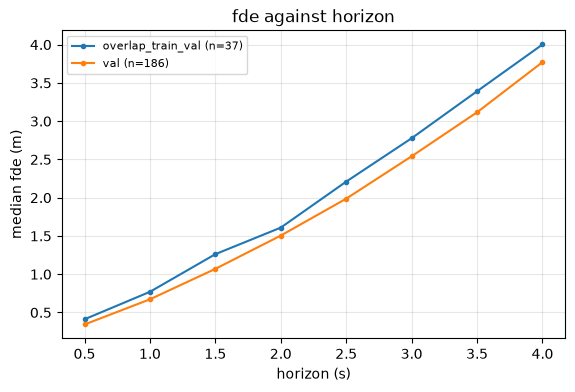

,n,fde@0.5s,fde@1s,fde@1.5s,fde@2s,fde@2.5s,fde@3s,fde@3.5s,fde@4s
split,,,,,,,,,
overlap_train_val,37,0.411,0.770,1.262,1.609,2.210,2.777,3.391,4.002
val,186,0.343,0.672,1.070,1.505,1.987,2.541,3.116,3.771


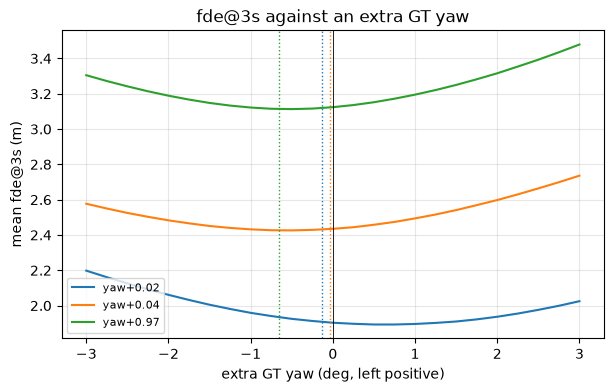

yaw+0.02    0.5
yaw+0.04   -0.5
yaw+0.97   -0.5
Name: best yaw (deg), dtype: float64

In [16]:
def fde_curve(
    by="split",
    metric="fde",
    stat="median",
    horizons=(0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4),
    where=None,
    df=None,
    **conds,
):
    """A metric (ade, fde, miss, along, |cross|) against horizon, one line per group."""
    s = scores(by, horizons, stat=stat, where=where, df=df, **conds)
    cols = [f"{metric}@{h:g}s" for h in horizons]
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for key, row in s.iterrows():
        ax.plot(horizons, row[cols].to_numpy(float), marker="o", ms=3, label=f"{key} (n={row.n:.0f})")
    ax.set(xlabel="horizon (s)", ylabel=f"{stat} {metric} (m)", title=f"{metric} against horizon")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.show()
    return s[["n", *cols]]


def yaw_sweep(offsets=None, h_s=None, by="calib", stat="mean", where=None, df=None, **conds):
    """FDE at h_s against an extra GT yaw, per group; §4's straight-road offset dotted per mount. Returns the yaw of each minimum."""
    offsets = np.linspace(-3, 3, 25) if offsets is None else np.asarray(offsets)
    h_s = h_s or EVAL_H
    col = f"fde@{h_s:g}s"
    curves = pd.DataFrame(
        {o: scores(by, (h_s,), None, o, stat=stat, where=where, df=df, **conds)[col] for o in offsets}
    )
    fig, ax = plt.subplots(figsize=(7, 4))
    best = {}
    for key, row in curves.iterrows():
        vals = row.to_numpy(float)
        (line,) = ax.plot(offsets, vals, label=str(key))
        if np.isfinite(vals).any():
            best[key] = offsets[np.nanargmin(vals)]
        if by == "calib" and key in OFFSET_DEG:
            ax.axvline(OFFSET_DEG[key], color=line.get_color(), ls=":", lw=1)
    ax.axvline(0, color="k", lw=0.6)
    ax.set(
        xlabel="extra GT yaw (deg, left positive)",
        ylabel=f"{stat} {col} (m)",
        title=f"{col} against an extra GT yaw",
    )
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.show()
    return pd.Series(best, name="best yaw (deg)")


display(fde_curve())
display(yaw_sweep())

## 8 Distributions, with the thresholds drawn in

`dist(cols=, by=, bins=, params=, where=, **conds)` draws one histogram (density) per column and group, with every threshold the tags file applies to that column as a dashed line. This is where a guessed threshold gets tuned: a threshold in the middle of a dense mode splits one behaviour into two tags. Values beyond the 1st–99th percentile range (widened to include the thresholds) are piled into the end bins. `THRESHOLDS` maps each column to the params drawn on it; `-name` draws the negated value.

`scatter()` puts the GT against the plan for the same feature. Points on the dashed diagonal are plans that did what the GT did.

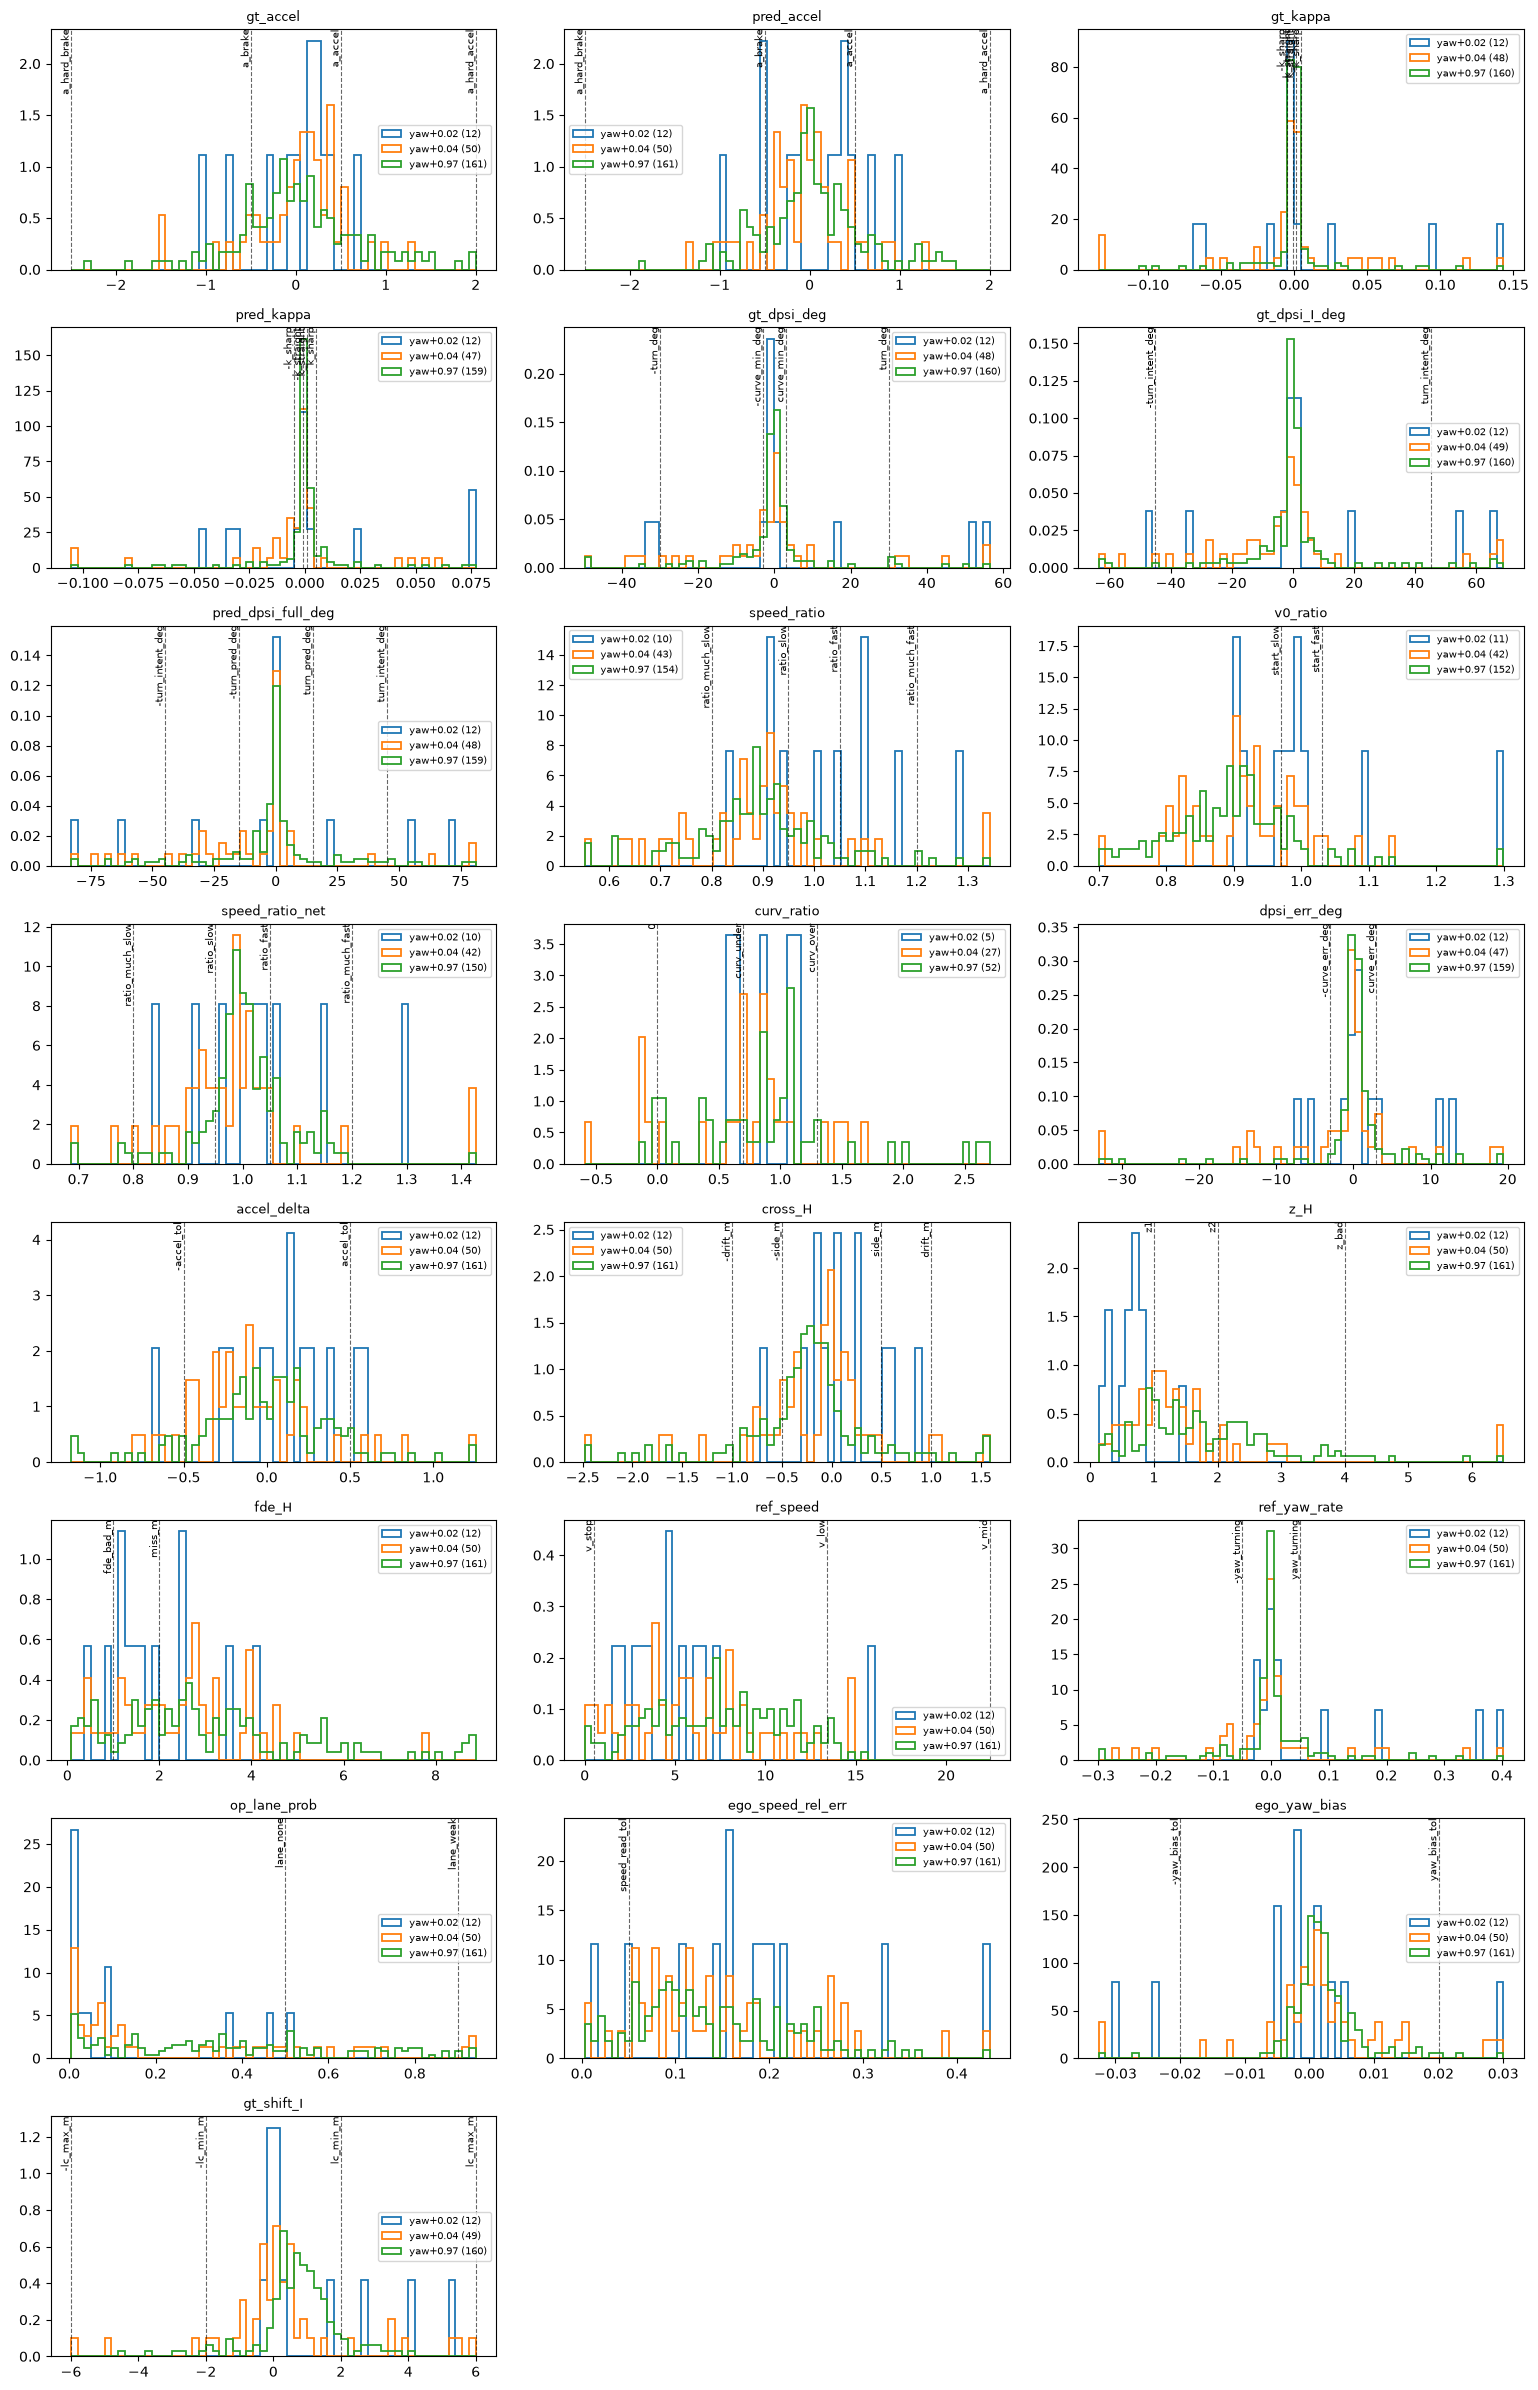

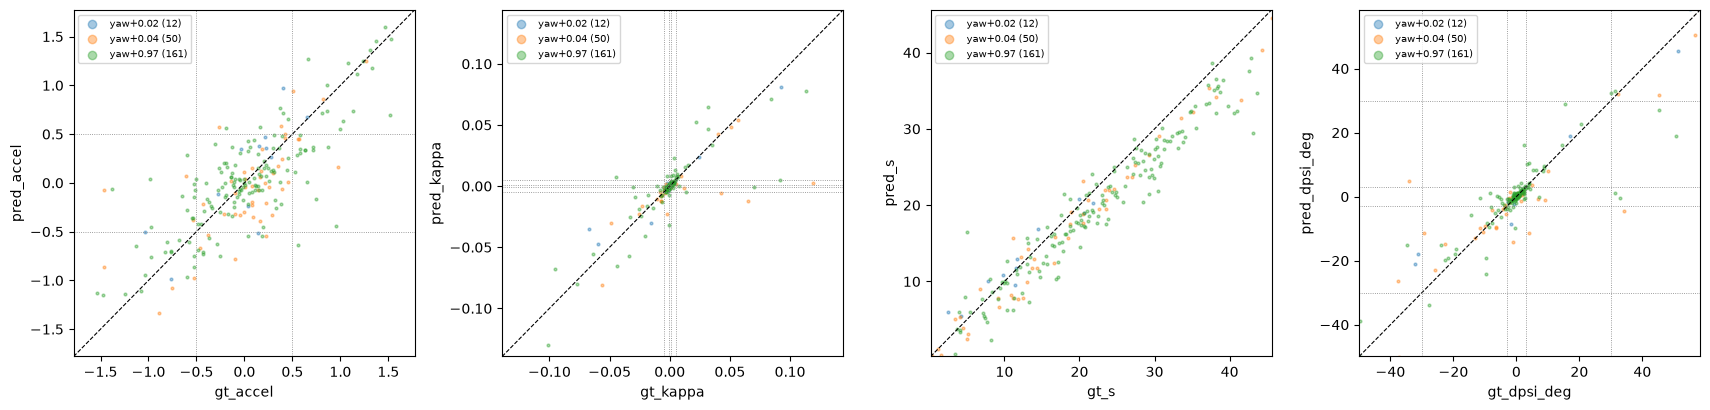

In [17]:
THRESHOLDS = {
    "gt_accel": ["a_hard_brake", "a_brake", "a_accel", "a_hard_accel"],
    "pred_accel": ["a_hard_brake", "a_brake", "a_accel", "a_hard_accel"],
    "gt_kappa": ["-k_sharp", "-k_straight", "k_straight", "k_sharp"],
    "pred_kappa": ["-k_sharp", "-k_straight", "k_straight", "k_sharp"],
    "gt_dpsi_deg": ["-turn_deg", "-curve_min_deg", "curve_min_deg", "turn_deg"],
    "gt_dpsi_I_deg": ["-turn_intent_deg", "turn_intent_deg"],
    "pred_dpsi_full_deg": ["-turn_intent_deg", "-turn_pred_deg", "turn_pred_deg", "turn_intent_deg"],
    "speed_ratio": ["ratio_much_slow", "ratio_slow", "ratio_fast", "ratio_much_fast"],
    "v0_ratio": ["start_slow", "start_fast"],
    "speed_ratio_net": ["ratio_much_slow", "ratio_slow", "ratio_fast", "ratio_much_fast"],
    "curv_ratio": [0.0, "curv_under", "curv_over"],
    "dpsi_err_deg": ["-curve_err_deg", "curve_err_deg"],
    "accel_delta": ["-accel_tol", "accel_tol"],
    "cross_H": ["-drift_m", "-side_m", "side_m", "drift_m"],
    "z_H": ["z1", "z2", "z_bad"],
    "fde_H": ["fde_bad_m", "miss_m"],
    "ref_speed": ["v_stop", "v_low", "v_mid"],
    "ref_yaw_rate": ["-yaw_turning", "yaw_turning"],
    "op_lane_prob": ["lane_none", "lane_weak"],
    "ego_speed_rel_err": ["speed_read_tol"],
    "ego_yaw_bias": ["-yaw_bias_tol", "yaw_bias_tol"],
    "gt_shift_I": ["-lc_max_m", "-lc_min_m", "lc_min_m", "lc_max_m"],
}


def _lines(col, p):
    """[(label, value)] of the thresholds drawn on a column."""
    out = []
    for t in THRESHOLDS.get(col, []):
        if isinstance(t, str):
            name = t.lstrip("-")
            out.append((t, -p[name] if t.startswith("-") else p[name]))
        else:
            out.append((f"{t:g}", t))
    return out


def _groups(sel, by):
    return sel.groupby(by, dropna=False, observed=True) if by else [("all", sel)]


def dist(cols=None, by="calib", bins=60, params=None, where=None, df=None, **conds):
    """Histograms per group with the tag thresholds as dashed lines."""
    p = params or P
    sel = select(where, df, **conds)
    cols = cols or list(THRESHOLDS)
    ncol = min(3, len(cols))
    nrow = -(-len(cols) // ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 3 * nrow), squeeze=False)
    for ax, col in zip(axes.flat, cols):
        x = sel[col].astype(float)
        x = x[np.isfinite(x)]
        if x.empty:
            ax.set_title(f"{col}: no values", fontsize=9)
            continue
        th = [v for _, v in _lines(col, p)]
        lo, hi = np.percentile(x, [1, 99])
        lo, hi = min([lo, *th]), max([hi, *th])
        if hi <= lo:
            lo, hi = lo - 1, hi + 1
        edges = np.linspace(lo, hi, bins + 1)
        for key, grp in _groups(sel, by):
            v = grp[col].astype(float)
            v = v[np.isfinite(v)].clip(lo, hi)
            if len(v):
                ax.hist(v, edges, density=True, histtype="step", lw=1.3, label=f"{key} ({len(v)})")
        for name, v in _lines(col, p):
            ax.axvline(v, color="k", ls="--", lw=0.8, alpha=0.6)
            ax.text(v, ax.get_ylim()[1], f" {name}", rotation=90, va="top", ha="right", fontsize=7)
        ax.set_title(col, fontsize=9)
        ax.legend(fontsize=7)
    for ax in axes.flat[len(cols) :]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


def scatter(
    pairs=(
        ("gt_accel", "pred_accel"),
        ("gt_kappa", "pred_kappa"),
        ("gt_s", "pred_s"),
        ("gt_dpsi_deg", "pred_dpsi_deg"),
    ),
    by="calib",
    params=None,
    where=None,
    df=None,
    **conds,
):
    """GT (x) against plan (y) for each pair, y = x dashed, the GT column's thresholds dotted on both axes."""
    p = params or P
    sel = select(where, df, **conds)
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.3 * len(pairs), 4.2), squeeze=False)
    for ax, (xc, yc) in zip(axes[0], pairs):
        for key, grp in _groups(sel, by):
            ax.scatter(grp[xc], grp[yc], s=4, alpha=0.4, label=f"{key} ({len(grp)})")
        xy = sel[[xc, yc]].astype(float).to_numpy()
        xy = xy[np.isfinite(xy).all(1)]
        if len(xy):
            lo, hi = np.percentile(xy, [0.5, 99.5])
            ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
            ax.set(xlim=(lo, hi), ylim=(lo, hi))
        for _, v in _lines(xc, p):
            ax.axvline(v, color="grey", lw=0.6, ls=":")
            ax.axhline(v, color="grey", lw=0.6, ls=":")
        ax.set(xlabel=xc, ylabel=yc)
        ax.legend(fontsize=7, markerscale=3)
    fig.tight_layout()
    plt.show()


dist()
scatter()

## 9 Scenario clusters

`clusters(by=("gt_lat", "gt_long", "speed_band"), min_n=5, where=, **conds)` groups keyframes by any combination of tags. Per cluster: the number of keyframes and scenes, median and p90 FDE at H, the share where the plan's speed and curvature match the GT (`speed_ratio_bin` / `curv_ratio_bin` = matched, among keyframes where they are defined), the plan's most common response, and the failure mode with the highest rate there.

`heatmap(row=, col=, value=, stat=, min_n=)` shows one value over two tags, e.g. the median `fde_H`, or the rate of a failure mode (`value="fm_under_brakes"`). Cells under `min_n` keyframes are blank.

With `FOCUS` on one scene, few clusters reach `min_n` and the table can come out empty: `clusters(min_n=1)` lists them all.

n  scenes  fde_H_median  fde_H_p90  \
gt_lat   gt_long speed_band                                        
straight cruise  low         44      37          2.77       4.35   
curve_L  cruise  low         21      19          2.56       4.73   
curve_R  cruise  low         18      17          2.20       5.59   
sharp_R  cruise  low         18      17          2.68       3.93   
straight brake   low         18      18          1.95       4.49   
sharp_L  cruise  low         12      11          2.41       5.44   
straight accel   low         12      12          1.92       5.29   
         cruise  mid         10       8          7.13       9.42   
curve_L  accel   low          9       9          2.65       3.65   
turn_L   cruise  low          9       9          2.54       5.04   
turn_R   cruise  low          8       8          1.85       3.18   
curve_R  brake   low          7       7          2.62       4.86   
sharp_R  accel   low          6       5          3.85       7.34   

                             speed_matched_pct  curv_matched_pct    pred_long  \
gt_lat   gt_long speed_band                                                     
straight cruise  low                      6.82               NaN   cruise 84%   
curve_L  cruise  low                     15.00             66.67   cruise 90%   
curve_R  cruise  low                     22.22             77.78   cruise 89%   
sharp_R  cruise  low                     25.00             41.18   cruise 78%   
straight brake   low                     22.22               NaN    brake 56%   
sharp_L  cruise  low                     11.11             60.00   cruise 83%   
straight accel   low                     18.18               NaN    accel 67%   
         cruise  mid                      0.00               NaN  cruise 100%   
curve_L  accel   low                      0.00             66.67    accel 56%   
turn_L   cruise  low                     11.11             55.56   cruise 78%   
turn_R   cruise  low                     16.67             42.86   cruise 62%   
curve_R  brake   low                     14.29              0.00    brake 57%   
sharp_R  accel   low                     33.33             66.67   cruise 50%   

                                 pred_lat                top_mode  
gt_lat   gt_long speed_band                                        
straight cruise  low         straight 91%   ego_speed_misread 95%  
curve_L  cruise  low          curve_L 71%   ego_speed_misread 86%  
curve_R  cruise  low          curve_R 72%   ego_speed_misread 83%  
sharp_R  cruise  low          sharp_R 78%   ego_speed_misread 94%  
straight brake   low         straight 67%   ego_speed_misread 89%  
sharp_L  cruise  low          sharp_L 58%  ego_speed_misread 100%  
straight accel   low         straight 75%  ego_speed_misread 100%  
         cruise  mid         straight 80%    too_slow_cruise 100%  
curve_L  accel   low          curve_L 78%  ego_speed_misread 100%  
turn_L   cruise  low           turn_L 67%  ego_speed_misread 100%  
turn_R   cruise  low           turn_R 38%  ego_speed_misread 100%  
curve_R  brake   low          curve_R 43%   ego_speed_misread 86%  
sharp_R  accel   low          sharp_R 83%   ego_speed_misread 83%

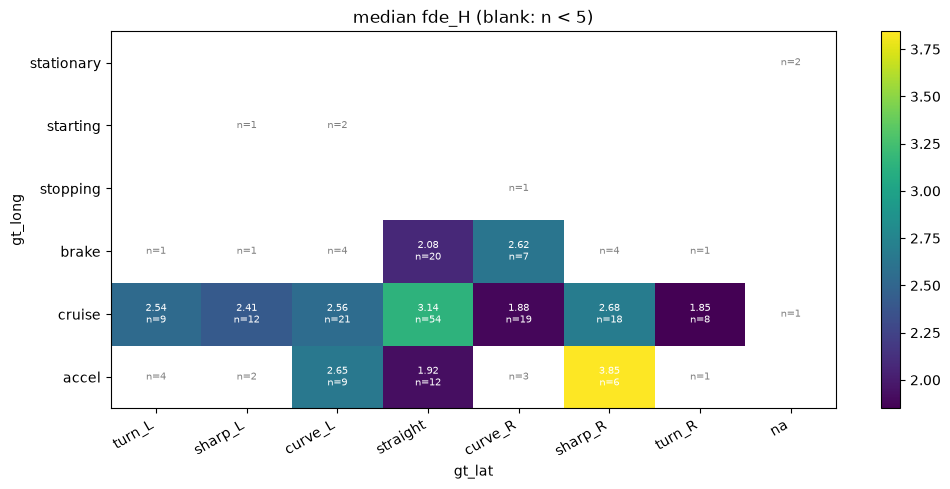

gt_lat,turn_L,sharp_L,curve_L,straight,curve_R,sharp_R,turn_R,na
gt_long,,,,,,,,
stationary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
starting,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stopping,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brake,NaN,NaN,NaN,2.078,2.621,NaN,NaN,NaN
cruise,2.537,2.411,2.557,3.139,1.885,2.683,1.849,NaN
accel,NaN,NaN,2.646,1.925,NaN,3.845,NaN,NaN


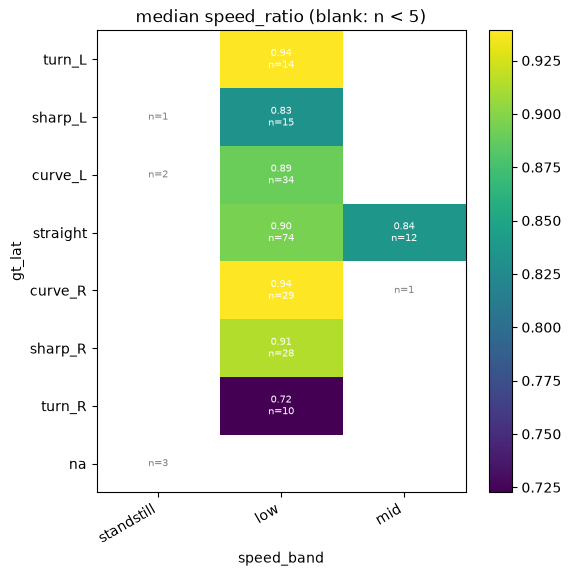

speed_band,standstill,low,mid
gt_lat,,,
turn_L,NaN,0.939,NaN
sharp_L,NaN,0.833,NaN
curve_L,NaN,0.890,NaN
straight,NaN,0.896,0.837
curve_R,NaN,0.939,NaN
sharp_R,NaN,0.914,NaN
turn_R,NaN,0.723,NaN
na,NaN,NaN,NaN


In [18]:
ORDER = {  # reading order for tables and matrices; other tags follow the tags file
    "long": ["stationary", "starting", "stopping", "hard_brake", "brake", "cruise", "accel", "hard_accel"],
    "lat": ["turn_L", "sharp_L", "curve_L", "straight", "curve_R", "sharp_R", "turn_R", "na"],
}


def _order(col, values, tags=None):
    """values in the tag's natural order (ORDER, else the tags file's rule order), unknown ones last."""
    tags = tags or CFG
    bare = re.sub(r"^(gt|pred)_", "", col)
    spec = tags["classes"].get(bare) or tags["bins"].get(bare) or {}
    key = ORDER.get(bare) or [
        *spec.get("rules", {}),
        spec.get("default"),
        *spec.get("labels", []),
        spec.get("missing", "na"),
    ]
    return sorted(values, key=lambda v: (key.index(v) if v in key else len(key), str(v)))


def _top(s):
    vc = s.value_counts(normalize=True)
    return f"{vc.index[0]} {vc.iloc[0]:.0%}" if len(vc) else ""


def _matched(s):
    """1.0 where a ratio bin is matched, 0.0 where it is not, NaN where it is undefined."""
    return s.eq("matched").astype(float).where(s.ne("na"))


def _intent(col, tags=None):
    return (tags or CFG)["failure_modes"].get(col[3:], {}).get("group") == "intent"


def clusters(by=("gt_lat", "gt_long", "speed_band"), min_n=5, where=None, df=None, **conds):
    """Every combination of the `by` tags with at least min_n keyframes, and how the plan fared there."""
    sel = select(where, df, **conds)
    fm = [c for c in sel.columns if c.startswith("fm_") and not _intent(c)]
    g = sel.assign(_speed=_matched(sel.speed_ratio_bin), _curv=_matched(sel.curv_ratio_bin)).groupby(
        list(by), dropna=False, observed=True
    )
    out = g.agg(
        n=("sample_id", "size"),
        scenes=("scene", "nunique"),
        fde_H_median=("fde_H", "median"),
        fde_H_p90=("fde_H", lambda s: s.quantile(0.9)),
        speed_matched_pct=("_speed", "mean"),
        curv_matched_pct=("_curv", "mean"),
        pred_long=("pred_long", _top),
        pred_lat=("pred_lat", _top),
    )
    out[["speed_matched_pct", "curv_matched_pct"]] *= 100
    rates = g[fm].mean()
    out["top_mode"] = [
        f"{c[3:]} {r[c]:.0%}" if r[c] > 0 else "" for c, (_, r) in zip(rates.idxmax(axis=1), rates.iterrows())
    ]
    return out[out.n >= min_n].sort_values("n", ascending=False).round(2)


def heatmap(row="gt_long", col="gt_lat", value="fde_H", stat="median", min_n=5, where=None, df=None, **conds):
    """One value over two tags, annotated with n; a boolean value (fm_*, st_*) shows its rate."""
    sel = select(where, df, **conds)
    how = "mean" if sel[value].dtype == bool else stat
    g = sel.assign(_v=sel[value].astype(float)).groupby([row, col], observed=True)["_v"]
    rows, cols = _order(row, sel[row].unique()), _order(col, sel[col].unique())
    t = g.agg(STATS[how]).unstack().reindex(index=rows, columns=cols)
    n = g.size().unstack().reindex(index=rows, columns=cols).fillna(0).astype(int)
    t = t.where(n >= min_n)
    fig, ax = plt.subplots(figsize=(1.15 * len(cols) + 2.5, 0.55 * len(rows) + 1.6))
    im = ax.imshow(t.to_numpy(float), cmap="viridis", aspect="auto")
    for (r, c), v in np.ndenumerate(t.to_numpy(float)):
        text = f"{v:.2f}\nn={n.iat[r, c]}" if np.isfinite(v) else (f"n={n.iat[r, c]}" if n.iat[r, c] else "")
        ax.text(c, r, text, ha="center", va="center", fontsize=7, color="w" if np.isfinite(v) else "grey")
    ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right")
    ax.set_yticks(range(len(rows)), rows)
    ax.set(xlabel=col, ylabel=row, title=f"{how} {value} (blank: n < {min_n})")
    fig.colorbar(im, ax=ax)
    plt.show()
    return t.round(3)


with pd.option_context("display.max_rows", 60):
    display(clusters())
display(heatmap())
display(heatmap("gt_lat", "speed_band", value="speed_ratio"))

## 10 Confusion: GT class against plan class

`confusion(axis="long" | "lat", normalize="index")`: rows are the GT's class over H, columns the plan's, from the same rules. With `normalize="index"` each row sums to 1 and reads as "when the GT did this, the plan did …"; `"columns"` reads as "when the plan did this, the GT had done …"; `"all"` or `None` for shares or counts. Cells show the share and the count.

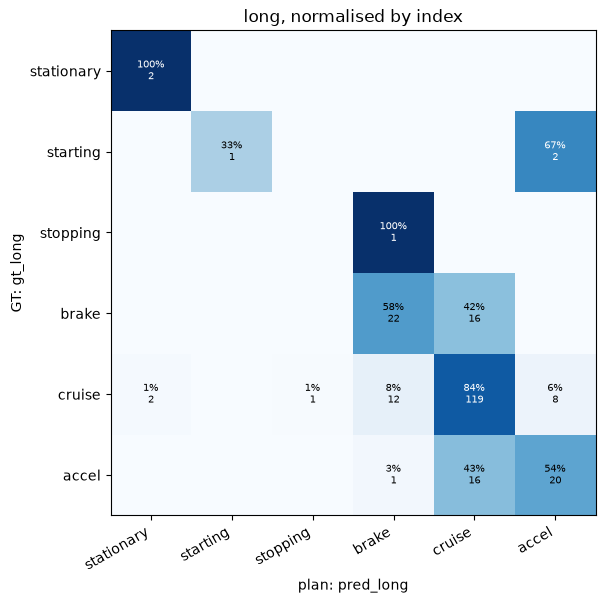

pred_long,stationary,starting,stopping,brake,cruise,accel
gt_long,,,,,,
stationary,2,0,0,0,0,0
starting,0,1,0,0,0,2
stopping,0,0,0,1,0,0
brake,0,0,0,22,16,0
cruise,2,0,1,12,119,8
accel,0,0,0,1,16,20


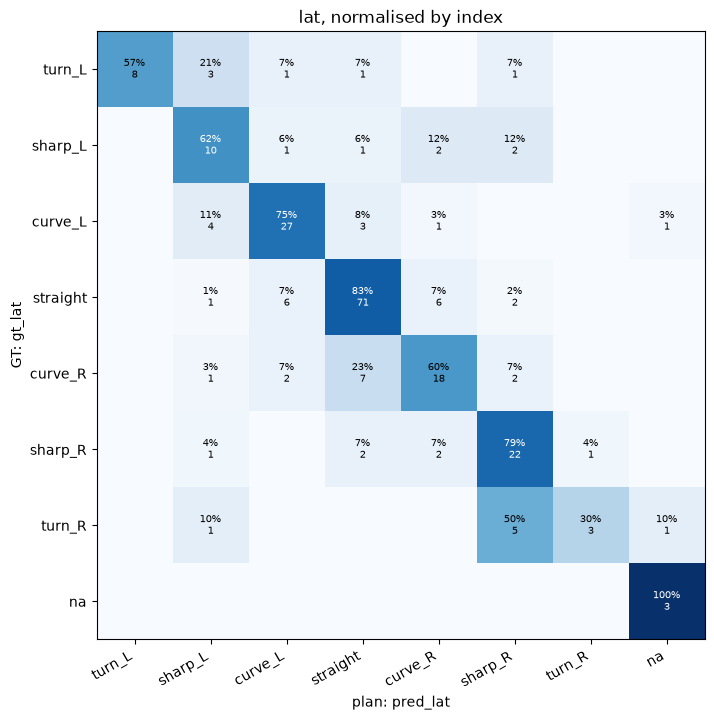

pred_lat,turn_L,sharp_L,curve_L,straight,curve_R,sharp_R,turn_R,na
gt_lat,,,,,,,,
turn_L,8,3,1,1,0,1,0,0
sharp_L,0,10,1,1,2,2,0,0
curve_L,0,4,27,3,1,0,0,1
straight,0,1,6,71,6,2,0,0
curve_R,0,1,2,7,18,2,0,0
sharp_R,0,1,0,2,2,22,1,0
turn_R,0,1,0,0,0,5,3,1
na,0,0,0,0,0,0,0,3


In [19]:
def confusion(axis="long", normalize="index", where=None, df=None, **conds):
    """GT class (rows) against plan class (columns), annotated with share and count. Returns the counts."""
    sel = select(where, df, **conds)
    gt, pred = sel[f"gt_{axis}"], sel[f"pred_{axis}"]
    labels = _order(axis, set(gt) | set(pred))
    counts = pd.crosstab(gt, pred).reindex(index=labels, columns=labels, fill_value=0)
    if normalize == "index":
        share = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)
    elif normalize == "columns":
        share = counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1)
    elif normalize == "all":
        share = counts / max(counts.to_numpy().sum(), 1)
    else:
        share = counts.astype(float)
    fig, ax = plt.subplots(figsize=(0.95 * len(labels) + 2.5, 0.8 * len(labels) + 1.5))
    ax.imshow(share.to_numpy(float), cmap="Blues", vmin=0)
    top = np.nanmax(share.to_numpy(float), initial=0.0)
    for (r, c), v in np.ndenumerate(share.to_numpy(float)):
        if counts.iat[r, c]:
            text = f"{v:.0%}\n{counts.iat[r, c]}" if normalize else f"{counts.iat[r, c]}"
            ax.text(c, r, text, ha="center", va="center", fontsize=7, color="w" if v > 0.6 * top else "k")
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set(xlabel=f"plan: pred_{axis}", ylabel=f"GT: gt_{axis}", title=f"{axis}, normalised by {normalize}")
    plt.show()
    return counts


display(confusion("long"))
display(confusion("lat"))

## 11 Conditions: `profile()` and `explore()`

Two equivalent ways to pick keyframes and see what they look like.

- **Variables.** Set `COND` (any tag column: a value or a list of values) and `WHERE` (any pandas query) and call `profile(where=WHERE, **COND)`. `select()` with the same arguments returns the rows themselves.
- **Widgets.** With `WIDGETS = True` (§1), `explore()` has one multi-select per tag column (every observed value with its count), range sliders for speed, the ratios and the errors, and a query box. It re-runs `profile()` on every change and prints the `COND` and `WHERE` it applied, so a selection made with the mouse can be pasted into the cell above and kept. The button draws three matches with `show()`.

`profile()` shows: the size of the selection; how the plan responded; the error and ratio columns; the failure modes with their rate against the rate over everything loaded (lift); the scenario, perception and context tags most over-represented in the selection (lift, excluding the columns you conditioned on); the selection's histograms against everything; and sample ids to look at, one per scene. A tag value needs at least 3 keyframes in the selection to be listed, so on a small `FOCUS` the tag lift can come out empty.

In [20]:
def lift(sel, base=None, groups=("scenario", "intent", "perception", "context"), exclude=(), top=10, min_n=3):
    """Tag values over-represented in sel: share in sel / share in base (default all of T)."""
    base = T if base is None else base
    cols = [c for g, cs in tag_columns(base).items() if g in groups for c in cs if c not in exclude]
    rows = []
    for c in cols:
        # shares among the keyframes where the column is defined; NaN never counts as a value
        in_base = base[c].value_counts(normalize=True)
        known = sel[c].notna().sum()
        for v, k in sel[c].value_counts().items():
            if k >= min_n and v in in_base.index:
                share = k / known
                rows.append(
                    {
                        "tag": c,
                        "value": v,
                        "n": k,
                        "share": share,
                        "base_share": in_base[v],
                        "lift": share / in_base[v],
                    }
                )
    if not rows:
        return pd.DataFrame(columns=["tag", "value", "n", "share", "base_share", "lift"])
    return pd.DataFrame(rows).sort_values("lift", ascending=False).head(top).round(3).reset_index(drop=True)


def _picks(sel, k, seed=None):
    """Up to k sample ids, at most one per scene, the same ones for the same seed."""
    seed = SEED if seed is None else seed
    if sel.empty:
        return []
    one = sel.groupby("scene").sample(1, random_state=seed)
    return one.sample(min(k, len(one)), random_state=seed).sample_id.tolist()


def profile(where=None, df=None, top=10, n_ids=6, seed=None, **conds):
    """What a selection of keyframes looks like, against everything loaded."""
    base = T if df is None else df
    sel = select(where, base, **conds)
    print(
        f"{len(sel)} keyframes ({len(sel) / len(base):.1%}); {sel.scene.nunique()} of {base.scene.nunique()} scenes; "
        f"splits {sel.split.value_counts().to_dict()}"
    )
    if sel.empty:
        return
    display(prevalence(sel, {"response": tag_columns(base).get("response", [])}))
    display(
        sel[["fde_H", "cross_H", "speed_ratio", "curv_ratio", "accel_delta", "z_H", "rec_fde_3s"]]
        .describe()
        .T.round(3)
    )
    fm = [c for c in base.columns if c.startswith("fm_")]
    rates = pd.DataFrame({"n": sel[fm].sum(), "rate": sel[fm].mean(), "base_rate": base[fm].mean()})
    rates["lift"] = rates.rate / rates.base_rate
    display(rates[rates.n > 0].sort_values("n", ascending=False).round(3))
    display(lift(sel, base, exclude=[*conds, *_names(where)], top=top))
    fig, axes = plt.subplots(1, 4, figsize=(16, 2.8))
    for ax, c in zip(axes, ("fde_H", "speed_ratio", "curv_ratio", "cross_H")):
        a, b = base[c].astype(float), sel[c].astype(float)
        a, b = a[np.isfinite(a)], b[np.isfinite(b)]
        if len(a):
            lo, hi = np.percentile(a, [1, 99])
            edges = np.linspace(lo, hi if hi > lo else lo + 1, 41)
            ax.hist(
                a.clip(lo, hi), edges, density=True, histtype="step", color="grey", label=f"all ({len(a)})"
            )
            if len(b):
                ax.hist(
                    b.clip(lo, hi),
                    edges,
                    density=True,
                    histtype="step",
                    lw=1.5,
                    label=f"selection ({len(b)})",
                )
            ax.legend(fontsize=7)
        ax.set_title(c, fontsize=9)
    fig.tight_layout()
    plt.show()
    print("to look at, one per scene: show('<id>')\n" + "\n".join(_picks(sel, n_ids, seed)))

39 keyframes (17.5%); 33 of 140 scenes; splits {'val': 33, 'overlap_train_val': 6}


values
group    tag                                                               
response pred_long                        cruise 79% · accel 13% · brake 8%
         pred_lat         sharp_R 36% · sharp_L 26% · turn_L 21% · turn_...
         accel_response             na 69% · matched 18% · under_reacts 13%
         side_H                               on 41% · right 38% · left 21%
         confidence       within_1sigma 38% · within_2sigma 36% · beyond...
         comfort                                           comfortable 100%
         speed_ratio_bin  much_slower 36% · slower 33% · matched 18% · f...
         curv_ratio_bin   matched 64% · understeer 26% · oversteer 5% · ...

,count,mean,std,min,25%,50%,75%,max
fde_H,39.0,3.299,2.288,0.118,1.966,2.925,4.019,11.943
cross_H,39.0,-0.456,1.846,-9.672,-0.839,-0.183,0.428,2.161
speed_ratio,39.0,0.928,0.424,0.552,0.727,0.895,0.981,3.286
curv_ratio,39.0,0.809,0.395,-0.130,0.643,0.880,1.056,1.886
accel_delta,39.0,-0.201,0.455,-1.396,-0.439,-0.216,0.062,0.755
z_H,39.0,1.681,2.409,0.099,0.685,1.322,1.871,15.454
rec_fde_3s,39.0,3.299,2.288,0.118,1.966,2.925,4.019,11.943


,n,rate,base_rate,lift
fm_ego_speed_misread,36,0.923,0.901,1.024
fm_too_slow_cruise,19,0.487,0.453,1.076
fm_yaw_misread,10,0.256,0.054,4.765
fm_understeer,10,0.256,0.103,2.486
fm_under_accelerates,8,0.205,0.076,2.691
fm_turn_not_planned,4,0.103,0.018,5.718
fm_turn_wrong_way,4,0.103,0.018,5.718
fm_turn_unanticipated,4,0.103,0.018,5.718
fm_too_fast_cruise,3,0.077,0.063,1.225
fm_phantom_brake,3,0.077,0.072,1.072


,tag,value,n,share,base_share,lift
0,gt_lat,turn_L,14,0.359,0.063,5.718
1,gt_turn_I,turn_L,11,0.282,0.049,5.718
2,nav,left,21,0.538,0.103,5.221
3,yaw_read,biased,10,0.256,0.054,4.765
4,nav,right,18,0.462,0.108,4.288
5,gt_turn_I,turn_R,5,0.128,0.031,4.084
6,ego_turning,turning,33,0.846,0.251,3.370
7,ctx_speed_limit_kmh,60.0,6,0.545,0.167,3.273
8,gt_lat,turn_R,5,0.128,0.045,2.859
9,start_speed,fast,7,0.179,0.063,2.859


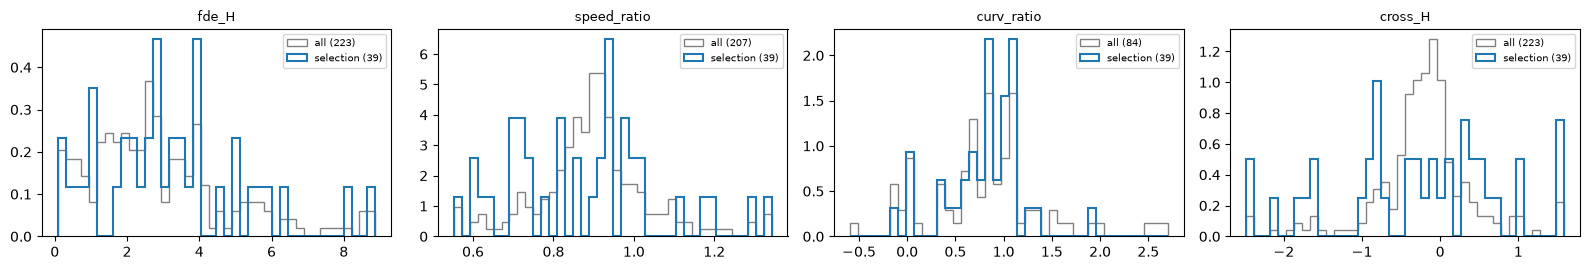

to look at, one per scene: show('<id>')
kitscenes/val/3cd1a6eb-e020-f12a-c1e9-457a883fb969/130
kitscenes/val/8c501afb-5a9b-e881-1c7d-99c21f39b1cc/40
kitscenes/val/bb2f22e1-82e1-2aaa-6837-a91792df0dc1/130
kitscenes/val/6848358c-4147-804f-def6-628b1b8bf75f/40
kitscenes/overlap_train_val/873eebf4-448a-cf6e-7d5e-2dc1cd010723/130
kitscenes/val/be5138b4-7c33-c308-455a-4a685e4190d8/40


In [21]:
COND = dict(cmd=["left", "right"])  # any tag column: a value or a list of values
WHERE = ""  # optional pandas query, e.g. "abs(pred_dpsi_full_deg) < @turn_pred_deg"
profile(where=WHERE or None, **COND)

In [22]:
RANGES = ("ref_speed", "speed_ratio", "v0_ratio", "curv_ratio", "fde_H", "cross_H", "z_H", "op_cam_h")


def explore(df=None):
    """profile() behind widgets: tag multi-selects, range sliders and a query box. Prints the COND and WHERE to paste."""
    if _no_widgets("set COND and WHERE and call profile(...)"):
        return
    df = T if df is None else df
    tab, pickers, conds = _condition_widgets(df)
    sliders = {}
    for c in RANGES:
        x = df[c].astype(float)
        x = x[np.isfinite(x)]
        if len(x):
            lo, hi = float(x.quantile(0.005)), float(x.quantile(0.995))
            sliders[c] = W.FloatRangeSlider(
                value=(lo, hi),
                min=lo,
                max=hi,
                step=(hi - lo) / 200 or 0.01,
                description=c,
                continuous_update=False,
                readout_format=".2f",
                layout=W.Layout(width="520px"),
                style={"description_width": "90px"},
            )
    query = W.Text(
        placeholder="extra pandas query, e.g. op_lead_prob > 0.5",
        description="where",
        continuous_update=False,
        layout=W.Layout(width="720px"),
    )
    button = W.Button(description="show 3 matches")
    out, shown = W.HTML(), W.HTML()

    def _where():
        # a slider applies only on a side that was moved off its end
        parts = []
        for c, s in sliders.items():
            lo, hi = s.value
            if lo > s.min:
                parts.append(f"{c} >= {lo:.4g}")
            if hi < s.max:
                parts.append(f"{c} <= {hi:.4g}")
        if query.value.strip():
            parts.append(f"({query.value.strip()})")
        return " and ".join(parts)

    def summary():
        c, w = conds(), _where()
        print(f"COND = {c!r}\nWHERE = {w!r}")
        profile(where=w or None, df=df, **c)

    def three():
        for sid in _picks(select(_where() or None, df, **conds()), 3):
            show(sid, df=df)

    def refresh(*_):
        out.value = _as_html(summary)

    def show_some(_):
        shown.value = _as_html(three)

    for w in (*pickers.values(), *sliders.values(), query):
        w.observe(refresh, "value")
    button.on_click(show_some)
    refresh()
    display(W.VBox([tab, *sliders.values(), query, button, out, shown]))


explore()

widgets are off (WIDGETS in §1): set COND and WHERE and call profile(...)


## 12 Failure modes, the route against the plan, and strengths

`modes(where=, intent=False, **conds)`: for every failure mode, how many keyframes and scenes it covers, its median severity, and the scenario, perception or context tag value it concentrates in most (the highest lift among values covering at least a tenth of its keyframes, leaving out the columns its own rule reads).

The intent modes are listed apart with `intent=True`: stops, lane changes and turns within the 4 s GT that the plan did not anticipate, and the route modes, which compare the plan's whole 10 s with the route: `turn_not_planned`, `turn_wrong_way`, `turns_off_route`, and the strength `takes_routed_turn`. The baseline is never told the route, so whatever it turns for, it read off the scene. §17 tells it, and compares. `route_vs_plan(turn_deg=)` is their base rate: the route against where the plan turns, as counts.

`strengths()` returns the tags file's named strengths, and the scenario clusters (as §9) with at least `min_scenes` scenes where the plan beats the overall median FDE at H without matching speed or curvature less often than overall. A one-scene `FOCUS` has none of those: pass `min_n=1, min_scenes=1`.

In [23]:
MODE_COLUMNS = ["mode", "group", "n", "pct", "scenes", "median_severity", "concentrates_in", "doc"]


def modes(where=None, df=None, intent=False, tags=None, **conds):
    """Every failure mode: n, share, scenes, median severity, where it concentrates, and its doc."""
    tags = tags or CFG
    sel = select(where, df, **conds)
    rows = []
    for name, spec in tags["failure_modes"].items():
        col = f"fm_{name}"
        if col not in sel or (spec.get("group") == "intent") != intent:
            continue
        hit = sel[sel[col]]
        top = (
            lift(hit, sel, exclude=_names(spec["when"]), top=1, min_n=max(3, len(hit) // 10))
            if len(hit)
            else pd.DataFrame()
        )
        rows.append(
            {
                "mode": name,
                "group": spec.get("group", ""),
                "n": len(hit),
                "pct": 100 * len(hit) / max(len(sel), 1),
                "scenes": hit.scene.nunique(),
                "median_severity": hit[f"sev_{name}"].median() if len(hit) else np.nan,
                "concentrates_in": ""
                if top.empty
                else f"{top.tag.iat[0]}={top.value.iat[0]} (x{top.lift.iat[0]:.1f})",
                "doc": spec["doc"],
            }
        )
    return (
        pd.DataFrame(rows, columns=MODE_COLUMNS).set_index("mode").sort_values("n", ascending=False).round(2)
    )


def strengths(
    by=("gt_lat", "gt_long", "speed_band"), min_n=5, min_scenes=3, where=None, df=None, tags=None, **conds
):
    """(named, found): the tags file's named strengths, and clusters where the plan does better than overall."""
    tags = tags or CFG
    sel = select(where, df, **conds)
    named = (
        pd.DataFrame(
            [
                {
                    "strength": name,
                    "n": int(sel[f"st_{name}"].sum()),
                    "pct": 100 * sel[f"st_{name}"].mean(),
                    "scenes": sel.loc[sel[f"st_{name}"], "scene"].nunique(),
                    "doc": spec["doc"],
                }
                for name, spec in tags["strengths"].items()
                if f"st_{name}" in sel
            ],
            columns=["strength", "n", "pct", "scenes", "doc"],
        )
        .set_index("strength")
        .round(2)
    )
    c = clusters(by, min_n, where=where, df=df, **conds)
    speed0, curv0 = 100 * _matched(sel.speed_ratio_bin).mean(), 100 * _matched(sel.curv_ratio_bin).mean()
    ok = (c.scenes >= min_scenes) & (c.fde_H_median < sel.fde_H.median())
    ok &= ~(c.speed_matched_pct < speed0) & ~(c.curv_matched_pct < curv0)  # NaN (undefined) passes
    return named, c[ok]


def _route_given(run=None):
    """What a run (RUN_ID's by default) did with the route: sent it as a desire (§17's arm), or nothing."""
    run = RUN.run if run is None else run
    desire = ((run.get("provenance") or {}).get("policy") or {}).get("desire_mode", "off")
    sent = (run.get("config") or {}).get("command_source") == "gt" and desire != "off"
    return f"sent to the model as a {desire} desire" if sent else "never given to the model"


def route_vs_plan(turn_deg=None, where=None, df=None, **conds):
    """The route (cmd, rows) against where the plan turns over 10 s (columns), as counts. The model gets the
    route only in a run that sends it as a desire (§17)."""
    sel = select(where, df, **conds)
    t = P["turn_pred_deg"] if turn_deg is None else turn_deg
    d = sel.pred_dpsi_full_deg
    plan = np.select([d >= t, d <= -t, d.notna()], ["left", "right", "straight"], "na")
    return pd.crosstab(
        sel.cmd, pd.Series(plan, index=sel.index, name=f"plan turns (|dpsi| >= {t:g} deg)"), margins=True
    )


with pd.option_context("display.max_colwidth", 80):
    display(modes())
    display(modes(intent=True))
print(f"the route (rows, {_route_given()}) against where the plan turns over its 10 s (columns)")
display(route_vs_plan())
named, found = strengths()
display(named)
print(
    f"clusters that beat the overall median FDE@H ({T.fde_H.median():.2f} m) without matching speed or curvature less often:"
)
display(found)

,group,n,pct,scenes,median_severity,concentrates_in,doc
mode,,,,,,,
ego_speed_misread,perception,201,90.13,133,0.14,start_speed=slow (x1.1),pose-head speed off the reference by more than speed_read_tol
too_slow_cruise,long,101,45.29,77,0.12,lanes=weak (x1.3),GT holds speed while moving; the plan covers less than ratio_slow of its dis...
understeer,lat,23,10.31,21,0.57,gt_turn_I=turn_L (x4.4),GT curves; the plan turns under curv_under of the GT heading change
under_accelerates,long,17,7.62,17,0.35,cmd=left (x3.1),GT accelerates; the plan holds speed or slows
under_brakes,long,16,7.17,16,0.52,history=full (x1.7),GT brakes or stops; the plan holds speed or speeds up
phantom_brake,long,16,7.17,16,0.32,gt_turn_I=turn_R (x6.0),GT holds speed or accelerates; the plan brakes or stops
too_fast_cruise,long,14,6.28,12,0.15,start_speed=fast (x9.1),GT holds speed while moving; the plan covers more than ratio_fast of its dis...
yaw_misread,perception,12,5.38,11,0.03,gt_turn_I=turn_L (x6.8),pose-head yaw rate off the reference by yaw_bias_tol or more
oversteer,lat,11,4.93,10,0.67,gt_lat=sharp_L (x3.8),GT curves; the plan turns over curv_over of the GT heading change


,group,n,pct,scenes,median_severity,concentrates_in,doc
mode,,,,,,,
turns_off_route,intent,7,3.14,7,59.03,gt_lat=curve_L (x2.7),the route goes straight on (the command and the navigation text both say so)...
turn_not_planned,intent,4,1.79,4,22.95,ego_turning=turning (x3.0),the route commands a turn; the plan's whole 10 s turns under turn_pred_deg e...
turn_unanticipated,intent,4,1.79,4,57.30,gt_lat=turn_L (x15.9),GT turns within intent_horizon_s; over the same time the plan turns under tu...
turn_wrong_way,intent,4,1.79,4,62.24,gt_turn_I=turn_L (x15.2),the route commands a turn one way; the plan turns turn_pred_deg or more the ...
lane_change_unanticipated,intent,2,0.90,2,2.73,,GT changes lane within intent_horizon_s; over the same time the plan shifts ...


the route (rows, never given to the model) against where the plan turns over its 10 s (columns)


plan turns (|dpsi| >= 15 deg),left,na,right,straight,All
cmd,,,,,
left,15,0,4,2,21
right,0,0,16,2,18
straight,11,4,26,143,184
All,26,4,46,147,223


,n,pct,scenes,doc
strength,,,,
holds_speed,18,8.07,15,GT holds speed; the plan covers the same dista...
holds_curve,20,8.97,20,GT curves; the plan's heading change matches a...
launches_with_gt,1,0.45,1,GT pulls away from a stop and so does the plan
stops_with_gt,2,0.90,2,GT stops or stands and so does the plan
takes_routed_turn,31,13.90,27,the route commands a turn and the plan turns t...


clusters that beat the overall median FDE@H (2.58 m) without matching speed or curvature less often:


n  scenes  fde_H_median  fde_H_p90  \
gt_lat   gt_long speed_band                                        
curve_L  cruise  low         21      19          2.56       4.73   
curve_R  cruise  low         18      17          2.20       5.59   
straight brake   low         18      18          1.95       4.49   
         accel   low         12      12          1.92       5.29   

                             speed_matched_pct  curv_matched_pct   pred_long  \
gt_lat   gt_long speed_band                                                    
curve_L  cruise  low                     15.00             66.67  cruise 90%   
curve_R  cruise  low                     22.22             77.78  cruise 89%   
straight brake   low                     22.22               NaN   brake 56%   
         accel   low                     18.18               NaN   accel 67%   

                                 pred_lat                top_mode  
gt_lat   gt_long speed_band                                        
curve_L  cruise  low          curve_L 71%   ego_speed_misread 86%  
curve_R  cruise  low          curve_R 72%   ego_speed_misread 83%  
straight brake   low         straight 67%   ego_speed_misread 89%  
         accel   low         straight 75%  ego_speed_misread 100%

## 13 Keyframes

`show(key)` draws one keyframe; `key` is a sample id or a row label of `T`. Four panels:

1. **Camera.** The front camera at half size, with the GT (blue), the plan (model colour) and the model's ego lane lines (light grey) projected through the harness's calibration at the `PROJECT_HEIGHT` camera height (named in the panel title). It assumes flat ground, and the plan's origin may sit at the camera rather than the rig, so judge shape and side more than the last decimetre.
2. **BEV** over 10 s: the GT (up to 4 s), the plan, the points at H circled, the model's lane lines (grey, ego lane darker), road edges (dashed), and the model's lead (square, if prob ≥ `lead_prob`).
3. **Speed** of GT and plan per 0.5 s step, with the pose speed the harness gave the model and the pose-head speed at t = 0.
4. **Tags**: the route, the history, the scale the model read, every class, the ratios and errors, the context, and the failure modes and strengths that fired.

`sheet(mode, n_typical=2, n_worst=1, n_random=1)` draws a failure mode's (or strength's) most severe keyframe, the most typical ones (nearest its median severity) and random ones, at most one per scene. `control()` draws random keyframes whatever their tags, to see what normal looks like. `browse()` steps through a mode's keyframes, most severe first, with `WIDGETS = True` (§1).

In [24]:
def frame(i, df=None):
    """The front camera at row i's keyframe, decoded at half size (JPEG draft mode), and that scale."""
    r = (T if df is None else df).loc[i]
    front = _scene_data(r.split_dir, r.scene_id, GROUND)[3]
    if front is None:
        raise FileNotFoundError(f"scene {r.scene} has no {FRONT} under any of this site's {BENCH} tiers")
    img = Image.open(L.frame_path(front, int(r.keyframe), FRONT))
    full = img.width
    img.draft("RGB", (full // 2, img.height // 2))
    img = img.convert("RGB")
    return img, img.width / full


def _project(xy, K, E):
    """(k, 2) ego-frame road points (z = 0) to pixels, dropping points less than 0.5 m in front of the camera."""
    xy = np.asarray(xy, dtype=float)
    xy = xy[np.isfinite(xy).all(1)]
    pts = np.c_[xy, np.zeros(len(xy)), np.ones(len(xy))] @ np.linalg.inv(E).T
    pts = pts[pts[:, 2] > 0.5, :3]
    uv = pts @ K.T
    return uv[:, :2] / uv[:, 2:]


def _height(r, height=None):
    """(metres or None, label): the front camera's height used for projecting (PROJECT_HEIGHT)."""
    h = PROJECT_HEIGHT if height is None else height
    if h == "context":
        mined = r.get("ctx_height_ring_front_m", np.nan)
        return (float(mined), "mined") if pd.notna(mined) else (None, "harness (no mined height)")
    if h == "harness":
        return None, "harness"
    return float(h), "set"


def camera_panel(i, df=None, height=None):
    """(image, label): the front camera with the ego lane lines, the GT and the plan projected onto the road."""
    r = (T if df is None else df).loc[i]
    img, s = frame(i, df)
    _, K, E, _ = _scene_data(r.split_dir, r.scene_id, GROUND)
    K, E = np.diag([s, s, 1.0]) @ np.asarray(K, dtype=float)[:3, :3], np.array(E, dtype=float)
    h, how = _height(r, height)
    if h is not None:
        E[2, 3] = h
    pen = ImageDraw.Draw(img)
    for line in LANES[i, 1:3]:
        uv = _project(line[line[:, 0] <= 60], K, E)
        if len(uv) >= 2:
            pen.line([tuple(p) for p in uv], fill="#dddddd", width=2)
    for xy, color, width in ((GT_RAW[i], palette.GROUND_TRUTH, 3), (PRED[i], palette.color(MODEL), 4)):
        uv = _project(xy, K, E)
        if len(uv) >= 2:
            pen.line([tuple(p) for p in uv], fill=color, width=width)
            for u, v in uv:
                pen.ellipse([u - width, v - width, u + width, v + width], fill=color)
    return img, f"camera at {E[2, 3]:.2f} m ({how})"


def _tag_text(r, h, df):
    groups = tag_columns(df)
    lines = [
        f"route ({_route_given()}): {r.cmd}, {r.nav_text!r}; the plan turns {r.pred_dpsi_full_deg:+.1f} deg over 10 s",
        f"history: {r.model_ticks} of the {r.warmup_frames} ticks its queue needs ({r.history})",
        f"scale: pose-head speed {r.op_v:.2f} vs the poses' {r.ref_speed:.2f} m/s; camera height believed {r.op_cam_h:.2f} vs mined {r.get('ctx_height_ring_front_m', np.nan):.2f} m",
    ]
    lines += [
        f"{g}: " + ", ".join(f"{c}={r[c]}" for c in cols)
        for g, cols in groups.items()
        if g in ("scenario", "intent", "perception", "response")
    ]
    lines.append(
        f"speed_ratio {r.speed_ratio:.2f}  v0_ratio {r.v0_ratio:.2f}  curv_ratio {r.curv_ratio:.2f}  accel GT {r.gt_accel:+.2f} plan {r.pred_accel:+.2f} m/s²  "
        f"dpsi GT {r.gt_dpsi_deg:+.1f} plan {r.pred_dpsi_deg:+.1f} deg"
    )
    lines.append(
        f"FDE@{h:g}s {r.fde_H:.2f} m (recorded FDE@3s {r.rec_fde_3s:.2f})  cross {r.cross_H:+.2f} m  z {r.z_H:.1f}"
    )
    if r.pred_comfort_broken_H:
        lines.append(
            f"plan breaks over H: {r.pred_comfort_broken_H} (worst peak {r.pred_comfort_excess_H:.1f}x its bound)"
        )
    ctx = [
        f"{c[4:]}={r[c]}"
        for c in groups.get("context", [])
        if pd.notna(r[c]) and r[c] is not False and r[c] != 0
    ]
    if ctx:
        lines.append("context: " + ", ".join(ctx))
    lines.append(
        "FAILURE MODES: " + (", ".join(c[3:] for c in r.index if c.startswith("fm_") and r[c]) or "none")
    )
    lines.append(
        "strengths: " + (", ".join(c[3:] for c in r.index if c.startswith("st_") and r[c]) or "none")
    )
    return "\n".join(textwrap.fill(line, 64, subsequent_indent="    ") for line in lines)


def _show_photo(fig, quality=80):
    """Display a figure as JPEG. Its camera panel is a photo, which PNG stores several times larger,
    and these figures are most of what the committed outputs weigh."""
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", bbox_inches="tight", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(
        {"image/jpeg": base64.b64encode(buf.getvalue()).decode(), "text/plain": "<keyframe figure>"}, raw=True
    )


def show(key, params=None, camera=True, df=None, title=None, height=None):
    """One keyframe: camera, BEV, speed profile and its tags. key: a sample id or a row label of T."""
    df = T if df is None else df
    p = params or P
    i = _row(key, df)
    r = df.loc[i]
    h = p["horizon_s"]
    nH = round(h / DT)
    gt = GT_RAW[i]
    fig = plt.figure(figsize=(19, 7.8))
    grid = fig.add_gridspec(2, 3, width_ratios=[2.3, 1, 1.5], height_ratios=[1, 1.25])
    ax_cam, ax_bev = fig.add_subplot(grid[:, 0]), fig.add_subplot(grid[:, 1])
    ax_v, ax_txt = fig.add_subplot(grid[0, 2]), fig.add_subplot(grid[1, 2])

    ax_cam.axis("off")
    if camera:
        try:
            img, label = camera_panel(i, df, height)
            ax_cam.imshow(img)
            ax_cam.set_title(label, fontsize=9)
        except Exception as e:  # no dataset on this machine: say so and draw the rest
            ax_cam.text(
                0.5,
                0.5,
                textwrap.fill(f"no camera: {type(e).__name__}: {e}", 60),
                ha="center",
                va="center",
                transform=ax_cam.transAxes,
            )

    far = np.nanmax(np.r_[gt[:, 0], PRED[i, :, 0]]) + 10
    for k, line in enumerate(LANES[i]):
        keep = line[:, 0] <= far
        ax_bev.plot(line[keep, 1], line[keep, 0], color="grey", lw=1.3 if k in (1, 2) else 0.6)
    for line in EDGES[i]:
        keep = line[:, 0] <= far
        ax_bev.plot(line[keep, 1], line[keep, 0], "--", color="grey", lw=0.8)
    bev.draw(ax_bev, {MODEL: PRED[i]}, ground_truth=gt[np.isfinite(gt[:, 0])])
    if np.isfinite(gt[nH - 1, 0]):
        ax_bev.plot(gt[nH - 1, 1], gt[nH - 1, 0], "o", mfc="none", color=palette.GROUND_TRUTH, ms=10)
    ax_bev.plot(
        PRED[i, nH - 1, 1],
        PRED[i, nH - 1, 0],
        "o",
        mfc="none",
        color=palette.color(MODEL),
        ms=10,
        label=f"at H = {h:g} s",
    )
    if r.op_lead_prob >= p["lead_prob"]:
        ax_bev.plot(
            r.op_lead_y,
            r.op_lead_d,
            "s",
            mfc="none",
            color=palette.color(MODEL),
            ms=9,
            label=f"model lead (p {r.op_lead_prob:.2f})",
        )
    lim = max(4.0, 1.2 * np.nanmax(np.abs(np.r_[gt[:, 1], PRED[i, :, 1]])))
    ax_bev.set_aspect("auto")
    ax_bev.set_xlim(lim, -lim)  # left positive on the left, as bev.draw
    ax_bev.legend(fontsize=7, loc="upper left")
    ax_bev.set_title("BEV", fontsize=9)

    t_mid = (np.arange(N_WP) + 0.5) * DT
    for xy, color, label in ((gt, palette.GROUND_TRUTH, "GT"), (PRED[i], palette.color(MODEL), MODEL)):
        v = np.linalg.norm(np.diff(np.vstack([[0.0, 0.0], xy]), axis=0), axis=1) / DT
        ax_v.plot(t_mid, v, ".-", color=color, label=label)
    ax_v.plot(0, r.ref_speed, "k>", ms=8, label="pose speed")
    ax_v.plot(0, r.op_v, "<", color=palette.color(MODEL), ms=8, label="pose-head speed")
    ax_v.axvline(h, color="grey", ls="--", lw=0.8)
    ax_v.set(xlabel="t (s)", ylabel="speed (m/s)")
    ax_v.grid(alpha=0.3)
    ax_v.legend(fontsize=7)

    ax_txt.axis("off")
    ax_txt.text(
        0, 1, _tag_text(r, h, df), va="top", family="monospace", fontsize=7.5, transform=ax_txt.transAxes
    )
    fig.suptitle(
        f"{title + ': ' if title else ''}{r.sample_id}   {r.split}, {r.ref_speed:.1f} m/s, route {r.cmd} ({r.nav_text})",
        fontsize=11,
    )
    fig.tight_layout()
    _show_photo(fig)


def sheet(mode, n_typical=2, n_worst=1, n_random=1, seed=None, df=None, draw=None, **kw):
    """A failure mode's (or strength's) worst, most typical and random keyframes, at most one per scene,
    each drawn by draw: show(), or §16's speed_profile()."""
    df = T if df is None else df
    col = mode if mode.startswith(("fm_", "st_")) else f"fm_{mode}" if f"fm_{mode}" in df else f"st_{mode}"
    sev = f"sev_{col[3:]}"
    hit = df[df[col]]
    print(f"{col}: {len(hit)} keyframes over {hit.scene.nunique()} scenes")
    if hit.empty:
        return []
    ranked = sev in hit
    if ranked:  # each scene's most severe keyframe stands for it
        hit = hit.sort_values(sev, ascending=False)
    hit = hit.drop_duplicates("scene")
    picks = [("worst", i) for i in hit.index[:n_worst]] if ranked else []
    if ranked and n_typical:
        rest = hit.drop([i for _, i in picks])
        picks += [
            ("typical", i) for i in (rest[sev] - rest[sev].median()).abs().sort_values().index[:n_typical]
        ]
    rest = hit.drop([i for _, i in picks])
    n_more = n_random + (0 if ranked else n_worst + n_typical)
    if n_more and len(rest):
        picks += [
            ("random", i)
            for i in rest.sample(min(n_more, len(rest)), random_state=SEED if seed is None else seed).index
        ]
    for why, i in picks[:MAX_RENDER]:
        if RENDER:
            (show if draw is None else draw)(
                i,
                df=df,
                title=f"{col[3:]}, {why}" + (f" (severity {df.at[i, sev]:.2f})" if ranked else ""),
                **kw,
            )
        else:
            print(f"  {why}: {df.at[i, 'sample_id']}")
    return [df.at[i, "sample_id"] for _, i in picks[:MAX_RENDER]]


def control(n=8, seed=None, df=None):
    """Random keyframes, one per scene, whatever their tags: what normal looks like."""
    df = T if df is None else df
    for sid in _picks(df, min(n, MAX_RENDER), seed):
        show(sid, df=df, title="control")


def browse(df=None):
    """A failure mode (or strength) dropdown and a rank slider: its keyframes, most severe first."""
    if _no_widgets("call sheet(...) or show(...)"):
        return
    df = T if df is None else df
    cols = [c for c in df.columns if c.startswith(("fm_", "st_")) and df[c].any()]
    if not cols:
        print("no failure mode or strength fired on the loaded keyframes")
        return
    pick = W.Dropdown(options=[(f"{c} ({int(df[c].sum())})", c) for c in cols], description="mode")
    rank = W.IntSlider(value=0, min=0, max=0, description="rank")
    out = W.HTML()

    def ranked():
        hit = df[df[pick.value]]
        sev = f"sev_{pick.value[3:]}"
        return hit.sort_values(sev, ascending=False) if sev in hit else hit

    def draw(*_):
        hit = ranked()
        k = min(rank.value, len(hit) - 1)
        out.value = _as_html(show, hit.index[k], df=df, title=f"{pick.value[3:]} #{k + 1} of {len(hit)}")

    def on_mode(*_):  # a new mode starts at rank 0 and draws once, not once per slider change
        rank.unobserve(draw, "value")
        rank.max, rank.value = len(ranked()) - 1, 0
        rank.observe(draw, "value")
        draw()

    rank.observe(draw, "value")
    pick.observe(on_mode, "value")
    on_mode()
    display(W.VBox([W.HBox([pick, rank]), out]))

fm_ego_speed_misread: 201 keyframes over 133 scenes


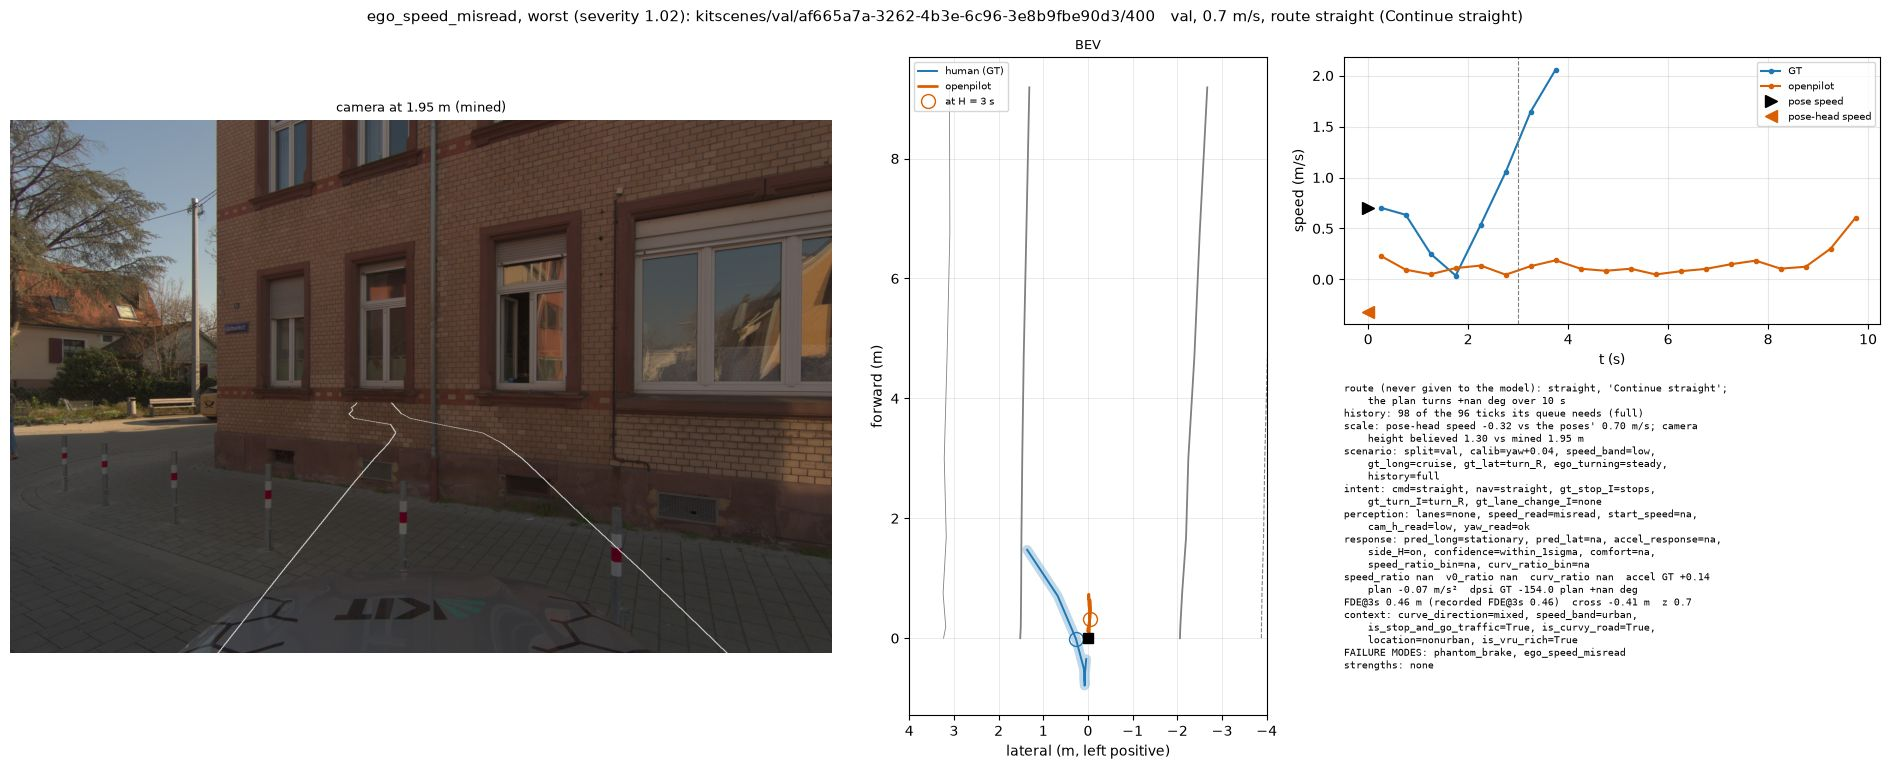

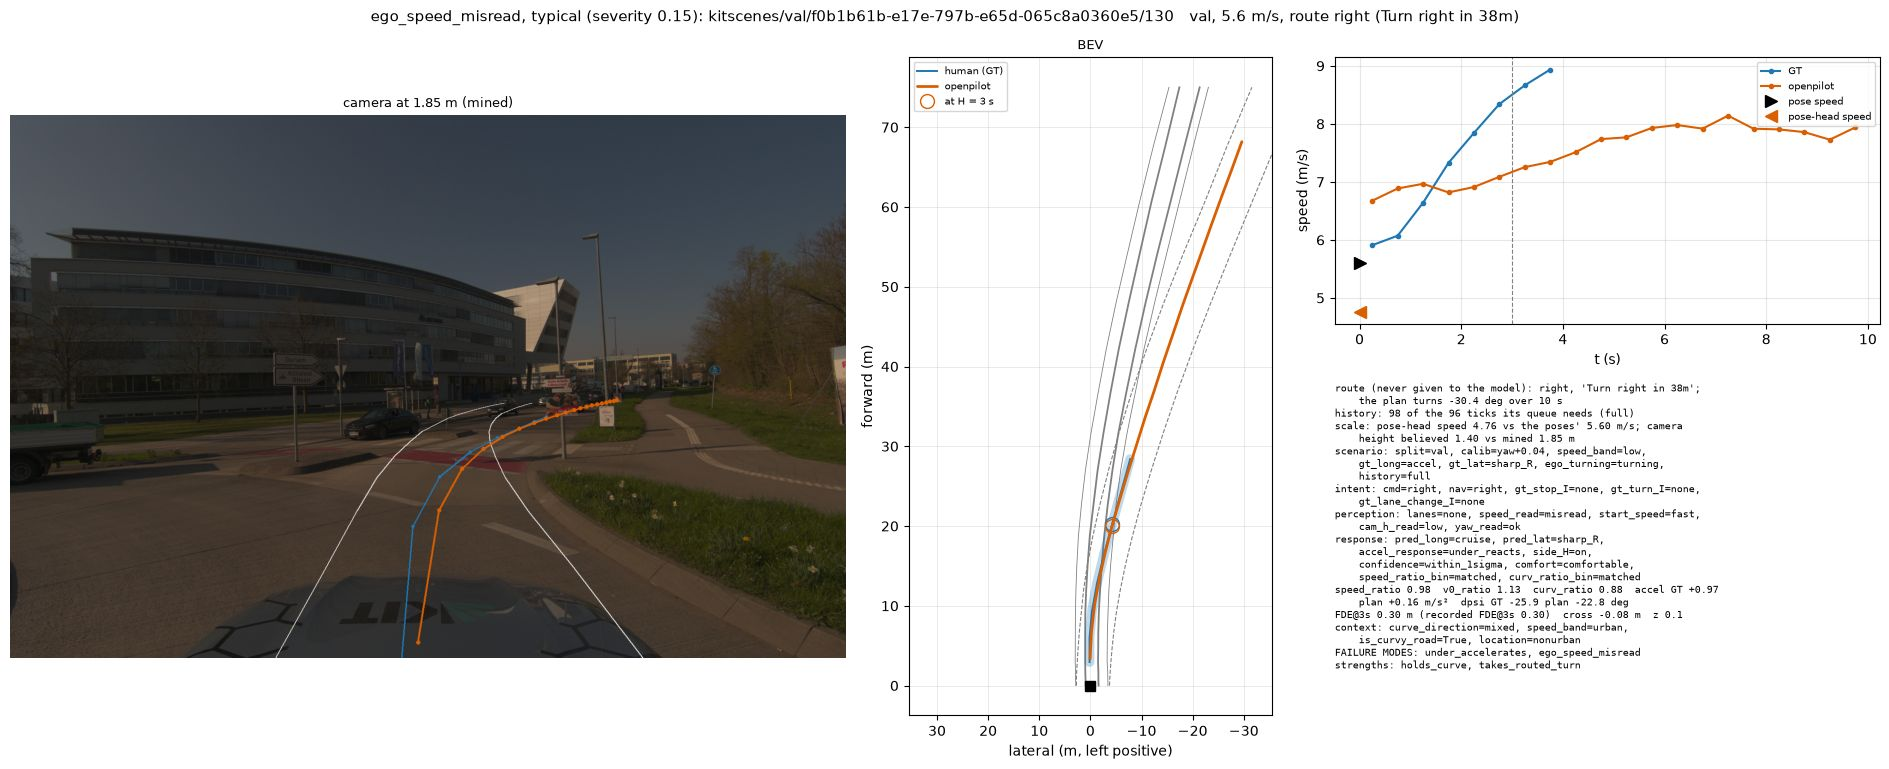

fm_too_slow_cruise: 101 keyframes over 77 scenes


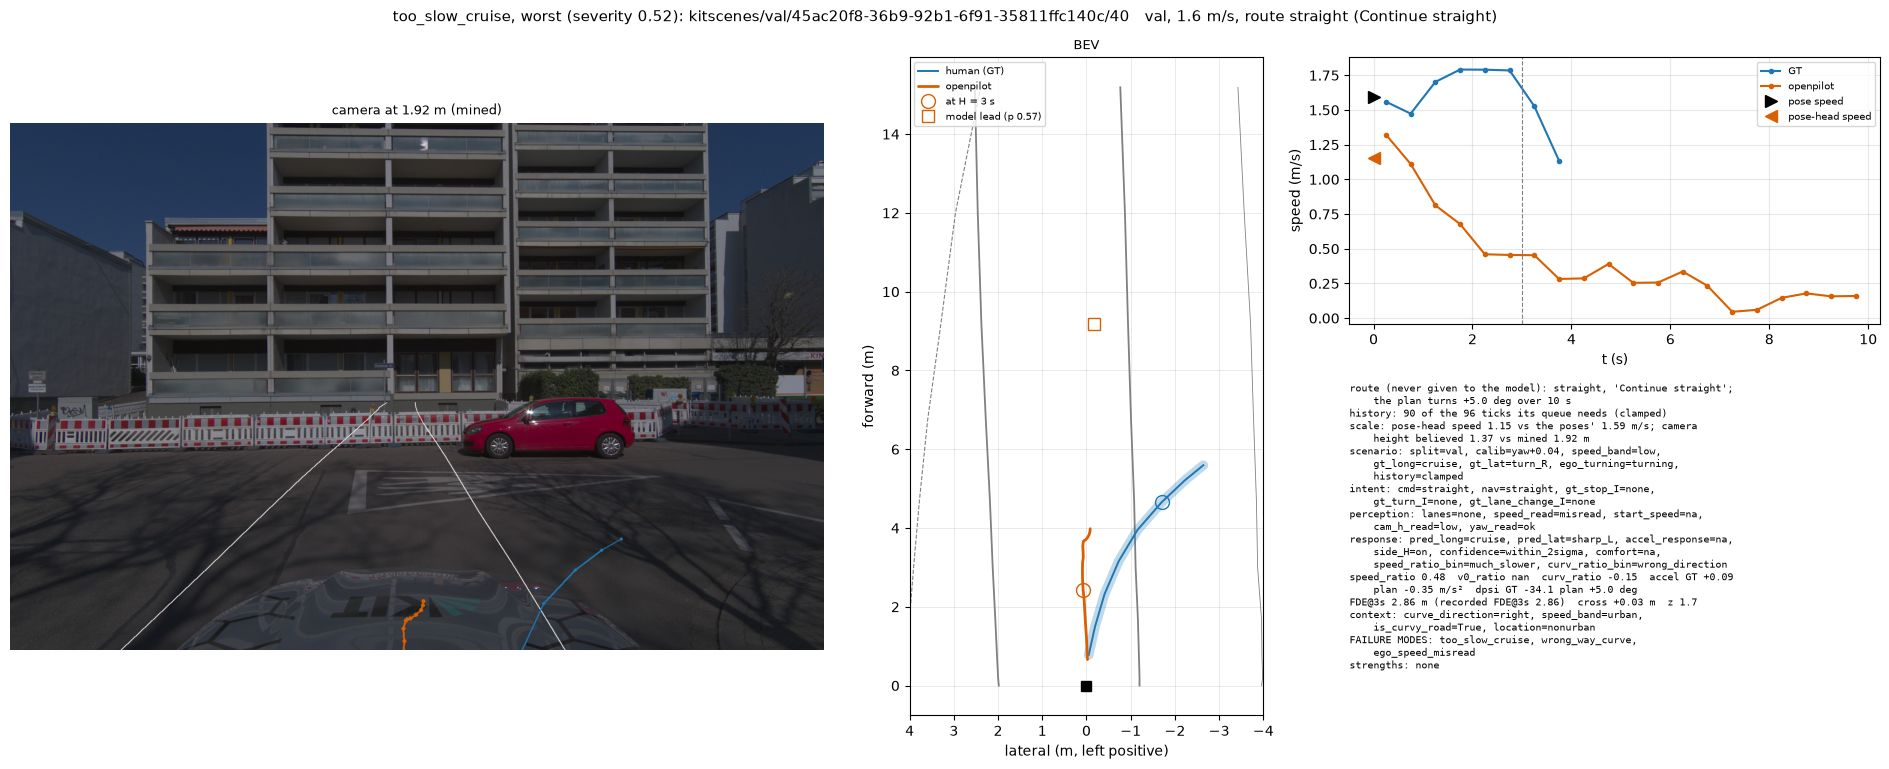

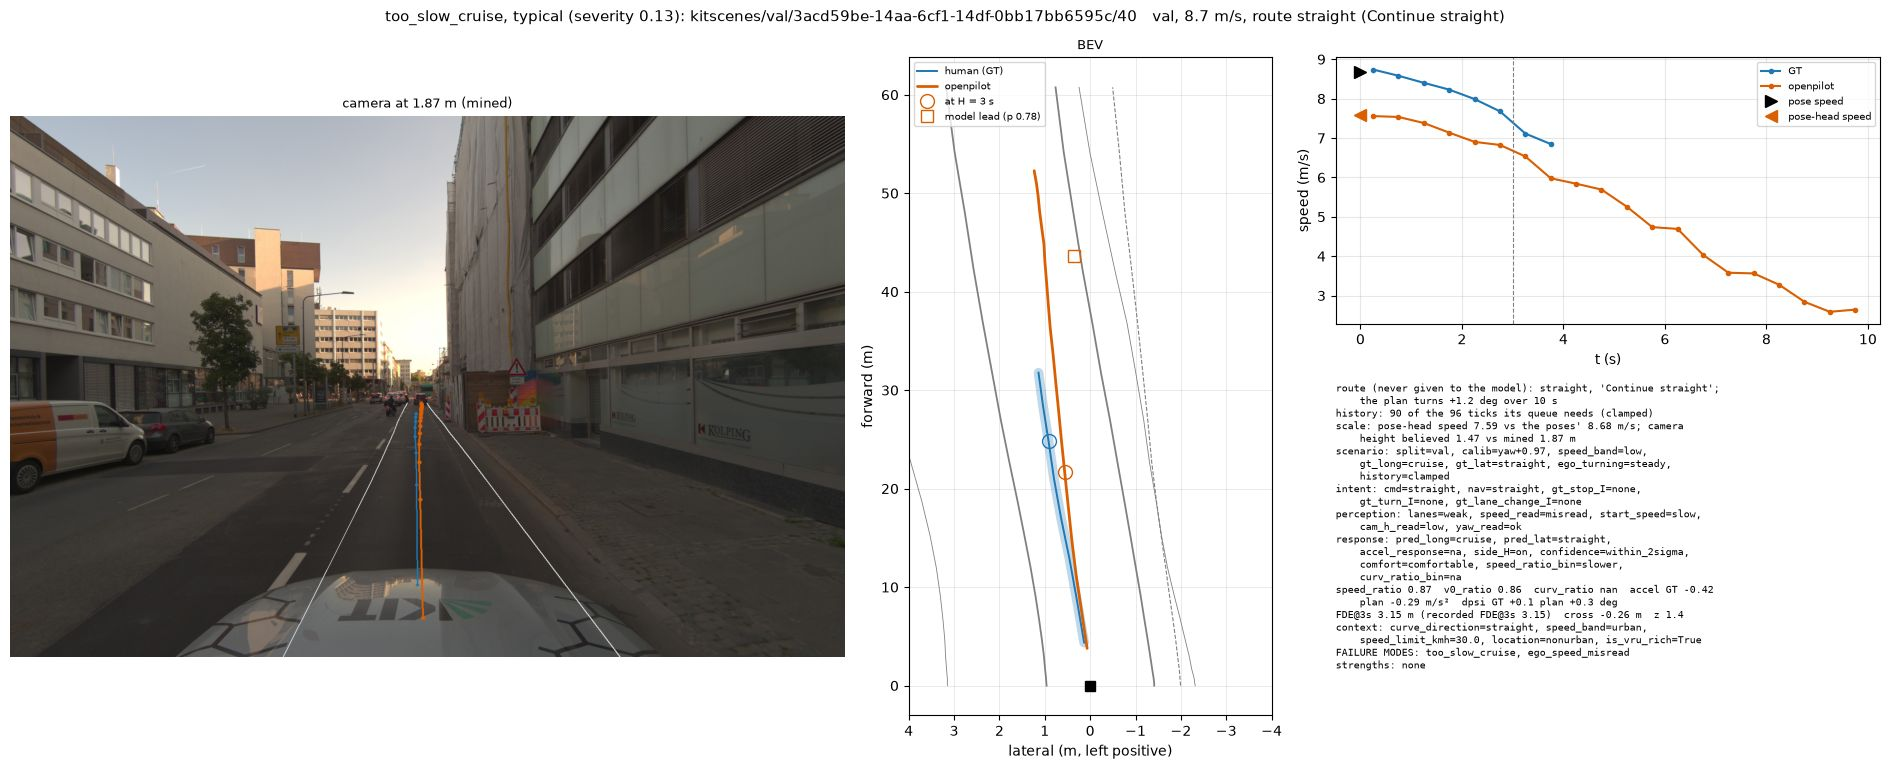

fm_understeer: 23 keyframes over 21 scenes


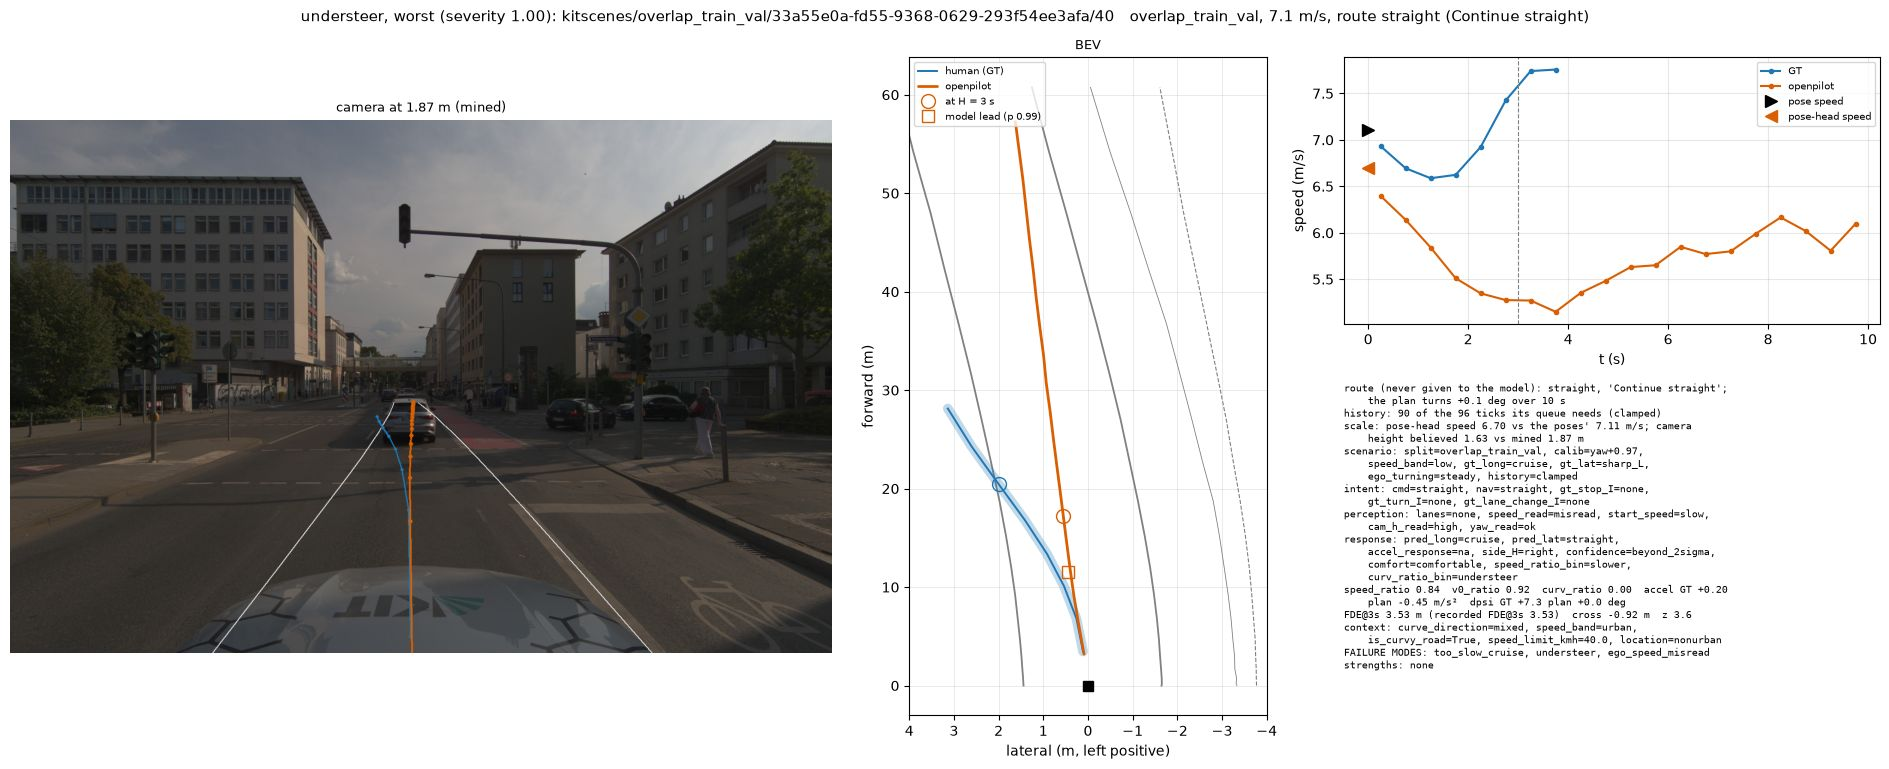

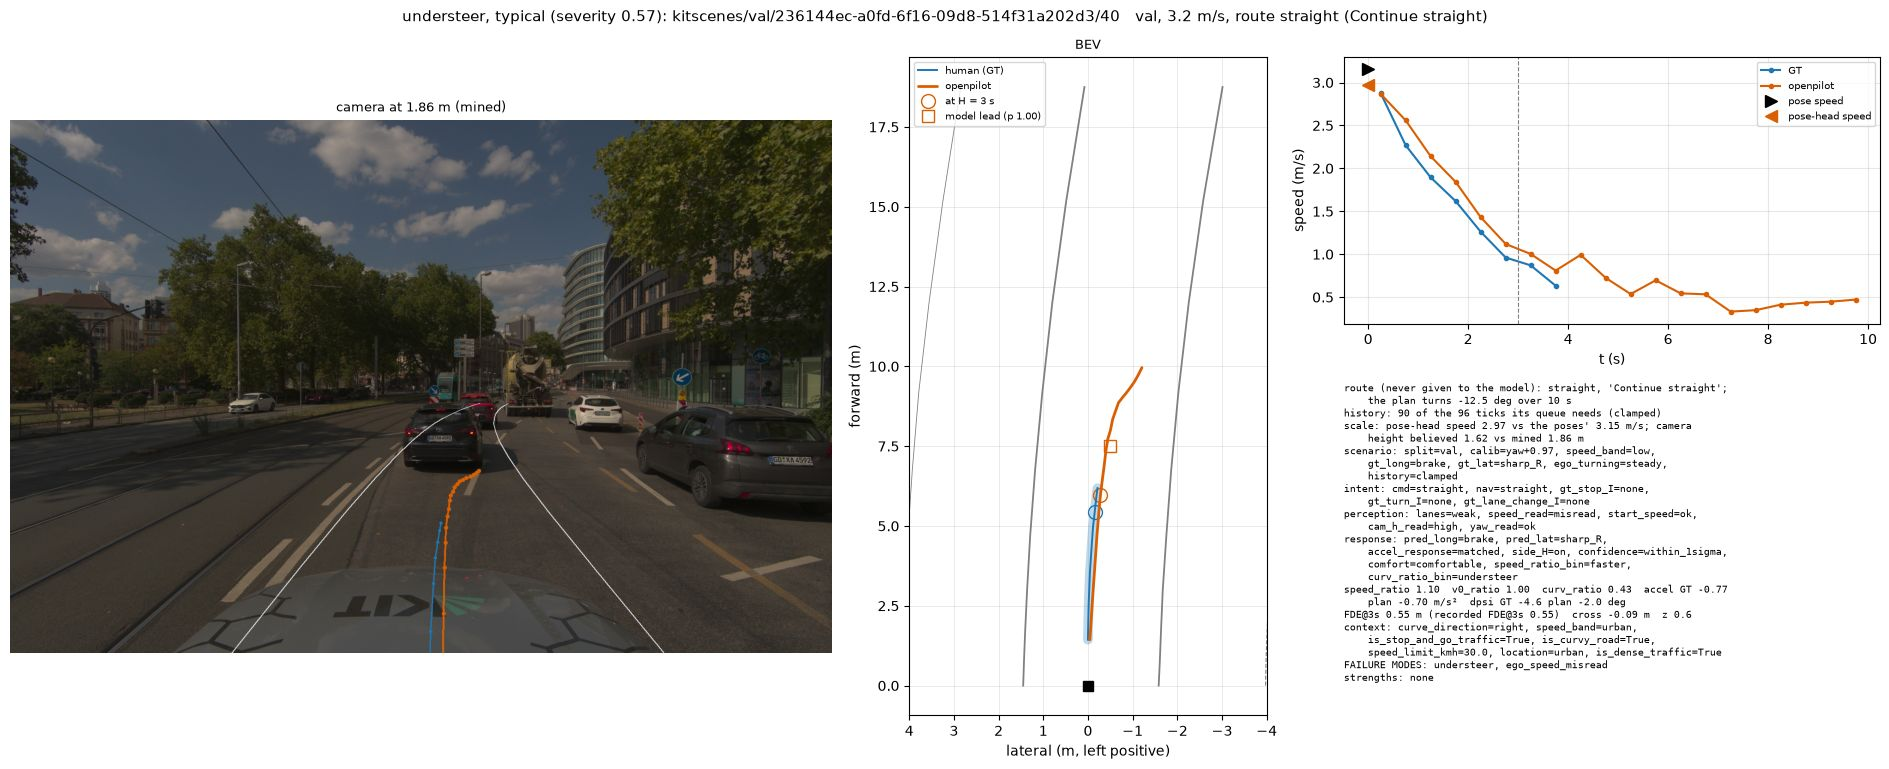

fm_under_accelerates: 17 keyframes over 17 scenes


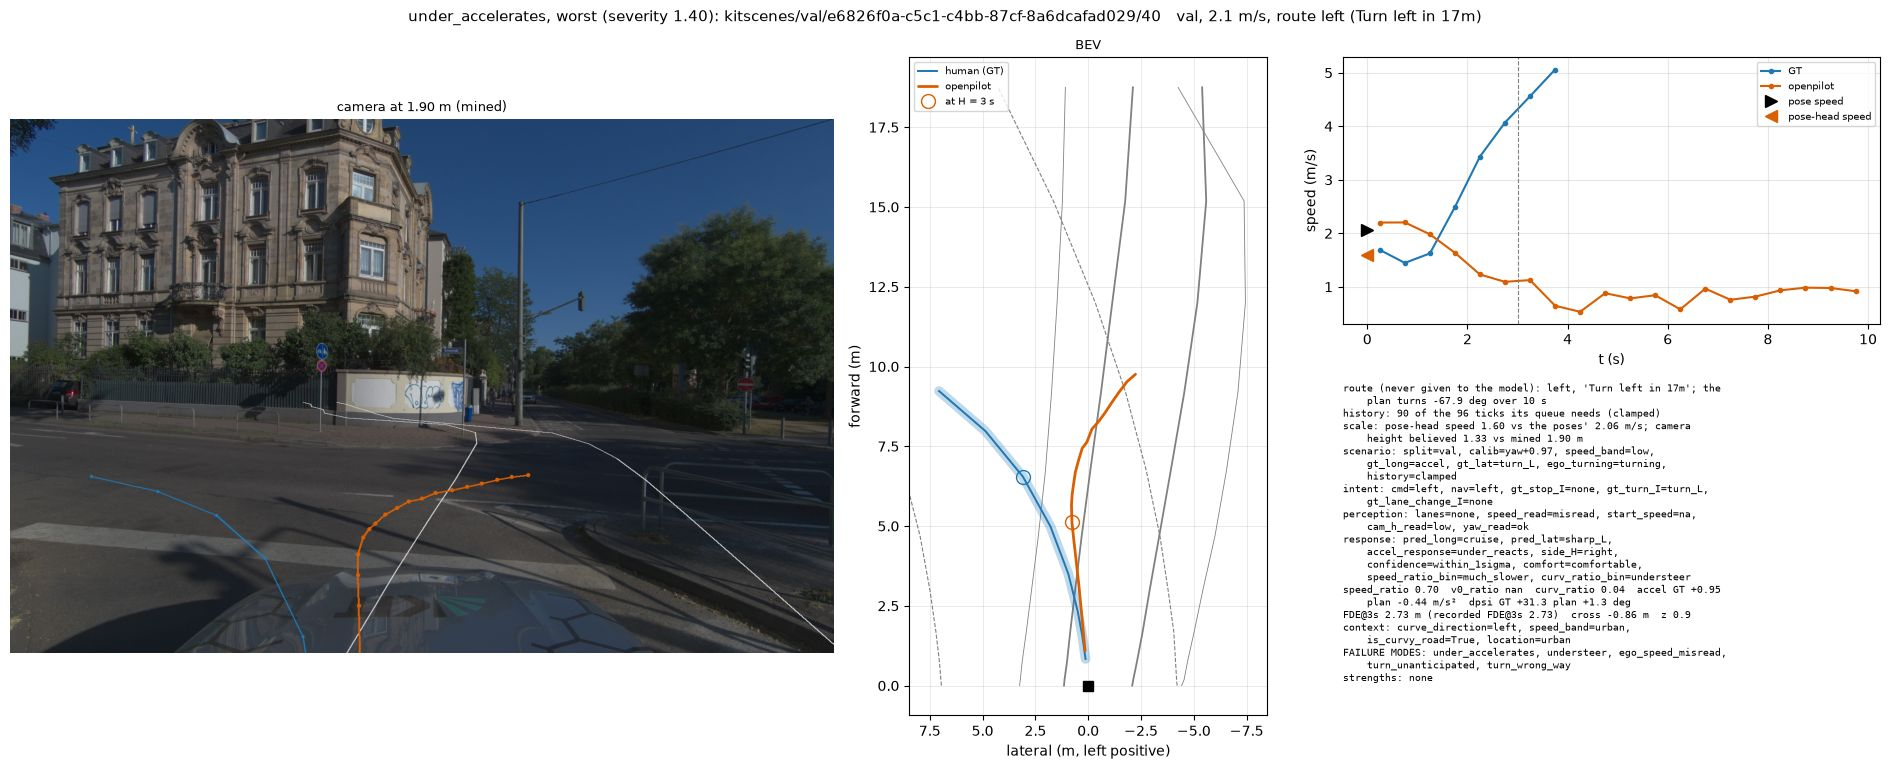

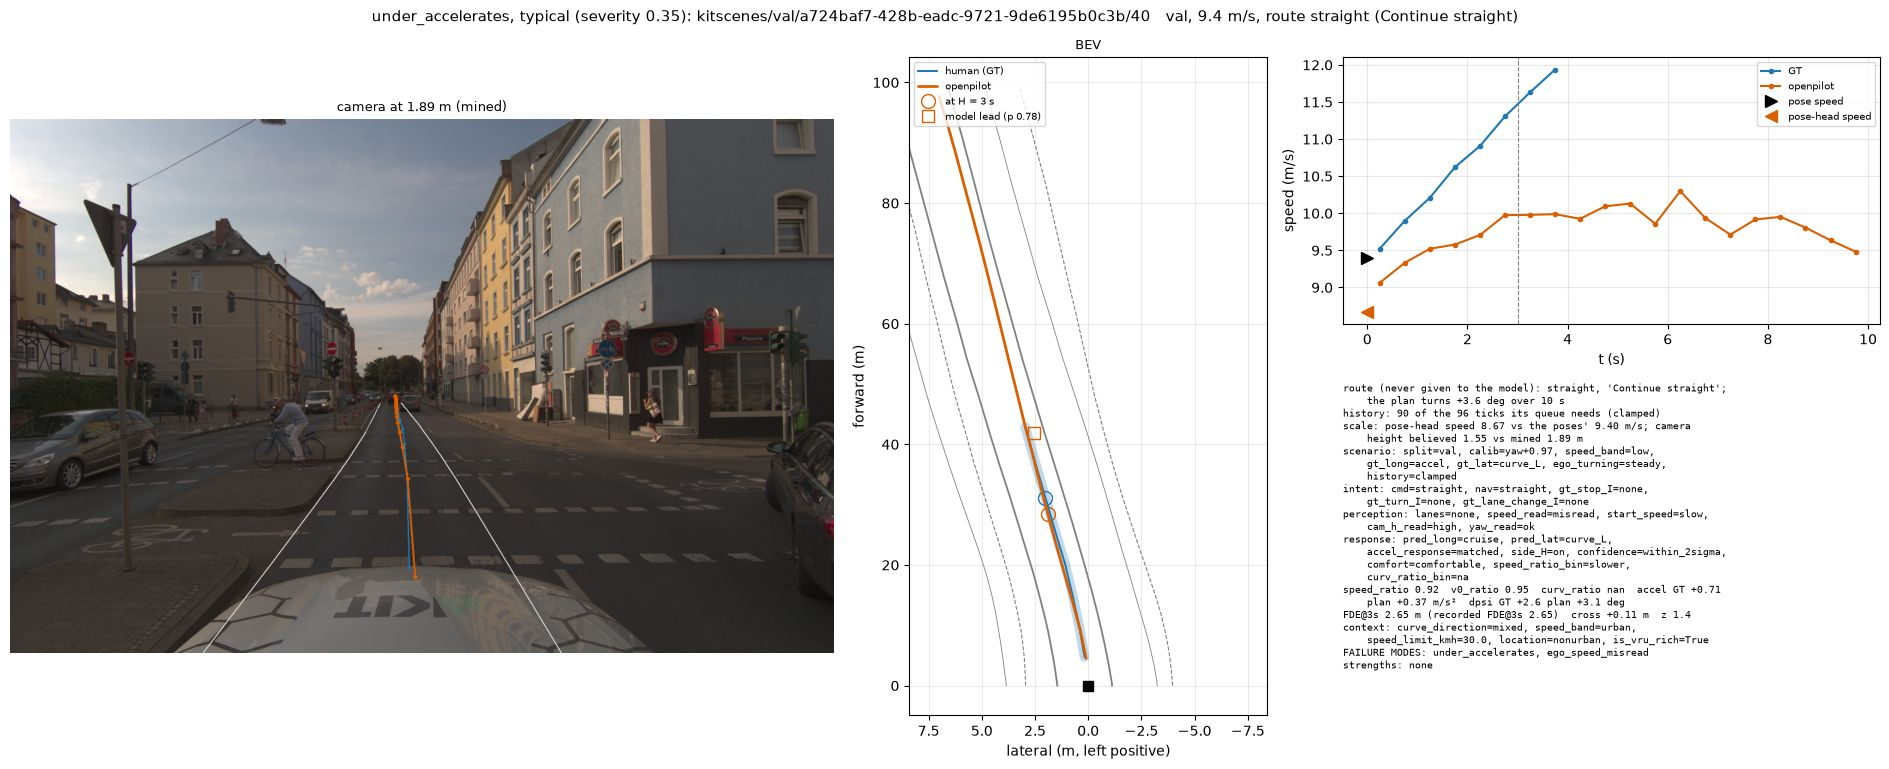

fm_under_brakes: 16 keyframes over 16 scenes


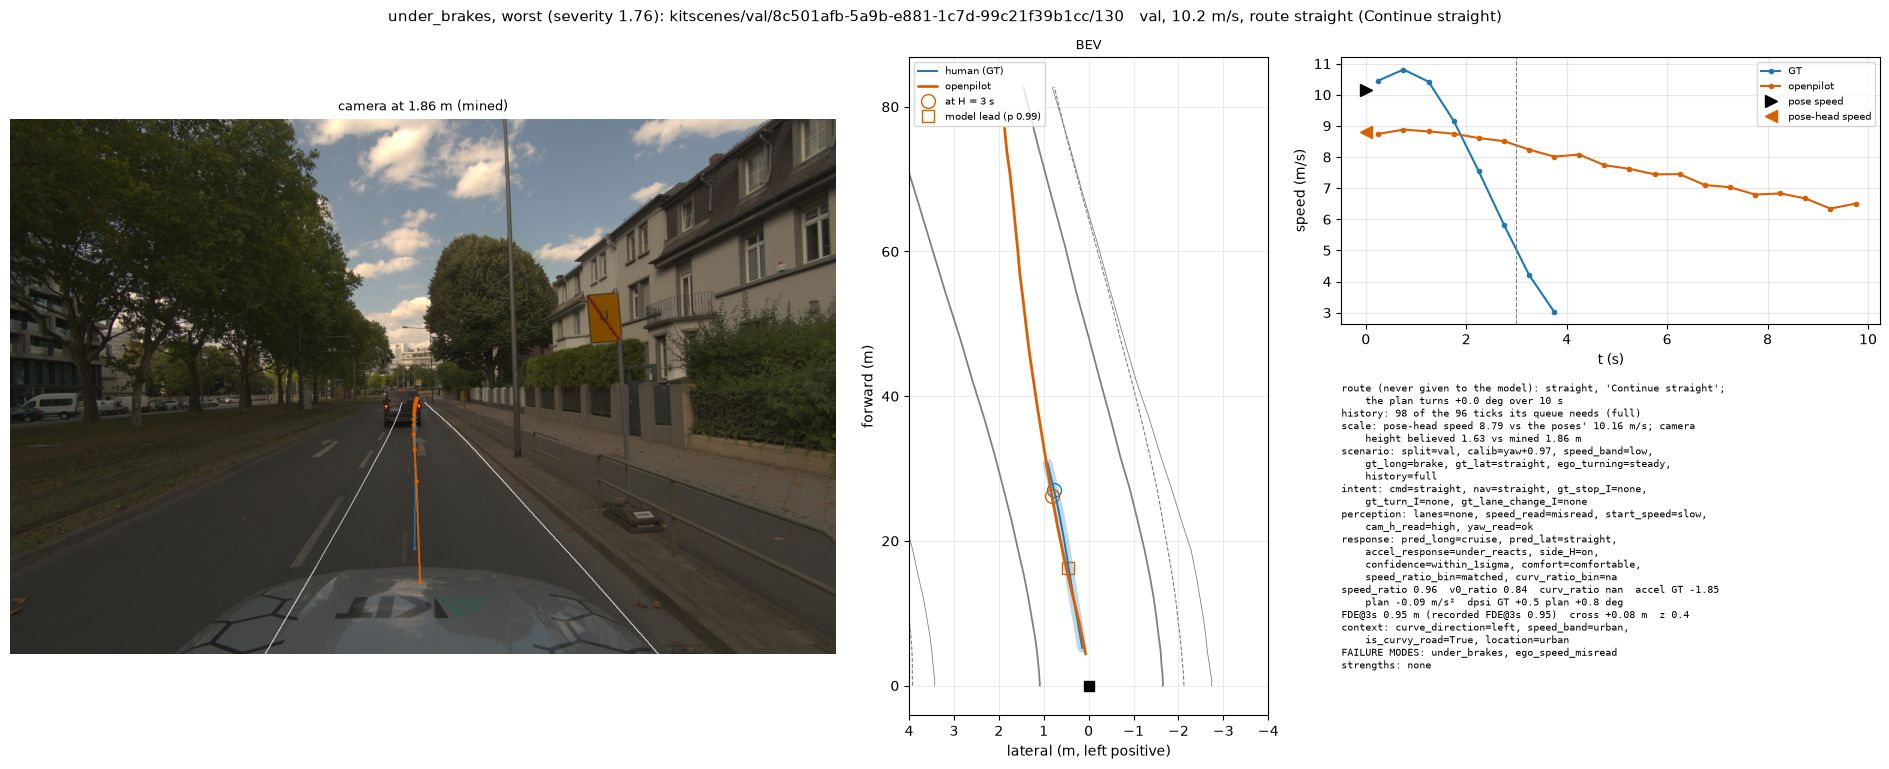

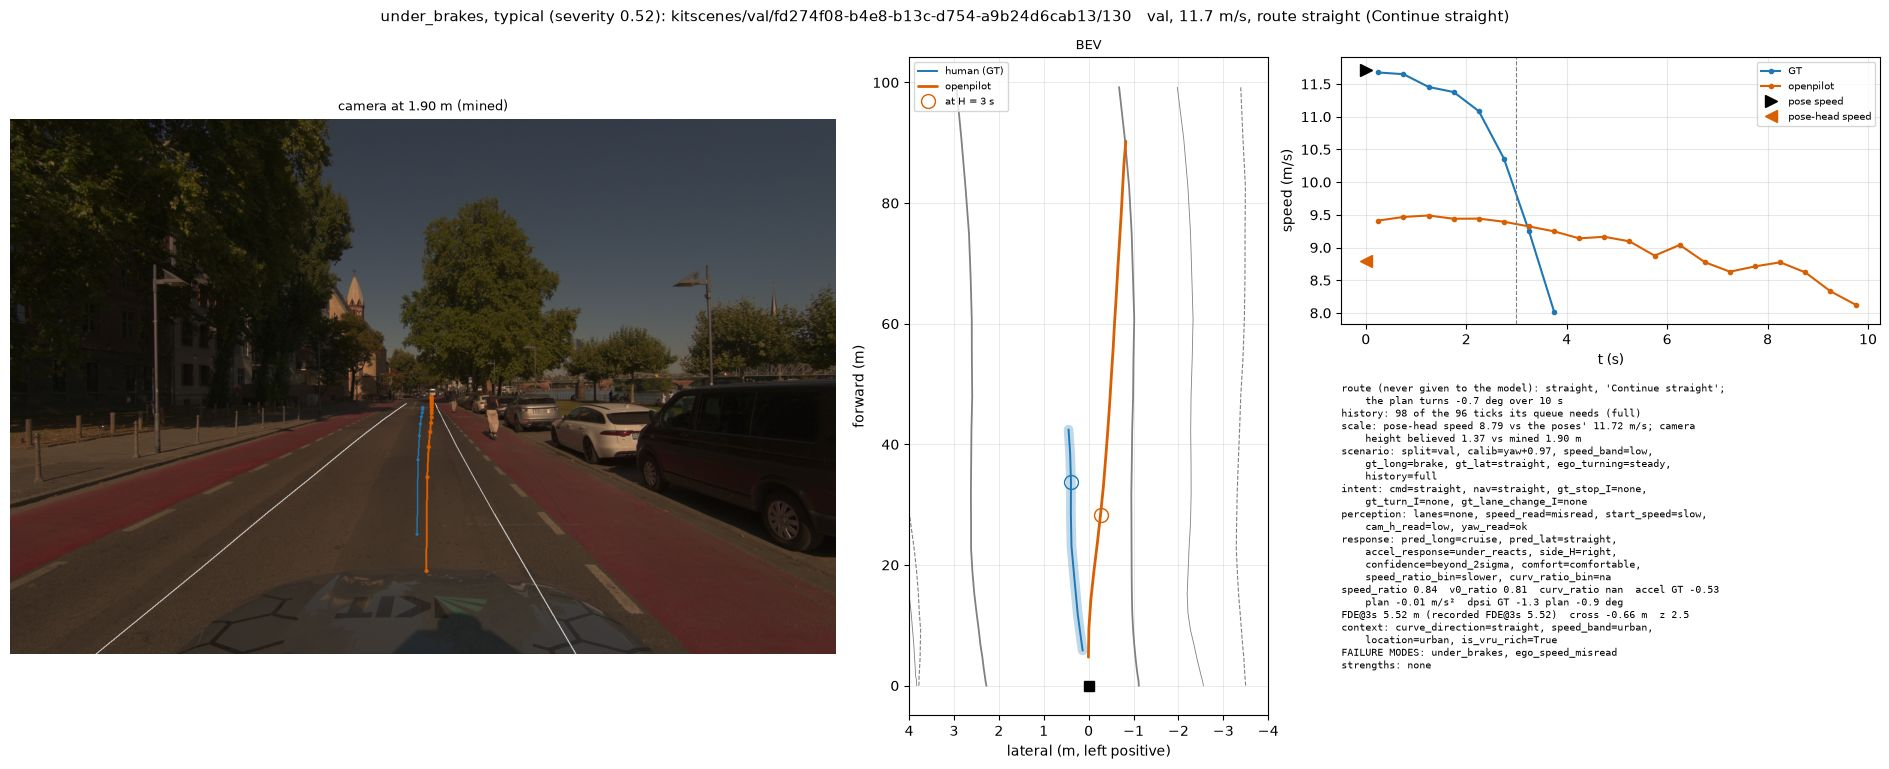

fm_phantom_brake: 16 keyframes over 16 scenes


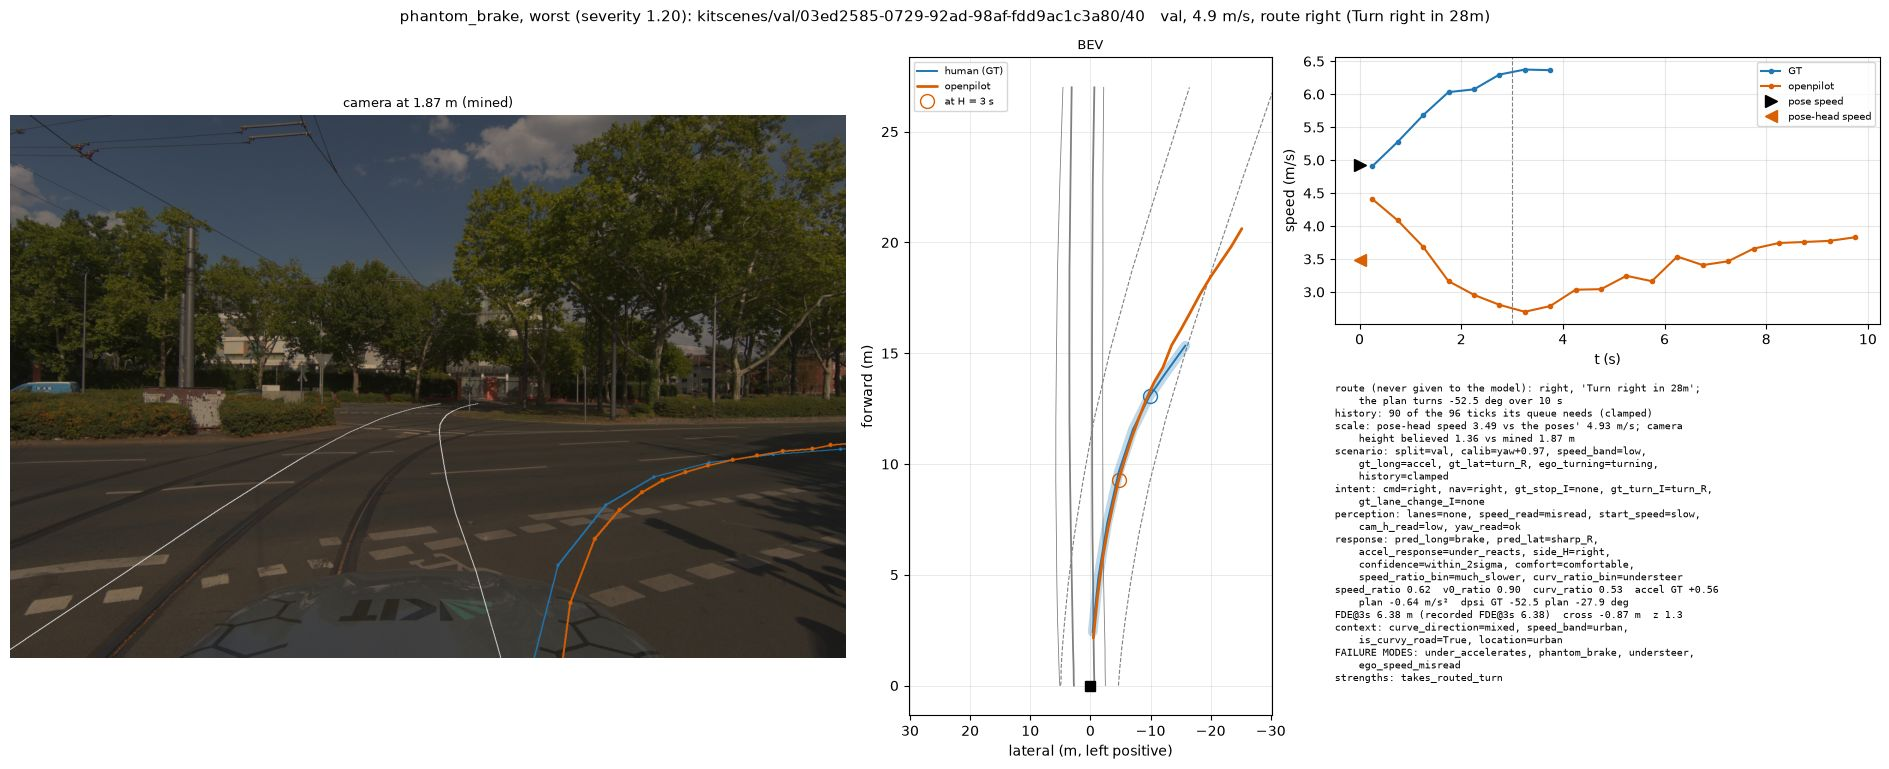

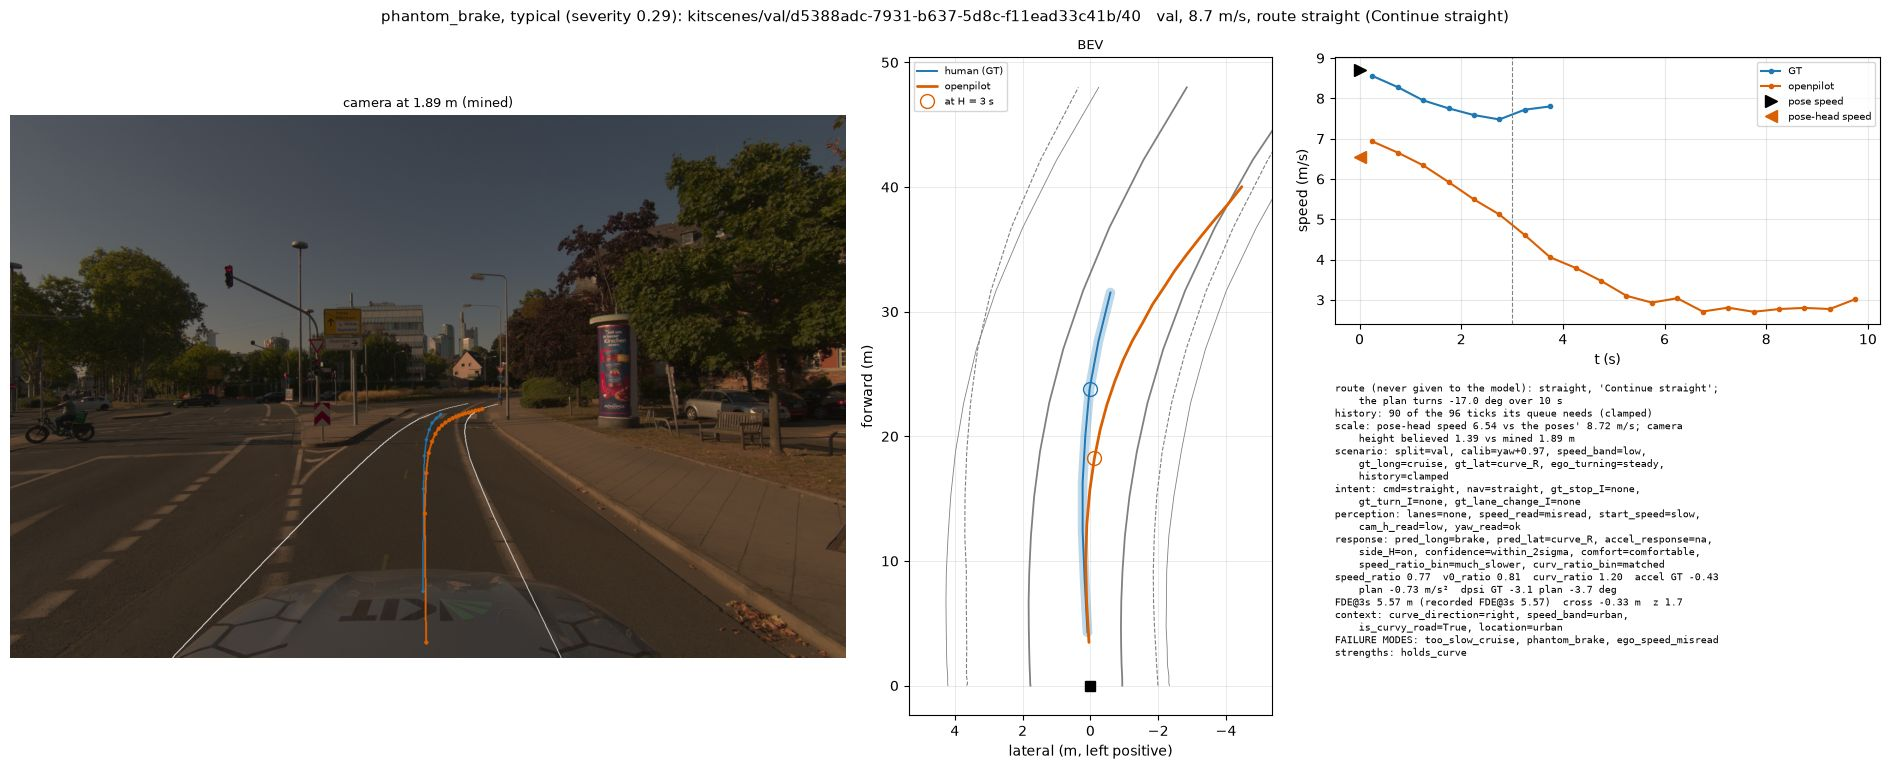

fm_turns_off_route: 7 keyframes over 7 scenes


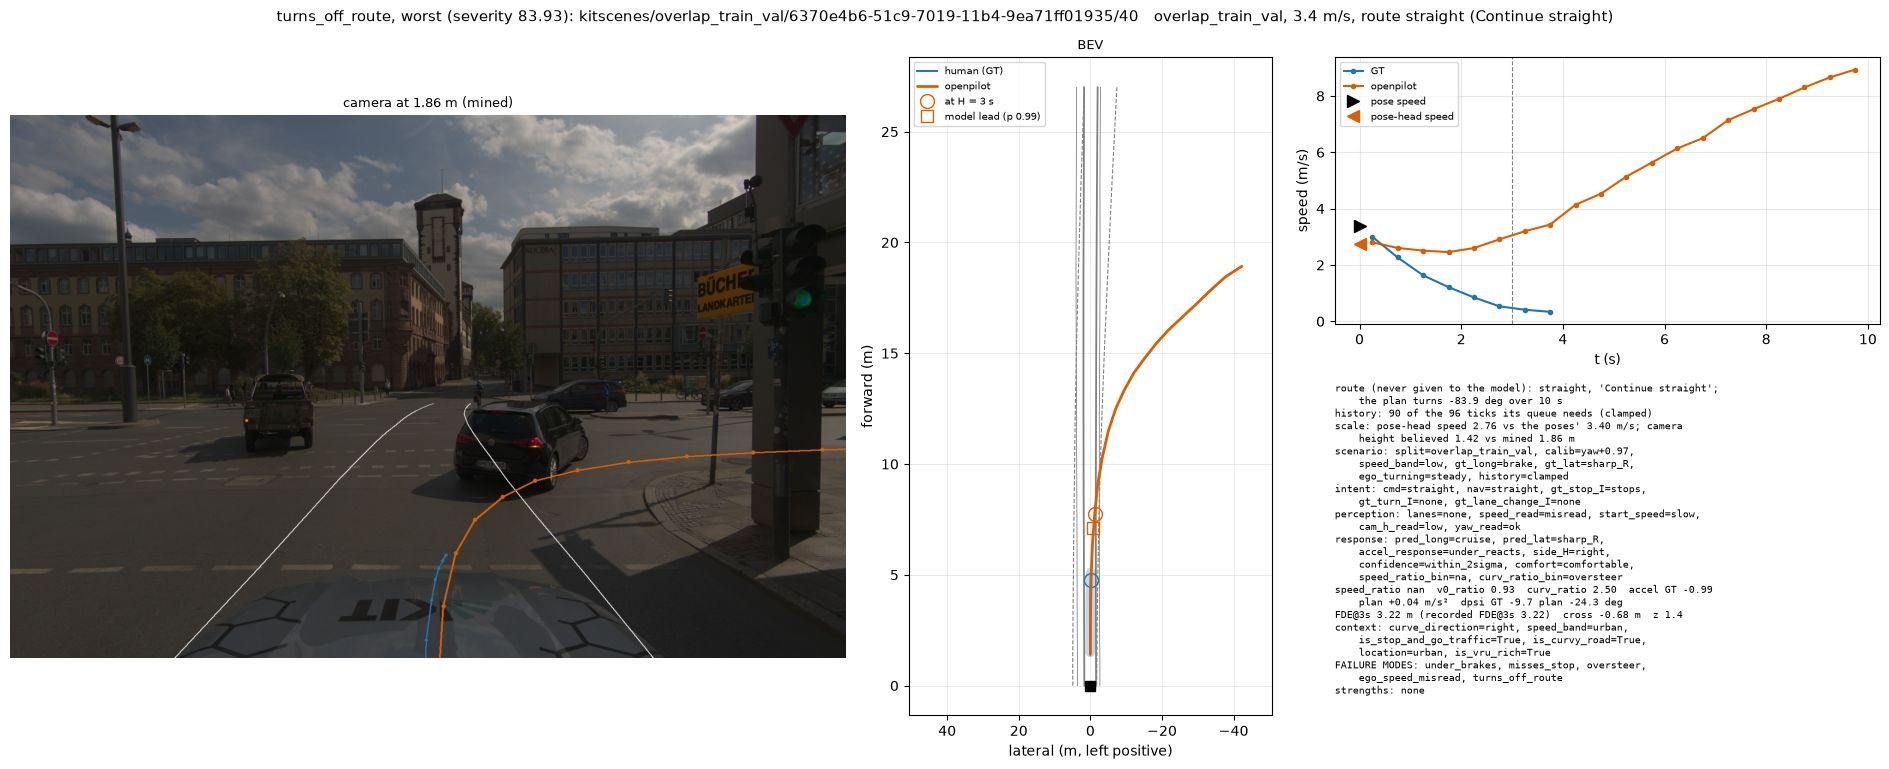

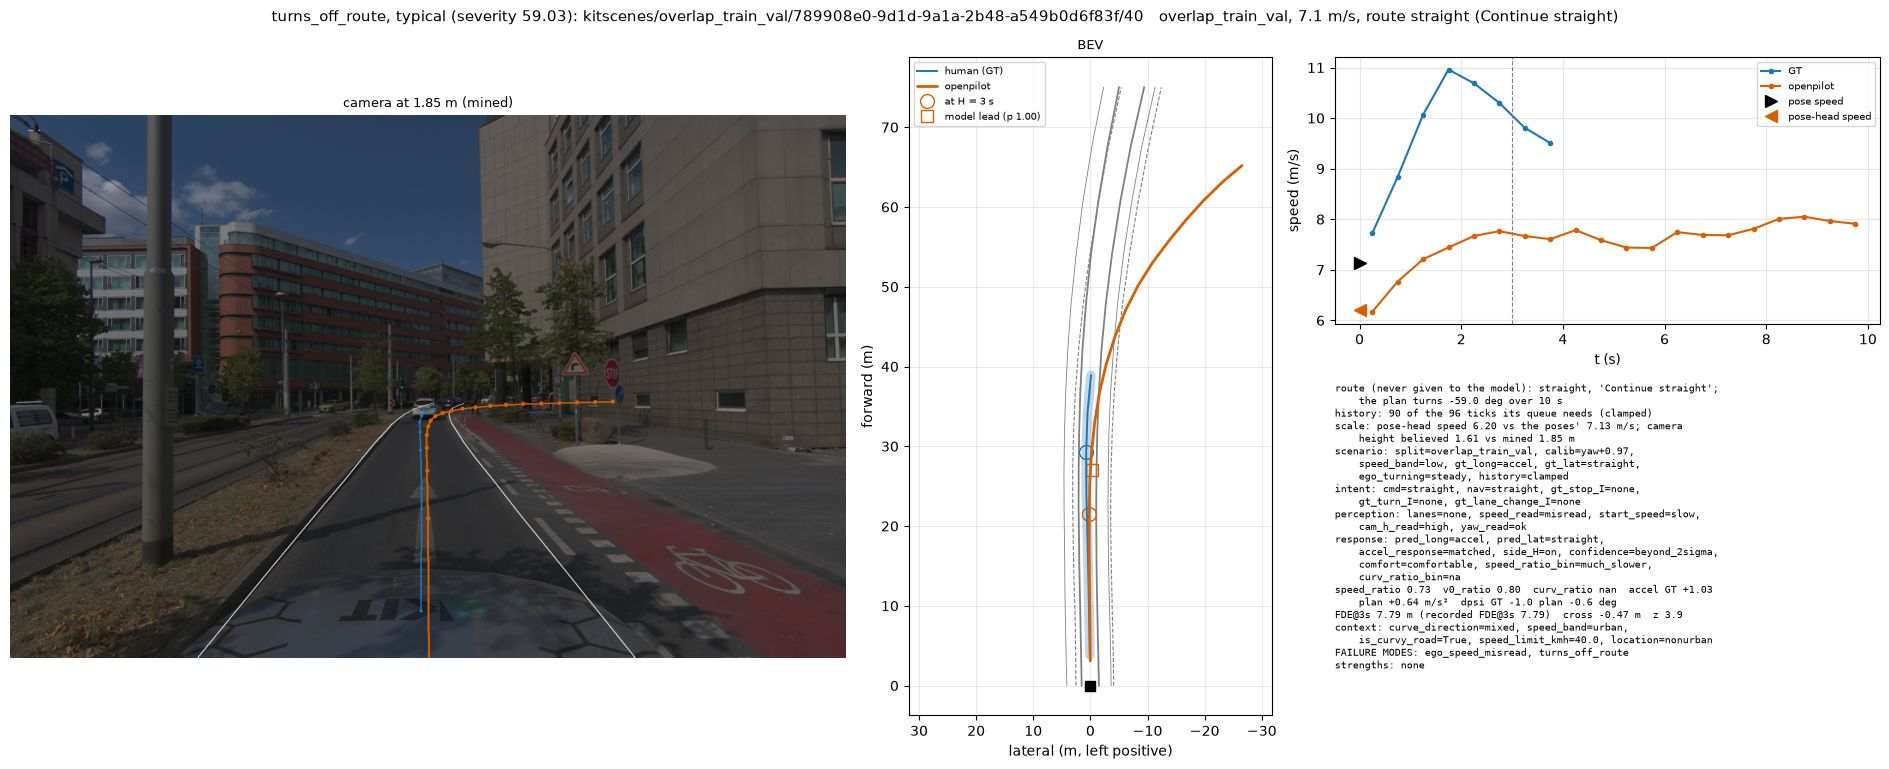

fm_turn_not_planned: 4 keyframes over 4 scenes


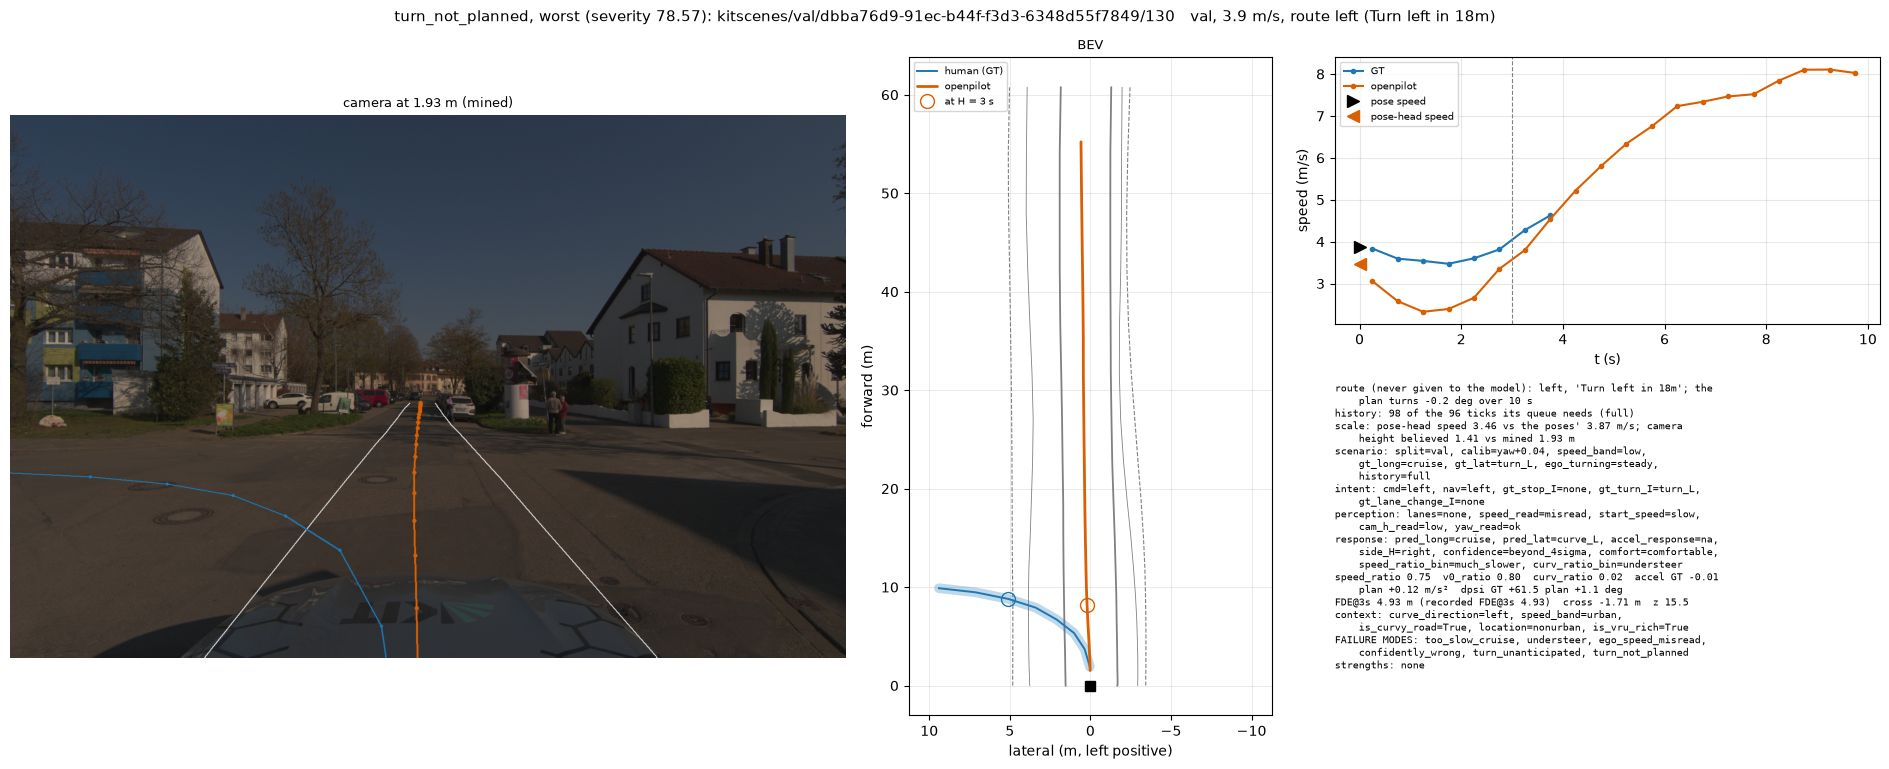

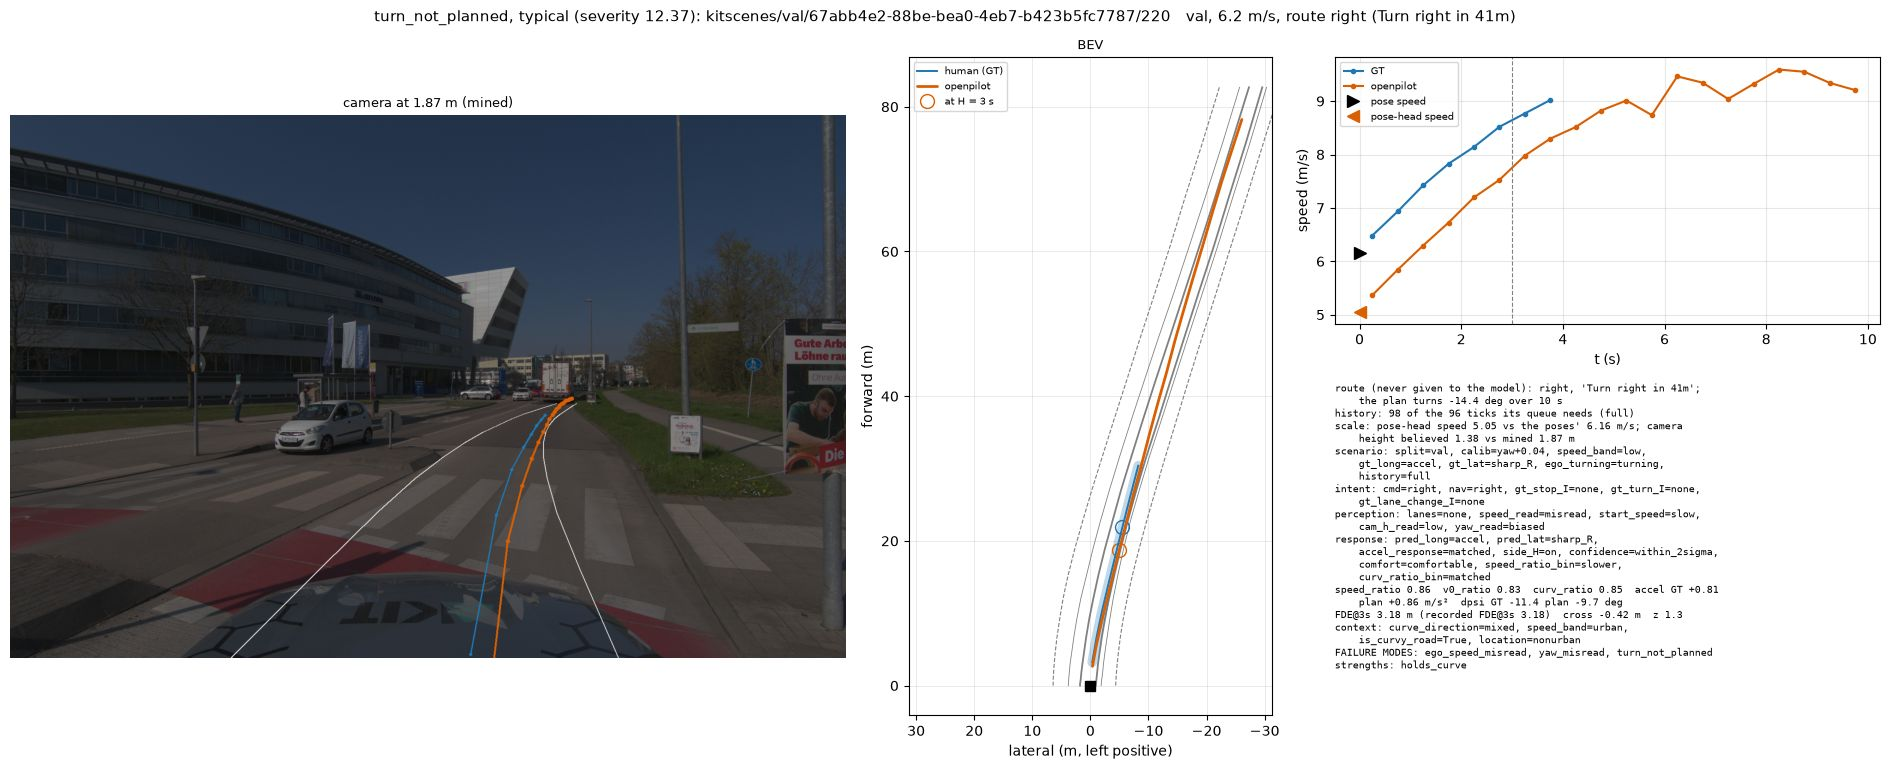

fm_turn_unanticipated: 4 keyframes over 4 scenes


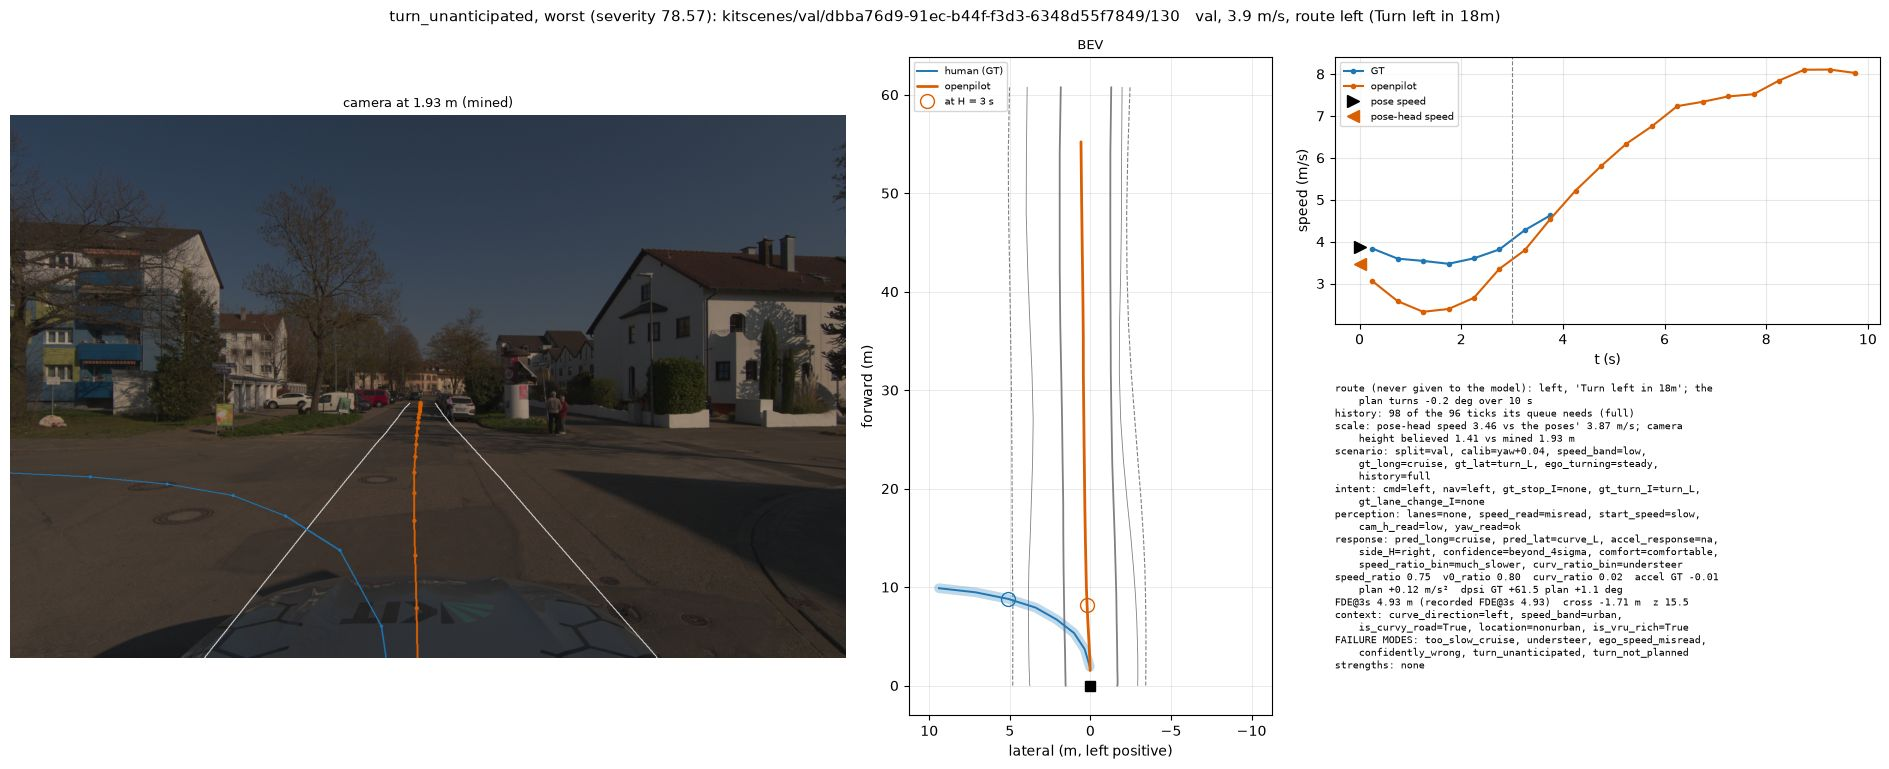

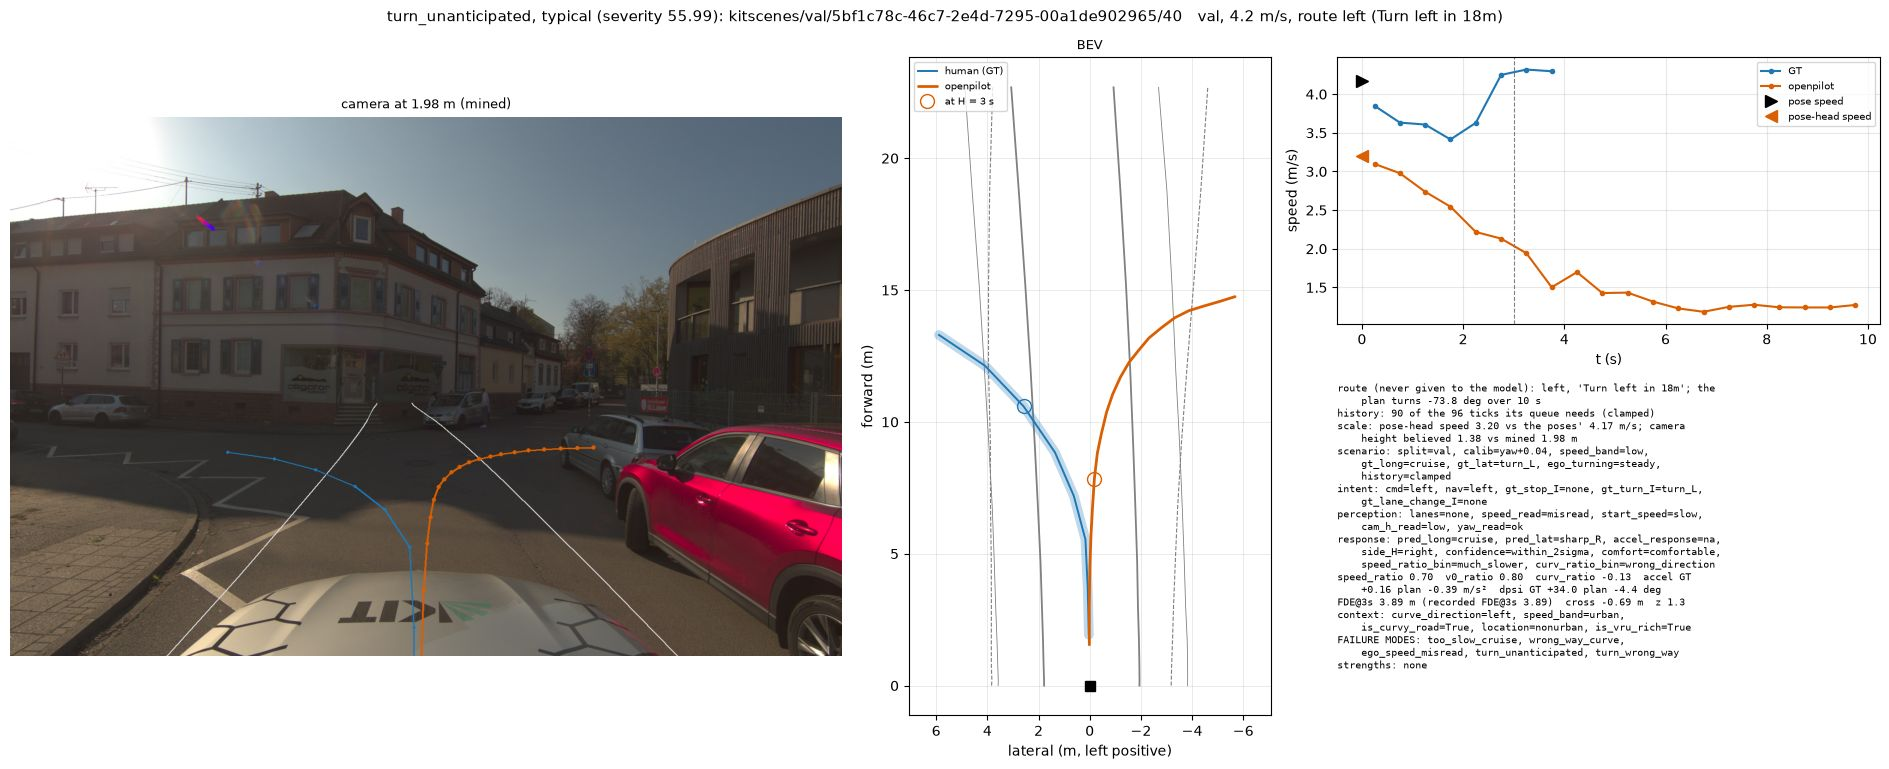

fm_turn_wrong_way: 4 keyframes over 4 scenes


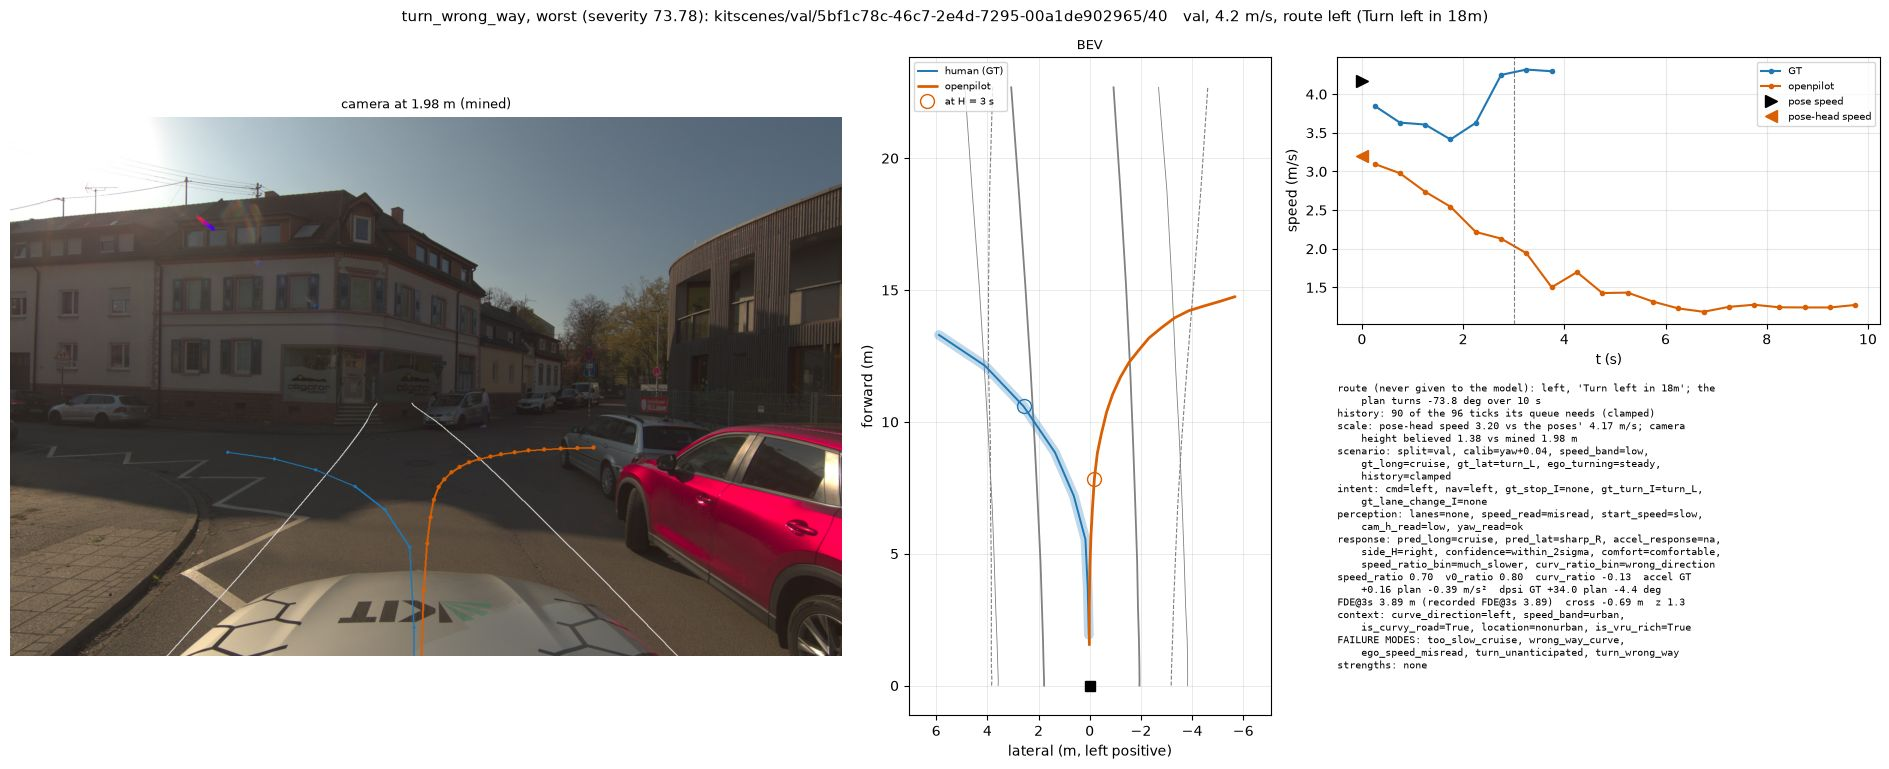

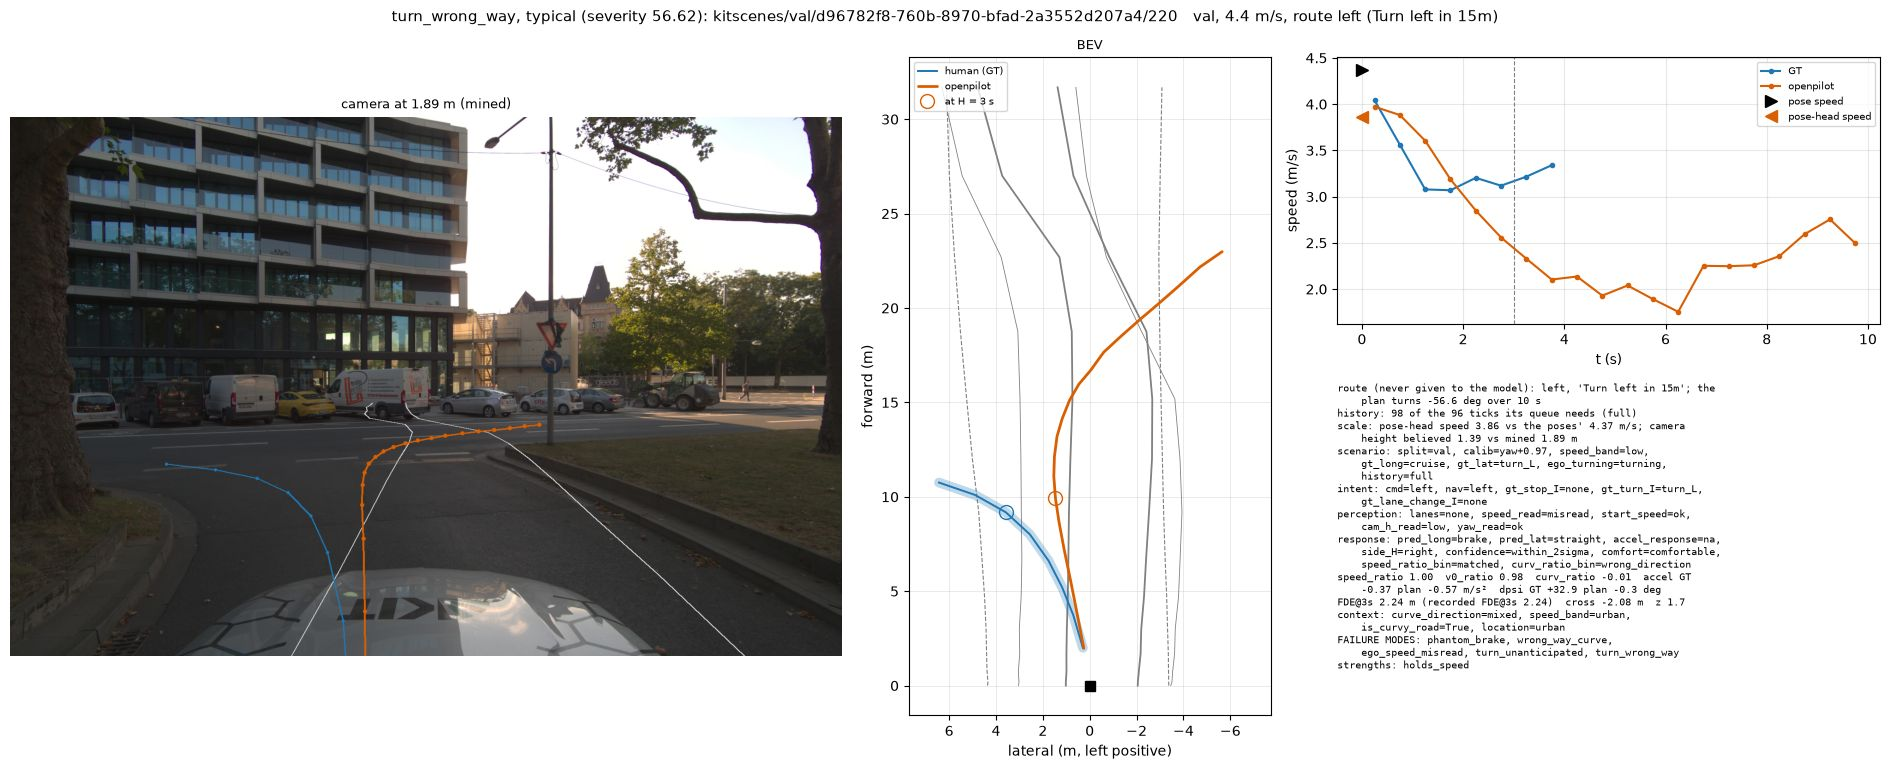

fm_lane_change_unanticipated: 2 keyframes over 2 scenes


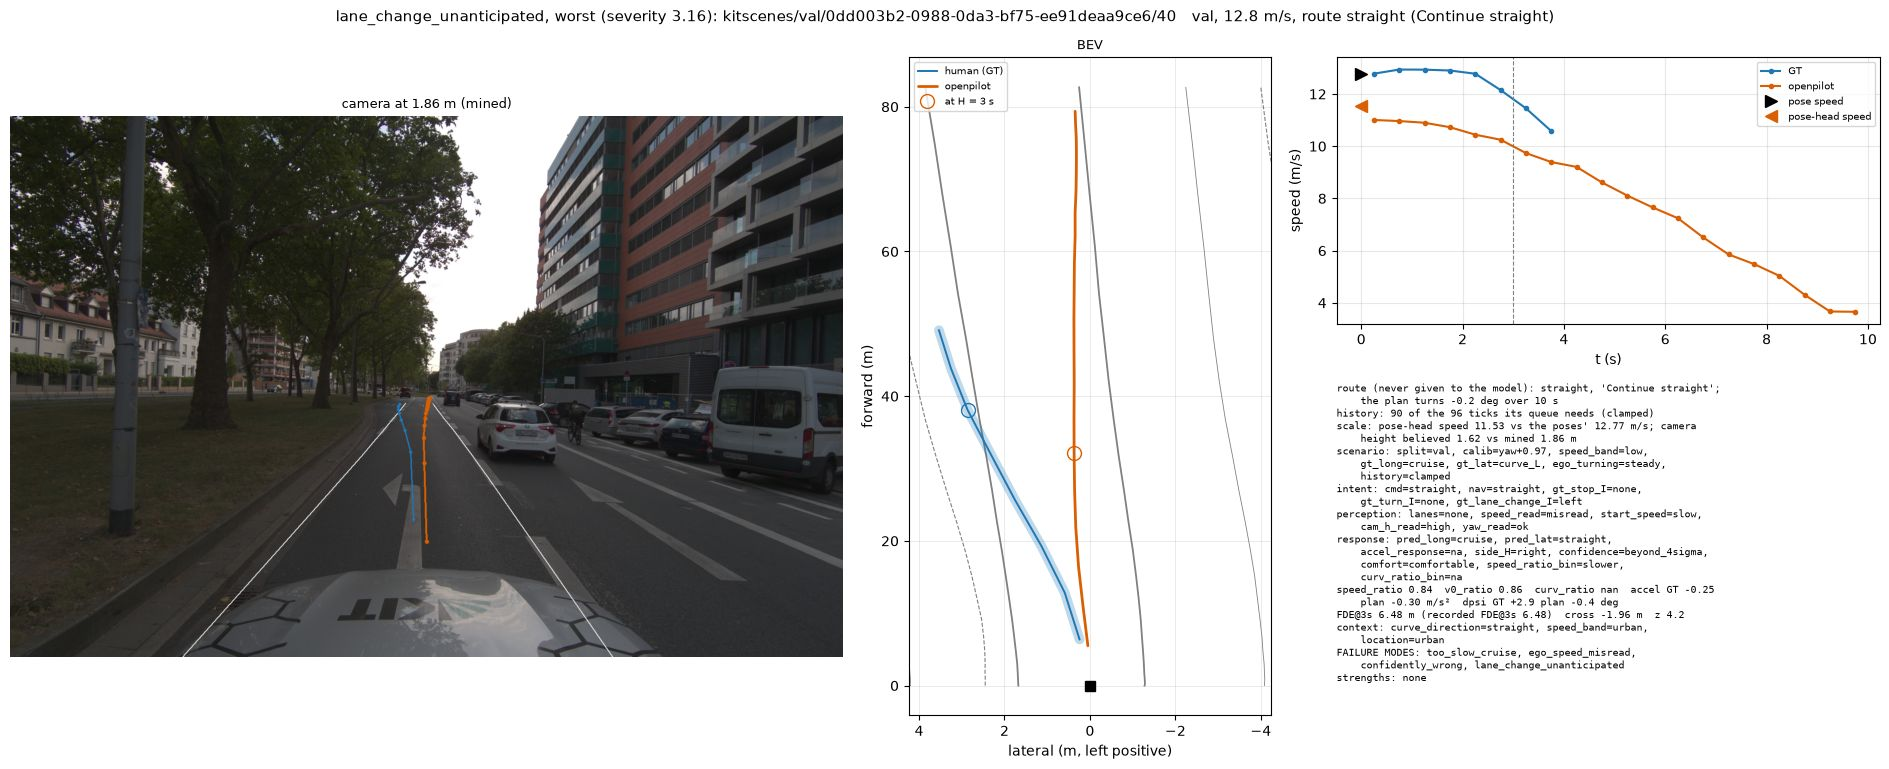

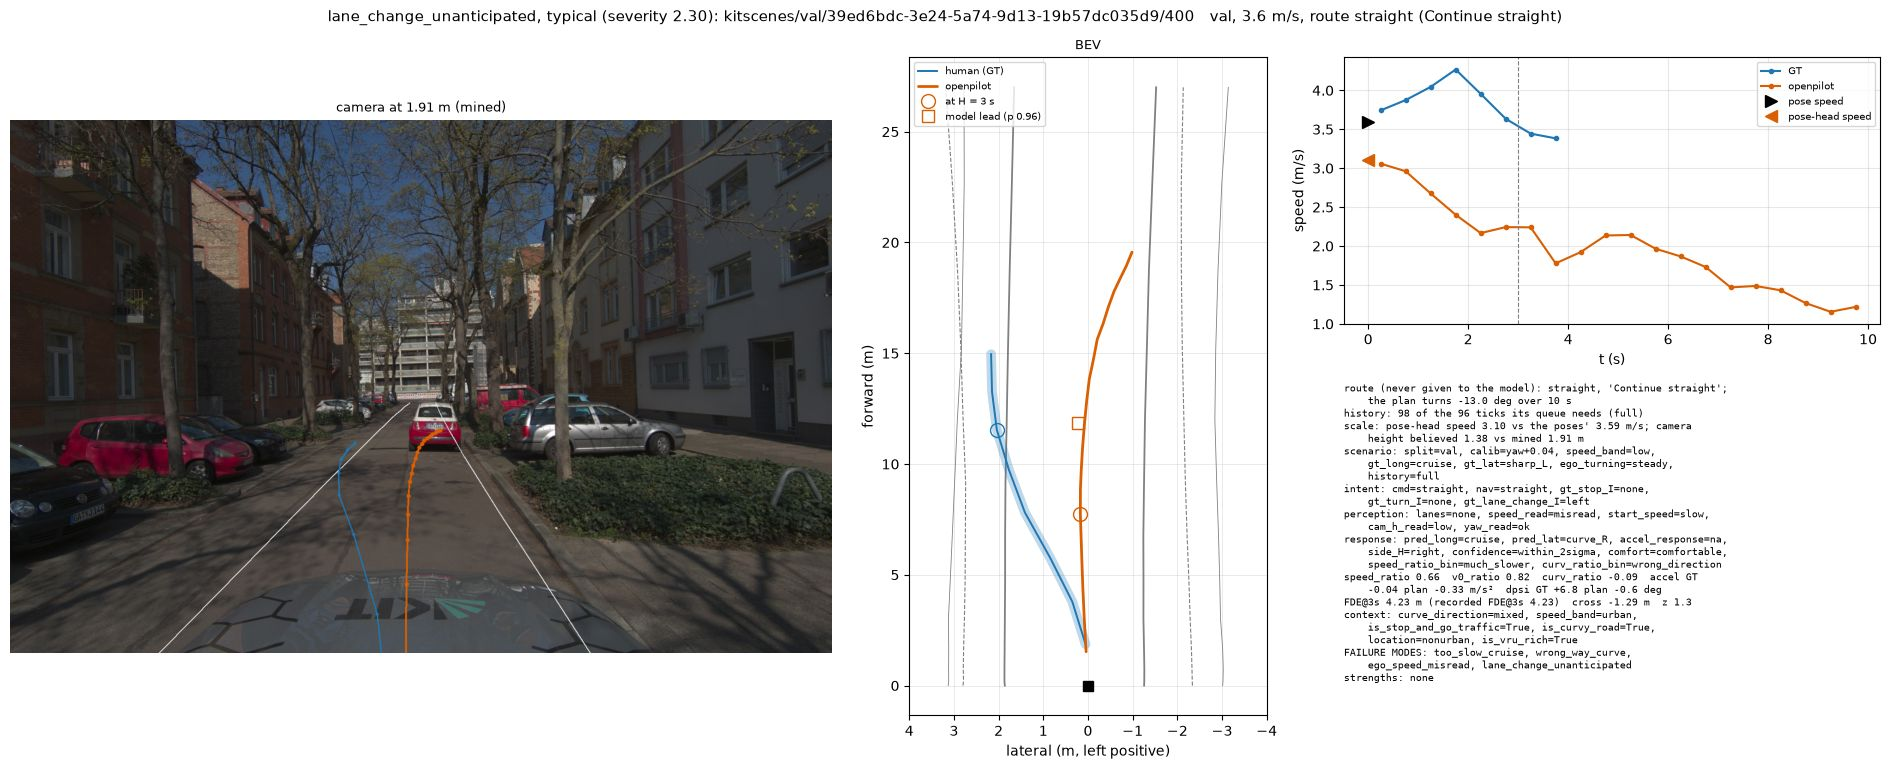

In [25]:
if FOCUS:  # debugging: every loaded keyframe
    for i in T.index[:MAX_RENDER]:
        show(i)
else:  # the most frequent failure modes, then every intent mode that fired: the worst and the most typical keyframe of each
    for name in modes().query("n > 0").index[:6]:
        sheet(name, n_typical=1, n_worst=1, n_random=0)
    for name in modes(intent=True).query("n > 0").index:
        sheet(name, n_typical=1, n_worst=1, n_random=0)

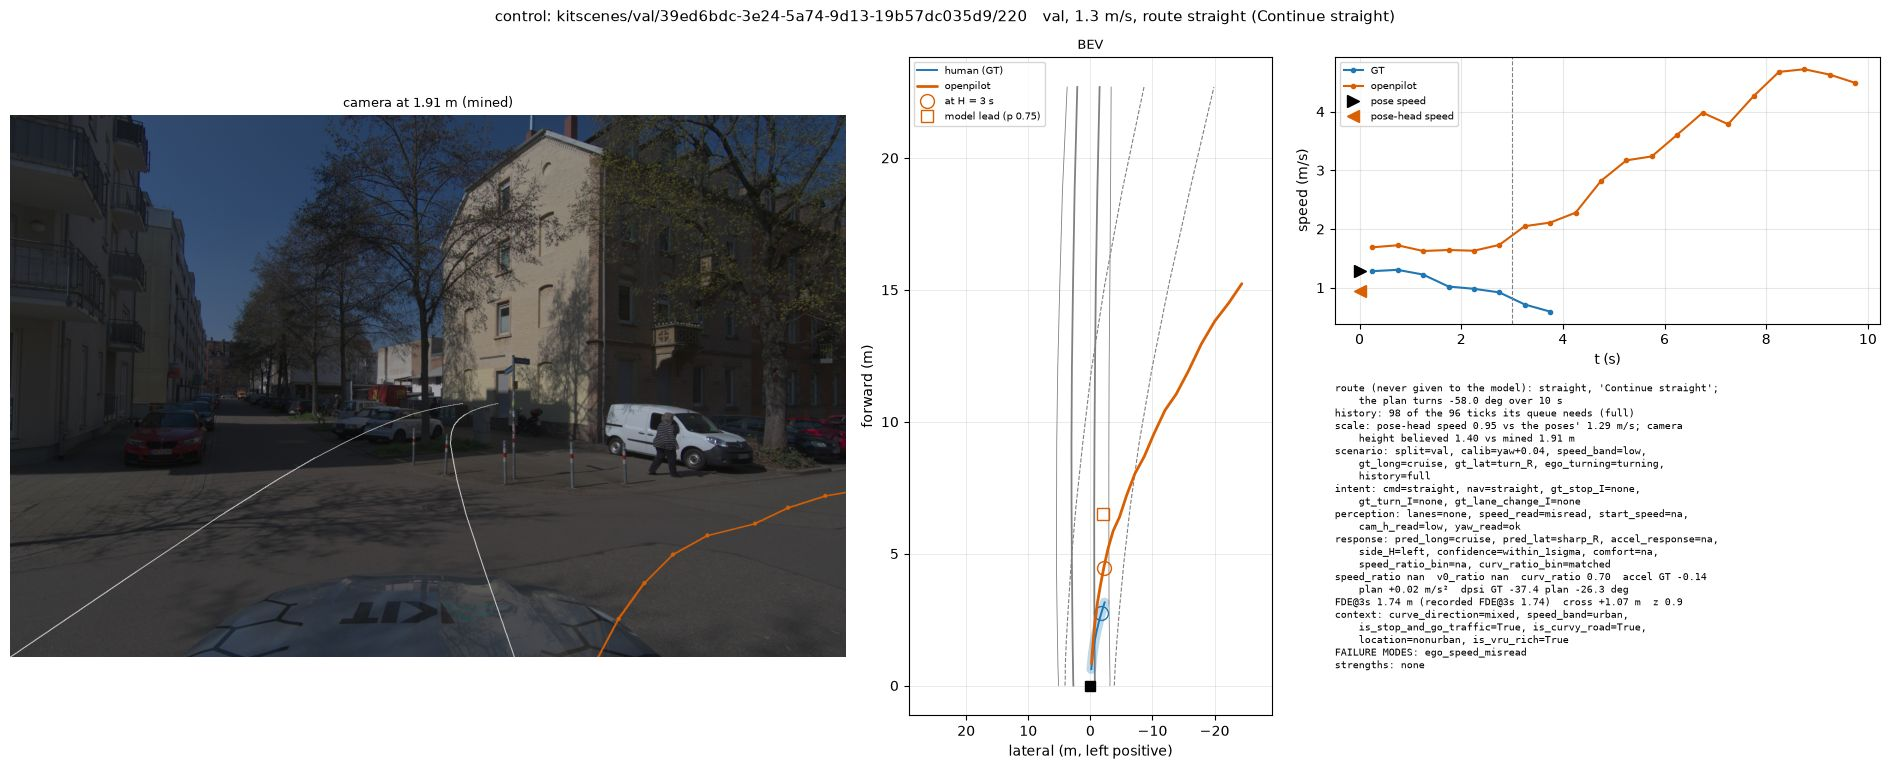

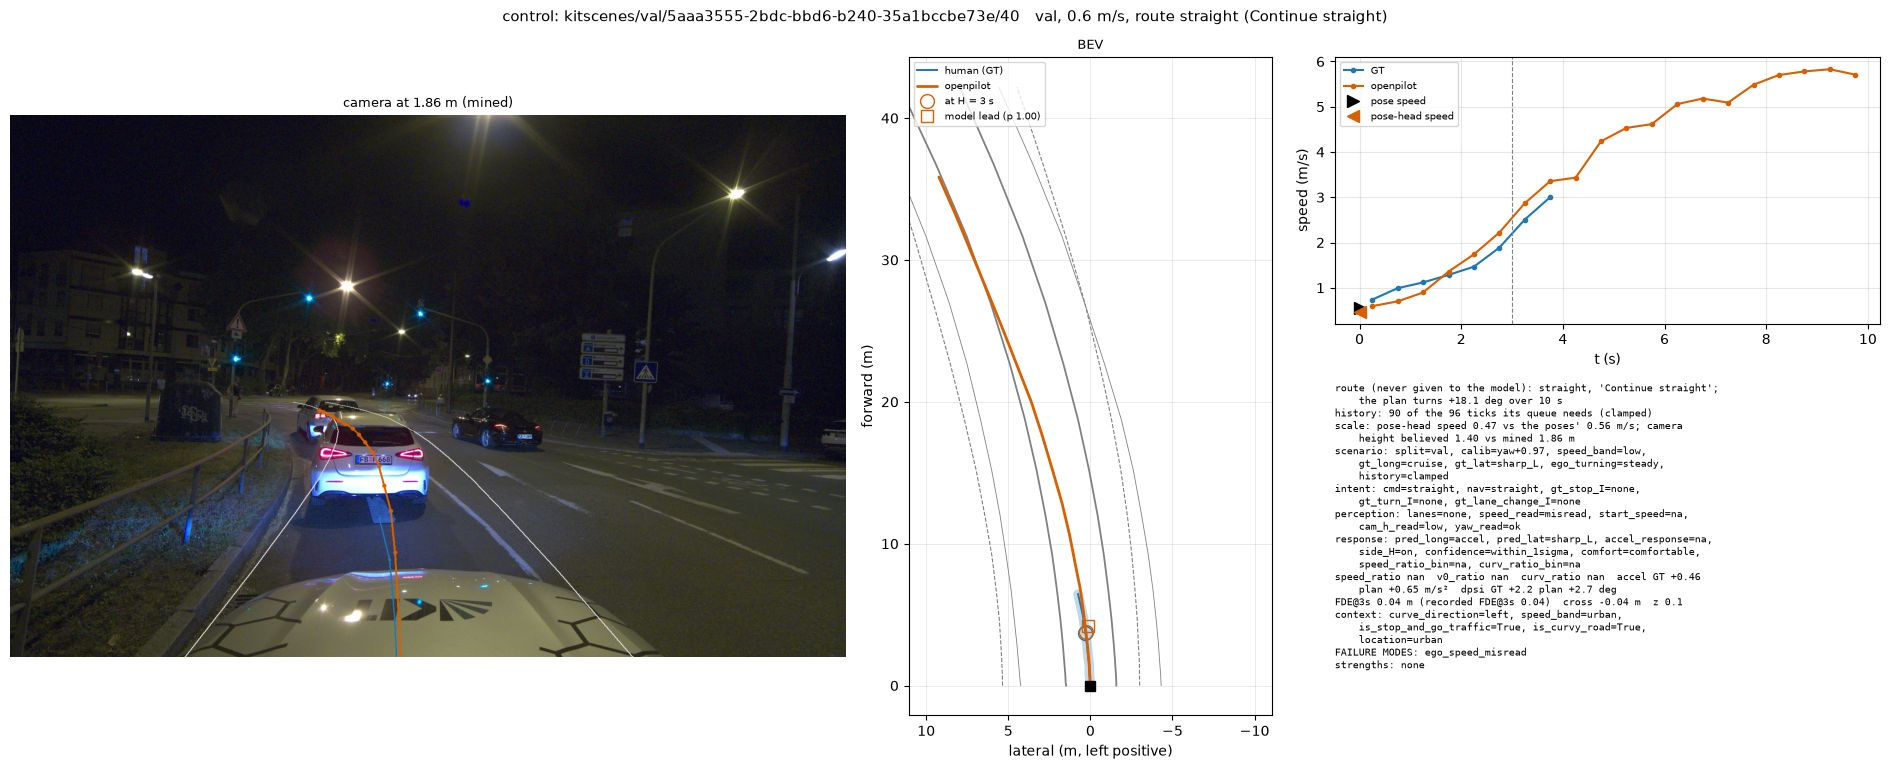

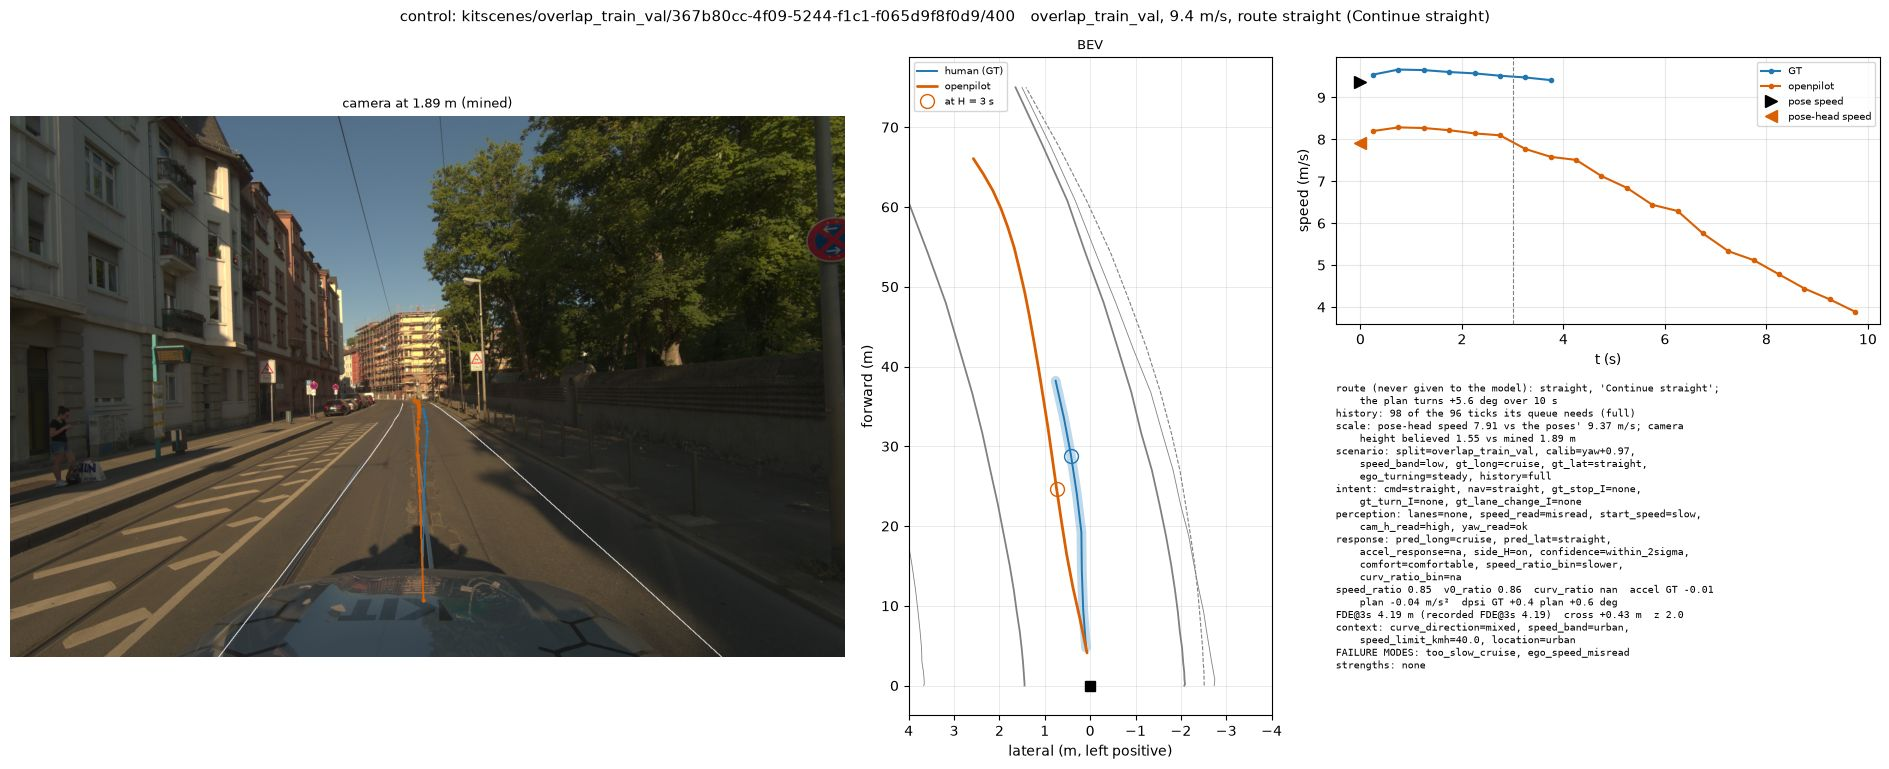

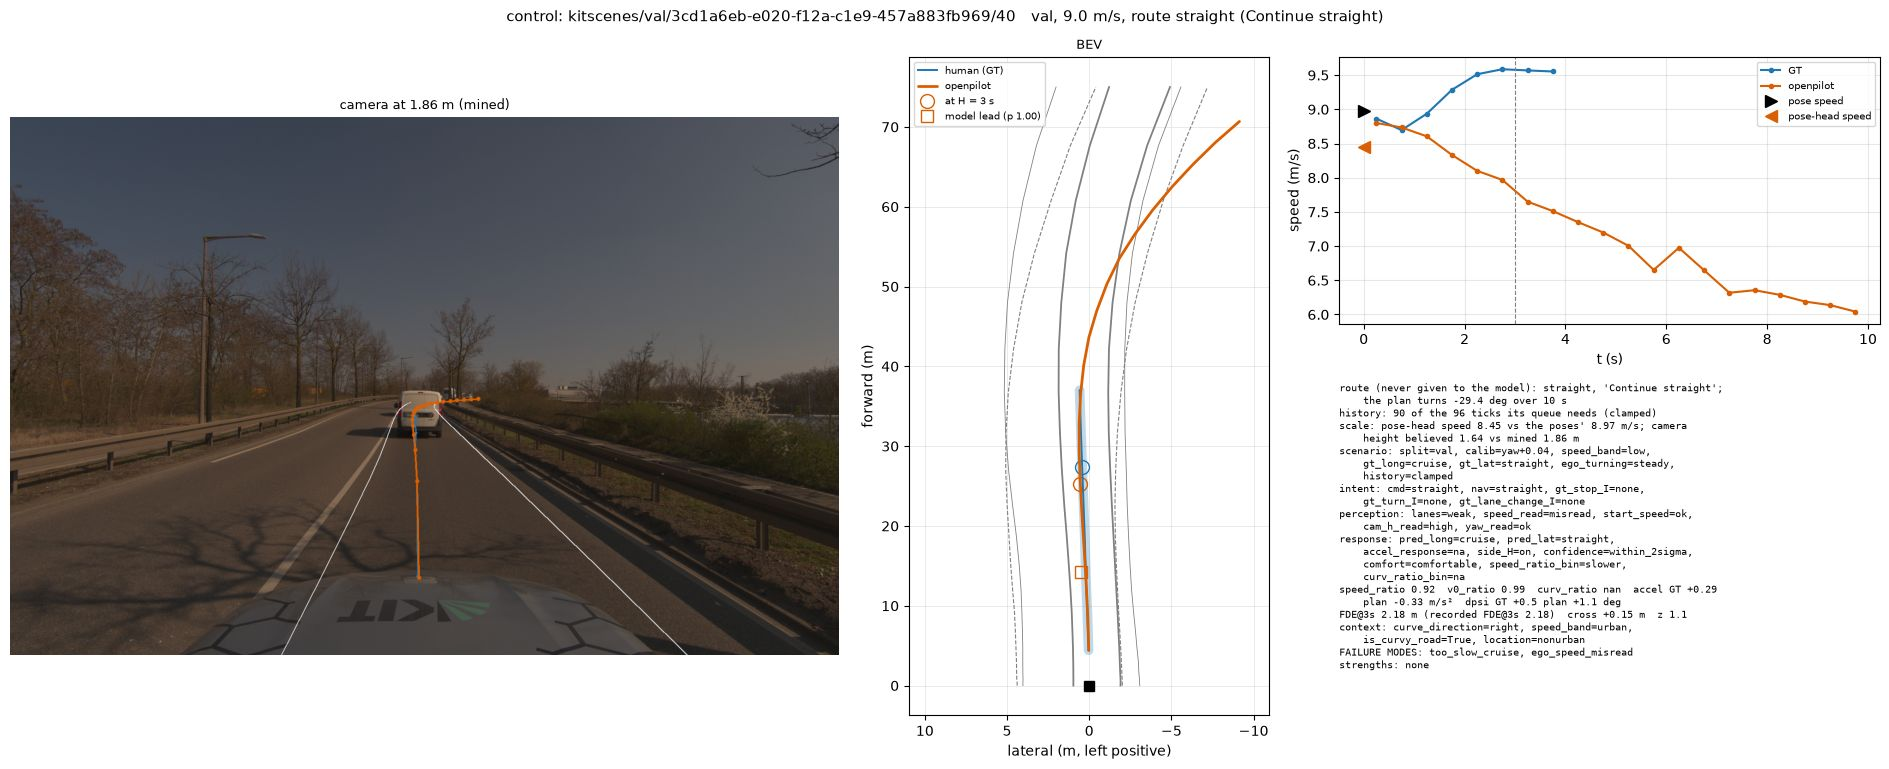

In [26]:
control(4)

In [27]:
browse()

widgets are off (WIDGETS in §1): call sheet(...) or show(...)


## 14 The camera height across val

Why does the camera height vary across the val scenes? One front camera has four heights here, and each varies for its own reason:
1. **The harness's:** calib.json's z plus `ground_offset_m`, a fixed guess at where the rig's base_frame sits above the road. It is what `Observation.camera_height()` reports, and §13's `PROJECT_HEIGHT = "harness"` projects with. openpilot's warp is a rotation and never reads it.
2. **The map's:** scenario mining's `height_ring_front`, measured per frame against the Lanelet2 road surface. `ctx_height_ring_front_m` is its scene median.
3. **The model's:** the road head's `op_cam_h` (`extras.road.camera_height`), read off the image. `cam_h_read` splits it at `cam_h_split_m`.
4. **openpilot's own, 1.22 m** (`calibrationd.HEIGHT_INIT`), the height its camera is expected at.

**What this section computes:**
- `camera_table()` (`CAMS`) has one row per val scene on disk, plus the run's overlap_train_val scenes. It holds:
    - the scene's rig: sha256[:8] of its calib.json re-dumped canonically, as scenario mining's `readers.rig_id` names it;
    - its city, the nearest recording city to the map's origin;
    - the front camera's position in base_frame, its optical axis, openpilot's mount angles and its intrinsics;
    - the harness's and the map's heights, and where the map puts base_frame above the road.

  It asserts three things: every rig is one of the three known ones; each rig has one front-camera setting; openpilot's yaw and pitch agree with the optical axis to 0.01°. If the adapter recorded its mount angles, one rig must reproduce them.
- `rig_diff()` lists the calib.json fields that differ between the rigs. `rig_summary()` gives each rig's camera, its val scenes, and the run's keyframes in each `cam_h_read` mode.
- `keyframe_heights()` (`KH`) gives, per keyframe, the map's height, whether it is on a lanelet or at a curb or an intersection, and its lane width 10 m ahead.
- `heights_plot(scene)` draws the four heights per scene (left) and one scene frame by frame (right). With no scene, it picks the scene of 4 or more keyframes whose reading moves most.

In [28]:
HEIGHT_INIT_M = 1.22  # openpilot's calibrationd.HEIGHT_INIT: the camera height its training rigs sit near
# the three calib.json contents over all 1006 KITScenes scenes, named as scenario mining's readers.rig_id names them
KNOWN_RIGS = ("53df1231", "901dfe25", "dbb25dcf")
# openpilot's view_frame_from_device_frame, restated because openpilot is not in this environment
VIEW_FROM_DEVICE = np.array([[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])
# scenario mining's readers.CITIES: the dataset's recording cities, (lat, lon) degrees
CITIES = {"karlsruhe": (49.0094, 8.4044), "frankfurt": (50.1109, 8.6821), "sindelfingen": (48.7133, 9.0028)}
_CTX = CFG.get("context", {}).get(BENCH, {})
MINED = Path(cfg.resolve(_CTX["json"])) if "json" in _CTX else None  # scenario mining's data/
MAP_FEATURES = json.loads((MINED / "features_map.json").read_text())["scenes"] if MINED else {}


def _rpy(E):
    """openpilot's mount (roll, pitch, yaw) in degrees, as CameraAdapter derives it from camera->ego.

    rot2euler(view_frame_from_device_frame.T @ (DEVICE_FROM_EGO @ R).T), with rot2euler written out
    for rot_from_euler's z-y-x order.
    """
    m = VIEW_FROM_DEVICE.T @ (DEVICE_FROM_EGO @ np.asarray(E, dtype=float)[:3, :3]).T
    roll, pitch, yaw = (
        np.arctan2(m[2, 1], m[2, 2]),
        -np.arcsin(np.clip(m[2, 0], -1, 1)),
        np.arctan2(m[1, 0], m[0, 0]),
    )
    return tuple(float(v) for v in np.degrees([roll, pitch, yaw]))


def _rig(path):
    """The scene's calibration as readers.rig_id names it: sha256[:8] of calib.json re-dumped canonically."""
    calib = json.loads((path / "calibration" / "calib.json").read_text())
    return hashlib.sha256(json.dumps(calib, sort_keys=True, separators=(",", ":")).encode()).hexdigest()[:8]


def _city(path, within_km=25.0):
    """The nearest of CITIES to the scene's map origin within within_km (readers.city_of); NaN without a map."""
    origin = path / "maps" / "origin.json"
    if not origin.exists():
        return np.nan
    o = json.loads(origin.read_text())
    lat, lon = float(o["latitude"]), float(o["longitude"])
    best, dist = "other", within_km
    for name, (la, lo) in CITIES.items():
        d = 6371.0 * np.hypot(np.radians(lat - la), np.radians(lon - lo) * np.cos(np.radians(la)))
        if d < dist:
            best, dist = name, d
    return best


_FRAMES = {}


def _map_frames(split_dir, scene_id):
    """Scenario mining's per-frame map series of one scene (height_ring_front, lane_width, curb, ...), or None."""
    key = (split_dir, scene_id)
    if key not in _FRAMES:
        f = MINED.parent / "cache" / "map" / split_dir / f"{scene_id}.npz" if MINED else None
        _FRAMES[key] = dict(np.load(f)) if f is not None and f.exists() else None
    return _FRAMES[key]


def camera_table(splits=("val",), df=None):
    """One row per scene on disk in `splits`, plus every scene of df: its rig, city, front camera and heights."""
    df = T if df is None else df
    found = {(r.split_dir, r.scene_id) for r in df.itertuples()}
    for root in HARNESS.dataset.roots:
        for split in splits:
            if (root / split).is_dir():
                found |= {(split, p.name) for p in (root / split).iterdir() if (p / "calibration").is_dir()}
    kf = df.groupby("scene").size()
    rows = []
    for split_dir, scene_id in sorted(found):
        path = HARNESS._scene_path(scene_id, split_dir)
        _, K, E, _ = _scene_data(split_dir, scene_id, GROUND)
        scene = f"{split_dir}/{scene_id}"
        mined = MAP_FEATURES.get(scene, {})
        roll, pitch, yaw = _rpy(E)
        rows.append(
            {
                "scene": scene,
                "split": split_dir,
                "rig": _rig(path),
                "city": _city(path),
                "keyframes": int(kf.get(scene, 0)),
                # camera_ring_front in the rig's base_frame (T_to_reference), metres
                "x_m": E[0, 3],
                "y_m": E[1, 3],
                "z_m": E[2, 3] - GROUND,
                "yaw_deg": _mount(E)[0],  # the optical axis: left +
                "pitch_deg": _mount(E)[1],  # down +
                "op_roll_deg": roll,  # openpilot's rpyCalib, as the adapter derives it
                "op_pitch_deg": pitch,
                "op_yaw_deg": yaw,
                "f_px": K[0, 0],
                "cu_px": K[0, 2],
                "cv_px": K[1, 2],
                "h_harness_m": E[2, 3],  # z + ground_offset_m: the harness's camera height
                "h_map_m": mined.get("height_ring_front_m", np.nan),  # scenario mining's, the scene's median
                "h_map_spread_m": mined.get("height_ring_front_spread_m", np.nan),
            }
        )
    t = pd.DataFrame(rows).set_index("scene")
    t["calib"] = [f"yaw{v:+.2f}" for v in t.yaw_deg]  # §3's name for a mount
    t["base_h_map_m"] = t.h_map_m - t.z_m  # where the map puts the rig's base_frame above the road
    unknown = sorted(set(t.rig) - set(KNOWN_RIGS))
    assert not unknown, f"calib.json contents that are none of the three known rigs: {unknown}"
    # a rig is one calib.json, so one mount: this checks the reading, not the dataset
    fixed = ["x_m", "y_m", "z_m", "yaw_deg", "pitch_deg", "op_roll_deg", "f_px", "cu_px", "cv_px"]
    spread = t.groupby("rig")[fixed].agg(lambda s: s.max() - s.min()).to_numpy().max()
    assert spread < 1e-9, f"one rig, two front-camera settings: {spread}"
    # _mount reads the optical axis, _rpy openpilot's Euler angles: with a quarter-degree roll they agree
    worst = max((t.op_yaw_deg - t.yaw_deg).abs().max(), (t.op_pitch_deg - t.pitch_deg).abs().max())
    assert worst < 0.01, f"openpilot's yaw or pitch differs from the optical axis's by {worst:.3f} deg"
    return t


CAMS = camera_table()
_rec_rpy = RUN.run.get("provenance", {}).get("policy", {}).get("rpy_deg")
if _rec_rpy:  # the adapter recorded one keyframe's mount: _rpy must reproduce one rig's exactly
    gap = np.abs(CAMS[["op_roll_deg", "op_pitch_deg", "op_yaw_deg"]].to_numpy() - _rec_rpy).max(1)
    assert gap.min() < 1e-3, (
        f"no rig's derived rpy is the {_rec_rpy} the adapter recorded (nearest {gap.min():.4f} deg)"
    )
    print(
        f"the adapter's recorded rpy_deg {_rec_rpy} is rig {CAMS.rig.iat[int(gap.argmin())]}'s, to {gap.min():.1e} deg"
    )
print(
    f"{len(CAMS)} scenes: {', '.join(f'{n} {s}' for s, n in CAMS.split.value_counts().items())}; "
    f"{int((CAMS.keyframes > 0).sum())} of them in the run"
)

the adapter's recorded rpy_deg [0.2544, -0.0381, 0.0371] is rig 901dfe25's, to 3.5e-05 deg
140 scenes: 117 val, 23 overlap_train_val; 140 of them in the run


In [29]:
def _leaves(d, prefix=""):
    """(dotted path, value as JSON) of every leaf of a nested dict."""
    if not isinstance(d, dict):
        yield prefix, json.dumps(d)
        return
    for k, v in d.items():
        yield from _leaves(v, f"{prefix}.{k}" if prefix else k)


def rig_diff(t=None):
    """The calib.json fields that differ between the rigs: per field, how many entries (sensors) it differs on, how
    many carry it at all, and how many entries the file has."""
    t = CAMS if t is None else t
    one = t.reset_index().groupby("rig").scene.first()
    calib = {
        rig: json.loads((HARNESS._scene_path(*s.split("/")[::-1]) / "calibration" / "calib.json").read_text())
        for rig, s in one.items()
    }
    leaves = {rig: dict(_leaves(c)) for rig, c in calib.items()}
    keys = set().union(*leaves.values())
    differ = [k for k in keys if len({c.get(k) for c in leaves.values()}) > 1]
    field = lambda k: k.partition(".")[2].split(".")[0]  # sensor.field[.more] -> field  # noqa: E731
    rows = {}
    for f in sorted({field(k) for k in differ}):
        rows[f] = {
            "differs on": len({k.partition(".")[0] for k in differ if field(k) == f}),
            "carried by": len({k.partition(".")[0] for k in keys if field(k) == f}),
            "entries": max(len(c) for c in calib.values()),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def rig_summary(t=None, df=None, split="val"):
    """Per rig: its front camera, its scenes in split with their cities and map heights, and the run's keyframes
    (from every split) in each cam_h_read mode."""
    t, df = (CAMS if t is None else t), (T if df is None else df)
    g, s = t.groupby("rig"), t[t.split == split].groupby("rig")
    mode = df.groupby([df.scene.map(t.rig), "cam_h_read"]).size().unstack(fill_value=0)
    out = pd.DataFrame(
        {
            "calib": g.calib.first(),
            "x, y, z (m)": g[["x_m", "y_m", "z_m"]].first().round(4).apply(tuple, axis=1),
            "optical axis yaw / pitch (deg)": g[["yaw_deg", "pitch_deg"]]
            .first()
            .round(3)
            .apply(tuple, axis=1),
            "openpilot rpy (deg)": g[["op_roll_deg", "op_pitch_deg", "op_yaw_deg"]]
            .first()
            .round(3)
            .apply(tuple, axis=1),
            "f, cu, cv (px)": g[["f_px", "cu_px", "cv_px"]].first().apply(tuple, axis=1),
            "harness height (m)": g.h_harness_m.first().round(3),
            f"{split} scenes": s.size(),
            f"{split} cities": s.city.agg(
                lambda c: ", ".join(f"{n} {k}" for k, n in c.value_counts().items())
            ),
            f"map height, {split} scene medians: min / median / max (m)": s.h_map_m.agg(
                lambda h: f"{h.min():.3f} / {h.median():.3f} / {h.max():.3f}"
            ),
            f"base_frame above the road per the map, {split} median (m)": s.base_h_map_m.median().round(3),
            "run scenes, every split": g.keyframes.agg(lambda k: int((k > 0).sum())),
            "run keyframes": g.keyframes.sum(),
            "low / high cam_h_read": mode.apply(lambda r: f"{r.get('low', 0)} / {r.get('high', 0)}", axis=1),
        }
    )
    return out.T


def keyframe_heights(df=None, ahead_m=10.0):
    """Per keyframe: the map's camera height, lanelet, curb and intersection flags at it, and its lane width ahead_m on."""
    df = T if df is None else df
    rows = {}
    for i, r in df.iterrows():
        f = _map_frames(r.split_dir, r.scene_id)
        poses = _scene_data(r.split_dir, r.scene_id, GROUND)[0]
        if f is None or len(f["t"]) != len(poses):  # no series, or not 1:1 with the frames
            continue
        kf = int(r.keyframe)
        along = np.r_[0.0, np.cumsum(np.hypot(*np.diff(poses[kf:, :2], axis=0).T))]
        j = kf + min(int(np.searchsorted(along, ahead_m)), len(along) - 1)
        rows[i] = {
            "map_h_m": f["height_ring_front"][kf],
            "map_on_lanelet": bool(
                f["lanelet"][kf] >= 0
            ),  # -1: on no lanelet of the map, which has no height there
            "map_curb": f["curb"][kf],
            "map_at_intersection": f["at_intersection"][kf],
            "map_lane_width_m": f["lane_width"][j],
        }
    return pd.DataFrame.from_dict(rows, orient="index").reindex(df.index)


KH = keyframe_heights()
_rd = rig_diff()
print(
    f"calib.json fields that differ between the {CAMS.rig.nunique()} rigs: "
    + "; ".join(
        f"{f}, on {r['differs on']} of the {r['carried by']} entries that carry one ({r['entries']} entries in all)"
        for f, r in _rd.iterrows()
    )
)
display(rig_summary())
_no_h = T.sample_id[KH.map_h_m.isna()]
assert KH.map_on_lanelet[_no_h.index].eq(False).all(), "a keyframe without the map's height is on a lanelet"
print(
    f"the map's height at the keyframe, for {int(KH.map_h_m.notna().sum())} of {len(KH)} keyframes; "
    f"the other {len(_no_h)} sit on no lanelet of the map: {', '.join(_no_h)}"
)

calib.json fields that differ between the 3 rigs: T_to_reference, on 22 of the 22 entries that carry one (23 entries in all)


,53df1231,901dfe25,dbb25dcf
calib,yaw+0.97,yaw+0.04,yaw+0.02
"x, y, z (m)","(0.2073, 0.0052, -0.1826)","(0.1401, 0.0083, -0.2029)","(0.1394, 0.0101, -0.2013)"
optical axis yaw / pitch (deg),"(0.973, -0.109)","(0.037, -0.038)","(0.02, -0.373)"
openpilot rpy (deg),"(0.262, -0.114, 0.972)","(0.254, -0.038, 0.037)","(0.221, -0.373, 0.018)"
"f, cu, cv (px)","(1841.0, 1740.0, 1139.0)","(1841.0, 1740.0, 1139.0)","(1841.0, 1740.0, 1139.0)"
harness height (m),2.017,1.997,1.999
val scenes,89,25,3
val cities,"84 frankfurt, 5 karlsruhe",25 karlsruhe,3 karlsruhe
"map height, val scene medians: min / median / max (m)",1.825 / 1.868 / 1.914,1.826 / 1.880 / 1.976,1.862 / 1.897 / 1.920
"base_frame above the road per the map, val median (m)",2.051,2.083,2.098


the map's height at the keyframe, for 220 of 223 keyframes; the other 3 sit on no lanelet of the map: kitscenes/overlap_train_val/6370e4b6-51c9-7019-11b4-9ea71ff01935/40, kitscenes/overlap_train_val/873eebf4-448a-cf6e-7d5e-2dc1cd010723/130, kitscenes/val/97a94a07-e9a4-fc20-81aa-821b432cae7f/40


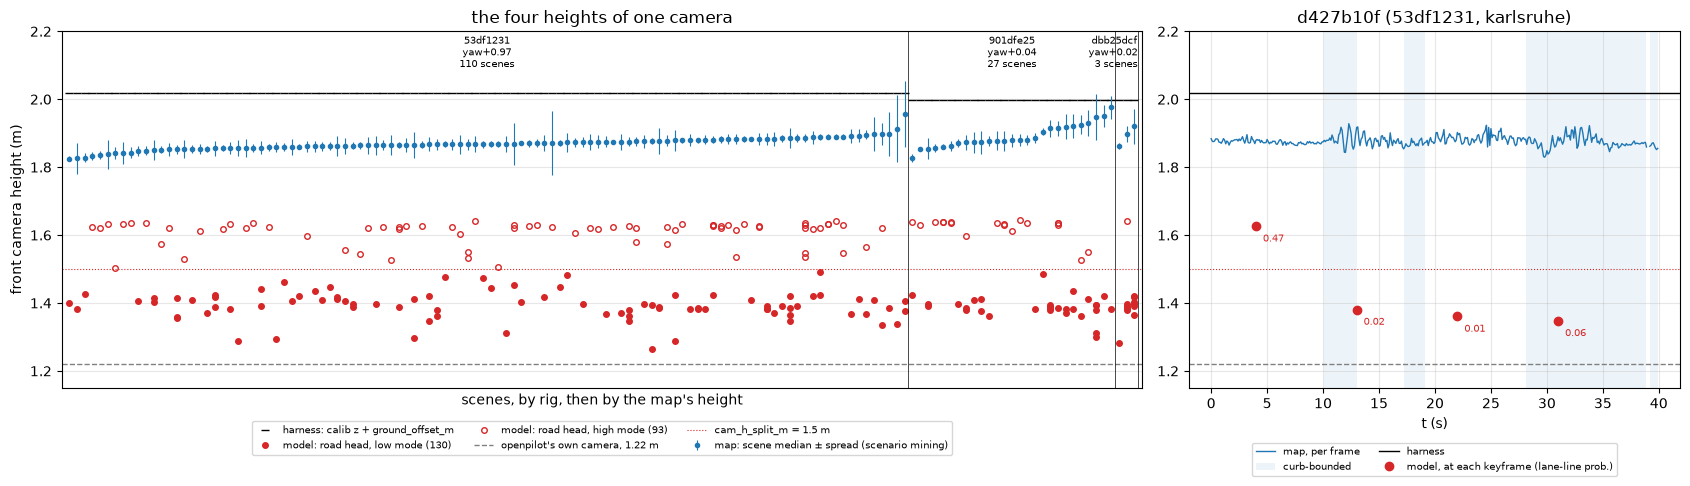

'val/d427b10f-7b2c-824f-a3d2-651e57fc821d'

In [30]:
def heights_plot(scene=None, t=None, df=None):
    """The four camera heights per scene (left), and one scene's frame by frame (right)."""
    t, df = (CAMS if t is None else t), (T if df is None else df)
    split_m = P["cam_h_split_m"]
    order = t.sort_values(["rig", "h_map_m"]).index
    x = pd.Series(np.arange(len(order)), index=order)
    fig, (ax, ax_s) = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1]})
    ax.plot(x, t.loc[order, "h_harness_m"], "k_", ms=6, label="harness: calib z + ground_offset_m")
    ax.errorbar(
        x,
        t.loc[order, "h_map_m"],
        yerr=t.loc[order, "h_map_spread_m"],
        fmt="o",
        ms=3,
        lw=0.8,
        color="tab:blue",
        label="map: scene median ± spread (scenario mining)",
    )
    kx = df.scene.map(x)
    for mode, style in (("low", dict(color="tab:red")), ("high", dict(mfc="none", color="tab:red"))):
        sel = df.cam_h_read == mode
        ax.plot(
            kx[sel],
            df.op_cam_h[sel],
            "o",
            ms=4,
            **style,
            label=f"model: road head, {mode} mode ({int(sel.sum())})",
        )
    ax.axhline(HEIGHT_INIT_M, color="grey", ls="--", lw=1, label=f"openpilot's own camera, {HEIGHT_INIT_M} m")
    ax.axhline(split_m, color="tab:red", ls=":", lw=0.8, label=f"cam_h_split_m = {split_m} m")
    for rig, idx in t.loc[order].groupby("rig", sort=False).groups.items():
        lo, hi = x[idx].min(), x[idx].max()
        ax.axvline(hi + 0.5, color="k", lw=0.5)
        label = f"{rig}\n{t.calib[idx[0]]}\n{len(idx)} scenes"
        narrow = len(idx) < 10  # too narrow to centre a label over: hang it off the group's right edge
        ax.text(
            hi + 0.4 if narrow else (lo + hi) / 2,
            2.19,
            label,
            ha="right" if narrow else "center",
            va="top",
            fontsize=7,
        )
    ax.set(xlim=(-1, len(order)), ylim=(1.15, 2.2), xticks=[], ylabel="front camera height (m)")
    ax.set_xlabel("scenes, by rig, then by the map's height")
    ax.set_title("the four heights of one camera")
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
    ax.grid(axis="y", alpha=0.3)

    if scene is None:  # the scene of 4+ keyframes whose road-head reading moves most
        many = df.groupby("scene").op_cam_h.agg(["size", "max", "min"])
        many = many[many["size"] >= 4]
        scene = (many["max"] - many["min"]).idxmax() if len(many) else df.scene.iat[0]
    r = t.loc[scene]
    split_dir, scene_id = scene.split("/")
    f = _map_frames(split_dir, scene_id)
    if f is not None:
        tt = np.arange(len(f["height_ring_front"])) / SRC_HZ
        ax_s.plot(tt, f["height_ring_front"], color="tab:blue", lw=1, label="map, per frame")
        curb = f["curb"] > 0
        ax_s.fill_between(tt, 1.15, 2.2, where=curb, color="tab:blue", alpha=0.08, lw=0, label="curb-bounded")
    ax_s.axhline(r.h_harness_m, color="k", lw=1, label="harness")
    ax_s.axhline(HEIGHT_INIT_M, color="grey", ls="--", lw=1)
    ax_s.axhline(split_m, color="tab:red", ls=":", lw=0.8)
    mine = df[df.scene == scene]
    ax_s.plot(
        mine.keyframe / SRC_HZ,
        mine.op_cam_h,
        "o",
        color="tab:red",
        label="model, at each keyframe (lane-line prob.)",
    )
    for (
        k
    ) in mine.itertuples():  # the lane-line probability, the reading's strongest association (mode_drivers)
        ax_s.annotate(
            f"{k.op_lane_prob:.2f}",
            (k.keyframe / SRC_HZ, k.op_cam_h),
            xytext=(5, -11),
            textcoords="offset points",
            fontsize=7,
            color="tab:red",
        )
    ax_s.set(ylim=(1.15, 2.2), xlabel="t (s)", title=f"{scene_id[:8]} ({r.rig}, {r.city})")
    ax_s.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
    ax_s.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    return scene


heights_plot()

### What sets the model's reading

`mode_drivers()` asks what separates the low `cam_h_read` mode from the high one. It returns four tables.
- **Continuous columns:** each column's median in each mode, and its AUC for the low mode.
    - The AUC is the chance that a low-mode keyframe has the higher value. At 0.5 the column does not separate the modes; below 0.5 it is lower in the low mode.
    - The CI comes from resampling scenes, since a scene's keyframes share a road, a rig and a drive.
    - `AUC within terciles` is the same AUC taken within thirds of the lane-line probability, weighted by keyframes. For the lane-line probability itself, the thirds are of the speed. It asks whether a column separates the modes beyond what the lane lines do.
- **Categorical attributes:** the low mode's share at each level.
    - For the attributes a scene has one value of (rig, city, split and road type), p comes from shuffling the attribute across scenes.
    - The second p, "holding lane lines and speed", shuffles the same way but compares within the 9 cells of lane-line × speed terciles. It asks whether the attribute sorts the modes beyond those two.
    - Keyframe-level attributes get no p, since no shuffle of them keeps a scene's keyframes together.
- **Consistency:** how often the mode changes within a scene, in the scenes with more than one keyframe. It is compared with a shuffle of the modes over those keyframes. A mode set by the rig or the road would never change within a scene; one set by each frame alone would change as often as the shuffle.
- **The speed ratio by rig × mode:** §4's head speed over the poses', as medians. It tests the rigs' 0.9° difference in yaw as a cause of the misread.

The split × mode table retests OPI's note that the reading "follows the split, not the rig". OPI drew that from 8 scenes: its three test scenes read 1.38–1.40 m, and the other five 1.61–1.63 m.

`IMAGE_STATS` (§1) adds each front frame's mean luminance and RMS contrast, whole and on a road ROI, as continuous columns. A JPEG holds no exposure or gain, so these are the only camera settings it can show. It takes about 5 s, and is off in the saved copy.

In [31]:
def _ranks(x):
    """Average ranks (1-based), ties sharing theirs: scipy.stats.rankdata, which this environment lacks."""
    _, inv, cnt = np.unique(x, return_inverse=True, return_counts=True)
    end = np.cumsum(cnt)
    return ((end - cnt + 1 + end) / 2)[inv]


def auc(x, y):
    """P(x of a y row > x of a not-y row), ties counting half (Mann-Whitney U / n1 n0); NaN x dropped."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=bool)
    ok = np.isfinite(x)
    x, y = x[ok], y[ok]
    n1, n0 = int(y.sum()), int((~y).sum())
    if not n1 or not n0:
        return np.nan
    return (_ranks(x)[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def _scene_draws(scenes, n_boot, seed):
    """n_boot resamples of the scenes with replacement, each as the positional rows of its keyframes."""
    groups = [np.flatnonzero(scenes == s) for s in pd.unique(scenes)] or [
        np.array([], int)
    ]  # FOCUS may leave none
    rng = np.random.default_rng(seed)
    for _ in range(n_boot):
        yield np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))])


def _scene_perm_p(attr, low, scenes, n_perm, seed, strata=None):
    """p that a scene-level attribute sorts the modes this well by chance: its levels shuffled across scenes.

    The statistic is the chi-square of the level x mode table, so every level counts, not only the extremes.
    With strata, it is summed over each stratum's own table, against that stratum's own low share: whether the
    attribute sorts the modes beyond what the strata already do.
    """
    one = pd.Series(attr).groupby(scenes).first()
    codes = pd.Series(pd.factorize(one)[0], index=one.index)
    s_idx = pd.Series(np.arange(len(one)), index=one.index)[scenes].to_numpy()  # each row's scene
    y = np.asarray(low, dtype=float)
    cells = np.zeros(len(y), dtype=int) if strata is None else pd.factorize(np.asarray(strata))[0]
    cells = [cells == k for k in np.unique(cells)]

    def chi2(c):
        total = 0.0
        for m in cells:
            n = np.bincount(c[m], minlength=codes.max() + 1).astype(float)
            k = np.bincount(c[m], weights=y[m], minlength=len(n))
            e1 = n * y[m].mean()
            with np.errstate(invalid="ignore", divide="ignore"):
                total += np.nansum((k - e1) ** 2 / e1 + ((n - k) - (n - e1)) ** 2 / (n - e1))
        return total

    obs = chi2(codes.to_numpy()[s_idx])
    rng = np.random.default_rng(seed)
    hits = sum(chi2(rng.permutation(codes.to_numpy())[s_idx]) >= obs - 1e-12 for _ in range(n_perm))
    return (1 + hits) / (1 + n_perm)


SCENE_LEVEL = ("rig", "city", "split", "ctx_location")  # attributes a scene has one value of


def mode_drivers(df=None, kh=None, n_boot=2000, seed=None, image_stats=None):
    """What predicts the low cam_h_read mode: (continuous, categorical, consistency, speed by rig x mode).

    continuous: AUC of each column for the low mode (above 0.5: higher in the low mode) with a 95% CI
    from resampling scenes, since a scene's keyframes share a road, a rig and a drive.
    categorical: the low share per level; for attributes fixed per scene, p from shuffling them across scenes
    (after the attribute's name), then the same within the 9 cells of lane-line x speed terciles, the two
    strongest associations. A keyframe-level attribute has no such shuffle that keeps scenes whole.
    """
    df, kh = (T if df is None else df), (KH if kh is None else kh)
    seed = SEED if seed is None else seed
    x = df.join(kh).assign(rig=df.scene.map(CAMS.rig), city=df.scene.map(CAMS.city))
    if image_stats is not None:
        x = x.join(image_stats)
    x = x[x.cam_h_read.isin(["low", "high"])]
    low = (x.cam_h_read == "low").to_numpy()
    scenes = x.scene.to_numpy()
    draws = list(_scene_draws(scenes, n_boot, seed))
    cont = {
        "op_lane_prob": "the model's lane-line probability",
        "ref_speed": "the pose speed (m/s)",
        "op_lead_prob": "the model's lead probability",
        "keyframe": "frame index in the scene (40 = the first, with clamped history)",
        "map_h_m": "the map's camera height at the keyframe (m)",
        "ctx_height_ring_front_m": "the map's camera height, scene median (m)",
        "map_lane_width_m": "the map's lane width 10 m ahead (m)",
        **{c: "image statistic (IMAGE_STATS)" for c in x.columns if c.startswith("img_")},
    }
    # lane lines and speed go together (slow streets without markings), so each AUC is also taken within
    # terciles of the lane-line probability (of the speed, for the lane-line probability itself)
    # (duplicates="drop": a FOCUS of one keyframe has no terciles, and gets NaN for them)
    tercile = {
        c: pd.qcut(x[c].rank(method="first"), 3, labels=False, duplicates="drop").to_numpy()
        for c in ("op_lane_prob", "ref_speed")
    }
    rows = []
    # a FOCUS holding one mode leaves every AUC and one median NaN, which the table shows: numpy's warnings
    # about it would add nothing
    with warnings.catch_warnings(action="ignore", category=RuntimeWarning):
        for c, doc in cont.items():
            if c not in x:
                continue
            v = x[c].astype(float).to_numpy()
            boot = np.array([auc(v[d], low[d]) for d in draws])
            lo, hi = np.nanpercentile(boot, [2.5, 97.5])
            held = "ref_speed" if c == "op_lane_prob" else "op_lane_prob"
            within = [(auc(v[b], low[b]), b.sum()) for b in (tercile[held] == k for k in range(3))]
            rows.append(
                {
                    "column": c,
                    "n": int(np.isfinite(v).sum()),
                    "median, low": np.nanmedian(v[low]),
                    "median, high": np.nanmedian(v[~low]),
                    "AUC": auc(v, low),
                    "CI lo": lo,
                    "CI hi": hi,
                    "AUC within terciles": np.nansum([a * n for a, n in within])
                    / sum(n for a, n in within if np.isfinite(a)),
                    "terciles of": held,
                    "meaning": doc,
                }
            )
    continuous = pd.DataFrame(rows).set_index("column").round(3)

    cats = {
        "rig": "rig (or city: Frankfurt is only on 53df1231)",
        "city": "city",
        "split": "split",
        "ctx_location": "road type (scenario mining)",
        "lanes": "lane lines the model sees",
        "history": "history",
        "speed_band": "speed band",
        "map_curb": "curb-bounded at the keyframe (map)",
        "map_at_intersection": "at an intersection (map)",
    }
    rows = []
    for c, doc in cats.items():
        if c not in x:
            continue
        vals = x[c].astype(object).where(x[c].notna(), "na")
        if c in SCENE_LEVEL:
            # Karlsruhe, for one, is slower and sees fewer lane lines than Frankfurt: the second p holds both
            held = _scene_perm_p(
                vals, low, scenes, n_boot, seed, strata=3 * tercile["op_lane_prob"] + tercile["ref_speed"]
            )
            doc += f", p {_scene_perm_p(vals, low, scenes, n_boot, seed):.3f} ({held:.3f} holding lane lines and speed)"
        for level, idx in vals.groupby(vals).groups.items():
            m = x.index.isin(idx)
            rows.append(
                {
                    "attribute": doc,
                    "level": level,
                    "n": int(m.sum()),
                    "scenes": x.scene[m].nunique(),
                    "low share": low[m].mean(),
                }
            )
    categorical = pd.DataFrame(rows).set_index(["attribute", "level"]).round(3)

    # A mode fixed by the scene (its rig, its road) would never change within one; one set by what each
    # frame shows would change as often as a shuffle of the modes over the keyframes makes it.
    multi = x.groupby("scene").cam_h_read.agg(["size", lambda s: s.nunique() > 1])
    multi.columns = ["n", "mixed"]
    multi = multi[multi.n >= 2]
    rng = np.random.default_rng(seed)
    labels, m_scenes = x.cam_h_read.to_numpy(), x.scene.isin(multi.index).to_numpy()
    sub, sub_scenes = labels[m_scenes], scenes[m_scenes]
    null = np.array(
        [pd.Series(rng.permutation(sub)).groupby(sub_scenes).nunique().gt(1).sum() for _ in range(n_boot)]
    )
    per_scene = x.groupby("scene").cam_h_read.agg(lambda s: s.iat[0] if s.nunique() == 1 else "mixed")
    consistency = pd.Series(
        {
            "scenes with 2+ keyframes": len(multi),
            "all low": int((per_scene[multi.index] == "low").sum()),
            "all high": int((per_scene[multi.index] == "high").sum()),
            "mixed": int(multi.mixed.sum()),
            "mixed if the modes were shuffled over their keyframes: median": float(np.median(null)),
            "p (as few mixed by chance)": (1 + (null <= multi.mixed.sum()).sum()) / (1 + n_boot),
        }
    )
    speed_by_mode = (
        SCALE.speed_ratio_pose.groupby([x.rig, x.cam_h_read])
        .agg(["size", "median"])
        .rename(columns={"size": "n", "median": "speed ratio, median"})
        .round(3)
    )
    return continuous, categorical, consistency, speed_by_mode


def image_stats(df=None, roi=(0.55, 0.85, 0.25, 0.75)):
    """Per keyframe, the front camera's mean luminance and RMS contrast, whole frame and on a road ROI.

    roi is (top, bottom, left, right) as fractions of the frame: the road ahead. A JPEG holds no exposure
    or gain, so these are the only camera settings it can show.
    """
    df = T if df is None else df
    rows = {}
    for i in df.index:
        img, _ = frame(i, df)
        g = np.asarray(img.convert("L"), dtype=float) / 255
        h, w = g.shape
        r = g[int(roi[0] * h) : int(roi[1] * h), int(roi[2] * w) : int(roi[3] * w)]
        rows[i] = {
            "img_luma": g.mean(),
            "img_contrast": g.std(),
            "img_road_luma": r.mean(),
            "img_road_contrast": r.std(),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


IMG = image_stats() if IMAGE_STATS else None
continuous, categorical, consistency, speed_by_mode = mode_drivers(image_stats=IMG)
print(f"what separates the low cam_h_read mode (op_cam_h < {P['cam_h_split_m']} m) from the high one")
display(continuous)
display(categorical)
display(consistency.to_frame("scenes"))
display(pd.crosstab(T.split, T.cam_h_read, margins=True))
display(speed_by_mode.unstack())

what separates the low cam_h_read mode (op_cam_h < 1.5 m) from the high one


,n,"median, low","median, high",AUC,CI lo,CI hi,AUC within terciles,terciles of,meaning
column,,,,,,,,,
op_lane_prob,223,0.107,0.471,0.176,0.120,0.239,0.231,ref_speed,the model's lane-line probability
ref_speed,223,5.451,8.881,0.288,0.216,0.365,0.396,op_lane_prob,the pose speed (m/s)
op_lead_prob,223,0.528,0.985,0.284,0.209,0.362,0.338,op_lane_prob,the model's lead probability
keyframe,223,40.000,40.000,0.575,0.496,0.652,0.572,op_lane_prob,"frame index in the scene (40 = the first, with..."
map_h_m,220,1.880,1.873,0.586,0.494,0.675,0.522,op_lane_prob,the map's camera height at the keyframe (m)
ctx_height_ring_front_m,223,1.876,1.874,0.581,0.476,0.681,0.485,op_lane_prob,"the map's camera height, scene median (m)"
map_lane_width_m,220,3.611,3.262,0.681,0.606,0.751,0.548,op_lane_prob,the map's lane width 10 m ahead (m)


n  \
attribute                                          level                    
rig (or city: Frankfurt is only on 53df1231), p... 53df1231           161   
                                                   901dfe25            50   
                                                   dbb25dcf            12   
city, p 0.305 (0.239 holding lane lines and speed) frankfurt          150   
                                                   karlsruhe           73   
split, p 0.031 (0.020 holding lane lines and sp... overlap_train_val   37   
                                                   val                186   
road type (scenario mining), p 0.673 (0.915 hol... nonurban           103   
                                                   urban              120   
lane lines the model sees                          clear                8   
                                                   none               166   
                                                   weak                49   
history                                            clamped            140   
                                                   full                83   
speed band                                         low                204   
                                                   mid                 13   
                                                   standstill           6   
curb-bounded at the keyframe (map)                 0.0                 84   
                                                   1.0                136   
                                                   na                   3   
at an intersection (map)                           0.0                209   
                                                   1.0                 11   
                                                   na                   3   

                                                                      scenes  \
attribute                                          level                       
rig (or city: Frankfurt is only on 53df1231), p... 53df1231              110   
                                                   901dfe25               27   
                                                   dbb25dcf                3   
city, p 0.305 (0.239 holding lane lines and speed) frankfurt             104   
                                                   karlsruhe              36   
split, p 0.031 (0.020 holding lane lines and sp... overlap_train_val      23   
                                                   val                   117   
road type (scenario mining), p 0.673 (0.915 hol... nonurban               56   
                                                   urban                  84   
lane lines the model sees                          clear                   6   
                                                   none                  109   
                                                   weak                   40   
history                                            clamped               140   
                                                   full                   51   
speed band                                         low                   132   
                                                   mid                    10   
                                                   standstill              6   
curb-bounded at the keyframe (map)                 0.0                    61   
                                                   1.0                    95   
                                                   na                      3   
at an intersection (map)                           0.0                   137   
                                                   1.0                     9   
                                                   na                      3   

                                                                      low share  
attribute                                          level       

,scenes
scenes with 2+ keyframes,51.0000
all low,22.0000
all high,12.0000
mixed,17.0000
mixed if the modes were shuffled over their keyframes: median,30.0000
p (as few mixed by chance),0.0005


cam_h_read,high,low,All
split,,,
overlap_train_val,23,14,37
val,70,116,186
All,93,130,223


n     speed ratio, median       
cam_h_read high low                high    low
rig                                           
53df1231     73  88               0.913  0.810
901dfe25     19  31               0.920  0.844
dbb25dcf      1  11               0.986  0.829

### The answer

**The camera hardly varies across val; the readings of its height do** (verified on the val scenes and the run's overlap_train_val ones):
- **Three calibrations cover every scene,** one calib.json each: the rigs. Only `T_to_reference` differs between them, on all 22 entries that carry one. The intrinsics are the same on all three.
- **The front camera's z differs by 2 cm between rigs.** So the harness's height is 2.017 m on 53df1231, and 1.997 and 1.999 m on the other two.
- **The mount differs more.** 53df1231 is yawed 0.97° left, the other two 0.04° and 0.02°. dbb25dcf is pitched up 0.37°, the other two 0.11° and 0.04°.
- **Rig and city are confounded.** Frankfurt is only on 53df1231, and dbb25dcf has 3 val scenes.

**The four heights** (measured):
1. **The harness's, 2.00–2.02 m,** fixed per rig. The map puts base_frame 2.05–2.10 m above the road, rig by rig, where `ground_offset_m` assumes 2.2 m. So the harness's height is 0.10–0.15 m too high.
2. **The map's:** scene medians from 1.83 to 1.98 m, 1.87–1.90 m in the middle of each rig's. It moves within a scene with the road: 1.83–1.93 m in the scene plotted. It is missing at the 3 keyframes that sit on no lanelet.
3. **The model's, near 1.39 m on 130 keyframes and near 1.62 m on 93.** This is the one that jumps. In the scene plotted, on one rig and a flat map, it reads 1.63 m at the first keyframe and 1.35–1.38 m at the other three.
4. **openpilot's own, 1.22 m,** which no KITScenes camera is near.

**What sets the model's reading** (measured, `mode_drivers()`):
- **Lane lines, most of all.** The low mode's median lane-line probability is 0.11, against 0.47: AUC 0.18 (CI 0.12–0.24), and 0.23 within speed terciles.
    - 70% of the 166 keyframes where the model sees no lane lines are in the low mode, against 22% of the 49 where it sees weak ones.
    - In the scene plotted, the reading drops as the lane-line probability falls from 0.47 to 0.01–0.06.
- **Speed and a lead car, less.**
    - The low mode's median speed is 5.5 m/s, against 8.9: AUC 0.29 (0.22–0.37), and 0.40 within lane-line terciles.
    - The lead probability's AUC is 0.28 (0.21–0.36), and 0.34 within.
- **Not the rig, the city, the road type or the map.**
    - Rig p 0.10 and city p 0.31, or 0.12 and 0.24 holding lane lines and speed. Road type p 0.67.
    - The map's height at the keyframe: AUC 0.59 (0.49–0.68). As a scene median: 0.58 (0.48–0.68).
    - The map's lane width 10 m ahead does separate the modes, AUC 0.68 (0.61–0.75), but hardly beyond the lane lines: 0.55 within their terciles.
    - The keyframe's position in its scene is borderline: AUC 0.58 (0.50–0.65).
- **The split, weakly.** overlap_train_val keyframes are in the low mode on 38% of 37, val ones on 62% of 186: p 0.031, and 0.020 holding lane lines and speed.
    - That is one of four scene-level tests, so the evidence is weak.
    - Both modes occur in both splits. So OPI's "follows the split, not the rig" does not hold here, on 140 scenes. Its three test scenes have no counterpart in this run.
- **The mode is more consistent within a scene than chance, but changes in a third of them.** Of the 51 scenes with 2 or more keyframes, 22 are all low, 12 all high and 17 mixed. A shuffle of the modes over those keyframes mixes a median of 30 (p 0.0005).

**What it does to the speed** (measured): the head reads the speed lower in the low mode on every rig.
- The medians are 0.81 against 0.91 on 53df1231, and 0.84 against 0.92 on 901dfe25. dbb25dcf has one high-mode keyframe.
- Within a mode, those two rigs differ by 0.01 (high) and 0.03 (low). So their 0.9° difference in yaw is not what sets the misread.

**Argued:**
- **The road head infers the camera's height from what the road shows, lane lines above all.** With them it reads near 1.62 m, still 0.26 m under the map's height. Without them it drops to near 1.39 m.
- **Near 1.39 m is a floor, not a reading.**
    - §15 B shows the low mode barely moving when the image is changed. At s = 1.53, where the road shows as from 1.23 m, it reads 1.36 m, against 1.39 m at s = 1.
    - OPI's E5b fits, on one scene of 34 frames. Through a camera 0.20 m lower, a scene already reading 1.40 m went only to 1.38 m. Two scenes reading 1.61–1.62 m dropped by 0.21–0.22 m (OPI).
- **The mode follows the road's content, which persists but can change within a scene.** Keyframes are 9 s apart, in scenes of 10–60 s. That fits the consistency above better than a mode fixed per scene, or one set frame by frame.
- **So the height varies across val because the roads do,** in their markings, speed and traffic. The calibration contributes 2 cm to the harness's number and a 0.9° yaw, and the mode follows neither.
- **openpilot never saw KITScenes,** so a split can act on it only through where its scenes were driven. What in those roads does it, beyond lane lines and speed, is not measured here.

## 15 The speed at t = 0, and the image calibration that reads it right

Which calibration of the image makes the model read the right speed at t = 0? `show()`'s speed panel (§13) marks two speeds at t = 0: the poses' (`>`) and the pose head's (`<`). Its first two points, at t = 0.25 s, are the plan's and the GT's first 0.5 s step. §4 finds the head reading 0.877 of the poses' speed and the plan inheriting that. Part A locates the error in the baseline's records; part B moves the image and measures what the model reads.

**The runs.** `run_table()` lists every openpilot run on KITScenes under `results/`. For each, `knobs` is what it set in `[models.openpilot.env]`, and `desire` and `height_scale` are what the adapter's provenance says it did. The two are asserted to agree, so a knob the adapter ignored cannot pass for a result. `INTENT_RUN` and `SWEEP` (§1) resolve here: `"auto"` takes the newest run of each kind that has not been superseded. `readings(run_id)` loads any run's per-keyframe columns and plan, aligned with `T`, with NaN where the run has no record. On the baseline it must reproduce §3 exactly.

### A What the baseline's records say

- `start_speeds()` gives every speed at the start of the plan, per keyframe (m/s):
    - `pose`: the poses over frames k−1..k+1, the `>` marker;
    - `pose_back`: the poses over k−2..k, the two frames of the model's newest image pair;
    - `pose_head`: `op_v`, the `<` marker;
    - `plan_v0`: the plan's own speed at t = 0, which the adapter has recorded since the desire knob;
    - `plan_step` and `gt_step`: the first points, each a mean over the first 0.5 s.
- `start_ratios()` gives the ratios that locate the error, as medians by `cam_h_read` (§14). It keeps only keyframes at `v_go` or faster; below that, the ratios are noise.
- `height_speed()` plots the speed ratio and the lane-width ratio against `op_cam_h` / the map's height.
    - **Pure geometry** (the solid line): a camera believed at h but really at h_true scales every road-plane distance it reconstructs by h / h_true, so both ratios would read low by that factor.
    - **OPI** (dashed): it measured the speed responding to its height knob as s^0.64.
    - `elasticity()` fits log(ratio) = e · log(height ratio) through (1, 1), where a right height reads right, with a CI from resampling scenes. The fit is a cross-section, not a counterfactual: part B is the one that moves the height.

In [32]:
KNOB_ENV = ("PADDOCK_OPENPILOT_HEIGHT_SCALE", "PADDOCK_OPENPILOT_DESIRE")  # the adapter's opt-in knobs


def run_table(bench=BENCH, model=MODEL):
    """Every run of MODEL on BENCH under results/: what it asked for and what the adapter says it did.

    knobs is what the run set in [models.openpilot.env]; desire and height_scale are the adapter's own record
    (provenance.policy), which a run from before the knobs lacks, so it reads as off and 1.0.
    """
    rows = []
    for d in sorted(p for p in (RESULTS_ROOT / bench / model).iterdir() if (p / "run.json").exists()):
        r = json.loads((d / "run.json").read_text())
        m = json.loads((d / "metrics.json").read_text())
        config = r.get("config") or {}
        env = config.get("model_env") or {}
        policy = (r.get("provenance") or {}).get("policy") or {}
        row = {
            "run_id": d.name,
            "started": r.get("started_utc"),
            "valid": bool(r.get("valid", True)),
            "superseded_by": r.get("superseded_by") or "",
            "n": m.get("n"),
            "limit": config.get("limit"),
            "command_source": config.get("command_source", "straight"),
            "knobs": " ".join(
                f"{k.removeprefix('PADDOCK_OPENPILOT_')}={env[k]}" for k in KNOB_ENV if k in env
            ),
            "desire": policy.get("desire_mode", "off"),
            "height_scale": float(policy.get("height_scale", 1.0)),
            "provenance": bool(policy),
            "ade": ((m.get("metrics") or {}).get("ade") or {}).get("mean"),
        }
        # what the run asked for against what the adapter did: a knob it ignored would be a silent no-op
        if KNOB_ENV[0] in env:
            assert float(env[KNOB_ENV[0]]) == row["height_scale"], (
                d.name,
                env[KNOB_ENV[0]],
                row["height_scale"],
            )
        if KNOB_ENV[1] in env:
            assert env[KNOB_ENV[1]] == row["desire"], (d.name, env[KNOB_ENV[1]], row["desire"])
        rows.append(row)
    return pd.DataFrame(rows).set_index("run_id")


def _newest(t):
    return t.sort_values("started").index[-1] if len(t) else None


RUNS = run_table()
_live = RUNS[RUNS.superseded_by == ""]
# INTENT_RUN and SWEEP (§1) stay as set; these are what they resolve to
INTENT_ID = (
    _newest(_live[(_live.desire != "off") & (_live.command_source == "gt") & _live.limit.isna()])
    if INTENT_RUN == "auto"
    else INTENT_RUN
)
SWEEP_IDS = (
    {s: _newest(g) for s, g in _live[_live.knobs.str.contains("HEIGHT_SCALE")].groupby("height_scale")}
    if SWEEP == "auto"
    else dict(SWEEP)
)
_role = {RUN.run_id: "baseline (RUN_ID)", INTENT_ID: "intent arm (§17)"}
_role |= {rid: f"sweep, s = {s:g} (§15 B)" for s, rid in SWEEP_IDS.items()}
_role = pd.Series(_role, dtype=object).reindex(RUNS.index).fillna("")
_role[RUNS.superseded_by != ""] = "superseded by " + RUNS.superseded_by
print("this adapter's runs (the ones with provenance); older and ingested runs carry no knobs")
display(RUNS[RUNS.provenance].drop(columns="provenance").assign(role=_role).round(4))


_READINGS = {}


def readings(run_id, df=None):
    """(R, plan): run_id's per-keyframe columns (load()'s) and plan, aligned with df's rows.

    A row the run has no record of (a --limit run) is NaN.
    """
    df = T if df is None else df
    if run_id not in _READINGS:
        _, d, pred, *_ = load(run_id, subset="all", focus=None)
        _READINGS[run_id] = (d, pred)
    d, pred = _READINGS[run_id]
    pos = pd.Series(np.arange(len(d)), index=d.sample_id).reindex(df.sample_id).to_numpy()
    have = np.isfinite(pos)
    plan = np.full((len(df), N_WP, 2), np.nan)
    plan[have] = pred[pos[have].astype(int)]
    return d.set_index("sample_id").reindex(df.sample_id).set_axis(df.index), plan


# readings() goes through the records again: on the baseline it must reproduce what §3 loaded
_R0, _P0 = readings(RUN.run_id)
for c in ("op_v", "op_cam_h", "op_plan_v0", "rec_ade"):
    assert np.array_equal(_R0[c].to_numpy(float), T[c].to_numpy(float), equal_nan=True), c
assert np.array_equal(_P0, PRED[T.index], equal_nan=True)

this adapter's runs (the ones with provenance); older and ingested runs carry no knobs


,started,valid,superseded_by,n,limit,command_source,knobs,desire,height_scale,ade,role
run_id,,,,,,,,,,,
20260929T043619-242869,2026-09-29T04:36:19+00:00,False,20260930T154018-242869,223,NaN,straight,,off,1.00,1.5950,superseded by 20260930T154018-242869
20260930T014333-5811fc,2026-09-30T01:43:33+00:00,False,,60,60.0,straight,HEIGHT_SCALE=1.0,off,1.00,1.4421,"sweep, s = 1 (§15 B)"
20260930T014333-d329a6,2026-09-30T01:43:33+00:00,True,,223,NaN,gt,DESIRE=turn,turn,1.00,1.6486,intent arm (§17)
20260930T154018-242869,2026-09-30T15:40:18+00:00,True,,223,NaN,straight,,off,1.00,1.5954,baseline (RUN_ID)
20260930T160509-57c362,2026-09-30T16:05:09+00:00,False,,60,60.0,straight,HEIGHT_SCALE=1.15,off,1.15,0.9732,"sweep, s = 1.15 (§15 B)"
20260930T160954-02dd77,2026-09-30T16:09:54+00:00,False,,60,60.0,straight,HEIGHT_SCALE=1.30,off,1.30,1.0346,"sweep, s = 1.3 (§15 B)"
20260930T161429-4576f3,2026-09-30T16:14:29+00:00,False,,60,60.0,straight,HEIGHT_SCALE=1.53,off,1.53,1.9455,"sweep, s = 1.53 (§15 B)"


In [33]:
def start_speeds(df=None):
    """Per keyframe, every speed at the start of the plan (m/s): what show()'s speed panel marks at t = 0
    and plots first, at t = DT / 2."""
    df = T if df is None else df
    back = []
    for r in df.itertuples():
        poses = _scene_data(r.split_dir, r.scene_id, GROUND)[0]
        a = max(r.keyframe - 2, 0)
        back.append(np.hypot(*(poses[r.keyframe, :2] - poses[a, :2])) * SRC_HZ / max(r.keyframe - a, 1))
    rows = df.index.to_numpy()
    return pd.DataFrame(
        {
            "pose": df.ref_speed,  # the ">" marker: the poses over frames k-1..k+1
            "pose_back": back,  # the poses over k-2..k, the two frames the model's newest image pair is
            "pose_head": df.op_v,  # the "<" marker: the pose head
            "plan_v0": df.op_plan_v0,  # the plan's own speed at t = 0
            "plan_step": np.linalg.norm(PRED[rows, 0], axis=-1) / DT,  # the plan's first point
            "gt_step": np.linalg.norm(GT_RAW[rows, 0], axis=-1) / DT,  # the GT's first point
        },
        index=df.index,
    )


def start_ratios(start=None, df=None):
    """The ratios that say where the start-speed error comes from; NaN below v_go, where they are noise."""
    df, start = (T if df is None else df), (start_speeds(df) if start is None else start)
    s = start
    with np.errstate(invalid="ignore", divide="ignore"):
        out = pd.DataFrame(
            {
                "pose_head / pose": s.pose_head / s.pose,  # the misread, 1 / k
                "pose_head / pose_back": s.pose_head / s.pose_back,
                "plan_v0 / pose_head": s.plan_v0 / s.pose_head,  # does the plan start where the head reads?
                "plan_step / gt_step": s.plan_step
                / s.gt_step,  # the first points: the plan inherits the misread
                "plan_step / plan_v0": s.plan_step / s.plan_v0,  # the plan's own change over its first DT
                "gt_step / pose": s.gt_step / s.pose,  # the same for the GT
            },
            index=df.index,
        )
    return out.where(s.pose >= P["v_go"])


START = start_speeds()
RATIOS = start_ratios(START)
CAM_H_MODE = T.cam_h_read.where(T.cam_h_read.isin(["low", "high"]), "other")  # §14's modes; the rest "other"
_by = pd.concat([RATIOS.assign(mode="all"), RATIOS.assign(mode=CAM_H_MODE)]).groupby("mode")
print(f"the speed at t = 0, medians over keyframes at v_go = {P['v_go']:g} m/s or more, by cam_h_read (§14)")
display(
    _by.median()
    .round(3)
    .assign(n=_by["pose_head / pose"].count())
    .reindex(["all", "low", "high"])
    .dropna(how="all")
)  # FOCUS may hold one mode
_d = pd.DataFrame(
    {
        "pose - pose_back": START.pose - START.pose_back,
        "gt_step - pose": START.gt_step - START.pose,
        "plan_step - plan_v0": START.plan_step - START.plan_v0,
        "pose_head - pose": START.pose_head - START.pose,
    }
).where(START.pose >= P["v_go"])
print("the differences behind the markers and the first points (m/s): median, and median |.|")
display(pd.DataFrame({"median": _d.median(), "median |.|": _d.abs().median()}).round(3))

the speed at t = 0, medians over keyframes at v_go = 2 m/s or more, by cam_h_read (§14)


,pose_head / pose,pose_head / pose_back,plan_v0 / pose_head,plan_step / gt_step,plan_step / plan_v0,gt_step / pose,n
mode,,,,,,,
all,0.877,0.882,1.024,0.909,1.010,1.001,205
low,0.817,0.822,1.053,0.877,1.010,0.999,113
high,0.915,0.918,0.997,0.921,1.011,1.002,92


the differences behind the markers and the first points (m/s): median, and median |.|


,median,median |.|
pose - pose_back,0.008,0.053
gt_step - pose,0.007,0.102
plan_step - plan_v0,0.076,0.106
pose_head - pose,-0.909,0.909


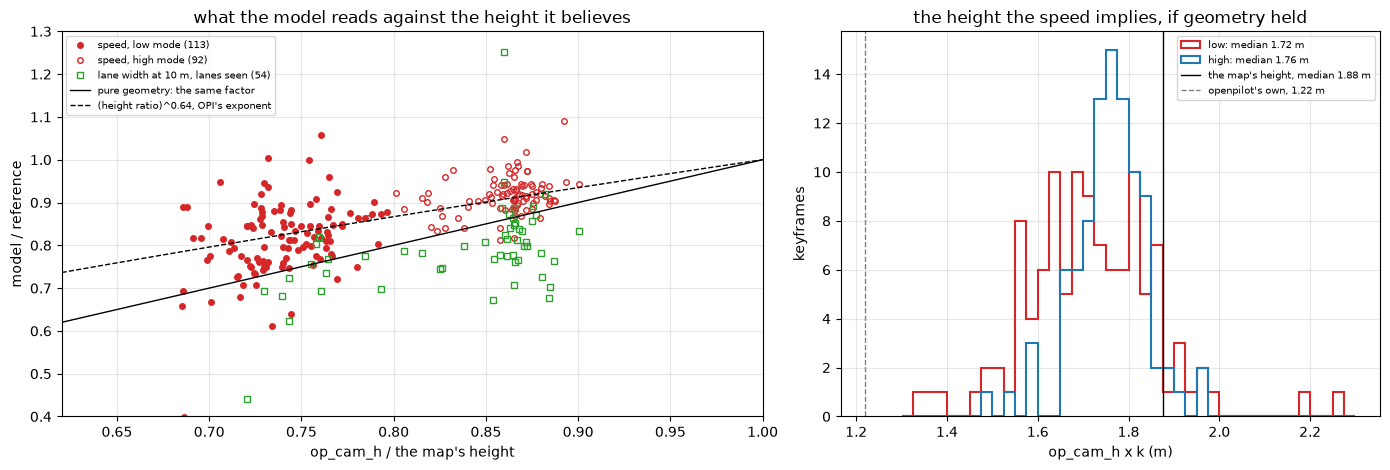

,n,elasticity,CI lo,CI hi
speed,205,0.682,0.621,0.750
lane width,54,1.332,1.160,1.536


,n,op_cam_h,the map's height (m),height ratio,speed ratio,lanes seen,lane width ratio,k,implied height (m),"s*, exponent 1","s*, exponent 0.64"
mode,,,,,,,,,,,
low,113,1.392,1.880,0.740,0.817,13,0.725,1.224,1.717,1.224,1.372
high,92,1.625,1.873,0.865,0.915,41,0.807,1.093,1.759,1.093,1.149


In [34]:
def height_speed(df=None, start=None, kh=None, exponent=0.64):
    """The speed and the lateral scale the model reads, against the camera height it believes.

    A camera believed at h but really at h_true scales every road-plane distance it reconstructs by
    h / h_true: pure geometry says the lane width and the speed both read low by that factor. OPI measured
    the speed responding to the height knob as s^0.64 instead (the dashed line).
    """
    df, kh = (T if df is None else df), (KH if kh is None else kh)
    start = START if start is None else start
    h_true = kh.map_h_m.fillna(df.ctx_height_ring_front_m)  # the map's, at the keyframe or the scene's
    with np.errstate(invalid="ignore", divide="ignore"):
        k = (start.pose / start.pose_head).where(start.pose >= P["v_go"])
        lw = (df.op_lane_width_m / kh.map_lane_width_m).where(df.lanes != "none")
    x = pd.DataFrame(
        {
            "height_ratio": df.op_cam_h / h_true,
            "speed_ratio": 1 / k,
            "lane_w_ratio": lw,  # not the tags file's lane_width_ratio: this one is per keyframe, at 10 m
            "k": k,
            "op_cam_h": df.op_cam_h,
            "h_true": h_true,
            "implied_h": df.op_cam_h * k,
            "mode": CAM_H_MODE,
            "scene": df.scene,
        }
    ).dropna(subset=["k", "op_cam_h", "h_true"])
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    for mode, style in (("low", dict(color="tab:red")), ("high", dict(mfc="none", color="tab:red"))):
        sel = x["mode"] == mode
        ax.plot(
            x.height_ratio[sel],
            x.speed_ratio[sel],
            "o",
            ms=4,
            **style,
            label=f"speed, {mode} mode ({int(sel.sum())})",
        )
    sel = x.lane_w_ratio.notna()
    ax.plot(
        x.height_ratio[sel],
        x.lane_w_ratio[sel],
        "s",
        ms=4,
        mfc="none",
        color="tab:green",
        label=f"lane width at 10 m, lanes seen ({int(sel.sum())})",
    )
    r = np.linspace(0.62, 1.0, 50)
    ax.plot(r, r, "k-", lw=1, label="pure geometry: the same factor")
    ax.plot(r, r**exponent, "k--", lw=1, label=f"(height ratio)^{exponent:g}, OPI's exponent")
    ax.set(
        xlim=(0.62, 1.0),
        ylim=(0.4, 1.3),
        xlabel="op_cam_h / the map's height",
        ylabel="model / reference",
        title="what the model reads against the height it believes",
    )
    ax.legend(fontsize=7, loc="upper left")
    ax = axes[1]
    edges = np.linspace(1.3, 2.3, 41)
    for mode, color in (("low", "tab:red"), ("high", "tab:blue")):
        v = x.implied_h[x["mode"] == mode]
        ax.hist(v, edges, histtype="step", lw=1.5, color=color, label=f"{mode}: median {v.median():.2f} m")
    ax.axvline(
        x.h_true.median(), color="k", lw=1, label=f"the map's height, median {x.h_true.median():.2f} m"
    )
    ax.axvline(HEIGHT_INIT_M, color="grey", ls="--", lw=1, label=f"openpilot's own, {HEIGHT_INIT_M} m")
    ax.set(
        xlabel="op_cam_h x k (m)", ylabel="keyframes", title="the height the speed implies, if geometry held"
    )
    ax.legend(fontsize=7)
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    return x


def elasticity(x, col, n_boot=2000, seed=None):
    """log(col) against log(height_ratio), fitted through (1, 1), where a right height reads right; 95% CI
    resampling scenes. 1 is pure geometry; a cross-section, not a counterfactual (§15 B moves the height)."""
    seed = SEED if seed is None else seed
    x = x.dropna(subset=[col])
    u, v, scenes = np.log(x.height_ratio).to_numpy(), np.log(x[col]).to_numpy(), x.scene.to_numpy()
    if not len(u):  # FOCUS may leave no keyframe with this reading
        return 0, np.nan, np.nan, np.nan

    def fit(i):
        return (u[i] * v[i]).sum() / (u[i] ** 2).sum()

    boot = [fit(d) for d in _scene_draws(scenes, n_boot, seed)]
    return len(u), fit(np.arange(len(u))), *np.percentile(boot, [2.5, 97.5])


HS = height_speed()
display(
    pd.DataFrame(
        [elasticity(HS, c) for c in ("speed_ratio", "lane_w_ratio")],
        index=["speed", "lane width"],
        columns=["n", "elasticity", "CI lo", "CI hi"],
    ).round(3)
)
_g = HS.groupby("mode")
display(
    pd.DataFrame(
        {
            "n": _g.size(),
            "op_cam_h": _g.op_cam_h.median(),
            "the map's height (m)": _g.h_true.median(),
            "height ratio": _g.height_ratio.median(),
            "speed ratio": _g.speed_ratio.median(),
            "lanes seen": _g.lane_w_ratio.count(),
            "lane width ratio": _g.lane_w_ratio.median(),
            "k": _g.k.median(),
            "implied height (m)": _g.implied_h.median(),
            # the knob that would read the speed right, from this run alone: if the head moved as s^1 or s^0.64
            "s*, exponent 1": _g.k.median(),
            "s*, exponent 0.64": _g.k.median() ** (1 / 0.64),
        }
    )
    .reindex(["low", "high"])
    .dropna(how="all")
    .round(3)
)

### B What the height sweep measures

`PADDOCK_OPENPILOT_HEIGHT_SCALE = s` scales the model ray's downward component by s in the warp, so the road plane shows as it would from a camera at h / s:
- the horizon stays where it is;
- a road-plane distance reads as from that lower camera;
- a vertical object looks 1/s as tall.

So the knob measures what the model makes of road geometry. It does not correct the camera.

**The sweep points:**
- s = 1.15 and 1.30 bracket OPI's two crossings: a speed ratio of 1 near s ≈ 1.27, and zero longitudinal error at 3 s near 1.2.
- s = 1.53 shows the road as from openpilot's own 1.22 m, which reproduces OPI's E5c. OPI rejected it.
- Each point is a `--limit 60` run over the first 60 keyframes by (scene, keyframe). Being a subset, each is `valid: false`, which keeps it out of `paddock report`.
- The s = 1 point is asserted to equal the baseline on those 60 keyframes.

**What this section computes:**
- `sweep_table()` has one row per keyframe and s. It holds:
    - the speed ratios: `v_ratio` (the head's), `v0_ratio` (the plan's own start) and `step_ratio` (the first points);
    - `op_cam_h` and the lane width;
    - the scores.

  `mode` is the keyframe's `cam_h_read` at s = 1, whatever it reads at other points.
- **The exponents:** a in reading ∝ s^a, fitted per keyframe over the sweep.
    - Geometry through the height the road head reads predicts that a road-plane reading scales as s · `op_cam_h`(s) / h, so its exponent would be 1 + `op_cam_h`'s.
    - A road head that followed the image, reading h / s, would leave the speed where it was.
- `sweep_plot()` plots each reading against s: every keyframe as a thin line, and the median per mode as a thick one.
- `STAR` and `star_summary()`: per keyframe, the s at which each reading is right (s*).
    - s* is interpolated linearly in log s between the two sweep points that bracket it. It reads `< 1` or `> 1.53` when the sweep does not bracket it.
    - The median per group gets a CI from resampling scenes, except in groups of fewer than 5 scenes.
    - The camera height shown at s* is the map's height / s*.
- `sweep_scores()` and `sweep_scores_plot()` give, at each s: ADE, FDE@3s, the signed along-track error at 3 s, and the lateral MAE. Each comes with its change from s = 1, paired by keyframe, and a CI from resampling scenes.
- `fixes()` compares ADE with the start speed fixed three ways, against a bound:
    - in the image: the knob;
    - in the output: the plan rescaled by pose speed / head speed, which is §4's `k_speed` and something a car could do from odometry;
    - both;
    - the bound: the plan rescaled to the GT's first step.

In [35]:
def sweep_table(sweep=None, df=None, start=None):
    """One row per keyframe and height scale in the sweep: what the model read, and how its plan scored."""
    sweep, df = (SWEEP_IDS if sweep is None else sweep), (T if df is None else df)
    start = START if start is None else start
    rows = []
    for s, rid in sorted(sweep.items()):
        R, plan = readings(rid, df)
        have = R.op_v.notna().to_numpy()
        along = split(plan, GT_RAW[df.index], n3)[0][:, -1]  # signed, ahead positive, at EVAL_H
        with np.errstate(invalid="ignore", divide="ignore"):
            rows.append(
                pd.DataFrame(
                    {
                        "s": s,
                        "sample_id": df.sample_id,
                        "scene": df.scene,
                        "mode": CAM_H_MODE,  # cam_h_read at s = 1 (§14): the keyframe's, not the sweep point's
                        "rig": df.scene.map(CAMS.rig),
                        "h_true": HS.h_true.reindex(df.index),
                        "moving": start.pose >= P["v_go"],
                        "v_ratio": R.op_v / start.pose,  # pose head / poses: 1 is the right speed at t = 0
                        "v0_ratio": R.op_plan_v0 / start.pose,  # the plan's own start speed / poses
                        "step_ratio": np.linalg.norm(plan[:, 0], axis=-1)
                        / DT
                        / start.gt_step,  # first points
                        "op_cam_h": R.op_cam_h,
                        "op_lane_width_m": R.op_lane_width_m,
                        "ade": R.rec_ade,
                        "fde_3s": R.rec_fde_3s,
                        "along_3s": along,
                        "lateral_mae": R.rec_lateral_mae,
                    },
                    index=df.index,
                )[have]
            )
    return pd.concat(rows).rename_axis("row").reset_index()


def crossing(g, col, target=1.0, log=True):
    """The s at which col reaches target along one keyframe's sweep: linear in log s (and in log col if
    log), first crossing; -inf or inf when every point is above or below it."""
    g = g.sort_values("s")
    u = np.log(g.s.to_numpy())
    v = (np.log(g[col]) - np.log(target) if log else g[col] - target).to_numpy()
    ok = np.isfinite(v)
    u, v = u[ok], v[ok]
    if len(v) < 2:
        return np.nan
    for j in range(len(v) - 1):
        if v[j] == 0:
            return float(np.exp(u[j]))
        if v[j] * v[j + 1] < 0:
            return float(np.exp(u[j] + (u[j + 1] - u[j]) * -v[j] / (v[j + 1] - v[j])))
    if v[-1] == 0:
        return float(np.exp(u[-1]))
    return -np.inf if (v > 0).all() else np.inf  # right already below the lowest s, or not yet at the highest


SW = sweep_table()
# the sweep's s = 1 point must be the baseline itself on its keyframes, or no other point compares with it
_one = readings(SWEEP_IDS[1.0])
_have = _one[0].op_v.notna().to_numpy()
assert np.array_equal(_one[1][_have], PRED[T.index][_have], equal_nan=True), (
    "the s = 1 run's plans differ from RUN's"
)
for c in ("op_v", "op_cam_h", "op_plan_v0"):
    assert np.array_equal(_one[0][c][_have].to_numpy(float), T[c][_have].to_numpy(float), equal_nan=True), c
_scales = sorted(SW.s.unique())
print(
    f"sweep: s = {', '.join(f'{s:g}' for s in _scales)} on the same {SW.row.nunique()} keyframes "
    f"({SW.scene.nunique()} scenes; {', '.join(f'{n} {m}' for m, n in SW[SW.s == 1].groupby('mode').size().items())}); "
    f"the s = 1 run equals RUN on all {int(_have.sum())}"
)
assert SW.groupby("s").row.apply(frozenset).nunique() <= 1, "the sweep points are not all the same keyframes"
# A FOCUS may hold none of the sweep's keyframes (the first 60), or none of them moving. Part B then has
# nothing to measure, and §16 has no image-calibrated plan to draw.
SWEPT = bool(SW.moving.any())

if SWEPT:
    # response exponents: d log(reading) / d log s, fitted per keyframe over the sweep
    _exp = (
        SW[SW.moving]
        .groupby("row")
        .apply(
            lambda g: pd.Series(
                {
                    c: np.polyfit(np.log(g.s), np.log(g[c]), 1)[0] if g[c].gt(0).all() else np.nan
                    for c in ("v_ratio", "step_ratio", "op_cam_h", "op_lane_width_m")
                }
            ),
            include_groups=False,
        )
    )
    # Geometry through the height the road head reads: a road-plane reading scales as s * op_cam_h(s) / h, so
    # its exponent would be 1 + op_cam_h's. A head whose height followed the image (h / s) would not move at all.
    _exp["geometry: 1 + op_cam_h's"] = 1 + _exp.op_cam_h
    _exp["v_ratio - geometry"] = _exp.v_ratio - _exp["geometry: 1 + op_cam_h's"]
    _exp["mode"] = CAM_H_MODE.reindex(_exp.index)
    _ex = pd.concat([_exp.assign(mode="all"), _exp]).groupby("mode")
    print(
        "how each reading responds to the knob: median exponent a in reading ~ s^a, per keyframe (moving ones)"
    )
    display(_ex.median().round(3).assign(n=_ex.size()).reindex(["all", "low", "high"]).dropna(how="all"))
else:
    print("FOCUS holds none of the sweep's moving keyframes: part B has nothing to show")

sweep: s = 1, 1.15, 1.3, 1.53 on the same 60 keyframes (37 scenes; 26 high, 34 low); the s = 1 run equals RUN on all 60
how each reading responds to the knob: median exponent a in reading ~ s^a, per keyframe (moving ones)


,v_ratio,step_ratio,op_cam_h,op_lane_width_m,geometry: 1 + op_cam_h's,v_ratio - geometry,n
mode,,,,,,,
all,0.542,0.561,-0.234,0.413,0.766,-0.167,54
low,0.713,0.654,-0.055,0.527,0.945,-0.190,28
high,0.430,0.432,-0.398,0.324,0.602,-0.156,26


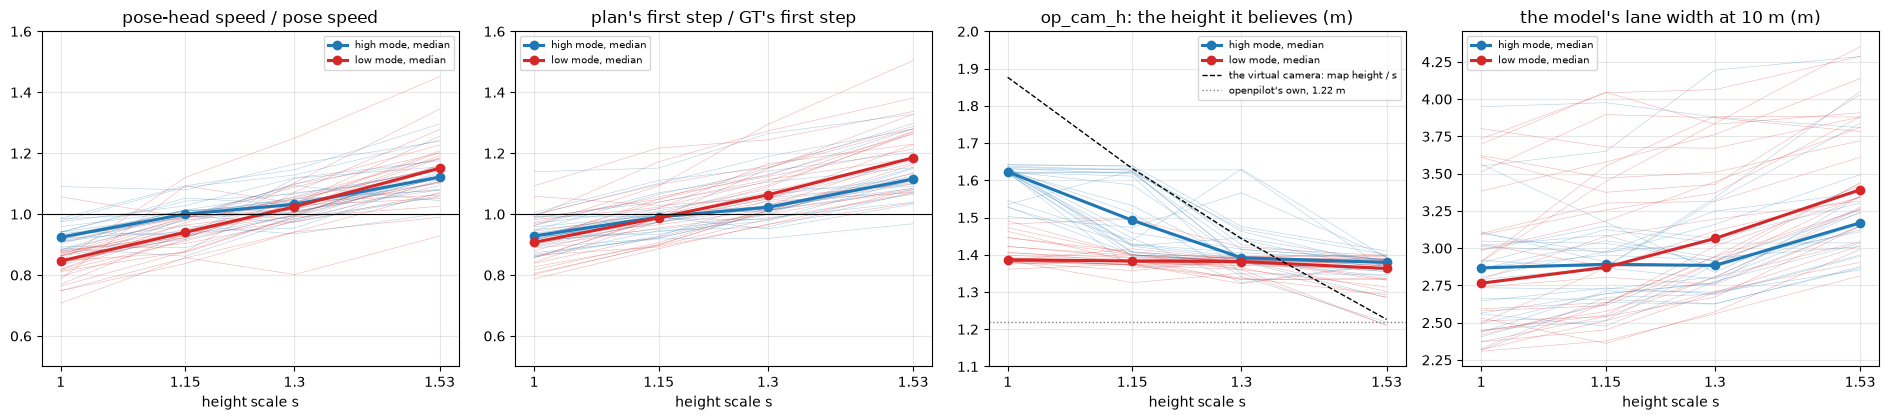

In [36]:
def sweep_plot(sw=None):
    """What the model reads at each height scale, per keyframe (thin) and the median per mode (thick)."""
    sw = SW if sw is None else sw
    m = sw[sw.moving]
    cols = [
        ("v_ratio", "pose-head speed / pose speed", 1.0),
        ("step_ratio", "plan's first step / GT's first step", 1.0),
        ("op_cam_h", "op_cam_h: the height it believes (m)", None),
        ("op_lane_width_m", "the model's lane width at 10 m (m)", None),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
    colors = {"low": "tab:red", "high": "tab:blue"}
    for ax, (c, label, ref) in zip(axes, cols):
        for row, g in m.groupby("row"):
            ax.plot(g.s, g[c], color=colors.get(g["mode"].iat[0], "grey"), lw=0.4, alpha=0.35)
        for mode, g in m.groupby("mode"):
            if mode in colors:
                med = g.groupby("s")[c].median()
                ax.plot(med.index, med.values, "o-", color=colors[mode], lw=2.2, label=f"{mode} mode, median")
        if ref is not None:
            ax.axhline(ref, color="k", lw=0.8)
        if c == "op_cam_h":
            hh = m.groupby("s").h_true.median()
            ax.plot(hh.index, hh.values / hh.index, "k--", lw=1, label="the virtual camera: map height / s")
            ax.axhline(HEIGHT_INIT_M, color="grey", ls=":", lw=1, label=f"openpilot's own, {HEIGHT_INIT_M} m")
            ax.set_ylim(1.1, 2.0)
        ax.set_xscale("log")
        ax.set_xticks(_scales, [f"{s:g}" for s in _scales])
        ax.minorticks_off()
        ax.set(xlabel="height scale s", title=label)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    axes[0].set_ylim(0.5, 1.6)
    axes[1].set_ylim(0.5, 1.6)
    fig.tight_layout()
    plt.show()


if SWEPT:
    sweep_plot()

In [37]:
# per keyframe, the height scale at which each reading is right: interpolated between sweep points
_m = SW[SW.moving]
if SWEPT:
    STAR = pd.DataFrame(
        {
            "speed": _m.groupby("row").apply(lambda g: crossing(g, "v_ratio"), include_groups=False),
            "first step": _m.groupby("row").apply(lambda g: crossing(g, "step_ratio"), include_groups=False),
            "along_3s": _m.groupby("row").apply(
                lambda g: crossing(g, "along_3s", 0.0, log=False), include_groups=False
            ),
        }
    )
else:  # none to cross: §16 reads every keyframe as off the sweep
    STAR = pd.DataFrame(columns=["speed", "first step", "along_3s"], dtype=float)
STAR["mode"] = CAM_H_MODE.reindex(STAR.index)
STAR["rig"] = T.scene.map(CAMS.rig).reindex(STAR.index)
STAR["scene"] = T.scene.reindex(STAR.index)
STAR["h_true"] = HS.h_true.reindex(STAR.index)
STAR_TARGETS = {
    "speed": "the pose head reads the poses' speed at t = 0 (the < and > markers meet)",
    "first step": "the plan's first point is the GT's (the first two points of the speed panel meet)",
    "along_3s": "the plan is neither ahead nor behind the GT at 3 s",
}


def _median(v):
    """The lower middle value: an order statistic, so it stays defined when some s* are censored (+-inf)."""
    return np.quantile(v, 0.5, method="inverted_cdf") if len(v) else np.nan


def _bound(v):
    """s* as text: a censored one (+-inf) as the end of the sweep it falls beyond, NaN (no keyframes) as ""."""
    if np.isnan(v):
        return ""
    return f"{v:.3f}" if np.isfinite(v) else f"< {_scales[0]:g}" if v < 0 else f"> {_scales[-1]:g}"


def star_summary(star=None, n_boot=2000, seed=None, min_scenes=5):
    """Per group and target: the median s*, its 95% CI resampling scenes (none under min_scenes scenes), how
    many keyframes the sweep's range brackets, and the camera height the image shows at s* (the map's / s*)."""
    star, seed = (STAR if star is None else star), (SEED if seed is None else seed)
    rows = []
    groups = [("all", star), *star.groupby("mode"), *((f"rig {r}", g) for r, g in star.groupby("rig"))]
    for name, g in groups:
        draws = list(_scene_draws(g.scene.to_numpy(), n_boot, seed))
        for c in STAR_TARGETS:
            v = g[c].to_numpy(float)
            boot = np.array([_median(v[d]) for d in draws])
            lo, hi = np.quantile(boot, [0.025, 0.975], method="inverted_cdf")
            few = g.scene.nunique() < min_scenes
            virtual = (g.h_true / g[c])[np.isfinite(g[c])]
            rows.append(
                {
                    "group": name,
                    "target": c,
                    "n": len(v),
                    "scenes": g.scene.nunique(),
                    "median s*": _bound(_median(v)),
                    "CI lo": "" if few else _bound(lo),
                    "CI hi": "" if few else _bound(hi),
                    "below / in / above": f"{int((v == -np.inf).sum())} / {int(np.isfinite(v).sum())} / {int((v == np.inf).sum())}",
                    "camera height shown at s*, median (m)": round(virtual.median(), 3),
                }
            )
    return pd.DataFrame(rows).set_index(["group", "target"])


if SWEPT:
    print(
        f"s*: the height scale at which each reading is right, per moving keyframe; below / in / above: s* under "
        f"{_scales[0]:g}, between, over {_scales[-1]:g}\n"
        + "\n".join(f"  {c}: {doc}" for c, doc in STAR_TARGETS.items())
    )
    display(star_summary())

s*: the height scale at which each reading is right, per moving keyframe; below / in / above: s* under 1, between, over 1.53
  speed: the pose head reads the poses' speed at t = 0 (the < and > markers meet)
  first step: the plan's first point is the GT's (the first two points of the speed panel meet)
  along_3s: the plan is neither ahead nor behind the GT at 3 s


n  scenes median s*  CI lo  CI hi  \
group        target                                           
all          speed       54      35     1.219  1.169  1.258   
             first step  54      35     1.184  1.119  1.217   
             along_3s    54      35     1.190  1.137  1.284   
high         speed       26      20     1.142  1.122  1.211   
             first step  26      20     1.191  1.093  1.242   
             along_3s    26      20     1.238  1.137  1.328   
low          speed       28      18     1.253  1.219  1.301   
             first step  28      18     1.163  1.065  1.209   
             along_3s    28      18     1.152  1.116  1.278   
rig 53df1231 speed       41      28     1.238  1.169  1.301   
             first step  41      28     1.198  1.148  1.254   
             along_3s    41      28     1.238  1.142  1.330   
rig 901dfe25 speed        9       6     1.199  1.156  1.254   
             first step   9       6     1.169  1.033  1.198   
             along_3s     9       6     1.190  1.145  1.286   
rig dbb25dcf speed        4       1     1.087                 
             first step   4       1       < 1                 
             along_3s     4       1       < 1                 

                        below / in / above  \
group        target                          
all          speed              1 / 51 / 2   
             first step         4 / 49 / 1   
             along_3s          12 / 37 / 5   
high         speed              1 / 25 / 0   
             first step         2 / 23 / 1   
             along_3s           5 / 19 / 2   
low          speed              0 / 26 / 2   
             first step         2 / 26 / 0   
             along_3s           7 / 18 / 3   
rig 53df1231 speed              1 / 38 / 2   
             first step         2 / 38 / 1   
             along_3s           7 / 30 / 4   
rig 901dfe25 speed               0 / 9 / 0   
             first step          0 / 9 / 0   
             along_3s            1 / 7 / 1   
rig dbb25dcf speed               0 / 4 / 0   
             first step          2 / 2 / 0   
             along_3s            4 / 0 / 0   

                         camera height shown at s*, median (m)  
group        target                                             
all          speed                                       1.555  
             first step                                  1.587  
             along_3s                                    1.515  
high         speed                                       1.611  
             first step                                  1.551  
             along_3s                                    1.439  
low          speed                                       1.527  
             first step                                  1.603  
             along_3s                                    1.592  
rig 53df1231 speed                                       1.541  
             first step                                  1.569  
             along_3s                                    1.512  
rig 901dfe25 speed                                       1.541  
             first step                                  1.587  
             along_3s                                    1.575  
rig dbb25dcf speed                                       1.766  
             first step                                  1.870  
             along_3s                                      NaN

the plan's scores at each height scale on the sweep's keyframes (m); along_3s is signed, ahead positive


,,mean,median,change from s = 1,CI lo,CI hi,better on
metric,s,,,,,,
ade,1.00,1.442,1.268,NaN,NaN,NaN,NaN
fde_3s,1.00,2.655,2.439,NaN,NaN,NaN,NaN
along_3s,1.00,-1.834,-1.998,NaN,NaN,NaN,NaN
lateral_mae,1.00,0.304,0.204,NaN,NaN,NaN,NaN
ade,1.15,0.973,0.835,-0.469,-0.758,-0.189,45 of 60
fde_3s,1.15,1.867,1.662,-0.787,-1.297,-0.304,46 of 60
along_3s,1.15,-0.345,-0.201,1.489,1.196,1.839,47 of 60
lateral_mae,1.15,0.309,0.212,0.005,-0.040,0.049,30 of 60
ade,1.30,1.035,0.888,-0.407,-0.886,0.001,41 of 60


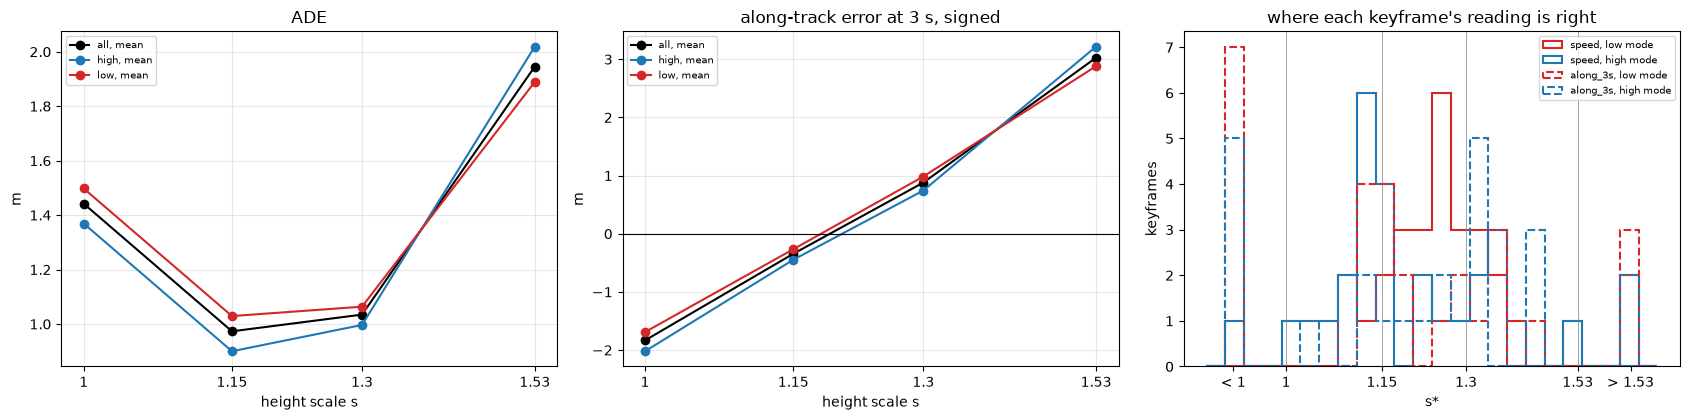

In [38]:
def sweep_scores(sw=None, n_boot=2000, seed=None):
    """The plan's scores at each height scale: means with 95% CIs resampling scenes, and medians."""
    sw, seed = (SW if sw is None else sw), (SEED if seed is None else seed)
    base = sw[sw.s == 1.0].set_index("row")
    rows = []
    for s, g in sw.groupby("s"):
        g = g.set_index("row")
        draws = list(_scene_draws(g.scene.to_numpy(), n_boot, seed))
        for c in ("ade", "fde_3s", "along_3s", "lateral_mae"):
            v = g[c].to_numpy(float)
            d = v - base[c].reindex(g.index).to_numpy(float)  # paired with s = 1
            boot = np.array([np.nanmean(d[i]) for i in draws])
            rows.append(
                {
                    "s": s,
                    "metric": c,
                    "mean": np.nanmean(v),
                    "median": np.nanmedian(v),
                    "change from s = 1": np.nanmean(d),
                    "CI lo": np.percentile(boot, 2.5),
                    "CI hi": np.percentile(boot, 97.5),
                    "better on": f"{int((np.abs(v) < np.abs(base[c].reindex(g.index).to_numpy(float))).sum())} of {int(np.isfinite(d).sum())}",
                }
            )
    out = pd.DataFrame(rows).set_index(["metric", "s"])
    out.loc[out.index.get_level_values("s") == 1.0, ["change from s = 1", "CI lo", "CI hi", "better on"]] = (
        np.nan
    )
    return out


if SWEPT:
    SWEEP_SCORES = sweep_scores()
    print(
        "the plan's scores at each height scale on the sweep's keyframes (m); along_3s is signed, ahead positive"
    )
    display(SWEEP_SCORES.round(3))


def sweep_scores_plot(sw=None, star=None):
    """ADE and the signed along-track error at 3 s against s, per mode; and where s* falls."""
    sw, star = (SW if sw is None else sw), (STAR if star is None else star)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
    colors = {"all": "k", "low": "tab:red", "high": "tab:blue"}
    for ax, c in zip(axes[:2], ("ade", "along_3s")):
        for mode, g in [("all", sw), *sw.groupby("mode")]:
            if mode in colors:
                mean = g.groupby("s")[c].mean()
                ax.plot(mean.index, mean.values, "o-", color=colors[mode], label=f"{mode}, mean")
        ax.set_xscale("log")
        ax.set_xticks(_scales, [f"{s:g}" for s in _scales])
        ax.minorticks_off()
        ax.set(
            xlabel="height scale s",
            ylabel="m",
            title={"ade": "ADE", "along_3s": "along-track error at 3 s, signed"}[c],
        )
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    axes[1].axhline(0, color="k", lw=0.8)
    ax = axes[2]
    below, above = _scales[0] / 1.08, _scales[-1] * 1.08  # where the censored s* are drawn
    edges = np.exp(np.linspace(np.log(below / 1.04), np.log(above * 1.04), 25))
    for c, style in (("speed", "-"), ("along_3s", "--")):
        for mode in ("low", "high"):
            v = star[c][star["mode"] == mode].replace({-np.inf: below, np.inf: above})
            ax.hist(
                v, edges, histtype="step", ls=style, lw=1.5, color=colors[mode], label=f"{c}, {mode} mode"
            )
    for s in _scales:
        ax.axvline(s, color="grey", lw=0.5)
    ax.set_xscale("log")
    ax.set_xticks(
        [below, *_scales, above], [f"< {_scales[0]:g}", *(f"{s:g}" for s in _scales), f"> {_scales[-1]:g}"]
    )
    ax.minorticks_off()
    ax.set(xlabel="s*", ylabel="keyframes", title="where each keyframe's reading is right")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()


if SWEPT:
    sweep_scores_plot()

In [39]:
def _ade(pred, gt, n=n3):
    """ADE over the first n waypoints, or as many as the GT has: the recorded ade's definition."""
    err = np.linalg.norm(pred[:, :n] - gt[:, :n], axis=-1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # a GT with no point at all: NaN
        return np.nanmean(err, axis=1)


def fixes(sweep=None, df=None):
    """Mean and median ADE on the sweep's keyframes, the start speed fixed in the image, the output or both.

    The output fix rescales the plan by pose / head speed (k_speed, §4): the deployable one, since odometry
    knows the speed. The GT's first step (k_oracle) is the bound no calibration of the start speed can pass.
    """
    sweep, df = (SWEEP_IDS if sweep is None else sweep), (T if df is None else df)
    rows = SW[SW.s == 1.0].row.to_numpy()  # df's labels, which are also PRED's and GT_RAW's rows
    pos = df.index.get_indexer(rows)  # where readings() puts them
    gt = GT_RAW[rows]
    assert np.allclose(_ade(PRED[rows], gt), df.rec_ade.loc[rows], equal_nan=True), "not the recorded ADE"
    out = {}
    for s, rid in sorted(sweep.items()):
        R, plan = readings(rid, df)
        with np.errstate(invalid="ignore", divide="ignore"):
            k = np.where(
                R.op_v >= P["v_go"], START.pose.reindex(df.index) / R.op_v, 1.0
            )  # its own head speed
        out[(f"s = {s:g}", "as the model planned")] = _ade(plan[pos], gt)
        out[(f"s = {s:g}", "rescaled by pose / head speed")] = _ade(plan[pos] * k[pos, None, None], gt)
    out[("s = 1", "rescaled by the GT's first step (bound)")] = _ade(
        PRED[rows] * k_oracle[rows, None, None], gt
    )
    t = pd.DataFrame({key: {"mean ADE": v.mean(), "median ADE": np.median(v)} for key, v in out.items()}).T
    return t.rename_axis(["image", "output"])


if SWEPT:
    print(
        f"ADE (m) on the sweep's {SW.row.nunique()} keyframes, the start speed fixed in the image, the output or both"
    )
    display(fixes().round(3))

ADE (m) on the sweep's 60 keyframes, the start speed fixed in the image, the output or both


mean ADE  median ADE
image    output                                                       
s = 1    as the model planned                        1.442       1.268
         rescaled by pose / head speed               0.967       0.748
s = 1.15 as the model planned                        0.973       0.835
         rescaled by pose / head speed               0.882       0.748
s = 1.3  as the model planned                        1.035       0.888
         rescaled by pose / head speed               0.784       0.662
s = 1.53 as the model planned                        1.946       1.813
         rescaled by pose / head speed               0.823       0.750
s = 1    rescaled by the GT's first step (bound)     0.574       0.388

### The answer

Part B is measured on the sweep's 60 keyframes: the 54 at `v_go` or faster, over 35 scenes. The CIs come from resampling scenes.

**Which calibration reads the right speed at t = 0** (measured):
- **The `<` and `>` markers meet at s\* = 1.22 (CI 1.17–1.26).** The image then shows the road as from a camera 1.55 m up. The map puts the camera at 1.88 m, and openpilot's own sits at 1.22 m.
- **The speed panel's first two points meet at 1.18 (1.12–1.22).** The plan is neither ahead of nor behind the GT at 3 s at 1.19 (1.14–1.28).
- **The head needs more in the low mode:** 1.25 (1.22–1.30), against 1.14 (1.12–1.21) in the high mode. The first points do not differ between modes: 1.16 (1.07–1.21) against 1.19 (1.09–1.24). In the low mode the plan starts 5% faster than the head reads (part A), which makes up most of the gap.
- **The rigs agree:** 1.24 (1.17–1.30) on 53df1231 and 1.20 (1.16–1.25) on 901dfe25. dbb25dcf has one scene in the sweep.

**How the model responds to the knob** (measured):
- **The head's speed scales as s^0.54** (the median exponent), and the plan's first step as s^0.56. OPI measured 0.64 with its own pipeline.
- **The road head moves less than the image.** At s = 1.53, the image shows the road as from 1.23 m. There, the road head reads a median 1.38 m, and 1.36 m in the low mode, which reads 1.39 m at s = 1 and barely moves at all.
- **Geometry through the height the road head reads predicts an exponent of 0.77.** The speed responds 0.17 less than that, in both modes (0.19 low, 0.16 high). So the speed is not read through that height alone.

**Argued:** the low mode is the road head at its floor, not a reading of the image. It sits near 1.38 m, where both modes end at s = 1.53, and does not follow the image down.

**Does reading the speed right help the trajectory?** (measured)
- **ADE falls from 1.44 to 0.97 m at s = 1.15:** a change of −0.47 m (CI −0.76 to −0.19), better on 45 of the 60 keyframes.
    - At 1.30 it is 1.03 m.
    - At 1.53, openpilot's own height, it rises to 1.95 m, as OPI's E5c did.
    - The lateral MAE does not move: 0.30 to 0.32 m.
- **The along-track error at 3 s** goes from 1.83 m behind the GT at s = 1, to 0.34 m behind at 1.15, to 0.88 m ahead at 1.30.
- **Fixing the output does as well as fixing the image.**
    - Rescaling the plan by pose speed / head speed (§4's `k_speed`, which a car could compute from odometry) gives an ADE of 0.97 m at s = 1. The knob gives the same at 1.15.
    - The two combine: 0.78 m at s = 1.30 with the rescale.
    - The bound, the plan rescaled to the GT's first step, is 0.57 m.

**So** (argued):
- **Show the road as from about 1.55 m**, the camera's height divided by 1.22. That makes the model read the speed at t = 0 right.
- **It corrects what the model makes of the road, not the camera,** which is 1.88 m up. openpilot's own 1.22 m overshoots: the head reads 12–15% fast there.
- **No full-set run at s\* was made.** s\* is measured on 60 keyframes of the scored set, so a run there would be tuned on the set it is scored on.

## 16 Speed profiles, and what ADE sees

Two questions: what the predicted, calibrated and GT waypoints look like keyframe by keyframe, and whether ADE sees errors in the speed profile.

**The plots.** `speed_profile(key)` draws one keyframe in four panels over the GT's 4 s. ADE's 3 s horizon is dashed.
- **BEV.** Grey connectors join each planned point to the GT's point at the same time. ADE is the mean of their lengths over 3 s.
- **Distance travelled against time.** The gap between two curves is the along-track error.
- **Speed per 0.5 s step.** These steps are the sampled waypoints ADE compares. At t = 0 are the poses' speed (`>`), the pose head's (`<`) and the plan's own (`◇`, `plan_v0`).
- **Error against time:** along-track bold, cross-track faint, with each plan's ADE in the legend.

A calibrated plan is the recorded plan with its start speed corrected. `calib` picks which:
- `pose`: scaled by the poses' speed over the pose head's (§4's `k_speed`). A car could do this, since its odometry knows the speed.
- `oracle`: scaled so its first step is the GT's (§4's `k_oracle`), which makes the start speed exactly right. The audit below uses this one.
- `image`: the plan from the §15 B sweep run nearest the keyframe's s*. Here the start speed is fixed in the image, and the model replans from it. Only the sweep's 60 keyframes have one.

**Sheets and export.**
- `speed_profile_sheet(mode)` is §13's `sheet()` drawn with `speed_profile()`. The saved copy shows one typical keyframe each for too_slow_cruise, under_brakes, under_accelerates and phantom_brake.
- `export_profiles()` writes every keyframe, one page each, to `{runs}/kitscenes/_analysis/openpilot/<run_id>/profiles.pdf` when `EXPORT_PROFILES` (§1) is on.

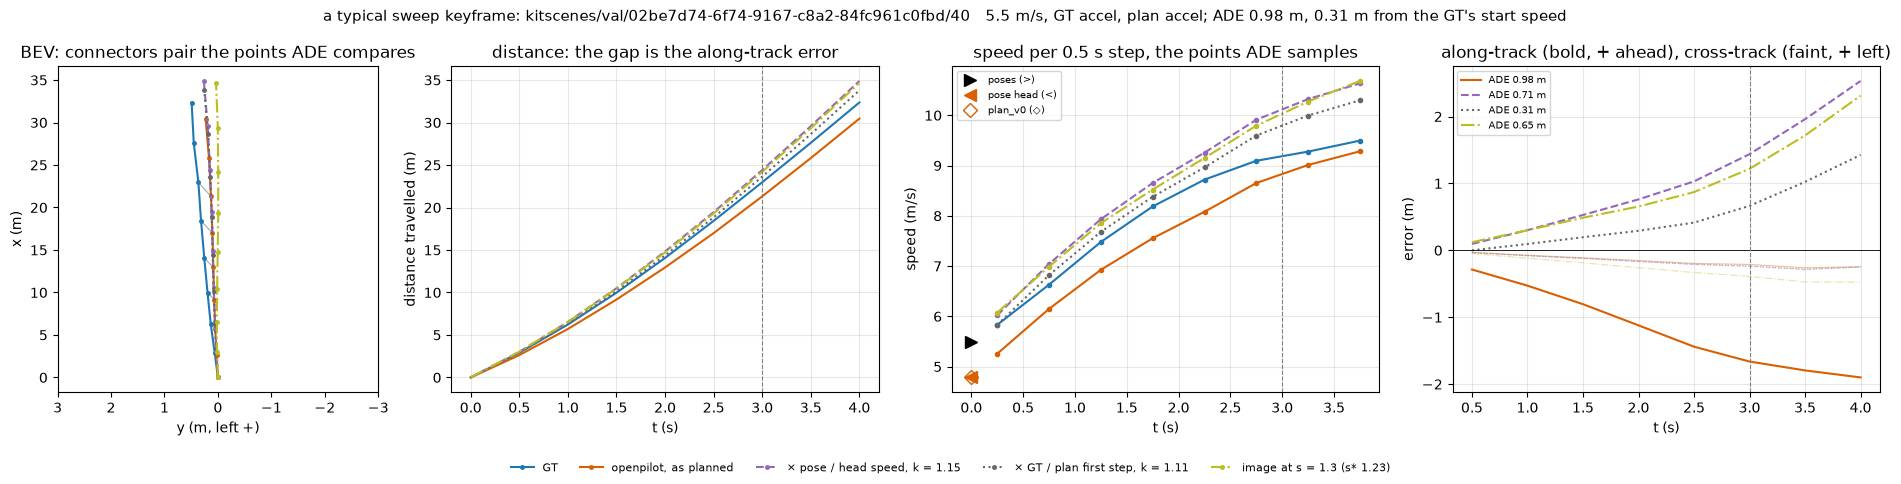

In [40]:
PROFILE_CALIB = {  # each calibrated plan's label, colour and line style
    "pose": ("× pose / head speed", "tab:purple", "--"),
    "oracle": ("× GT / plan first step", "0.4", ":"),
    "image": ("image", "tab:olive", "-."),
}


def _image_plan(i, df):
    """(s, plan): the plan from the sweep run nearest keyframe i's speed s* (§15 B), or None off the sweep."""
    s_star = STAR["speed"].get(i, np.nan)
    if np.isnan(s_star):
        return None
    s = min(_scales, key=lambda x: abs(np.log(x) - np.log(np.clip(s_star, _scales[0], _scales[-1]))))
    return s, readings(SWEEP_IDS[s], df)[1][df.index.get_loc(i)]


def _profile_fig(key, calib=("pose", "oracle", "image"), df=None, title=None):
    """speed_profile()'s figure, not yet drawn, so export_profiles() can save it instead."""
    df = T if df is None else df
    i = _row(key, df)
    r = df.loc[i]
    gt = GT_RAW[i]
    n = int(np.isfinite(gt[:, 0]).sum())  # every plan is drawn over the GT's length: 4 s on kitscenes
    plans = {f"{MODEL}, as planned": (PRED[i], palette.color(MODEL), "-")}
    for c in calib:
        label, color, ls = PROFILE_CALIB[c]
        if c in ("pose", "oracle"):
            k = (k_speed if c == "pose" else k_oracle)[i]
            plans[f"{label}, k = {k:.2f}"] = (PRED[i] * k, color, ls)
        elif (got := _image_plan(i, df)) is not None:
            plans[f"{label} at s = {got[0]:g} (s* {STAR.at[i, 'speed']:.2f})"] = (got[1], color, ls)
    t = np.arange(1, n + 1) * DT
    fig, (ax_b, ax_s, ax_v, ax_e) = plt.subplots(
        1, 4, figsize=(19, 4.8), gridspec_kw={"width_ratios": [0.75, 1, 1, 1]}
    )
    for j in range(min(n3, n)):  # what ADE averages: each point against the GT's at the same time
        ax_b.plot([PRED[i, j, 1], gt[j, 1]], [PRED[i, j, 0], gt[j, 0]], color="0.65", lw=0.8)
    lines = [(gt, palette.GROUND_TRUTH, "-", "GT")] + [
        (xy, c, ls, name) for name, (xy, c, ls) in plans.items()
    ]
    for xy, color, ls, name in lines:
        path = np.vstack([[0.0, 0.0], xy[:n]])
        ax_b.plot(path[:, 1], path[:, 0], ls, marker=".", ms=5, color=color, label=name)
        ax_s.plot(np.r_[0, t], np.r_[0, np.cumsum(_step_speeds(xy[None], n)[0] * DT)], ls, color=color)
        ax_v.plot(t - DT / 2, _step_speeds(xy[None], n)[0], ls, marker=".", ms=6, color=color)
        if name != "GT":
            along, cross = split(xy[None], gt[None], n)
            ade = np.linalg.norm(xy[:n3] - gt[:n3], axis=-1).mean()
            ax_e.plot(t, along[0], ls, color=color, label=f"ADE {ade:.2f} m")
            ax_e.plot(t, cross[0], ls, color=color, lw=0.8, alpha=0.4)
    ax_v.plot(0, r.ref_speed, "k>", ms=8, label="poses (>)")
    ax_v.plot(0, r.op_v, "<", color=palette.color(MODEL), ms=8, label="pose head (<)")
    if np.isfinite(r.op_plan_v0):
        ax_v.plot(0, r.op_plan_v0, "D", mfc="none", color=palette.color(MODEL), ms=7, label="plan_v0 (◇)")
    lim = max(3.0, 1.2 * np.nanmax(np.abs(np.r_[gt[:n, 1], PRED[i, :n, 1]])))
    ax_b.set(
        xlim=(lim, -lim),
        xlabel="y (m, left +)",
        ylabel="x (m)",
        title="BEV: connectors pair the points ADE compares",
    )
    ax_s.set(
        xlabel="t (s)", ylabel="distance travelled (m)", title="distance: the gap is the along-track error"
    )
    ax_v.set(xlabel="t (s)", ylabel="speed (m/s)", title="speed per 0.5 s step, the points ADE samples")
    ax_v.legend(fontsize=7, loc="best")
    ax_e.axhline(0, color="k", lw=0.6)
    ax_e.set(
        xlabel="t (s)", ylabel="error (m)", title="along-track (bold, + ahead), cross-track (faint, + left)"
    )
    ax_e.legend(fontsize=7, loc="best")
    for ax in (ax_s, ax_v, ax_e):
        ax.axvline(EVAL_H, color="grey", ls="--", lw=0.8)
        ax.grid(alpha=0.3)
    fig.suptitle(
        f"{title + ': ' if title else ''}{r.sample_id}   {r.ref_speed:.1f} m/s, GT {r.gt_long}, plan {r.pred_long}; "
        f"ADE {r.ade_H:.2f} m, {r.ade_net_H:.2f} m from the GT's start speed",
        fontsize=11,
    )
    fig.legend(
        *ax_b.get_legend_handles_labels(), loc="lower center", ncol=len(lines), fontsize=8, frameon=False
    )
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    return fig


def speed_profile(key, calib=("pose", "oracle", "image"), df=None, title=None):
    """One keyframe's GT, plan and calibrated plans over the GT's 4 s: BEV, distance, speed and error against time.

    calib picks the calibrated plans: "pose" (§4's k_speed), "oracle" (k_oracle) and "image" (§15 B's sweep, on
    its 60 keyframes only). The dashed line is ADE's horizon.
    """
    _show_photo(
        _profile_fig(key, calib, df, title), quality=70
    )  # line plots: legible at 70, and 3/4 the bytes


def speed_profile_sheet(mode, n_typical=1, n_worst=1, n_random=0, seed=None, df=None, **kw):
    """sheet() drawn with speed_profile(): a failure mode's worst and most typical keyframes, one per scene."""
    return sheet(mode, n_typical, n_worst, n_random, seed, df, draw=speed_profile, **kw)


if len(STAR):  # a FOCUS may hold none of the sweep (§15 B)
    speed_profile(
        STAR.index[np.argmin(np.abs(STAR["speed"] - STAR["speed"].median()))],
        title="a typical sweep keyframe",
    )

fm_too_slow_cruise: 101 keyframes over 77 scenes


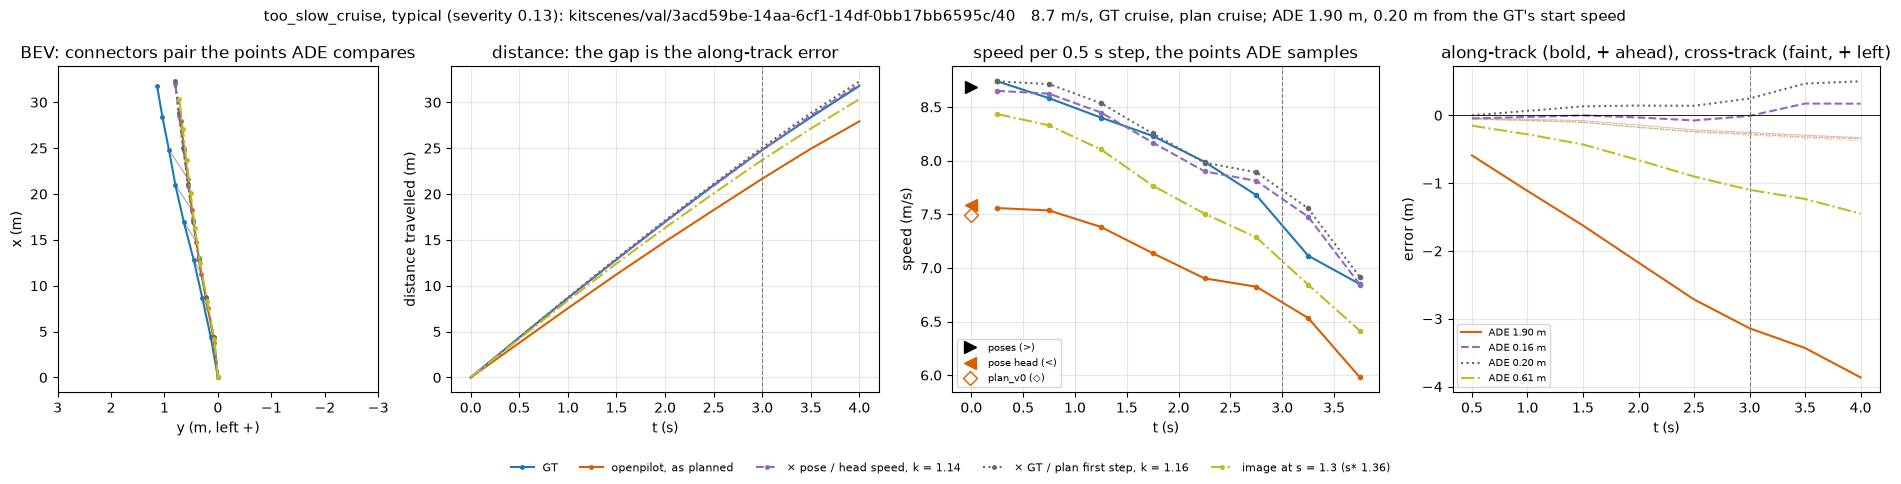

fm_under_brakes: 16 keyframes over 16 scenes


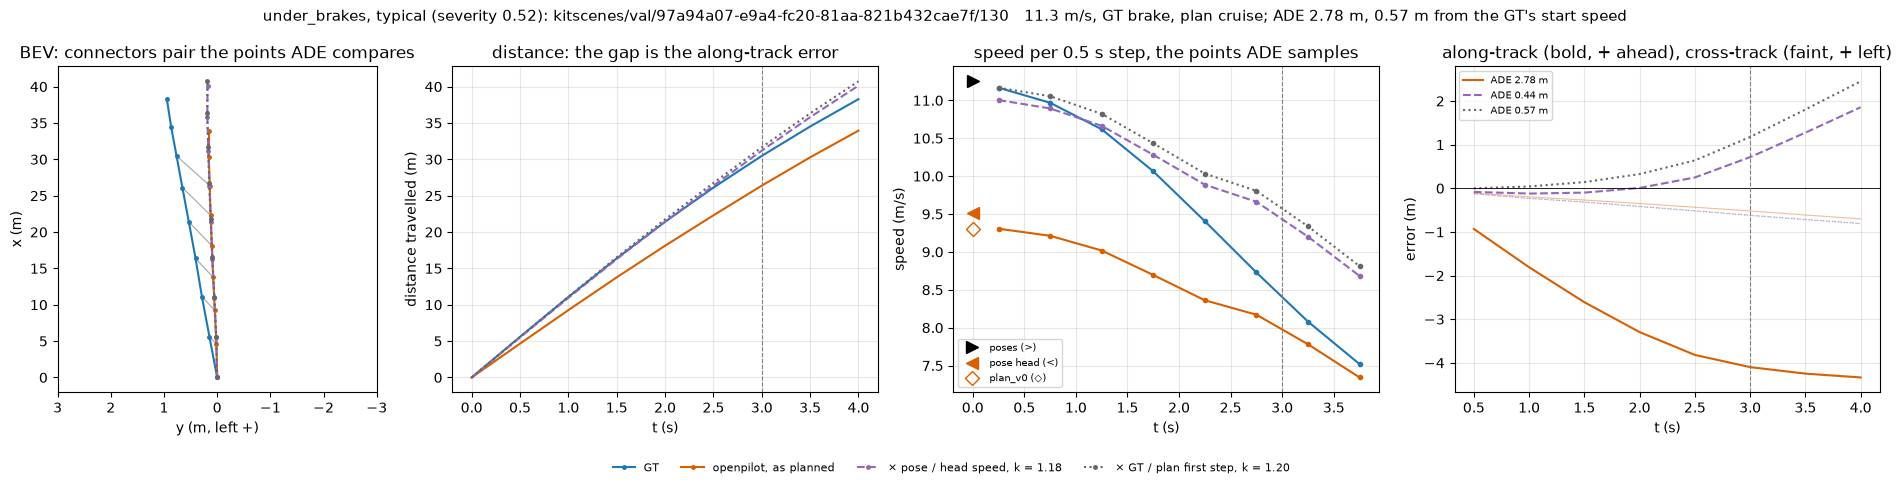

fm_under_accelerates: 17 keyframes over 17 scenes


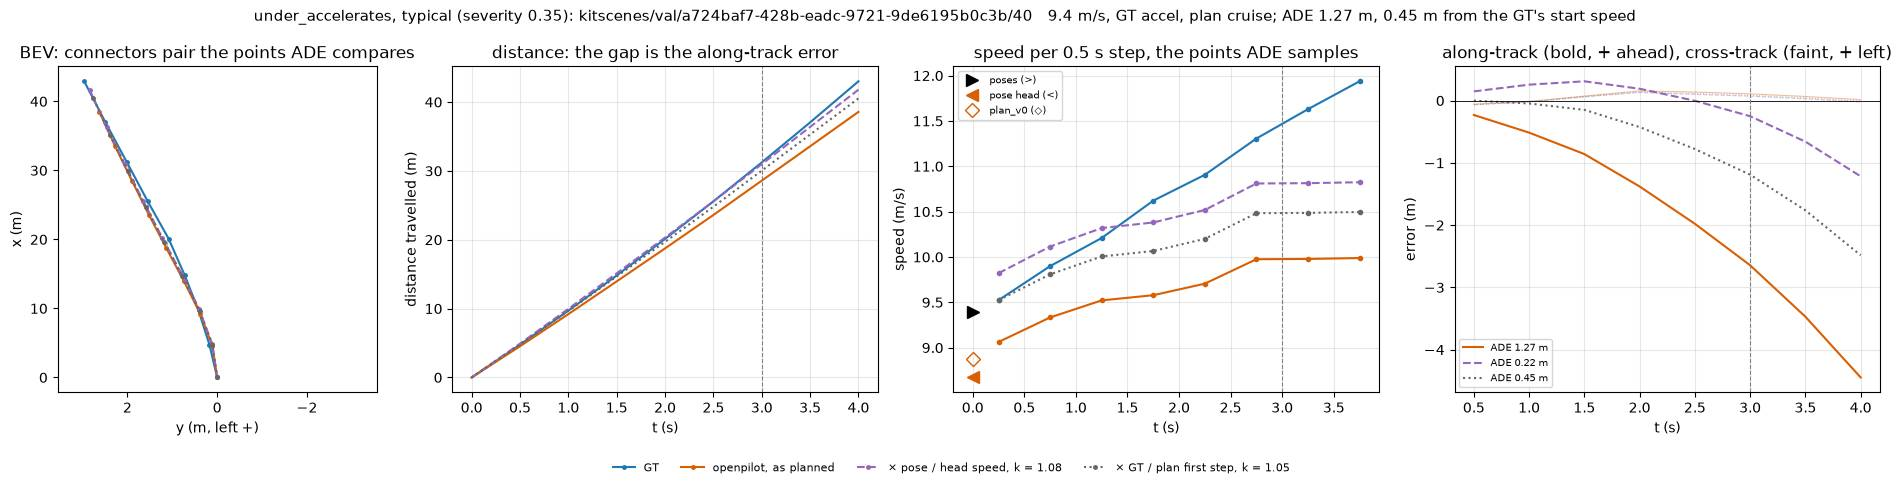

fm_phantom_brake: 16 keyframes over 16 scenes


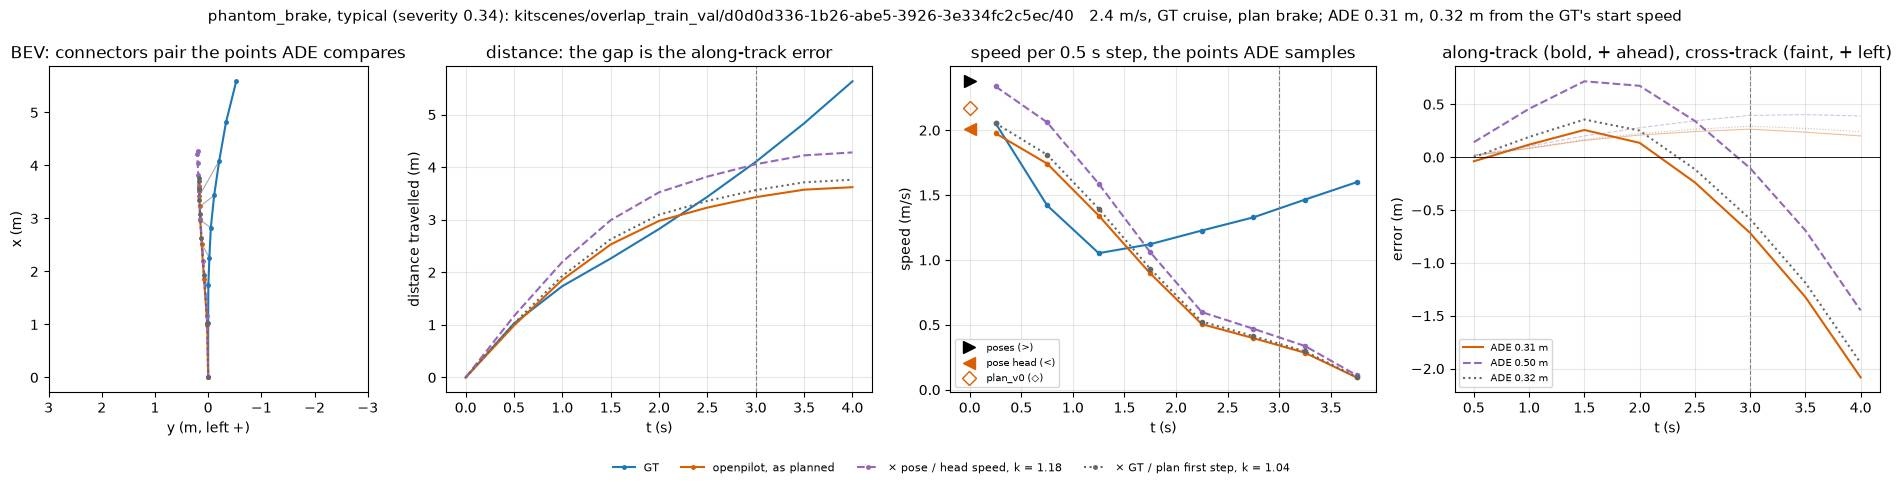

In [41]:
for mode in ("too_slow_cruise", "under_brakes", "under_accelerates", "phantom_brake"):
    speed_profile_sheet(mode, n_typical=1, n_worst=0)

In [42]:
def export_profiles(df=None, calib=("pose", "oracle", "image")):
    """Every keyframe's speed_profile(), one page each by scene and keyframe, to profiles.pdf beside export()'s."""
    df = T if df is None else df
    out = cfg.runs / BENCH / "_analysis" / MODEL / RUN.run_id
    out.mkdir(parents=True, exist_ok=True)
    with PdfPages(out / "profiles.pdf") as pdf:
        for i in df.sort_values(["scene", "keyframe"]).index:
            fig = _profile_fig(i, calib, df)
            pdf.savefig(fig)
            plt.close(fig)
    print(f"wrote {{runs}}/{(out / 'profiles.pdf').relative_to(cfg.runs).as_posix()}: {len(df)} pages")


if EXPORT_PROFILES:
    export_profiles()
else:
    print("EXPORT_PROFILES is off (§1); export_profiles() writes one page per keyframe under {runs}")

EXPORT_PROFILES is off (§1); export_profiles() writes one page per keyframe under {runs}


### What ADE sees

ADE over 3 s is the mean distance between the plan's and the GT's points at the same times.
- A plan that misreads the start speed by Δv and then holds it is Δv · t out at time t.
- Averaged over the six points, that is |Δv| · DT · (n + 1) / 2, or 1.75 s × |Δv|.

The head reads 0.877 of the speed on this run (§4), so ADE carries a large start-speed term.

**New columns.** `features()` now splits that term off:
- `v0_err`: the start speed's error, the plan's first step against the GT's.
- `ade_net_H`: the ADE of the plan rescaled to the GT's start speed (the `oracle` plan above). It is what remains in the speed profile after the start, and in the path.
- `ade_start_H` = `ade_H` − `ade_net_H`: the part the start speed explains. It is negative where setting the start speed right makes ADE worse, i.e. where the misread was offsetting an error of the opposite sign.
- `vprof_rmse`: the speed profile's own error, as the RMSE of the rescaled plan's step speeds against the GT's, after the first step.
- `vprof_rel`: `vprof_rmse` over the larger of the GT's mean speed and `v_go`.

**`ade_audit()`** gives Spearman's ρ between ADE and each of these, over all keyframes (with a CI from resampling scenes) and within thirds of the GT's mean speed.

**`ade_blind_spots()`** lists three groups:
- **inflated:** ADE in the top quarter, but `ade_net_H` below its median. These rank among the worst for their start speed alone.
- **missed:** ADE below its median, but `vprof_rel` in the top quarter. A speed profile that is wrong for its speed yet scores well. The count is checked against chance two ways:
    - with `vprof_rel` permuted over all keyframes;
    - with it permuted within speed thirds. This keeps what dividing by speed builds in: ADE grows with speed, and `vprof_rel` shrinks with it.
- **masked:** `ade_start_H` ≤ −0.1 m. Setting the start speed right raises ADE by at least 0.1 m, so the misread was hiding an error.

Each group is checked against the longitudinal tags:
- the profile tags: under_accelerates, under_brakes, phantom_brake, creep_at_stop, fails_to_launch and misses_stop;
- the level tags: too_slow_cruise and too_fast_cruise.

There is no stop-point error. KITScenes' GT covers 4 s, and only one keyframe comes to a stop from `v_go` within 3 s.

In [43]:
AUDIT_PAIRS = {  # (x, y): what the rank correlation of x with y measures
    ("ade_H", "ade_start_ana"): "ADE against the start speed's error alone, |v0_err| · 1.75 s",
    ("ade_H", "ade_start_H"): "ADE against the part of it the start speed explains",
    ("ade_H", "ade_net_H"): "ADE against the rest",
    ("ade_H", "vprof_rmse"): "ADE against the speed profile's error",
    ("ade_H", "vprof_rel"): "ADE against that error relative to speed",
    ("ade_H", "gt_v_mean"): "ADE against the GT's mean speed",
    ("ade_net_H", "vprof_rmse"): "the rest of ADE against the speed profile's error",
}


THIRDS = ("slowest third", "middle third", "fastest third")  # of the GT's mean speed over H


def _audit_frame(df):
    """df with the analytic start-speed ADE and the GT's mean speed over H."""
    nH = round(P["horizon_s"] / DT)
    return df.assign(ade_start_ana=df.v0_err.abs() * DT * (nH + 1) / 2, gt_v_mean=df.gt_s / (nH * DT))


def _spearman(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(_ranks(a[ok]), _ranks(b[ok]))[0, 1] if ok.sum() > 2 else np.nan


def ade_audit(df=None, n_boot=2000, seed=None):
    """Spearman's ρ of ADE with each part of it: over all keyframes, with a CI from resampling scenes, and by
    thirds of the GT's mean speed."""
    a = _audit_frame(T if df is None else df)
    try:
        third = pd.qcut(a.gt_v_mean, 3, labels=THIRDS).to_numpy()
    except ValueError:  # a FOCUS too small, or too still, to cut in three: no thirds
        third = np.full(len(a), None)
    draws = list(_scene_draws(a.scene.to_numpy(), n_boot, SEED if seed is None else seed))
    rows = {}
    # a FOCUS of 2 keyframes or fewer leaves every ρ NaN, which the table shows: numpy's warnings would add nothing
    with warnings.catch_warnings(action="ignore", category=RuntimeWarning):
        for (x, y), what in AUDIT_PAIRS.items():
            u, v = a[x].to_numpy(float), a[y].to_numpy(float)
            boot = [_spearman(u[d], v[d]) for d in draws]
            rows[(f"{x} ~ {y}", what)] = {
                "ρ": _spearman(u, v),
                "CI lo": np.nanquantile(boot, 0.025),
                "CI hi": np.nanquantile(boot, 0.975),
                **{t: _spearman(u[third == t], v[third == t]) for t in THIRDS},
            }
    share = [a.ade_start_H.to_numpy()[d].sum() / a.ade_H.to_numpy()[d].sum() for d in draws]
    print(
        f"the start speed explains {a.ade_start_H.sum() / a.ade_H.sum():.0%} of the summed ADE "
        f"(CI {np.quantile(share, 0.025):.0%} to {np.quantile(share, 0.975):.0%}) and a median "
        f"{(a.ade_start_H / a.ade_H).median():.0%} of a keyframe's; GT mean speed by third (m/s): "
        + ", ".join(
            f"{a.gt_v_mean[third == t].min():.1f}-{a.gt_v_mean[third == t].max():.1f}" for t in THIRDS
        )
    )
    return pd.DataFrame(rows).T.rename_axis(["pair", "what it measures"])


display(ade_audit().round(2))

the start speed explains 64% of the summed ADE (CI 59% to 68%) and a median 63% of a keyframe's; GT mean speed by third (m/s): 0.0-5.2, 5.4-8.8, 8.8-16.4


,,ρ,CI lo,CI hi,slowest third,middle third,fastest third
pair,what it measures,,,,,,
ade_H ~ ade_start_ana,"ADE against the start speed's error alone, |v0_err| · 1.75 s",0.84,0.78,0.89,0.63,0.83,0.92
ade_H ~ ade_start_H,ADE against the part of it the start speed explains,0.88,0.82,0.92,0.64,0.87,0.94
ade_H ~ ade_net_H,ADE against the rest,0.21,0.07,0.33,0.57,0.13,0.25
ade_H ~ vprof_rmse,ADE against the speed profile's error,0.06,-0.07,0.20,0.50,0.11,0.12
ade_H ~ vprof_rel,ADE against that error relative to speed,-0.21,-0.32,-0.08,0.30,0.08,0.06
ade_H ~ gt_v_mean,ADE against the GT's mean speed,0.51,0.40,0.61,0.39,0.18,0.31
ade_net_H ~ vprof_rmse,the rest of ADE against the speed profile's error,0.81,0.73,0.87,0.82,0.86,0.75


In [44]:
PROFILE_FM = [
    "under_accelerates",
    "under_brakes",
    "phantom_brake",
    "creep_at_stop",
    "fails_to_launch",
    "misses_stop",
]
LEVEL_FM = ["too_slow_cruise", "too_fast_cruise"]


def ade_blind_spots(df=None, masked_m=0.1, n_perm=5000, seed=None):
    """(summary, groups): the keyframes whose ADE misranks their speed profile, three ways (see above)."""
    df = T if df is None else df
    a = _audit_frame(df)
    q = a.ade_H.quantile([0.5, 0.75])
    groups = {
        "inflated": (a.ade_H >= q[0.75]) & (a.ade_net_H < a.ade_net_H.median()),
        "missed": (a.ade_H < q[0.5]) & (a.vprof_rel >= a.vprof_rel.quantile(0.75)),
        "masked": a.ade_start_H <= -masked_m,
    }
    # missed's count by chance: vprof_rel permuted over all keyframes, and within thirds of the GT's mean speed,
    # which keeps what dividing by speed builds in (ADE grows with speed, vprof_rel shrinks with it)
    low, vr, thr = (a.ade_H < q[0.5]).to_numpy(), a.vprof_rel.to_numpy(), a.vprof_rel.quantile(0.75)
    try:
        third = pd.qcut(a.gt_v_mean, 3, labels=False).to_numpy()  # 0, 1, 2: THIRDS
    except ValueError:  # a FOCUS too small, or too still, to cut in three: one group
        third = np.zeros(len(a), dtype=int)
    rng = np.random.default_rng(SEED if seed is None else seed)
    free, within = [], []
    for _ in range(n_perm):
        free.append((low & (rng.permutation(vr) >= thr)).sum())
        p = vr.copy()
        for b in range(3):
            p[third == b] = rng.permutation(vr[third == b])
        within.append((low & (p >= thr)).sum())
    n_missed = groups["missed"].sum()
    prof = df[[f"fm_{m}" for m in PROFILE_FM]].any(axis=1)
    level = df[[f"fm_{m}" for m in LEVEL_FM]].any(axis=1)
    rows = {}
    for name, g in groups.items():
        rows[name] = {
            "n": int(g.sum()),
            "scenes": df.scene[g].nunique(),
            "a profile tag": int((g & prof).sum()),
            "a level tag only": int((g & level & ~prof).sum()),
            "neither": int((g & ~prof & ~level).sum()),
            "reads slow": int((g & (a.v0_err < 0)).sum()),
            "plans more accel than GT": int((g & (a.accel_delta > 0)).sum()),
            "median GT speed (m/s)": a.gt_v_mean[g].median(),
        }
    print(
        f"missed by chance: {np.mean(free):.1f} with vprof_rel permuted freely (p {np.mean(np.array(free) >= n_missed):.3f}), "
        f"{np.mean(within):.1f} within speed thirds (p {np.mean(np.array(within) >= n_missed):.3f}); observed {n_missed}"
    )
    return pd.DataFrame.from_dict(rows, orient="index"), {k: df[v] for k, v in groups.items()}


BLIND, BLIND_ROWS = ade_blind_spots()
display(BLIND.round(2))


def _long_tags(r):
    """The longitudinal failure modes a row carries, space-separated."""
    return " ".join(m for m in PROFILE_FM + LEVEL_FM if r[f"fm_{m}"])


print("masked, by how much setting the start speed right raises ADE:")
display(
    BLIND_ROWS["masked"]
    .assign(tags=lambda d: d.apply(_long_tags, axis=1))
    .sort_values("ade_start_H")[
        [
            "sample_id",
            "gt_long",
            "pred_long",
            "ref_speed",
            "v0_err",
            "accel_delta",
            "ade_H",
            "ade_net_H",
            "tags",
        ]
    ]
    .head(8)
    .round(2)
)

missed by chance: 27.9 with vprof_rel permuted freely (p 0.009), 37.5 within speed thirds (p 0.781); observed 36


,n,scenes,a profile tag,a level tag only,neither,reads slow,plans more accel than GT,median GT speed (m/s)
inflated,20,20,2,16,2,20,9,10.70
missed,36,31,13,10,13,24,21,2.65
masked,21,20,6,6,9,19,19,5.59


masked, by how much setting the start speed right raises ADE:


,sample_id,gt_long,pred_long,ref_speed,v0_err,accel_delta,ade_H,ade_net_H,tags
125,kitscenes/val/a5ef9e38-ce23-04ad-40ce-7e71e5f5...,brake,cruise,10.67,-0.92,1.32,0.72,1.45,under_brakes
35,kitscenes/overlap_train_val/367b80cc-4f09-5244...,cruise,cruise,8.58,-0.35,0.35,0.23,0.69,
104,kitscenes/val/8c501afb-5a9b-e881-1c7d-99c21f39...,cruise,cruise,4.21,-0.86,0.42,0.74,1.19,too_slow_cruise
133,kitscenes/val/af665a7a-3262-4b3e-6c96-3e8b9fbe...,brake,cruise,5.18,-0.37,0.68,0.44,0.89,under_brakes
92,kitscenes/val/766aceef-95a7-052c-b366-6cae96bd...,brake,cruise,8.02,-0.30,0.89,0.86,1.31,under_brakes
210,kitscenes/val/f0b1b61b-e17e-797b-e65d-065c8a03...,accel,cruise,5.60,0.77,-0.81,0.64,1.03,under_accelerates
196,kitscenes/val/dda6802f-9e7b-df89-0f5f-f3382a67...,cruise,accel,2.89,-0.22,0.83,0.84,1.23,too_fast_cruise
63,kitscenes/val/50df6381-ca49-2a1c-1360-95660989...,brake,brake,7.04,-0.27,0.32,0.54,0.89,


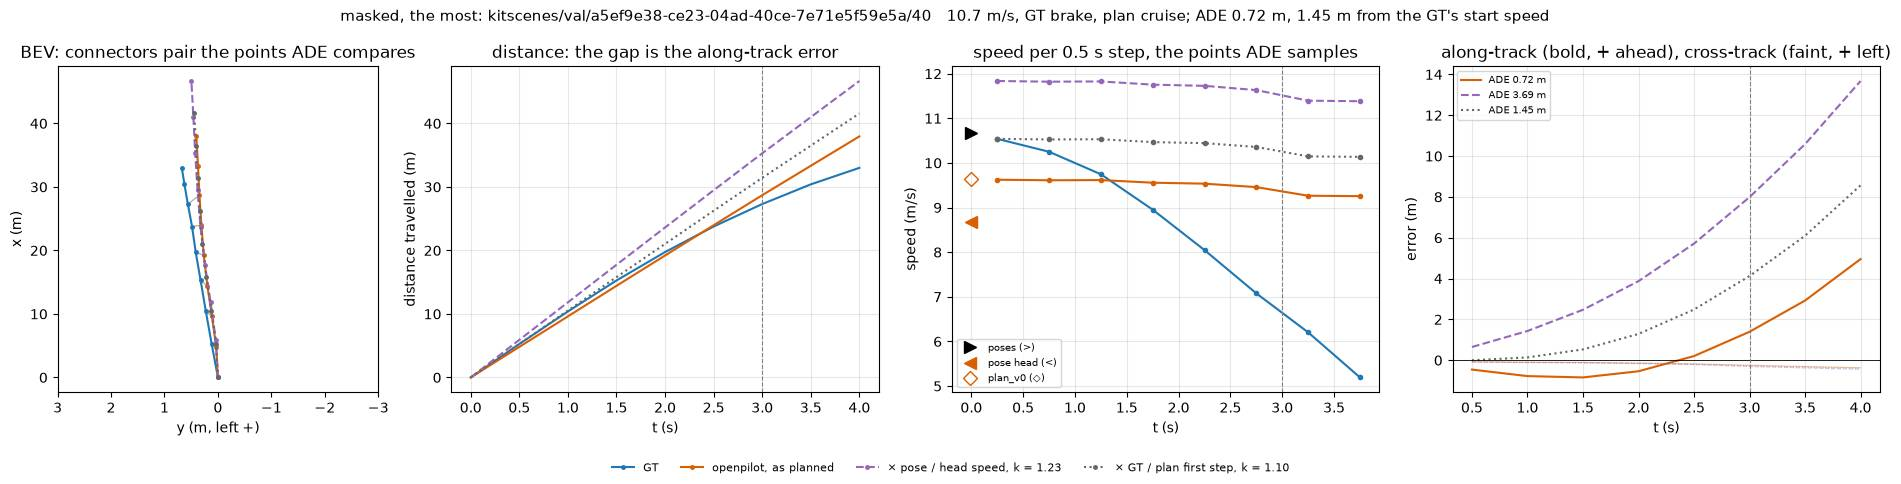

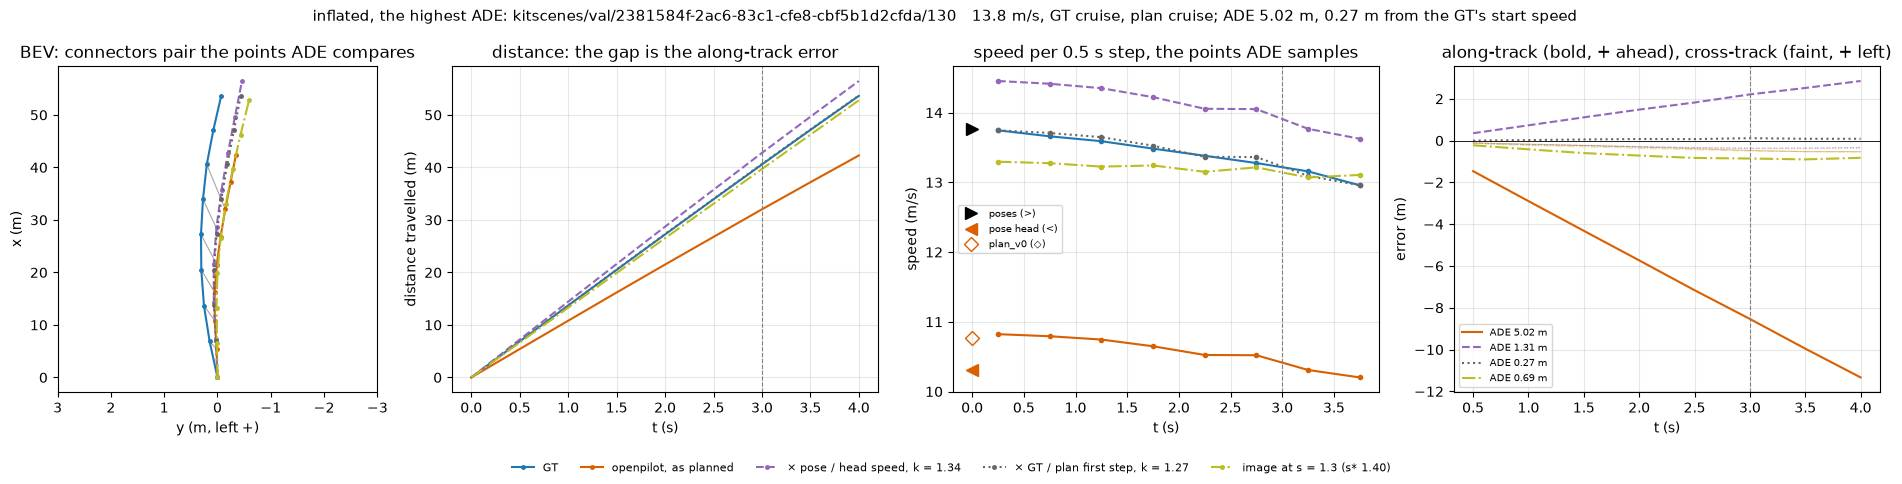

In [45]:
# the two keyframes the answer below describes; FOCUS may hold neither
if len(BLIND_ROWS["masked"]):
    speed_profile(BLIND_ROWS["masked"].ade_start_H.idxmin(), title="masked, the most")
if len(BLIND_ROWS["inflated"]):
    speed_profile(BLIND_ROWS["inflated"].ade_H.idxmax(), title="inflated, the highest ADE")

### The answer

Measured on the baseline's 223 keyframes over 140 scenes. The CIs come from resampling scenes.

**ADE is mostly the start speed.**
- The start speed explains 64% of the summed ADE (CI 59–68%).
- ADE ranks keyframes much as |`v0_err`| × 1.75 s does: ρ = 0.84 (0.78–0.89). The agreement rises with speed, through 0.63, 0.83 and 0.92 over the thirds.
- ADE also rises with speed itself: ρ = 0.51 (0.40–0.61) against the GT's mean speed.

**ADE hardly ranks the speed profile.**
- Its ρ with the profile's own error is 0.06 (−0.07 to 0.20). In the slowest third it is 0.50; above that, 0.11 and 0.12.
- The profile error is in ADE all the same. With the start speed set right, the rest of ADE tracks it at ρ = 0.81 (0.73–0.87). It is the start speed's term that covers it.

**The three groups:**
- **inflated: 20 keyframes in 20 scenes,** at a median 10.7 m/s.
    - All 20 read slow, and 18 carry too_slow_cruise.
    - The highest, drawn above, has 5.02 m of ADE and 0.27 m once the start speed is right.
- **missed: 36 keyframes in 31 scenes,** at a median 2.65 m/s.
    - That is more than the 27.9 expected by chance (p 0.009), but not more than the 37.5 expected within speed thirds (p 0.78).
    - So the group is explained by speed alone: ADE is in metres, and a slow keyframe's profile error is small in metres.
- **masked: 21 keyframes in 20 scenes.** This is ADE's blind spot.
    - 19 read slow and plan more acceleration than the GT. The slow start and the relative gain cancel in position.
    - In 5, the GT brakes and the plan does not. The case drawn above, a5ef9e38/40, has an ADE of 0.72 m, lower than 78% of keyframes. Yet within its 4 s the GT slows from 10.5 to 5.2 m/s, while the plan slows only from 9.6 to 9.3. With the start speed set right, its ADE is 1.45 m.
    - Only 6 of the 21 carry a profile tag, and 9 carry no longitudinal tag at all.

**What to do about it.**
- **No new tag.**
    - The missed group is explained by speed.
    - The masked group is a property of the score, not of the plan. The profile tags classify the plan's own acceleration, whatever speed it starts at. So a missing brake is tagged whenever it passes under_brakes' classes, masked or not.
    - `select("ade_start_H <= -0.1")` finds the masked keyframes.
- **Scoring profiles:** report `ade_net_H` or `vprof_rmse` beside ADE. Both are in `T` and in `export()`'s tags.csv.

## 17 Driving intent

Can openpilot take driving intent, how can paddock supply it, and how does the model do with it and without it?

**What the model accepts** (verified in the adapter and the pinned openpilot):
- supercombo has six inputs: two images, its own hidden state, `desire_pulse`, the traffic convention and `action_t`. None of them carries a route or a speed.
- `desire_pulse` is the one way in for intent. It has 8 slots, `DESIRES` below: none, turnLeft, turnRight, laneChangeLeft, laneChangeRight, keepLeft, keepRight and an unused one.
- A desire is sent as a rising edge, once, when the manoeuvre starts, and the model decides when it is over. A queue of 25 bins of 0.2 s carries it for 5 s.
- The model also outputs `desire_state`, its own 8-way reading of the current desire. The adapter records it as `extras.desire.state`, beside the slot it sent (`extras.desire.input`).
- **Turn desires are off the deployment distribution.**
    - openpilot's `DesireHelper` sends only none and the lane-change pair. It needs the blinker, 20 mph or more, lateral control active and torque toward the blinker.
    - No Python or C++ file in openpilot's history names a turn desire. Whether training covered them cannot be read from the code, only measured.
    - From memory, not checked: forks such as FrogPilot and sunnypilot send turnLeft/turnRight when the blinker is on below lane-change speed.

**How paddock supplies it.** There are two opt-in knobs, both off by default, so every earlier run is unchanged.
- `[benchmarks.kitscenes] command_source = "gt"` gives the scored keyframe the sample list's `driving_command`, as LEFT, STRAIGHT or RIGHT. The history frames stay STRAIGHT. It is benchmark-wide: every model that reads `Command` gets it.
- `PADDOCK_OPENPILOT_DESIRE`, in `[models.openpilot.env]`, sends LEFT and RIGHT as desires:
    - `turn` sends them as turnLeft and turnRight;
    - `lane_change` sends them as the lane-change pair;
    - STRAIGHT is none in every mode.

  The table is the adapter's `DESIRE_MODES`, and §17 checks what was sent against it through `desire_index()`.
- **Only the keyframe carries the command** (argued from code).
    - Stamped on every frame, as the nuScenes harness does, the rising edge would fall on the first of the 49 frames. By the scored frame it would be 4.8 s old, in the queue's oldest bin.
    - Stamped on the keyframe alone, it arrives on the keyframe's first tick, in the newest bin.
- **The arm is its own valid run,** and `paddock report` lists it as a second openpilot row. `INTENT_RUN` (§1) picks it: `"auto"` takes the newest full run with a desire and `command_source = "gt"`.

**What KITScenes can supply.** It has no CAN, so no blinker, and no route. Every hint comes from the recorded future:
- the list's `driving_command`, which the arm sends. The check before `hint_disagreements()` shows it is the scored GT's own end: a turn exactly when the 4 s GT ends 5 m or more to one side.
- the list's `nav_text` ("Turn right in 21m"), from further along the recorded route. It disagrees with `driving_command` on 8 keyframes.
- a route from the Lanelet2 map, which needs `lanelet2`. That does not install under numpy 2.

So the arm is told which side the GT ends on. A car on a route knows where it is going, not where it will be in 4 s.

**Precedent** (verified in `results/`): alpamayo15 on the same 223 keyframes, with its nav hint and without it.
- Median ADE: 0.661 m with the hint, against 0.696 m without.
- Mean ADE: 1.00 m against 0.92 m.
- p90: 2.17 m against 1.93 m.

The hint helped the typical keyframe and hurt the tail.

**What this section computes:**
- `intent_arm()` gives `TI`: the arm's records through `features()` and `retag()`, row for row with `T`.
    - `SENT` and `STATE` are what the adapter sent and how the model read it. `STATE0` is the baseline's reading, sent none.
    - It asserts that the desire sent is the route's through the adapter's table.
    - It asserts that the straight keyframes plan exactly as in the baseline.
- `intent_ab()`: each error, baseline against arm on the same keyframes (the turns by default). It gives the paired change and a CI from resampling scenes.
- `mode_shift()`: the failure modes and strengths in each run, and which ones the arm entered and left. It is followed by §12's `route_vs_plan()` for both runs.
- `desire_read()`: the probability the model puts on the route's side, and where its argmax falls.
- `turn_shape()`: the plan's heading change over H, I and its 10 s, its cross- and along-track error at H, and its distance, speed and acceleration. Every one is signed toward the turn.
- `intent_by_phase()`: the same, split by how far the turn is already underway at the keyframe.
- `hint_disagreements()`: the 8 keyframes where the two hints disagree.

In [46]:
@contextlib.contextmanager
def _swapped(**new):
    """The notebook's globals replaced by new for the duration: features() and retag() read D, PRED and SIGMA."""
    g = globals()
    old = {k: g[k] for k in new}
    g.update(new)
    try:
        yield
    finally:
        g.update(old)


# desire_state's 8 slots in the model's order: the five the adapter can send, under its own constants, then
# openpilot's keepLeft and keepRight and an unused slot, which nothing in paddock sends
_SENDABLE = {
    DESIRE_NONE: "none",
    DESIRE_TURN_LEFT: "turnLeft",
    DESIRE_TURN_RIGHT: "turnRight",
    DESIRE_LANE_CHANGE_LEFT: "laneChangeLeft",
    DESIRE_LANE_CHANGE_RIGHT: "laneChangeRight",
}
assert sorted(_SENDABLE) == list(range(5)), "the adapter's desire slots have moved"
DESIRES = [_SENDABLE[k] for k in range(5)] + ["keepLeft", "keepRight", "unused"]


def _desire(run_id, df):
    """(input, state) per row of df: the desire the adapter sent at the keyframe, and the model's 8-way reading of
    it (DESIRES' order), NaN in a run from before the adapter recorded them."""
    by_id = {s["sample_id"]: (s.get("extras") or {}).get("desire") or {} for s in _run(run_id).samples}
    rec = [by_id.get(i, {}) for i in df.sample_id]
    sent = pd.Series([r.get("input", np.nan) for r in rec], index=df.index, dtype=float)
    state = np.array([r.get("state") or [np.nan] * len(DESIRES) for r in rec], dtype=float)
    return sent, pd.DataFrame(state, index=df.index, columns=DESIRES)


def intent_arm(run_id=None, df=None):
    """The intent arm's tag table, row for row with df (T): its records through features() and retag()."""
    run_id, df = (INTENT_ID if run_id is None else run_id), (T if df is None else df)
    _, d, pred, gt, sigma, *_ = load(run_id, subset="all", focus=None)
    pos = pd.Series(np.arange(len(d)), index=d.sample_id).reindex(df.sample_id)
    assert pos.notna().all(), f"{int(pos.isna().sum())} loaded keyframes are not in {run_id}"
    pos = pos.to_numpy(int)
    assert np.array_equal(gt[pos], GT_RAW[df.index], equal_nan=True), "the two runs' GTs differ"
    with _swapped(D=d.iloc[pos].set_axis(df.index), PRED=pred[pos], SIGMA=sigma[pos]):
        return retag()


TI = intent_arm()
SENT, STATE = _desire(INTENT_ID, T)
_, STATE0 = _desire(RUN.run_id, T)
TURN = T.cmd.isin(["left", "right"])
# what the adapter must have sent: the route command through its own table, under the arm's recorded desire mode
_want = T.cmd.map(lambda c: desire_index(Command[c.upper()], RUNS.desire[INTENT_ID]))
assert SENT.eq(_want).all(), (
    f"{int(SENT.ne(_want).sum())} keyframes were sent another desire than the route's"
)
# the arm changes the input only where the route turns: everywhere else the two runs must agree bit for bit
_, _plan_i = readings(INTENT_ID)
_same = np.array([np.array_equal(PRED[i], _plan_i[k], equal_nan=True) for k, i in enumerate(T.index)])
print(
    f"intent arm {INTENT_ID}: command_source {RUNS.command_source[INTENT_ID]!r}, desire {RUNS.desire[INTENT_ID]!r}; "
    f"{int(TURN.sum())} turn keyframes over {T.scene[TURN].nunique()} scenes"
)
assert _same[~TURN.to_numpy()].all(), f"{int((~_same[~TURN.to_numpy()]).sum())} non-turn keyframes differ"
print(
    f"the {int((~TURN).sum())} keyframes whose route goes straight on plan the same as the baseline, bit for bit; "
    f"{int((~_same[TURN.to_numpy()]).sum())} of the {int(TURN.sum())} turns plan differently"
)
display(pd.crosstab(T.cmd, SENT.map(dict(enumerate(DESIRES))).rename("desire sent"), margins=True))

intent arm 20260930T014333-d329a6: command_source 'gt', desire 'turn'; 39 turn keyframes over 33 scenes
the 184 keyframes whose route goes straight on plan the same as the baseline, bit for bit; 39 of the 39 turns plan differently


desire sent,none,turnLeft,turnRight,All
cmd,,,,
left,0,21,0,21
right,0,0,18,18
straight,184,0,0,184
All,184,21,18,223


In [47]:
AB_METRICS = {  # (column, what it measures); every one is an error, so lower is better
    "rec_ade": "ADE over 3 s, as scored (m)",
    "rec_fde_3s": "FDE at 3 s, as scored (m)",
    "rec_longitudinal_mae": "mean |dx| over 3 s, as scored (m)",
    "rec_lateral_mae": "mean |dy| over 3 s, as scored (m)",
    "abs_dpsi_err_deg": "|heading change, plan - GT| over H (deg)",
    "abs_dpsi_err_I_deg": "|heading change, plan - GT| over I (deg)",
}


def _ab_frame(df):
    return df.assign(
        abs_dpsi_err_deg=df.dpsi_err_deg.abs(),
        abs_dpsi_err_I_deg=(df.pred_dpsi_I_deg - df.gt_dpsi_I_deg).abs(),
    )


def intent_ab(where=None, df=None, dfi=None, n_boot=2000, seed=None, **conds):
    """Baseline against the intent arm on the same keyframes: each error's mean and median in both, and the
    paired change (arm - baseline) with a 95% CI from resampling scenes. Default: the turn keyframes."""
    df, dfi, seed = (T if df is None else df), (TI if dfi is None else dfi), (SEED if seed is None else seed)
    if where is None and not conds:
        conds = {"cmd": ["left", "right"]}
    sel = select(where, df, **conds)
    a, b = _ab_frame(sel), _ab_frame(dfi.loc[sel.index])
    draws = list(_scene_draws(sel.scene.to_numpy(), n_boot, seed))
    rows = []
    # a selection a FOCUS leaves empty (no left turns, say) gets n = 0 and NaN, which the table shows: numpy's
    # warnings about it would add nothing
    with warnings.catch_warnings(action="ignore", category=RuntimeWarning):
        for c, doc in AB_METRICS.items():
            x, y = a[c].to_numpy(float), b[c].to_numpy(float)
            d = y - x
            ok = np.isfinite(d)
            boot = np.array([np.nanmean(d[k]) for k in draws])
            lo, hi = np.nanpercentile(boot, [2.5, 97.5])
            rows.append(
                {
                    "metric": c,
                    "what it measures": doc,
                    "n": int(ok.sum()),
                    "baseline mean": np.nanmean(x),
                    "arm mean": np.nanmean(y),
                    "change": np.nanmean(d),
                    "CI lo": lo,
                    "CI hi": hi,
                    "baseline median": np.nanmedian(x),
                    "arm median": np.nanmedian(y),
                    "median change": np.nanmedian(d),
                    "arm better on": f"{int((d[ok] < 0).sum())} of {int(ok.sum())}",
                }
            )
    return pd.DataFrame(rows).set_index(["metric", "what it measures"])


print(
    f"the turn keyframes: {int(TURN.sum())} over {T.scene[TURN].nunique()} scenes; change = arm - baseline, "
    "CIs from resampling scenes"
)
display(intent_ab().round(2))
print("by the side the route turns")
display(pd.concat({cmd: intent_ab(cmd=cmd).droplevel(1) for cmd in ("left", "right")}).round(2))

the turn keyframes: 39 over 33 scenes; change = arm - baseline, CIs from resampling scenes


,,n,baseline mean,arm mean,change,CI lo,CI hi,baseline median,arm median,median change,arm better on
metric,what it measures,,,,,,,,,,
rec_ade,"ADE over 3 s, as scored (m)",39,1.72,2.03,0.30,-0.04,0.72,1.47,1.58,-0.05,21 of 39
rec_fde_3s,"FDE at 3 s, as scored (m)",39,3.30,4.25,0.95,0.17,1.85,2.92,3.39,0.31,17 of 39
rec_longitudinal_mae,"mean |dx| over 3 s, as scored (m)",39,1.50,1.56,0.06,-0.31,0.51,1.24,0.94,-0.11,22 of 39
rec_lateral_mae,"mean |dy| over 3 s, as scored (m)",39,0.58,0.90,0.32,0.18,0.47,0.46,0.78,0.28,7 of 39
abs_dpsi_err_deg,"|heading change, plan - GT| over H (deg)",39,10.64,16.33,5.69,3.02,8.53,3.47,10.27,3.20,8 of 39
abs_dpsi_err_I_deg,"|heading change, plan - GT| over I (deg)",39,16.31,22.22,5.91,2.71,9.02,5.95,13.44,5.40,12 of 39


by the side the route turns


n  baseline mean  arm mean  change  CI lo  CI hi  \
      metric                                                                    
left  rec_ade               21           1.76      1.96    0.21  -0.14   0.60   
      rec_fde_3s            21           3.38      4.08    0.71  -0.06   1.58   
      rec_longitudinal_mae  21           1.50      1.40   -0.11  -0.47   0.26   
      rec_lateral_mae       21           0.65      1.07    0.43   0.22   0.69   
      abs_dpsi_err_deg      21          13.76     19.81    6.05   1.67  10.26   
      abs_dpsi_err_I_deg    21          23.25     28.15    4.89  -0.22   9.44   
right rec_ade               18           1.69      2.10    0.42  -0.21   1.19   
      rec_fde_3s            18           3.21      4.44    1.24  -0.08   2.88   
      rec_longitudinal_mae  18           1.51      1.75    0.25  -0.45   1.09   
      rec_lateral_mae       18           0.51      0.70    0.19   0.05   0.32   
      abs_dpsi_err_deg      18           6.99     12.27    5.28   2.06   9.30   
      abs_dpsi_err_I_deg    18           8.21     15.30    7.09   2.33  12.49   

                            baseline median  arm median  median change  \
      metric                                                             
left  rec_ade                          1.43        1.58          -0.05   
      rec_fde_3s                       2.79        3.39           0.31   
      rec_longitudinal_mae             1.18        0.94          -0.10   
      rec_lateral_mae                  0.62        0.97           0.41   
      abs_dpsi_err_deg                 5.81       17.18           3.20   
      abs_dpsi_err_I_deg               6.40       23.59           4.31   
right rec_ade                          1.49        1.61          -0.07   
      rec_fde_3s                       2.94        3.27           0.21   
      rec_longitudinal_mae             1.45        1.05          -0.13   
      rec_lateral_mae                  0.32        0.65           0.22   
      abs_dpsi_err_deg                 2.94        7.48           2.65   
      abs_dpsi_err_I_deg               4.46        9.45           6.00   

                           arm better on  
      metric                              
left  rec_ade                   11 of 21  
      rec_fde_3s                 8 of 21  
      rec_longitudinal_mae      11 of 21  
      rec_lateral_mae            3 of 21  
      abs_dpsi_err_deg           4 of 21  
      abs_dpsi_err_I_deg         6 of 21  
right rec_ade                   10 of 18  
      rec_fde_3s                 9 of 18  
      rec_longitudinal_mae      11 of 18  
      rec_lateral_mae            4 of 18  
      abs_dpsi_err_deg           4 of 18  
      abs_dpsi_err_I_deg         6 of 18

In [48]:
def mode_shift(where=None, df=None, dfi=None, **conds):
    """Each failure mode (fm_) and strength (st_) on the same keyframes in both runs: how many in each, and how
    many the arm entered and left. Default: the turn keyframes; modes neither run has are left out."""
    df, dfi = (T if df is None else df), (TI if dfi is None else dfi)
    if where is None and not conds:
        conds = {"cmd": ["left", "right"]}
    sel = select(where, df, **conds)
    rows = []
    for c in [c for c in df.columns if c.startswith(("fm_", "st_"))]:
        a, b = sel[c].astype(bool), dfi.loc[sel.index, c].astype(bool)
        if a.any() or b.any():
            rows.append(
                {
                    "kind": "failure mode" if c.startswith("fm_") else "strength",
                    "tag": c[3:],
                    "baseline": int(a.sum()),
                    "arm": int(b.sum()),
                    "entered": int((b & ~a).sum()),
                    "left": int((a & ~b).sum()),
                }
            )
    cols = [
        "kind",
        "tag",
        "baseline",
        "arm",
        "entered",
        "left",
    ]  # named, for a FOCUS with no mode in either run
    return pd.DataFrame(rows, columns=cols).set_index(["kind", "tag"])


def desire_read(df=None):
    """How the model reads the desire on the turn keyframes, in both runs: the probability of the side the route
    turns (median and range), and where desire_state's argmax falls."""
    df = T if df is None else df
    sel = df[df.cmd.isin(["left", "right"])]
    asked = sel.cmd.map({"left": "turnLeft", "right": "turnRight"})
    other = sel.cmd.map({"left": "turnRight", "right": "turnLeft"})
    rows = {}
    for name, st in (
        (f"baseline, sent {DESIRES[DESIRE_NONE]}", STATE0),
        ("arm, sent the route's turn", STATE),
    ):
        s = st.loc[sel.index]
        p = pd.Series([s.at[i, asked[i]] for i in sel.index], index=sel.index)
        top = s.idxmax(axis=1)
        rows[name] = {
            "n": len(sel),
            "p(route's side) median": p.median(),
            "p(route's side) min": p.min(),
            "p(route's side) max": p.max(),
            f"p({DESIRES[DESIRE_NONE]}) median": s[DESIRES[DESIRE_NONE]].median(),
            "argmax: route's side": int((top == asked).sum()),
            "argmax: other side": int((top == other).sum()),
            f"argmax: {DESIRES[DESIRE_NONE]}": int((top == DESIRES[DESIRE_NONE]).sum()),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


# (column, what it is, signed): a signed column is multiplied by +1 on a left turn and -1 on a right one, so + is
# toward the side the route turns
TURN_SHAPE = [
    ("pred_dpsi_deg", "heading change over H (deg)", True),
    ("pred_dpsi_I_deg", "heading change over I (deg)", True),
    ("pred_dpsi_full_deg", "heading change over the plan's 10 s (deg)", True),
    ("pred_kappa", "curvature over H (1/m)", True),
    ("cross_H", "cross-track error at H (m), + toward the turn's inside", True),
    ("along_H", "along-track error at H (m), + ahead of the GT", False),
    ("pred_s", "distance over H (m)", False),
    ("pred_v_first", "speed over the first 0.5 s (m/s)", False),
    ("pred_v_last", "speed at H (m/s)", False),
    ("pred_accel", "acceleration over H (m/s²)", False),
]


def turn_shape(where=None, df=None, dfi=None, **conds):
    """The plan's turn and speed on the same keyframes in both runs, with the GT's where it has one: medians, the
    median paired change (arm - baseline), and on how many the arm's is larger. Default: the turn keyframes."""
    df, dfi = (T if df is None else df), (TI if dfi is None else dfi)
    if where is None and not conds:
        conds = {"cmd": ["left", "right"]}
    sel = select(where, df, **conds)
    sgn = sel.cmd.map({"left": 1.0, "right": -1.0})
    rows = []
    for c, doc, signed in TURN_SHAPE:
        k = sgn if signed else 1.0
        a, b = sel[c] * k, dfi.loc[sel.index, c] * k
        g = c.replace("pred_", "gt_", 1)
        rows.append(
            {
                "column": c,
                "what it is": doc,
                "GT median": (sel[g] * k).median() if c.startswith("pred_") and g in sel else np.nan,
                "baseline median": a.median(),
                "arm median": b.median(),
                "median change": (b - a).median(),
                "arm larger on": f"{int((b > a).sum())} of {int((a.notna() & b.notna()).sum())}",
            }
        )
    return pd.DataFrame(rows).set_index(["column", "what it is"])


print("the turn keyframes' failure modes and strengths, baseline and arm")
display(mode_shift())
print("the route (rows) against where the plan turns over its 10 s (columns): the baseline, then the arm")
display(
    pd.concat(
        {
            "baseline": route_vs_plan(cmd=["left", "right"]),
            "arm": route_vs_plan(df=TI, cmd=["left", "right"]),
        },
        axis=1,
    )
)
print("how the model reads the desire on the turns (desire_state, the model's own 8-way output)")
display(desire_read().round(3))
_straight = STATE0.loc[~TURN].idxmax(axis=1).value_counts()
print(
    f"on the {int((~TURN).sum())} straight keyframes the baseline's argmax is "
    + ", ".join(f"{k} {v}" for k, v in _straight.items())
)
_ahead = STATE0.loc[TURN].idxmax(axis=1).eq(T.cmd[TURN].map({"left": "turnLeft", "right": "turnRight"}))
print(
    "does the baseline take the routed turn, by whether its own desire_state already leans to the route's side"
)
display(
    pd.concat(
        {
            name: pd.crosstab(
                _ahead.rename("baseline leans to the route's side"), df.st_takes_routed_turn[TURN]
            )
            for name, df in (("baseline", T), ("arm", TI))
        },
        axis=1,
    )
)
print("the plan's turn and speed on the turns: signed columns are + toward the side the route turns")
display(turn_shape().round(3))


def _gt_heading_1s(df):
    """The GT's heading at 1 s (deg), toward the side the route turns: the direction of its step from 0.5 to 1 s.
    How far the turn is already underway at the keyframe."""
    sgn = df.cmd.map({"left": 1.0, "right": -1.0})
    step = np.array([GT_RAW[i][1] - GT_RAW[i][0] for i in df.index])
    return pd.Series(np.degrees(np.arctan2(step[:, 1], step[:, 0])), index=df.index) * sgn


def intent_by_phase(split_deg=None, n_boot=2000, seed=None):
    """intent_ab() and turn_shape() on the turns split by how far the turn is underway at the keyframe: the GT's
    heading at 1 s at or above split_deg (the median by default), or below it."""
    sel = T[TURN]
    h = _gt_heading_1s(sel)
    split_deg = h.median() if split_deg is None else split_deg
    tx = T.assign(gt_heading_1s_deg=h)  # NaN off the turns, which neither query keeps
    rows = {}
    for name, q in (
        (f"underway: heading at 1 s >= {split_deg:.1f} deg", f"gt_heading_1s_deg >= {split_deg}"),
        (f"still ahead: heading at 1 s < {split_deg:.1f} deg", f"gt_heading_1s_deg < {split_deg}"),
    ):
        ab = intent_ab(q, df=tx, n_boot=n_boot, seed=seed).droplevel(1)
        shape = turn_shape(q, df=tx).droplevel(1)
        sub = select(q, tx)
        rows[name] = {
            "n": int(ab.at["rec_ade", "n"]),
            "scenes": sub.scene.nunique(),
            "median speed (m/s)": sub.ref_speed.median(),
            "GT's heading change over H (deg)": shape.at["pred_dpsi_deg", "GT median"],
            **{
                f"{label} change (CI)": f"{ab.at[c, 'change']:+.2f} ({ab.at[c, 'CI lo']:+.2f} to {ab.at[c, 'CI hi']:+.2f})"
                for c, label in (
                    ("rec_ade", "ADE"),
                    ("rec_lateral_mae", "lateral MAE"),
                    ("rec_longitudinal_mae", "long. MAE"),
                )
            },
            "heading over H, median change (deg)": shape.at["pred_dpsi_deg", "median change"],
            "heading over 10 s, median change (deg)": shape.at["pred_dpsi_full_deg", "median change"],
            "acceleration, median change (m/s²)": shape.at["pred_accel", "median change"],
            "phantom_brake, baseline -> arm": f"{int(sub.fm_phantom_brake.sum())} -> "
            f"{int(TI.loc[sub.index, 'fm_phantom_brake'].sum())}",
        }
    return pd.DataFrame.from_dict(rows, orient="index")


if TURN.any():  # a FOCUS may hold no turn, and then no heading to split the turns by
    print(
        "the same, by how far the turn is underway at the keyframe (change = arm - baseline, CIs from resampling scenes)"
    )
    display(intent_by_phase().round(2))
print("longitudinal class on the turns: the GT (rows) against the plan's, baseline and arm (columns)")
display(
    pd.crosstab(T.gt_long[TURN], [T.pred_long[TURN].rename("baseline"), TI.pred_long[TURN].rename("arm")])
)

the turn keyframes' failure modes and strengths, baseline and arm


baseline  arm  entered  left
kind         tag                                             
failure mode too_slow_cruise           19   21        4     2
             too_fast_cruise            3    3        1     1
             under_accelerates          8   10        3     1
             under_brakes               1    0        0     1
             phantom_brake              3   10        8     1
             understeer                10   17       11     4
             oversteer                  2    3        3     2
             wrong_way_curve            2    3        3     2
             ego_speed_misread         36   36        0     0
             yaw_misread               10   10        0     0
             confidently_wrong          1    2        1     0
             turn_unanticipated         4    5        1     0
             turn_not_planned           4    2        2     4
             turn_wrong_way             4    2        0     2
strength     holds_speed                5    3        3     5
             holds_curve                9    6        1     4
             takes_routed_turn         31   35        5     1

the route (rows) against where the plan turns over its 10 s (columns): the baseline, then the arm


baseline                     arm                 \
plan turns (|dpsi| >= 15 deg)     left right straight All left right straight   
cmd                                                                             
left                                15     4        2  21   18     2        1   
right                                0    16        2  18    0    17        1   
All                                 15    20        4  39   18    19        2   

                                   
plan turns (|dpsi| >= 15 deg) All  
cmd                                
left                           21  
right                          18  
All                            39

how the model reads the desire on the turns (desire_state, the model's own 8-way output)


,n,p(route's side) median,p(route's side) min,p(route's side) max,p(none) median,argmax: route's side,argmax: other side,argmax: none
"baseline, sent none",39,0.138,0.000,0.664,0.707,9,1,29
"arm, sent the route's turn",39,1.000,0.991,1.000,0.000,39,0,0


... (4 outputs left out)

the same, by how far the turn is underway at the keyframe (change = arm - baseline, CIs from resampling scenes)


,n,scenes,median speed (m/s),GT's heading change over H (deg),ADE change (CI),lateral MAE change (CI),long. MAE change (CI),"heading over H, median change (deg)","heading over 10 s, median change (deg)","acceleration, median change (m/s²)","phantom_brake, baseline -> arm"
underway: heading at 1 s >= 9.7 deg,20,17,4.29,40.01,+0.08 (-0.15 to +0.38),+0.38 (+0.15 to +0.67),-0.26 (-0.50 to -0.02),-11.46,4.61,-0.33,3 -> 4
still ahead: heading at 1 s < 9.7 deg,19,18,6.23,19.39,+0.54 (-0.14 to +1.24),+0.25 (+0.13 to +0.36),+0.38 (-0.36 to +1.15),-0.28,12.78,-0.33,0 -> 6


longitudinal class on the turns: the GT (rows) against the plan's, baseline and arm (columns)


baseline  accel brake        cruise             
arm      cruise brake cruise  accel brake cruise
gt_long                                         
accel         3     1      0      1     1      5
brake         0     0      0      0     1      0
cruise        2     1      1      0     7     16

In [49]:
# what driving_command is: the side the scored GT ends up on. Its turn keyframes and its straight ones separate
# cleanly on the GT's lateral offset at its last point (4 s)
_y_end = pd.Series([GT_RAW[i][np.isfinite(GT_RAW[i][:, 0])][-1, 1] for i in T.index], index=T.index)
_side = T.cmd.map({"left": 1.0, "right": -1.0})
assert (np.sign(_y_end[TURN]) == _side[TURN]).all(), "a turn keyframe's GT ends on the other side"
print(
    f"cmd is the scored GT's own end: on all {int(TURN.sum())} turn keyframes the GT ends "
    f"{_y_end[TURN].abs().min():.2f} m or more to the turn's side at 4 s, on all {int((~TURN).sum())} straight ones "
    f"within {_y_end[~TURN].abs().max():.2f} m"
)


def hint_disagreements(df=None):
    """The keyframes where the list's two route hints disagree: driving_command (cmd, the one the arm sent) against
    nav_text (nav), with the GT's turn and the plan's in both runs (deg, left +)."""
    df = T if df is None else df
    sel = df[df.cmd != df.nav]
    return pd.DataFrame(
        {
            "cmd (sent)": sel.cmd,
            "nav_text": sel.nav_text,
            "desire sent": SENT[sel.index].map(dict(enumerate(DESIRES))),
            "GT's y at 4 s (m)": _y_end[sel.index],
            "GT, over H": sel.gt_dpsi_deg,
            "GT, over I": sel.gt_dpsi_I_deg,
            "baseline plan, over 10 s": sel.pred_dpsi_full_deg,
            "arm plan, over 10 s": TI.loc[sel.index, "pred_dpsi_full_deg"],
            "ADE (m)": sel.rec_ade,
        }
    ).set_axis(sel.sample_id)


_dis = hint_disagreements()
_sent = _dis["desire sent"].value_counts()
print(
    f"{len(_dis)} keyframes where the hints disagree. The arm sent "
    + ", ".join(f"{k} on {'all ' if v == len(_dis) else ''}{v}" for k, v in _sent.items())
    + f", so it plans them as the baseline does. {int((_dis['GT, over I'].abs() >= P['turn_pred_deg']).sum())} of "
    f"them turn by {P['turn_pred_deg']:g} deg or more within I"
)
display(_dis.round(1))

cmd is the scored GT's own end: on all 39 turn keyframes the GT ends 5.07 m or more to the turn's side at 4 s, on all 184 straight ones within 4.46 m
8 keyframes where the hints disagree. The arm sent none on all 8, so it plans them as the baseline does. 4 of them turn by 15 deg or more within I


,cmd (sent),nav_text,desire sent,GT's y at 4 s (m),"GT, over H","GT, over I","baseline plan, over 10 s","arm plan, over 10 s",ADE (m)
sample_id,,,,,,,,,
kitscenes/overlap_train_val/17719e25-ae9b-87b8-6826-fe7ac9cf5920/40,straight,Turn left in 39m,none,4.2,8.3,10.9,7.0,7.0,1.3
kitscenes/val/3689ea5c-1275-629a-8fa1-34142129eae5/40,straight,Turn right in 21m,none,-4.2,-14.3,-15.8,-10.3,-10.3,1.2
kitscenes/val/6f47eb66-9043-845f-5043-6731c294de25/400,straight,Turn right in 17m,none,-4.1,-32.3,-46.7,-86.0,-86.0,0.9
kitscenes/val/6f47eb66-9043-845f-5043-6731c294de25/490,straight,Turn right in 18m,none,-4.1,-31.2,-32.9,-31.3,-31.3,1.2
kitscenes/val/85dbe6d6-47e0-7359-85cc-df98edf61ec3/130,straight,Turn left in 39m,none,4.5,6.3,7.8,8.9,8.9,1.8
kitscenes/val/a724baf7-428b-eadc-9721-9de6195b0c3b/130,straight,Turn right in 64m,none,-3.7,-7.6,-12.0,-9.1,-9.1,1.2
kitscenes/val/bb2f22e1-82e1-2aaa-6837-a91792df0dc1/40,straight,Turn right in 30m,none,-2.4,-6.4,-27.8,-68.2,-68.2,1.1
kitscenes/val/c34c778f-ad8c-0aa9-7e1a-c86a73f887c7/40,straight,Turn right in 41m,none,-3.6,-8.7,-12.3,-18.6,-18.6,0.2


### The answer

Measured on the 39 turn keyframes over 33 scenes, comparing the arm with the baseline on the same keyframes. The CIs come from resampling scenes.

**openpilot takes intent, and reads it** (measured):
- Sent turnLeft or turnRight, the model's `desire_state` puts at least 0.991 on the route's side at all 39 turns.
- The plan changes on all 39. On the 184 straight keyframes, which were sent none, it is the baseline's bit for bit.
- The baseline, sent none, already leans to the route's side on 9 of the 39 turns (its argmax), against 4 of the 184 straight keyframes. It takes the routed turn on all 9.

**The desire does not help the score** (measured):
- **ADE: 1.72 → 2.03 m,** a change of +0.30 (CI −0.04 to +0.72).
    - The median keyframe hardly moves (−0.05), and the arm is better on 21 of 39. So the mean rises through the tail.
    - Over all 223 keyframes, ADE goes from 1.595 to 1.649 m.
- **FDE at 3 s: 3.30 → 4.25 m,** +0.95 (0.17 to 1.85).
- **Lateral MAE: 0.58 → 0.90 m,** +0.32 (0.18 to 0.47). The arm is better on only 7 of 39.
    - It is worse on both sides: +0.43 m on left turns, +0.19 m on right ones.
- **|Heading error| over H: +5.7°** (3.0 to 8.5). The arm is better on 8 of 39.
- **Longitudinal MAE does not move on average:** +0.06 m (−0.31 to +0.51).

**What the desire changes** (measured):
- **The plan commits to the route.**
    - Over the plan's full 10 s it turns a median 11.3° more, and turns more on 32 of 39.
    - It takes the routed turn on 35 turns instead of 31.
    - turn_not_planned drops from 4 to 2, and so does turn_wrong_way.
- **But it turns less inside the 3 s that are scored:** a median 16.0° against 19.0°, where the GT turns 29.4°.
    - understeer goes from 10 to 17.
    - At H the plan ends a median 0.74 m outside the GT's turn. The baseline ended 0.35 m inside it.
- **And it brakes for the turn.**
    - Acceleration over H falls by a median 0.33 m/s², and is lower on 30 of 39.
    - The plan brakes on 11 turns instead of 3, and phantom_brake goes from 3 to 10.
    - The GT brakes on 1 of the 39 turns and accelerates on 11.
- **Which of the two happens depends on how far the turn is underway.** The split is at the median heading of the GT at 1 s, 9.7°.
    - **Underway (20 turns):** the GT turns 40° over H.
        - The arm turns 11.5° less than the baseline inside H, and only 4.6° more over 10 s.
        - Its lateral MAE rises by 0.38 m (0.15 to 0.67), while its longitudinal MAE falls by 0.26 m (0.02 to 0.50).
    - **Still ahead (19 turns):** the GT turns 19° over H.
        - The arm's heading over H does not change (−0.3°), but its 10 s turn grows by 12.8°.
        - It brakes: phantom_brake goes from 0 to 6.
        - ADE rises by +0.54 m (−0.14 to +1.24), and lateral MAE by +0.25 m (0.13 to 0.36).
- **Acceleration and braking:**
    - The turns hold one GT brake, so a missed brake cannot be tested here.
    - under_accelerates goes from 8 to 10.
    - The braking the desire adds is phantom.

**The hint** (verified): `driving_command` is the scored GT's own end.
- All 39 turn GTs end 5.07 m or more to the turn's side at 4 s. All 184 straight ones end within 4.46 m.
- So the arm is told which side the answer ends on, which a car on a route would not know, and it still does worse.
- The 8 keyframes where `nav_text` disagrees are all straight by `driving_command`, and 4 of them turn by 15° or more within I. The arm sent them nothing, so an arm driven by `nav_text` is not measured.

**Precedent:** alpamayo15's nav hint did the same on these keyframes: a better median and a worse tail (see above).

**Argued:**
- **The model reads a turn desire as "begin the turn now".** openpilot sends a desire when the manoeuvre starts and lets the model decide when it is over.
    - Where the turn is underway, the plan turns less now and more later.
    - Where the turn is ahead, the plan slows for it.
    - KITScenes' turn keyframes are often already turning (half by 9.7° or more at 1 s), and the car does not slow through them.
- **The turn slots respond although openpilot's runtime never sends them.** The model reads them at 0.991 or more, and the baseline's own `desire_state` finds the turn on 9 of 39.
    - So either training covered the turn slots, or the head generalises from the lane-change pair.
    - The code cannot say which.
- **To supply intent that could help,** the command has to arrive when a driver would give it: on the frame where the turn becomes relevant, from a route. The GT's end on the scored keyframe is not that. KITScenes has neither a route nor a blinker, so this benchmark cannot test that.
- **No `lane_change` control was run.** It was there to show whether any desire moves a turn plan, and the turn desire moved every one.

## 18 Export

`export()` writes the tables behind this notebook, for the loaded keyframes and §1's parameters, to `{runs}/kitscenes/_analysis/openpilot/<run_id>/<subset>/`: `tags.csv` (all of `T`), `clusters.csv`, `modes.csv`, `modes_intent.csv`, `route_vs_plan.csv`, `strengths_named.csv`, `strengths_found.csv`, `scores.csv` (by split), `glossary.md`, and `manifest.json` (the run, `sequences_sha256`, subset or focus, `GT_FRAME`, `ground_offset_m`, `PROJECT_HEIGHT`, `OVERRIDES`, and the tags and params hashes). `<subset>` is `all`, `random-<fraction>-s<seed>` or `focus-<hash>`. §16's `export_profiles()` writes `profiles.pdf`, every keyframe's speed profile, one level up, when `EXPORT_PROFILES` is on. Nothing is written under `results/`.

In [50]:
def export(df=None, slug=None):
    """Write the tables and a manifest under {runs}/<bench>/_analysis/<model>/<run_id>/<slug>/."""
    df = T if df is None else df
    if slug is None:
        if FOCUS:
            slug = "focus-" + hashlib.sha1(json.dumps(FOCUS).encode()).hexdigest()[:8]
        elif SUBSET == "random":
            slug = f"random-{FRACTION:g}-s{SEED}"
        else:
            slug = SUBSET
    out = cfg.runs / BENCH / "_analysis" / MODEL / RUN.run_id / slug
    out.mkdir(parents=True, exist_ok=True)
    df.to_csv(out / "tags.csv", index=False)
    clusters(df=df).to_csv(out / "clusters.csv")
    modes(df=df).to_csv(out / "modes.csv")
    modes(df=df, intent=True).to_csv(out / "modes_intent.csv")
    route_vs_plan(df=df).to_csv(out / "route_vs_plan.csv")
    named, found = strengths(df=df)
    named.to_csv(out / "strengths_named.csv")
    found.to_csv(out / "strengths_found.csv")
    scores(by="split", stat="mean", df=df).to_csv(out / "scores.csv")
    (out / "glossary.md").write_text(f"{glossary()}\n\n### Feature columns\n\n{feature_glossary()}\n")
    manifest = {
        "run_id": RUN.run_id,
        "benchmark": BENCH,
        "model": MODEL,
        "sequences_sha256": RUN.run.get("dataset", {}).get("sequences_sha256"),
        "subset": SUBSET,
        "focus": FOCUS,
        "fraction": FRACTION,
        "seed": SEED,
        "n_keyframes": len(df),
        "gt_frame": GT_FRAME,
        "ground_offset_m": GROUND,
        "project_height": PROJECT_HEIGHT,
        "bench_params": BENCH_PARAMS,
        "overrides": OVERRIDES,
        "tags_file": TAGS.relative_to(REPO_ROOT).as_posix(),
        "tags_hash": config_hash(CFG),
        "params_hash": config_hash(P),
    }
    (out / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str) + "\n")
    print(
        f"wrote {{runs}}/{out.relative_to(cfg.runs).as_posix()}/: "
        + ", ".join(sorted(f.name for f in out.iterdir()))
    )


export()

wrote {runs}/kitscenes/_analysis/openpilot/20260930T154018-242869/all/: clusters.csv, glossary.md, manifest.json, modes.csv, modes_intent.csv, route_vs_plan.csv, scores.csv, strengths_found.csv, strengths_named.csv, tags.csv


## 19 Scratch

Everything above is a function of keyword arguments, so experiments go here. Some starting points:

```python
T2 = retag(params=P | {"turn_pred_deg": 10.0}); modes(df=T2, intent=True)   # a looser turn threshold, side by side
route_vs_plan(turn_deg=10.0)                                                 # the same, as the route against the plan
scores(by=["calib", "history"], stat="mean")                                 # errors by mount and by history
profile(fm_turns_off_route=True)                                             # what turning off the route looks like
heatmap("cmd", "speed_band", value="fde_H")                                  # where the error is, by route and speed
dist(["v0_ratio", "speed_ratio_net", "ego_speed_rel_err"], by="calib")       # the scale error, per mount
explain(select(fm_turn_not_planned=True).sample_id.iloc[0])                  # why one keyframe was tagged
sheet("turns_off_route", n_typical=3, n_worst=2, n_random=2)                 # more keyframes of one mode
scores(by="calib", yaw_offset_deg=-0.7)                                      # re-check §4's offset by hand
show(T.sample_id.iat[0], height="harness")                                   # project with the harness's camera height
heights_plot(T.scene.iat[0])                                                 # one scene's four camera heights (§14)
mode_drivers(image_stats=image_stats())                                      # with each frame's brightness and contrast (§14)
speed_profile(T.sample_id.iat[0], calib=("pose", "oracle"))                  # one keyframe's speed profile (§16)
speed_profile_sheet("under_brakes", n_typical=2, n_worst=2)                  # more keyframes of one mode (§16)
intent_ab(cmd="left")                                                        # the desire's effect on the left turns alone (§17)
```